# notebook_alles – Archiv aller früheren Notebooks

**Zweck:** Dieses Notebook bewahrt den *vollständigen* Code und die *gespeicherten Ausgaben* aller früheren Notebooks auf, damit keine historische Arbeit verloren geht. Die gepflegten, bereinigten Notebooks sind:

* `Compare_notebook.ipynb` – GazeCapture-Training, Baselines, Hyperparameter-Sweeps, räumliche Fehleranalyse
* `personal_compare.ipynb` – Personalisierungs-Pipeline der 18 Sessions (01–09, 19–27)

> ⚠️ **Nicht von oben nach unten ausführen.** Die Zellen stammen aus verschiedenen Notebooks, definieren dieselben Namen mehrfach und hängen von Modell-Checkpoints ab.
>
> ⚠️ **Metrik-Hinweis (Okt. 2026):** Viele archivierte Zellen berechnen `rmse = sqrt(mean_squared_error(targets, preds))` und teilen danach durch √2. Für 2-D-Ziele mittelt sklearn über x **und** y; dadurch sind diese Modellfehler **genau um den Faktor √2 zu klein**. Die korrekte Definition steht in `metrics.py`. Umrechnung: `E_korrekt = √2 · E_alt`. Die Baselines (konstant/zufällig) wurden dagegen schon immer euklidisch und damit korrekt berechnet.

Die Abschnitte entsprechen den Original-Dateien; leere Zellen wurden entfernt, sonst ist alles unverändert (inkl. Ausgaben).

## Inhalt
1. **Compare_notebook.ipynb** – Modell-Training, Hyperparameter-Sweeps, Lernkurven (Original)
2. **notebook_model_train.ipynb** – Rohdaten vs. Normalisierung, Baselines, Aktivierungs-Experimente, Visualisierung (Original)
3. **02_baseline.ipynb** – Erste Baseline-Berechnungen (Original)
4. **03_training.ipynb** – Erstes Trainings-Notebook (Original)
5. **personal_compare.ipynb** – Personalisierung: Session-Training (Original)
6. **personal_code.ipynb** – Personalisierung: Explorativer Code, Session-Baselines (Original)

---
# 1. Archiv: `Compare_notebook.ipynb`
Modell-Training, Hyperparameter-Sweeps, Lernkurven (Original). Zellen: 71 (ohne leere).

# Compare all of Parameters:
* norm_random vs. norm_subjectindipendent
* learn-rate: 1e-3 vs. 1e-4 vs. 1e-5 vs. 1e-6
* batch-size: 64 vs. 32 vs. 128
* Dataset-size(train & test): (1000 & 200) vs. (10000 & 2000) 


In [ ]:
# 1: Bib

import time

import os
import re
import json
import csv
from pathlib import Path
from scipy import stats
import pandas as pd
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)
from datetime import datetime

# from torch.utils.tensorboard import SummaryWriter



In [ ]:

# 2: Dataset Class: transfer CSV in PyTorch.
class GazeDataset(Dataset):

    def __init__(self, csv_file, transform=None, dataset_size=None, read_all4once=True):

        self.df = pd.read_csv(csv_file)
        self.transform = transform
        self.dataset_size = dataset_size if dataset_size is not None else len(self.df)
        self.read_all4once = read_all4once

        if self.read_all4once:
            img = Image.new("RGB", (500, 300))  # any size
            out = transform(img)
            self.images = torch.zeros([self.dataset_size] + list(out.shape))
            self.targets = torch.zeros(self.dataset_size, 2)

        for idx in tqdm(range(self.dataset_size)):

            row = self.df.iloc[idx]

            image = Image.open(
                row["image_name"]
            ).convert("RGB")

            self.targets[idx] = torch.tensor(
                [row["x"], row["y"]],
                dtype=torch.float32
            )

            if self.transform:
                self.images[idx] = self.transform(image)
            else:
                self.images[idx] = image

    def __len__(self):

        return self.dataset_size

    def __getitem__(self, idx):

        return self.images[idx], self.targets[idx]

In [ ]:

# 5: func-Diagonal-Error:
def diagonal_errors(model, loader, device):
    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    
    mae = mean_absolute_error(targets, predictions)
    
    rmse = np.sqrt(mean_squared_error(targets, predictions))

    diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:
def constant_baseline(train_loader, test_loader):
    # Mittelwert ausschließlich aus den Trainingslabels berechnen
    train_targets = []

    for _, targets in train_loader:
        train_targets.append(targets.numpy())

    train_targets = np.concatenate(train_targets, axis=0)
    constant_prediction = train_targets.mean(axis=0)

    # Testlabels sammeln
    test_targets = []

    for _, targets in test_loader:
        test_targets.append(targets.numpy())

    targets = np.concatenate(test_targets, axis=0)

    # Konstante Vorhersage für jeden Testpunkt
    predictions = np.tile(constant_prediction, (len(targets), 1))

    errors = np.sqrt(np.sum((predictions - targets) ** 2, axis=1))
    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(errors)
    diagonal_error_pct = 100 * rmse / np.sqrt(2)

    print(f"Konstante Vorhersage: [{constant_prediction[0]:.6f}, {constant_prediction[1]:.6f}]")
    print(f"MAE: {mae:.5f}")
    print(f"RMSE: {rmse:.5f}")
    print(f"Diagonal-Error: {diagonal_error_pct:.5f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:

import math

# @torch.no_grad()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DIAG = math.sqrt(2)                 # Diagonale des Einheitsquadrats

def evaluate_1(model, loader, device):
    """Mittlere euklidische Distanz in % der Bildschirmdiagonale."""
    model.eval()
    preds, tgts = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x.to(device)).cpu())
            tgts.append(y)
    p, t = torch.cat(preds), torch.cat(tgts)
    
    mae = mean_absolute_error(t, p)
    rmse = np.sqrt(mean_squared_error(t, p))
    dist = torch.linalg.norm(p - t, dim=1)
    diagonal_error_pct = float(dist.mean()) / DIAG * 100

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")
    
    return mae, rmse, diagonal_error_pct

In [ ]:
def evaluate_model(model, loader, device):

    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    return targets, predictions, errors

In [ ]:
class GaussianActivation(nn.Module):

    def __init__(self, sigma=1.0):
        super().__init__()
        self.sigma = sigma

    def forward(self, x):
        return torch.exp(
            -(x ** 2) / (2 * self.sigma ** 2)
        )

In [ ]:
# def sensitive_loss(preds, targets):

#     x_total = 0.0

#     for i in range(len(targets)):

#         x = criterion_base(preds[i], targets[i])

#         distance_from_center = (
#             torch.abs(targets[i][0] - 0.5) +
#             torch.abs(targets[i][1] - 0.5)
#         )

#         weight = 1.0 + distance_from_center

#         x_total += x * weight

#     return x_total / len(targets)


def sensitive_loss(preds, targets):
    # targets liegen im Einheitsquadrat, Gewicht wächst zum Rand hin
    l1 = (preds - targets).abs().mean(dim=1)
    weight = 1.0 + (targets - 0.5).abs().sum(dim=1)
    return (l1 * weight).mean()

In [ ]:
def confidence_interval(data, confidence=0.95):

    data = np.asarray(data)

    n = len(data)

    mean = np.mean(data)
    std = np.std(data, ddof=1)

    standard_error = std / np.sqrt(n)

    t_value = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = t_value * standard_error

    lower = mean - margin
    upper = mean + margin

    return mean, lower, upper

# Hypoparameter:

* dataset_size (train-size & test-size)
* batch_size 
* learn-rate
* norm_random vs. norm_subject


In [ ]:
# Hypoparameter:

name_dataset_type = ['norm_labels.csv', 'labels.csv']
dataset_size_type = [[10000, 2000], [1000, 200]]
dataset_type = ["norm_subject", "norm_random"]
batch_size_type = [32, 64, 128]
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
epochs_num = [1, 2, 10, 25, 500]



optimizer_name = "AdamW"

# ##########################################################################
# 1.type Dataset: 'norm_labels.csv' or 'labels.csv'
dataset_name = name_dataset_type[0]                       # norm_labels.csv
# dataset_name = name_dataset_type[1]                       # labels.csv
print(f"\n dataset_name: \t {dataset_name}")


# 2.dataset_sizt: (10000 & 2000) or (1000, 200)
# def_dataset_size = dataset_size_type[0]                   # [10000, 2000]
def_dataset_size = dataset_size_type[1]                   # [1000, 200]
print(f"\n def_dataset_size: train: {def_dataset_size[0]}, \t test: {def_dataset_size[1]}")


# 3.batch_size: '32', '64' or '128'
batch_Size = batch_size_type[0]                           # 32
# batch_Size = batch_size_type[1]                           # 64
# batch_Size = batch_size_type[2]                           # 128
print(f"\n batch_Size: \t {batch_Size}")


# 4.type of dataset-split: "norm_subject_independed" or "norm_random"
# def_dataset = dataset_type[0]                             # norm_subject
def_dataset = dataset_type[1]                             # norm_random
print(f"\n def_dataset: \t {def_dataset}")


# 5.learning_rate: '1e-3', '1e-4', '1e-5' or '1e-6'
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
# learning_rate = lr_type[0]                                # 1e-3
learning_rate = lr_type[1]                                # 1e-4
# learning_rate = lr_type[2]                                # 1e-5
# learning_rate = lr_type[3]                                # 1e-6
print(f"\n learning_rate: \t {learning_rate}")


# 6.number of epochs: 1, 2, 10, 25 or 500
epochs = epochs_num[-1]                                   # 500
print(f"\n epochs: \t {epochs}")




weight_Decay = 1e-5

active_func = None

patience = 3               # after 3 Epochen without Optimierung has to stop training
print(f"\n patience: \t {patience}")



 dataset_name: 	 norm_labels.csv

 def_dataset_size: train: 1000, 	 test: 200

 batch_Size: 	 32

 def_dataset: 	 norm_random

 learning_rate: 	 0.0001

 epochs: 	 500

 patience: 	 3


In [ ]:
# name_dataset_type = ['norm_labels.csv', 'labels.csv']
# dataset_size_type = [[10000, 2000], [1000, 200]]
# dataset_type = ["norm_subject", "norm_random"]
# batch_size_type = [32, 64, 128]
# lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
# epochs_num = [1, 2, 10, 25, 500]

# optimizer_name = "AdamW"

# # ##########################################################################
# # 1.type Dataset: 'norm_labels.csv' or 'labels.csv'
# dataset_name = name_dataset_type[0]                       # norm_labels.csv
# # dataset_name = name_dataset_type[1]                       # labels.csv

# # 2.dataset_sizt: (10000 & 2000) or (1000, 200)
# # def_dataset_size = dataset_size_type[0]                   # [10000, 2000]
# def_dataset_size = dataset_size_type[1]                   # [1000, 200]

# # 3.batch_size: '32', '64' or '128'
# # batch_Size = batch_size_type[0]                           # 32
# # batch_Size = batch_size_type[1]                           # 64
# batch_Size = batch_size_type[2]                           # 128

# # 4.type of dataset-split: "norm_subject_independed" or "norm_random"
# def_dataset = dataset_type[0]                             # norm_subject
# # def_dataset = dataset_type[1]                             # norm_random

# # 5.learning_rate: '1e-3', '1e-4', '1e-5' or '1e-6'
# lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
# learning_rate = lr_type[0]                                # 1e-3
# # learning_rate = lr_type[1]                                # 1e-4
# # learning_rate = lr_type[2]                                # 1e-5
# # learning_rate = lr_type[3]                                # 1e-6

# epochs = epochs_num[-1]                                   # 500

# weight_Decay = 1e-5
# active_func = None
# patience = 3               # after 3 Epochen without Optimierung has to stop training

In [ ]:
# 6: CSV laden
root_folder = "./dataset"
csv_path = Path(f"{root_folder}/{dataset_name}")
# print(f"\n csv_path: {csv_path}")

df = pd.read_csv(csv_path)
df.head()
# check:
# print(df.shape)

,image_name,x,y,subject_ID,screen_w,screen_h
0,dataset/images/00002/00002/frames/00000.jpg,0.500000,0.500000,2,320,568
1,dataset/images/00002/00002/frames/00001.jpg,0.500000,0.500000,2,320,568
2,dataset/images/00002/00002/frames/00002.jpg,0.500000,0.500000,2,320,568
3,dataset/images/00002/00002/frames/00003.jpg,0.500000,0.500000,2,320,568
4,dataset/images/00002/00002/frames/00004.jpg,0.873929,0.114375,2,320,568


In [ ]:
# 8: DataLoader
# Transformationen:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomGrayscale(p=0.05),

    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1,1.5)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Dataset:


if def_dataset == 'norm_subject':

    train_dataset = GazeDataset(
        "./splits/norm_subject_train.csv",
        transform, dataset_size=def_dataset_size[0],
    )
    
    test_dataset = GazeDataset(
        "./splits/norm_subject_test.csv",
        transform, dataset_size=def_dataset_size[1],
    )



elif def_dataset == 'norm_random':

    train_dataset = GazeDataset(
        "./splits/norm_random_train.csv",
        transform, dataset_size=def_dataset_size[0],
    )
    
    test_dataset = GazeDataset(
        "./splits/norm_random_test.csv",
        transform, dataset_size=def_dataset_size[1],
    )

else:

    raise ValueError(
                "The input as dataset_type is Wrong!"
            )


# Loader:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_Size,
    shuffle=True,
    num_workers=8,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_Size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:02<00:00, 95.02it/s]


In [ ]:
# 9: ResNet18 (Pretrainiertes Modell):
# Load:
def reset_model(act=None):
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    model_name = model.__class__.__name__
    
    # ---------------------------------------
    # Activation function for the last layer
    # ---------------------------------------
    if act == "Sigmoid":
        last_layer = nn.Sigmoid()

    elif act == "Gaussian":
        last_layer = GaussianActivation(sigma=1.0)

    elif act == "ReLU":
        last_layer = nn.ReLU()

    elif act == "None":
        last_layer = nn.Identity()

    else:
        raise ValueError(
            f"Unknown activation function: {act}"
        )

    # ---------------------------------------
    # Replace original ResNet FC
    # ---------------------------------------
    model.fc = nn.Sequential(
        nn.Linear(
            model.fc.in_features,
            512
        ),
        nn.ReLU(),

        nn.Linear(
            512,
            256
        ),
        nn.ReLU(),

        nn.Dropout(0.2),

        nn.Linear(
            256,
            128
        ),
        nn.ReLU(),

        nn.Linear(
            128,
            2
        ),

        # Last activation
        last_layer
    )

    return model, model_name

In [ ]:
# 10: GPU or CPU
# check:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

In [ ]:

# ============================================================
# Fixed configuration: NORMALIZED DATASET
# ============================================================

# acts = ['Sigmoid', 'Gaussian', 'ReLU', 'None']
act = "Sigmoid"

trainable_layers = "FC only"


print("\n" + "=" * 70)
print("NORMALIZED DATASET EXPERIMENT: ")


print(f"\tDataset_type:         {dataset_name}")
print(f"\tDataset split:        {def_dataset}")
print(f"\tTrain size:           {def_dataset_size[0]}")
print(f"\tTest size:            {def_dataset_size[1]}")
print(f"\tBatch size:           {batch_Size}")
print(f"\tLearning rate:        {learning_rate}")
print(f"\tActivation:           {act}")
print(f"\tTrainable layers:     {trainable_layers}")
print(f"\tMax_Epochs:           {epochs}")
print(f"\tPatience:             {patience}")
print("=" * 70)




if globals().get("bas_const_err") is None:
    bas_const_err = 27.245

if globals().get("bas_rand_err") is None:
    bas_rand_err = 38.961



# --------------------------------------------------------
# Start total training timer
# --------------------------------------------------------

train_start = time.perf_counter()



epochs = epochs



model_output = './models/best_models'
model_dir= Path(model_output)

if not os.path.exists(model_dir):
    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )


diagrams_output = './results/best_diagrams'
diagrams_dir= Path(diagrams_output)

if not os.path.exists(diagrams_dir):
    diagrams_dir.mkdir(
        parents=True,
        exist_ok=True
    )



# ============================================================
# Store train and test error curves
# ============================================================

# train_errors = []
# test_errors = []

best_error = float("inf")

patience_counter = 0                        # Number Epochen without Optimierung
improvements = 0                            # Number Epochen with Optimierung
best_epoch = 0

diag_train_errors = []
diag_test_errors  = []

act_time_epochs = {}



criterion = nn.L1Loss()

criterion_base = nn.L1Loss()

# --------------------------------------------------------
# Reset model
# --------------------------------------------------------

model, model_name = reset_model(act=act)

model.to(device)

# --------------------------------------------------------
# Freeze all parameters
# --------------------------------------------------------

for param in model.parameters():
    param.requires_grad = False


# --------------------------------------------------------
# Unfreeze ONLY FC
# --------------------------------------------------------

for param in model.layer4.parameters():
    param.requires_grad=False


for param in model.fc.parameters():
    param.requires_grad = True



# --------------------------------------------------------
# Optimizer
# --------------------------------------------------------

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=learning_rate,
    weight_decay=weight_Decay
)





print('\n ',"=#=" * 25)
print(f"\t\t last Active Function: {act}")
print(' ',"=#=" * 25)


# ============================================================
# Initial evaluation before training
# ============================================================
print("\n\t Initial evaluation: \n")

model.eval()

print("train_error:")
train_mae, train_rmse, train_diag_pct = diagonal_errors(
    model,
    train_loader,
    device
)

train_diag_pct = np.round(float(train_diag_pct), 4)
diag_train_errors.append(train_diag_pct)




print("\ntest_error:")
test_mae, test_rmse, test_diag_pct = diagonal_errors(
    model,
    test_loader,
    device
)

test_diag_pct = np.round(float(test_diag_pct), 4)
diag_test_errors.append(test_diag_pct)



print(
    f"Epoch 0 | "
    f"Train error: {train_diag_pct:.4f}% | "
    f"Test error: {test_diag_pct:.4f}%"
)



# Initial best test error
if best_error is None or test_diag_pct < best_error:  
    best_error = test_diag_pct
    best_epoch = 0


# save the better Modell
torch.save(
    model.state_dict(),
    f"./models/best_models/"
    f"best_{model_name}_{act}_{def_dataset}.path"
)

# ============================================================
# Training
# ============================================================

print("\n\n\t Training: \n")

for epoch in range(epochs):

    epoch_start = time.perf_counter()

    model.train()

    running_loss = 0.0


    loop = tqdm(
        train_loader,
        desc=f"Normalized | Epoch {epoch + 1}"
    )
    

    for images, targets in loop:
        
        images = images.to(device)
        targets = targets.to(device)
        
        optimizer.zero_grad()
        
        preds = model(images)

        ################################
        # Loss 1:
        ################################
        
        loss = criterion(
            preds,
            targets
        )


        
        ################################
        # Loss 2: 
        ################################
        
        # loss = sensitive_loss(
        #     preds,
        #     targets
        # )
        
        ################################

        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        loop.set_postfix(
            loss=loss.item()
        )

    

    # ========================================================
    # Evaluation after epoch
    # ========================================================

    model.eval()


    # --------------------------------------------------------
    # Train error
    # --------------------------------------------------------
    print("\n Train:")
    train_mae, train_rmse, train_diag_pct = diagonal_errors(
        model,
        train_loader,
        device
    )

    train_diag_pct = np.round(float(train_diag_pct), 4)
    diag_train_errors.append(train_diag_pct)


    # --------------------------------------------------------
    # Test error
    # --------------------------------------------------------
    print("\n Test:")
    test_mae, test_rmse, test_diag_pct = diagonal_errors(
        model,
        test_loader,
        device
    )

    test_diag_pct = np.round(float(test_diag_pct), 4)
    diag_test_errors.append(test_diag_pct)


    # --------------------------------------------------
    # Early Stopping
    # --------------------------------------------------

    if test_diag_pct < best_error:

        best_error = test_diag_pct

        best_epoch = epoch + 1

        patience_counter = 0
        improvements += 1

        print(
            f"\nTest-Diagonal-Error: "
            f"{test_diag_pct:.4f}% | "
            f"Improvement: {improvements}"
        )

        # save the better Modell
        torch.save(
            model.state_dict(),
            f"./models/best_models/"
            f"best_{model_name}_{act}_{def_dataset}.path"
        )
    

    else:

        # without imporovement
        patience_counter += 1

        print(
            f"\nPatience: "
            f"{patience_counter}/{patience}"
        )


        if patience_counter >= patience:

            print(
                f"\nEarly Stopping after "
                f"{epoch + 1} epochs."
            )
            print(
                f"Imporovments totally: {improvements}"
            )

            break
    

    # ========================================================
    # Epoch information
    # ========================================================

    epoch_end = time.perf_counter()

    epoch_time = epoch_end - epoch_start


    print(
        f"\n[{datetime.now().strftime('%H:%M:%S')}] "
        f"Epoch {epoch + 1}: | " 
        f"{epoch_time:.2f} s | "
        f"Loss: {running_loss / len(train_loader):.4f} | "
        f"Train-Error: {train_diag_pct:.4f}% | "
        f"Test-Error: {test_diag_pct:.4f}%"
    )

    torch.save(
            model.state_dict(),
            f"./models/best_models/"
            f"last_{model_name}_{act}_{def_dataset}.path"
        )



# ============================================================
# Total running time
# ============================================================

train_end = time.perf_counter()

elapsed_running_time = train_end - train_start

elapsed_minutes = elapsed_running_time / 60

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} s")
print(f"totll running-tiems (min): {elapsed_minutes:.2f} min\n")

# ============================================================
# Number of completed epochs
# ============================================================

epochs_completed = len(diag_test_errors)


# # ============================================================
# # Store normalized-dataset results
# # ============================================================

norm_results = {
    "dataset": "normalized",
    "dataset_split": def_dataset,
    "train_size": def_dataset_size[0],
    "test_size": def_dataset_size[1],
    "batch_size": batch_Size,
    "learning_rate": learning_rate,
    "activation": act,
    "trainable_layers": trainable_layers,
    "patience": patience,
    "train_errors": diag_train_errors,
    "test_errors": diag_test_errors,
    "best_test_error": best_error,
    "running_time_minutes": elapsed_minutes,
    "epochs": epochs_completed,
    "best_epoch": best_epoch,
    "improvements": improvements
}


# ========================================================
# Print result for this learning rate
# ========================================================

print("\n" + "=" * 70)
print("NORMALIZED DATASET RESULTS")
print("=" * 70)

print(
    f"Best Test Error:   {norm_results['best_test_error']:.4f}%"
)
print(
    f"Running Time:      {norm_results['running_time_minutes']:.2f} min"
)
print(
    f"Epochs:            {norm_results['epochs']}"
)
print(
    f"Best Epoch:        {norm_results['best_epoch']}"
)
print(
    f"Improvements:      {norm_results['improvements']}"
)
print("=" * 70)





act_time_epochs[act] = {
    "time_minutes": elapsed_minutes,
    "epochs": epoch + 1,
    "improvements": improvements,
    "best_test_error": best_error
}




NORMALIZED DATASET EXPERIMENT: 
	Dataset_type:         norm_labels.csv
	Dataset split:        norm_random
	Train size:           1000
	Test size:            200
	Batch size:           32
	Learning rate:        0.0001
	Activation:           Sigmoid
	Trainable layers:     FC only
	Max_Epochs:           500
	Patience:             3

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
		 last Active Function: Sigmoid
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Initial evaluation: 

train_error:
MAE : 0.2465 	 RMSE: 0.2915 
Diagonal-Error %: 20.6127 %

test_error:
MAE : 0.2167 	 RMSE: 0.2670 
Diagonal-Error %: 18.8772 %
Epoch 0 | Train error: 20.6127% | Test error: 18.8772%


	 Training: 



Normalized | Epoch 1: 100%|███████████████████████████████████████████████████████████| 32/32 [00:47<00:00,  1.48s/it, loss=0.24]



 Train:
MAE : 0.2436 	 RMSE: 0.2899 
Diagonal-Error %: 20.4980 %

 Test:
MAE : 0.2204 	 RMSE: 0.2668 
Diagonal-Error %: 18.8678 %

Test-Diagonal-Error: 18.8678% | Improvement: 1

[16:55:30] Epoch 1: | 94.95 s | Loss: 0.2455 | Train-Error: 20.4980% | Test-Error: 18.8678%


Normalized | Epoch 2: 100%|██████████████████████████████████████████████████████████| 32/32 [00:48<00:00,  1.50s/it, loss=0.323]



 Train:
MAE : 0.2399 	 RMSE: 0.2864 
Diagonal-Error %: 20.2542 %

 Test:
MAE : 0.2208 	 RMSE: 0.2664 
Diagonal-Error %: 18.8366 %

Test-Diagonal-Error: 18.8366% | Improvement: 2

[16:57:06] Epoch 2: | 95.66 s | Loss: 0.2449 | Train-Error: 20.2542% | Test-Error: 18.8366%


...


 Train:
MAE : 0.2366 	 RMSE: 0.2846 
Diagonal-Error %: 20.1217 %

 Test:
MAE : 0.2240 	 RMSE: 0.2704 
Diagonal-Error %: 19.1169 %

Patience: 1/3

[16:58:38] Epoch 3: | 90.16 s | Loss: 0.2376 | Train-Error: 20.1217% | Test-Error: 19.1170%


Normalized | Epoch 4: 100%|██████████████████████████████████████████████████████████| 32/32 [00:42<00:00,  1.33s/it, loss=0.258]



 Train:
MAE : 0.2341 	 RMSE: 0.2837 
Diagonal-Error %: 20.0602 %

 Test:
MAE : 0.2248 	 RMSE: 0.2703 
Diagonal-Error %: 19.1124 %

Patience: 2/3

[17:00:08] Epoch 4: | 90.62 s | Loss: 0.2379 | Train-Error: 20.0602% | Test-Error: 19.1124%


Normalized | Epoch 5: 100%|██████████████████████████████████████████████████████████| 32/32 [00:43<00:00,  1.37s/it, loss=0.327]



 Train:
MAE : 0.2327 	 RMSE: 0.2828 
Diagonal-Error %: 19.9986 %

 Test:
MAE : 0.2267 	 RMSE: 0.2745 
Diagonal-Error %: 19.4081 %

Patience: 3/3

Early Stopping after 5 epochs.
Imporovments totally: 2

totll running-tiems (s): 516.66 s
totll running-tiems (min): 8.61 min


NORMALIZED DATASET RESULTS
Best Test Error:   18.8366%
Running Time:      8.61 min
Epochs:            6
Best Epoch:        2
Improvements:      2


In [ ]:
for act, values in act_time_epochs.items():
    print(
        f" last_layer: {act} |"
        f" epochs: {values['epochs']} Epochen |"
        f" running_time: {values['time_minutes']:.2f} min |"
        f" improvements: {values['improvements']} Epochen |"
        f" best_test_error: {values['best_test_error']:.4f} % |"
    )

 last_layer: Sigmoid | epochs: 5 Epochen | running_time: 8.61 min | improvements: 2 Epochen | best_test_error: 18.8366 % |


In [ ]:

print(f"\n\n Diagonal-Train-Error: {np.float64(diag_train_error)}\n")
print(f" Diagonal-Test-Error: {np.float64(diag_test_error)}\n\n")

print(f" Diagonal-Train-Error-Max: {np.max(diag_train_error)} \t Diagonal-Train-Error-Min: {np.min(diag_train_error)}\t")
# print(f" Diagonal-Train-Error-Ave: {np.mean(diag_train_error)}\n")

print(f" Diagonal-Test-Error-Max: {np.max(diag_test_error)}\t Diagonal-Test-Error-Min: {np.min(diag_test_error)}\t max_needed_epochs: {e+2}\n\n")
# print(f" Diagonal-Test-Error-Ave: {np.mean(diag_test_error)}\n")


if globals().get("bas_const_err") is None:
    bas_const_err = 27.245

if globals().get("bas_rand_err") is None:
    bas_rand_err = 38.961


# Curven:

# Minimum Test Error bestimmen
min_test_error = min(diag_test_error)
min_test_epoch = diag_test_error.index(min_test_error) + 1

# Die vier Werte an dieser Epoch
train_at_min = diag_train_error[min_test_epoch - 1]
test_at_min = diag_test_error[min_test_epoch - 1]
const_at_min = bas_const_err
rand_at_min = bas_rand_err

# Die Farbe
train_color = "tab:blue"
test_color = "tab:orange"
const_color = "tab:green"
rand_color = "tab:red"
point_color = "black"

# Epochs beginnen bei 1
epochs = range(1, len(diag_test_error) + 1)
# epochs = range(0, len(diag_test_error) + 1)

plt.figure(figsize=(10, 7))

# Train Error
plt.plot(epochs, diag_train_error, label="Train", linewidth=2, color=train_color)


# Test Error
plt.plot(epochs, diag_test_error, label="Test", linewidth=2, color=test_color)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)


plt.title("Train- vs. Test-Error:")
plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(epochs)

plt.grid(True, alpha=0.3, linewidth=0.6)
plt.legend()



# ===================================================
# =============== all 4 Diagrams ====================
# ===================================================


plt.figure(figsize=(10, 7))


# Train Error
plt.plot(
    epochs,
    diag_train_error,
    label="Train",
    linewidth=2,
    color=train_color
)


# Test Error
plt.plot(
    epochs,
    diag_test_error,
    label="Test",
    linewidth=2,
    color=test_color
)


# Constant Baseline
plt.plot(
    epochs,
    [bas_const_err] * len(epochs),
    label="Constant Error",
    linestyle="--",
    linewidth=1.2,
    alpha=0.6,
    color=const_color
)


# Random Baseline
plt.plot(
    epochs,
    [bas_rand_err] * len(epochs),
    label="Random Error",
    linestyle="-.",
    linewidth=1.2,
    alpha=0.6,
    color=rand_color
)



print(f"\nMinimum Test Error:")
print(f"Epoch:           {min_test_epoch}")
print(f"Test Error:      {test_at_min:.4f}%")
print(f"Train Error:     {train_at_min:.4f}%")
print(f"Constant Error:  {bas_const_err:.4f}%")
print(f"Random Error:    {bas_rand_err:.4f}%\n")


# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    const_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.scatter(
    min_test_epoch,
    rand_at_min,
    s=20,
    zorder=4,
    color=point_color
)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(5, 5),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(5, 7),
    textcoords="offset points",
    color=test_color,
    fontsize=8
)

plt.annotate(
    f"'Constant': {const_at_min:.3f}%",
    xy=(min_test_epoch, const_at_min),
    xytext=(5, 10),
    textcoords="offset points",
    color=const_color,
    fontsize=7
)

plt.annotate(
    f"'Random': {rand_at_min:.3f}%",
    xy=(min_test_epoch, rand_at_min),
    xytext=(5, -15),
    textcoords="offset points",
    color=rand_color,
    fontsize=7
)

# Titel
plt.title(
    f"{def_dataset} "
    f"(train:{def_dataset_size[0]}, test:{def_dataset_size[1]})\n"
    f"lr = {learning_rate} | "
    f"{elapsed_running_time / 60:.2f} Minuten | "
    f"extra_act_fun: {active_func} | "
    f"epochs_improvements_totally: {e + 2}"
)
# plt.title(f"{def_dataset}((train:{def_dataset_size[0]}, test:{def_dataset_size[1]})) \n" 
#           f" lr = {learning_rate} | {elapsed_running_time/60:.2f} Minuten | extra_act_fun: {active_func} | epochs_imporovments_totally: {e+2}"
# )

plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(epochs)

# plt.xticks(range(1, len(epochs) + 1, 1))
# plt.yticks(range(0, 51, 5))

plt.grid(True, alpha=0.4)
plt.legend()

# Ordner erstellen (falls er noch nicht existiert)
os.makedirs("./results", exist_ok=True)

# Diagramm speichern
plt.savefig(
    f"results/diag_error_{def_dataset}_{learning_rate}_{def_dataset_size[0]}_{def_dataset_size[1]}_a.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:

# ============================================================
# Fixed configuration: NORMALIZED DATASET
# ============================================================

act = "Sigmoid"

patience = 7

trainable_layers = "FC only"


print("\n" + "=" * 70)
# print("NORMALIZED DATASET EXPERIMENT")
print("Raw DATASET EXPERIMENT")
print("=" * 70)

print(f"Dataset:              {dataset_name}")
print(f"Dataset split:        {def_dataset}")
print(f"Train size:           {def_dataset_size[0]}")
print(f"Test size:            {def_dataset_size[1]}")
print(f"Batch size:           {batch_Size}")
print(f"Learning rate:        {learning_rate}")
print(f"Activation:           {act}")
print(f"Trainable layers:     {trainable_layers}")
print(f"Max_Epochs:           {epochs}")
print(f"Patience:             {patience}")
print("=" * 70)



# ============================================================
# Store train and test error curves
# ============================================================

train_errors = []
test_errors = []

best_error = float("inf")

patience_counter = 0
improvements = 0
best_epoch = 0




criterion = nn.L1Loss()



# --------------------------------------------------------
# Start total training timer
# --------------------------------------------------------

train_start = time.perf_counter()


# --------------------------------------------------------
# Reset model
# --------------------------------------------------------

model, model_name = reset_model(act=act)

model.to(device)

# --------------------------------------------------------
# Freeze all parameters
# --------------------------------------------------------

for param in model.parameters():
    param.requires_grad = False


# --------------------------------------------------------
# Unfreeze ONLY FC
# --------------------------------------------------------

for param in model.fc.parameters():
    param.requires_grad = True


# --------------------------------------------------------
# Optimizer
# --------------------------------------------------------

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=learning_rate,
    weight_decay=weight_Decay
)



# ============================================================
# Initial evaluation before training
# ============================================================

print("\nInitial evaluation:")

model.eval()


train_mae, train_rmse, train_diag_pct = diagonal_errors(
    model,
    train_loader,
    device
)

test_mae, test_rmse, test_diag_pct = diagonal_errors(
    model,
    test_loader,
    device
)


train_diag_pct = float(train_diag_pct)
test_diag_pct = float(test_diag_pct)


print(
    f"Epoch 0 | "
    f"Train error: {train_diag_pct:.4f}% | "
    f"Test error: {test_diag_pct:.4f}%"
)



# Initial best test error
if test_diag_pct < best_error:
    best_error = test_diag_pct
    best_epoch = 0


# ============================================================
# Training
# ============================================================

for epoch in range(epochs):

    epoch_start = time.perf_counter()

    model.train()

    running_loss = 0.0


    loop = tqdm(
        train_loader,
        desc=f"Normalized | Epoch {epoch + 1}"
    )

    # loop = tqdm(
    #     train_loader,
    #     desc=f"Row | Epoch {epoch + 1}"
    # )

    for images, targets in loop:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        preds = model(images)


        # ----------------------------------------------------
        # L1 Loss
        # ----------------------------------------------------

        loss = criterion(
            preds,
            targets
        )


        loss.backward()

        optimizer.step()


        running_loss += loss.item()


        loop.set_postfix(
            loss=loss.item()
        )


    # ========================================================
    # Evaluation after epoch
    # ========================================================

    model.eval()


    # --------------------------------------------------------
    # Train error
    # --------------------------------------------------------

    train_mae, train_rmse, train_diag_pct = diagonal_errors(
        model,
        train_loader,
        device
    )


    # --------------------------------------------------------
    # Test error
    # --------------------------------------------------------

    test_mae, test_rmse, test_diag_pct = diagonal_errors(
        model,
        test_loader,
        device
    )


    train_diag_pct = float(train_diag_pct)
    test_diag_pct = float(test_diag_pct)


    # --------------------------------------------------------
    # Store errors
    # --------------------------------------------------------

    train_errors.append(train_diag_pct)
    test_errors.append(test_diag_pct)


    # ========================================================
    # Early stopping
    # ========================================================

    if test_diag_pct < best_error:

        best_error = test_diag_pct

        best_epoch = epoch + 1

        patience_counter = 0
        improvements += 1

        print(
            f"\nTest-Diagonal-Error: "
            f"{test_diag_pct:.4f}% | "
            f"Improvement: {improvements}"
        )

    else:

        patience_counter += 1

        print(
            f"\nPatience: "
            f"{patience_counter}/{patience}"
        )


        if patience_counter >= patience:

            print(
                f"\nEarly Stopping after "
                f"{epoch + 1} epochs."
            )

            break


    # ========================================================
    # Epoch information
    # ========================================================

    epoch_end = time.perf_counter()

    epoch_time = epoch_end - epoch_start


    print(
        f"\n[{datetime.now().strftime('%H:%M:%S')}] "
        f"Epoch {epoch + 1}: | " 
        f"{epoch_time:.2f} s | "
        f"Loss: {running_loss / len(train_loader):.4f} | "
        f"Train: {train_diag_pct:.4f}% | "
        f"Test: {test_diag_pct:.4f}%"
    )


# ============================================================
# Total running time
# ============================================================

train_end = time.perf_counter()

elapsed_running_time = train_end - train_start

elapsed_minutes = elapsed_running_time / 60


# ============================================================
# Number of completed epochs
# ============================================================

epochs_completed = len(test_errors)


# # ============================================================
# # Store normalized-dataset results
# # ============================================================

# norm_results = {

#     "dataset": "normalized",

#     "dataset_split": def_dataset,

#     "train_size": def_dataset_size[0],

#     "test_size": def_dataset_size[1],

#     "batch_size": batch_Size,

#     "learning_rate": learning_rate,

#     "activation": act,

#     "trainable_layers": trainable_layers,

#     "patience": patience,

#     "train_errors": train_errors,

#     "test_errors": test_errors,

#     "best_test_error": best_error,

#     "running_time_minutes": elapsed_minutes,

#     "epochs": epochs_completed,

#     "best_epoch": best_epoch,

#     "improvements": improvements
# }


# ============================================================
# Store raw-dataset results
# ============================================================

raw_results = {

    "dataset": "raw",

    "dataset_split": def_dataset,

    "train_size": def_dataset_size[0],

    "test_size": def_dataset_size[1],

    "batch_size": batch_Size,

    "learning_rate": learning_rate,

    "activation": act,

    "trainable_layers": trainable_layers,

    "patience": patience,

    "train_errors": train_errors,

    "test_errors": test_errors,

    "best_test_error": best_error,

    "running_time_minutes": elapsed_minutes,

    "epochs": epochs_completed,

    "best_epoch": best_epoch,

    "improvements": improvements
}

# ========================================================
# Print result for this learning rate
# ========================================================

# print("\n" + "=" * 70)
# print("NORMALIZED DATASET RESULTS")
# print("=" * 70)

# print(
#     f"Best Test Error:   {norm_results['best_test_error']:.4f}%"
# )

# print(
#     f"Running Time:      {norm_results['running_time_minutes']:.2f} min"
# )

# print(
#     f"Epochs:            {norm_results['epochs']}"
# )

# print(
#     f"Best Epoch:        {norm_results['best_epoch']}"
# )

# print(
#     f"Improvements:      {norm_results['improvements']}"
# )

# print("=" * 70)

# ========================================================
# Print result for this learning rate
# ========================================================

print("\n" + "=" * 70)
# print("NORMALIZED DATASET RESULTS")
print("NORMALIZED DATASET RESULTS")
print("=" * 70)

print(
    f"Best Test Error:   {raw_results['best_test_error']:.4f}%"
)

print(
    f"Running Time:      {raw_results['running_time_minutes']:.2f} min"
)

print(
    f"Epochs:            {raw_results['epochs']}"
)

print(
    f"Best Epoch:        {raw_results['best_epoch']}"
)

print(
    f"Improvements:      {raw_results['improvements']}"
)

print("=" * 70)



Raw DATASET EXPERIMENT
Dataset:              labels.csv
Dataset split:        norm_subject
Train size:           1000
Test size:            200
Batch size:           32
Learning rate:        0.0001
Activation:           Sigmoid
Trainable layers:     FC only
Max_Epochs:           500
Patience:             7

Initial evaluation:
MAE : 0.2326 	 RMSE: 0.2798 
Diagonal-Error %: 19.7830 %
MAE : 0.2378 	 RMSE: 0.2840 
Diagonal-Error %: 20.0811 %
Epoch 0 | Train error: 19.7830% | Test error: 20.0811%


Row | Epoch 1: 100%|█████████████████████████████████████████████████████████████████| 32/32 [00:37<00:00,  1.17s/it, loss=0.196]


MAE : 0.2293 	 RMSE: 0.2775 
Diagonal-Error %: 19.6255 %
MAE : 0.2391 	 RMSE: 0.2856 
Diagonal-Error %: 20.1958 %

Patience: 1/7

[20:32:13] Epoch 1: | 79.67 s | Loss: 0.2301 | Train: 19.6255% | Test: 20.1958%


Row | Epoch 2: 100%|█████████████████████████████████████████████████████████████████| 32/32 [00:39<00:00,  1.25s/it, loss=0.229]


MAE : 0.2265 	 RMSE: 0.2740 
Diagonal-Error %: 19.3771 %
MAE : 0.2356 	 RMSE: 0.2832 
Diagonal-Error %: 20.0231 %

Test-Diagonal-Error: 20.0231% | Improvement: 1

[20:33:38] Epoch 2: | 84.74 s | Loss: 0.2288 | Train: 19.3771% | Test: 20.0231%


...

MAE : 0.2140 	 RMSE: 0.2645 
Diagonal-Error %: 18.7033 %
MAE : 0.2513 	 RMSE: 0.2985 
Diagonal-Error %: 21.1091 %

Patience: 5/7

[20:40:39] Epoch 7: | 85.46 s | Loss: 0.2201 | Train: 18.7033% | Test: 21.1091%


Row | Epoch 8: 100%|█████████████████████████████████████████████████████████████████| 32/32 [00:40<00:00,  1.27s/it, loss=0.249]


MAE : 0.2103 	 RMSE: 0.2617 
Diagonal-Error %: 18.5022 %
MAE : 0.2517 	 RMSE: 0.2988 
Diagonal-Error %: 21.1265 %

Patience: 6/7

[20:42:07] Epoch 8: | 87.88 s | Loss: 0.2164 | Train: 18.5022% | Test: 21.1265%


Row | Epoch 9: 100%|█████████████████████████████████████████████████████████████████| 32/32 [00:40<00:00,  1.25s/it, loss=0.216]


MAE : 0.2112 	 RMSE: 0.2631 
Diagonal-Error %: 18.6010 %
MAE : 0.2444 	 RMSE: 0.2895 
Diagonal-Error %: 20.4717 %

Patience: 7/7

Early Stopping after 9 epochs.

NORMALIZED DATASET RESULTS
Best Test Error:   20.0231%
Running Time:      13.42 min
Epochs:            9
Best Epoch:        2
Improvements:      1


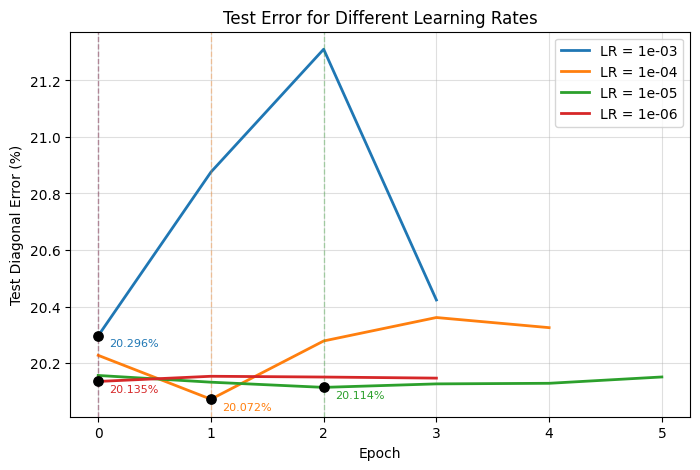

In [ ]:
# ============================================================
# Plot: Test Error for all Learning Rates
# ============================================================

if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70


# ============================================================
# Colors
# ============================================================

lr_colors = {
    1e-3: "tab:blue",
    1e-4: "tab:orange",
    1e-5: "tab:green",
    1e-6: "tab:red"
}

const_color = "tab:purple"
rand_color = "tab:brown"
point_color = "black"


# ============================================================
# Figure
# ============================================================

plt.figure(figsize=(8, 5))


# ============================================================
# Plot every learning-rate curve
# ============================================================

for learning_rate, values in lr_results.items():

    test_errors = values["test_errors"]

    # Epochs start at 0 because test_errors contains
    # the initial evaluation before training
    epochs_axis = range(len(test_errors))

    best_test_error = values["best_test_error"]

    # Epoch of minimum test error
    min_test_epoch = int(np.argmin(test_errors))

    color = lr_colors.get(
        learning_rate,
        None
    )


    # --------------------------------------------------------
    # Test Error Curve
    # --------------------------------------------------------

    plt.plot(
        epochs_axis,
        test_errors,
        label=f"LR = {learning_rate:.0e}",
        linewidth=2,
        color=color
    )


    # --------------------------------------------------------
    # Point at minimum
    # --------------------------------------------------------

    plt.scatter(
        min_test_epoch,
        best_test_error,
        s=45,
        zorder=5,
        color=point_color
    )


    # --------------------------------------------------------
    # Vertical line through minimum
    # --------------------------------------------------------

    plt.axvline(
        x=min_test_epoch,
        linestyle="--",
        linewidth=1.0,
        alpha=0.35,
        color=color
    )


    # --------------------------------------------------------
    # Annotation
    # --------------------------------------------------------

    plt.annotate(
        f"{best_test_error:.3f}%",
        xy=(
            min_test_epoch,
            best_test_error
        ),
        xytext=(8, -8),
        textcoords="offset points",
        color=color,
        fontsize=8
    )


# ============================================================
# Baselines
# ============================================================

# Get maximum number of epochs
# max_epochs = max(
#     len(values["test_errors"])
#     for values in lr_results.values()
# )

# epochs_baseline = range(max_epochs)


# Constant baseline
# plt.plot(
#     epochs_baseline,
#     [bas_const_err] * max_epochs,
#     label="Constant Error",
#     linestyle="--",
#     linewidth=1.2,
#     alpha=0.6,
#     color=const_color
# )


# Random baseline
# plt.plot(
#     epochs_baseline,
#     [bas_rand_err] * max_epochs,
#     label="Random Error",
#     linestyle="-.",
#     linewidth=1.2,
#     alpha=0.6,
#     color=rand_color
# )



# ============================================================
# Labels and title
# ============================================================

# plt.title(
#     f"{def_dataset} "
#     f"(train:{def_dataset_size[0]}, test:{def_dataset_size[1]})\n"
#     f"Batch size = {batch_Size} | "
#     f"Activation = {act} | "
#     f"Trainable = FC only"
# )

plt.title("Test Error for Different Learning Rates")


plt.xlabel("Epoch")

plt.ylabel("Test Diagonal Error (%)")


# ============================================================
# X-axis
# ============================================================

plt.xticks(
    range(max_epochs)
)


# ============================================================
# Y-axis
# ============================================================

# plt.yticks(
#     range(19, 40)
# )

# ============================================================
# Grid and legend
# ============================================================

plt.grid(
    True,
    alpha=0.4
)

plt.legend()


# ============================================================
# Save figure
# ============================================================

# os.makedirs(
#     "./results",
#     exist_ok=True
# )


# plt.savefig(
#     f"results/"
#     f"test_error_learning_rates_"
#     f"{def_dataset}_"
#     f"{def_dataset_size[0]}_"
#     f"{def_dataset_size[1]}_"
#     f"batch{batch_Size}_"
#     f"{act}.png",
#     dpi=300,
#     bbox_inches="tight"
# )


plt.show()

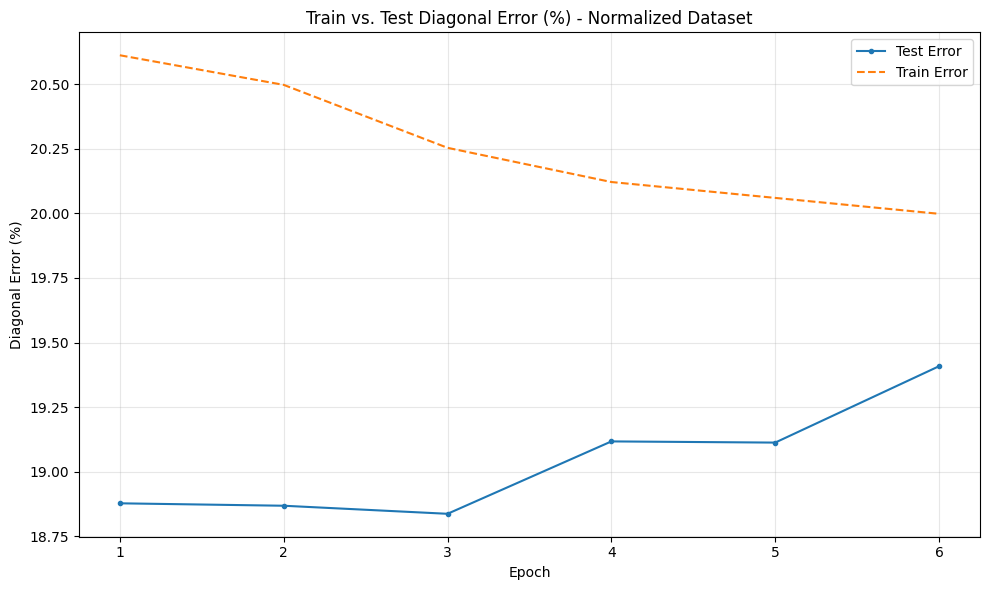

In [ ]:
if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70



# ============================================================
# Plot Test- vs. Train-Diagonal-Errors curves
# ============================================================

plt.figure(figsize=(10, 6))

test_errors = norm_results["test_errors"]
train_errors = norm_results["train_errors"]

# Epochs start at 1 because Epoch 0 was not stored in the lists
epochs_axis = range(1, len(test_errors) + 1)

plt.plot(
    epochs_axis,
    test_errors,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test Error"
)

plt.plot(
    epochs_axis,
    train_errors,
    linestyle="--",
    marker="",
    markersize=3,
    label="Train Error"
)

#############################################################
"""
# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)
"""
#############################################################

plt.xlabel("Epoch")
plt.ylabel("Diagonal Error (%)")

plt.title(
    "Train vs. Test Diagonal Error (%) - Normalized Dataset"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()



 Diagonal-Train-Error: [19.7386 19.5505 19.3537 19.1944]

 Diagonal-Test-Error: [20.0507 20.1693 20.2298 20.532 ]


 Diagonal-Train-Error-Max: 19.7386 	 Diagonal-Train-Error-Min: 19.1944	
 Diagonal-Test-Error-Max: 20.532	 Diagonal-Test-Error-Min: 20.0507	



 min_test_epoch:     1 
train_min:          19.7386 
test_min:           20.0507 



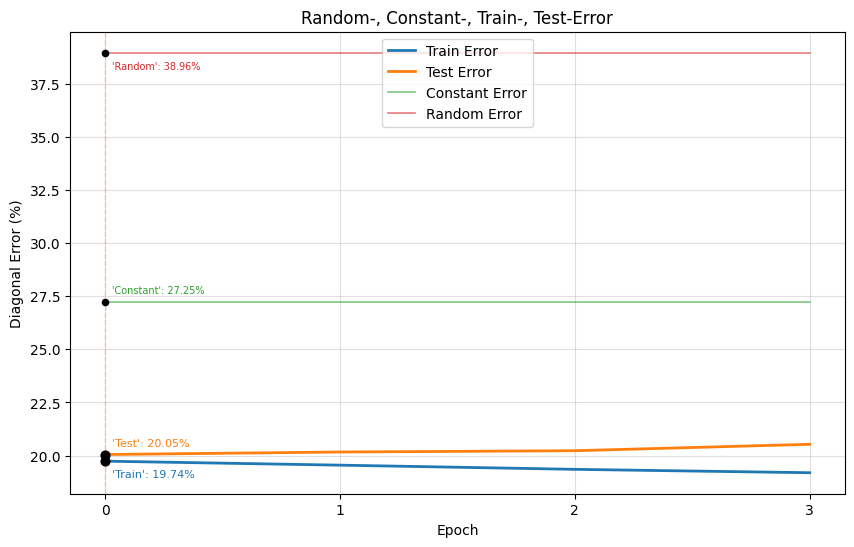

In [ ]:
# ============================================================
# Plot: Test Error for all Learning Rates
# ============================================================

if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70


# ============================================================
# Colors
# ============================================================

# Die Farbe
train_color = "tab:blue"
test_color = "tab:orange"
const_color = "tab:green"
rand_color = "tab:red"
point_color = "black"

# ============================================================
# Extract results
# ============================================================

train_errors = norm_results["train_errors"]
test_errors = norm_results["test_errors"]


print(f"\n\n Diagonal-Train-Error: {np.float64(train_errors)}\n")
print(f" Diagonal-Test-Error: {np.float64(test_errors)}\n\n")

print(f" Diagonal-Train-Error-Max: {np.max(train_errors)} \t Diagonal-Train-Error-Min: {np.min(train_errors)}\t")
# print(f" Diagonal-Train-Error-Ave: {np.mean(diag_train_error)}\n")

print(f" Diagonal-Test-Error-Max: {np.max(test_errors)}\t Diagonal-Test-Error-Min: {np.min(test_errors)}\t\n\n")
# print(f" Diagonal-Test-Error-Ave: {np.mean(diag_test_error)}\n")

# Epochs start at 0 if the initial evaluation is included.
# Otherwise, use range(1, len(test_errors) + 1).
epochs_axis = range(len(test_errors))

max_epochs = len(test_errors)
epochs_baseline = range(max_epochs)


# Curven:

# Minimum Test Error bestimmen
min_test_error = min(test_errors)
min_test_epoch = test_errors.index(min_test_error) + 1

# Die vier Werte an dieser Epoch
train_at_min = train_errors[min_test_epoch - 1]
test_at_min = test_errors[min_test_epoch - 1]
const_at_min = bas_const_err
rand_at_min = bas_rand_err

print(
    "\n",
    f"min_test_epoch:     {min_test_epoch} \n"
    f"train_min:          {train_at_min} \n"
    f"test_min:           {test_at_min} \n"
)

# ============================================================
# Best test error
# ============================================================

best_test_error = norm_results["best_test_error"]

min_test_epoch = int(np.argmin(test_errors))


# ============================================================
# Figure
# ============================================================

plt.figure(figsize=(10, 6))


# ============================================================
# Train Error Curve
# ============================================================

plt.plot(
    epochs_axis,
    train_errors,
    linestyle="-",
    linewidth=2,
    color=train_color,
    label="Train Error"
)


# ============================================================
# Test Error Curve
# ============================================================

plt.plot(
    epochs_axis,
    test_errors,
    linestyle="-",
    # marker="o",
    markersize=3,
    linewidth=2,
    color=test_color,
    label="Test Error"
)


# ============================================================
# Point at minimum test error
# ============================================================


# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)


# --------------------------------------------------------
# Vertical line through minimum
# --------------------------------------------------------

plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.0,
    alpha=0.35,
    color=test_color
)


# --------------------------------------------------------
# Annotation
# --------------------------------------------------------


# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.2f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(5, -12),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.2f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(5, 6),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)


# ============================================================
# Baselines
# ============================================================

epochs_baseline = range(0, len(test_errors))


# Constant baseline
plt.plot(
    epochs_baseline,
    [bas_const_err] * len(epochs_baseline),
    label="Constant Error",
    linestyle="-",
    linewidth=1.2,
    alpha=0.6,
    color=const_color
)


# Random baseline
plt.plot(
    epochs_baseline,
    [bas_rand_err] * len(epochs_baseline),
    label="Random Error",
    linestyle="-",
    linewidth=1.2,
    alpha=0.6,
    color=rand_color
)

plt.scatter(
    min_test_epoch,
    const_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.scatter(
    min_test_epoch,
    rand_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.annotate(
    f"'Constant': {const_at_min:.2f}%",
    xy=(min_test_epoch, const_at_min),
    xytext=(5, 6),
    textcoords="offset points",
    color=const_color,
    fontsize=7
)

plt.annotate(
    f"'Random': {rand_at_min:.2f}%",
    xy=(min_test_epoch, rand_at_min),
    xytext=(5, -12),
    textcoords="offset points",
    color=rand_color,
    fontsize=7
)


# ============================================================
# Labels and title
# ============================================================


plt.title("Random-, Constant-, Train-, Test-Error")


plt.xlabel("Epoch")

plt.ylabel("Diagonal Error (%)")


# ============================================================
# X-axis
# ============================================================

plt.xticks(
    range(len(epochs_baseline))
)


# ============================================================
# Y-axis
# ============================================================

# plt.yticks(
#     range(19, 40)
# )

# ============================================================
# Grid and legend
# ============================================================

plt.grid(
    True,
    alpha=0.4
)

plt.legend()


# ============================================================
# Save figure
# ============================================================

# os.makedirs(
#     "./results",
#     exist_ok=True
# )


# plt.savefig(
#     f"results/"
#     f"test_error_learning_rates_"
#     f"{def_dataset}_"
#     f"{def_dataset_size[0]}_"
#     f"{def_dataset_size[1]}_"
#     f"batch{batch_Size}_"
#     f"{act}.png",
#     dpi=300,
#     bbox_inches="tight"
# )


plt.show()

In [ ]:
# ---------- Evaluation ----------

saved_model = "./models/best_models/best_ResNet_Sigmoid.path"

# norm_subject:
saved_model1 = "./models/best_models/best_ResNet_Sigmoid_norm_subject.path"

# norm_random:
saved_model2 = "./models/best_models/best_ResNet_Sigmoid_norm_random.path"

checkpoint = torch.load(
    saved_model2,
    map_location=device
)

model.load_state_dict(checkpoint)

model.to(device)

model.eval()


print(f"Test:\n")
test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)

print(
        f"test_diag_error={test_diag_pct:.4f}% "
    )


targets, predictions, errors = evaluate_model(
    model,
    test_loader,
    device
)

results_df = pd.DataFrame({
    "gt_x": targets[:, 0],
    "gt_y": targets[:, 1],
    "pred_x": predictions[:, 0],
    "pred_y": predictions[:, 1]
})


# results_df.to_csv(
#     "results/heatmap/base_loss2_2.csv",
#     index=False
# )

# results_df.to_csv(
#     f"results/heatmap/base_loss1_2_{def_dataset}.csv",
#     index=False
# )

results_df.to_csv(
    f"results/heatmap/base_loss1_{def_dataset}.csv",
    index=False
)


Test:

MAE : 0.2208 	 RMSE: 0.2664 
Diagonal-Error %: 18.8366 %
test_diag_error=18.8366% 


In [ ]:
import pandas as pd


results_df = pd.DataFrame({
    "gt_x": targets[:, 0],
    "gt_y": targets[:, 1],
    "pred_x": predictions[:, 0],
    "pred_y": predictions[:, 1]
})


results_df.to_csv(
    "results/heatmap/bas_predictions_loss2.csv",
    index=False
)


	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 10000, 	 test: 2000
	 batch_Size: 	 32
	 def_dataset: 	 norm_subject
	 learning_rate: 	 0.0001
	 epochs: 	 500
	 patience: 	 3

     param in model.layer4.parameters: False
     param in model.fc.parameters: True

# def_dataset_size: train: 10000, 	 test: 2000
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 78.84 min	 | improvements: 2 Epochen	 | best_test_error: 19.6916 % 
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 76.00 min	 | improvements: 2 Epochen	 | best_test_error: 19.6736 %
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 59.63 min	 | improvements: 1 Epochen	 | best_test_error: 19.6978 % 
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 76.33 min	 | improvements: 2 Epochen	 | best_test_error: 19.6930 % 
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 74.14 min	 | improvements: 2 Epochen	 | best_test_error: 19.6562 %

best_test_error =  [19.69159, 19.67359, 19.69785, 19.69303, 19.65619] 
running_time    =  [78.84, 76.00, 59.63, 76.33, 74.14] 

################################################################################################################################
################################################################################################################################

	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 32
	 def_dataset: 	 norm_subject
	 learning_rate: 	 0.0001
	 epochs: 	 500
	 patience: 	 3
     
     param in model.layer4.parameters: False
     param in model.fc.parameters: True
     
# def_dataset_size: train: 1000, 	 test: 200
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.06 min	 | improvements: 1 Epochen	 | best_test_error: 20.0895 % 
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 7.91 min	 | improvements: 2 Epochen	 | best_test_error: 20.0419 %
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 7.48 min	 | improvements: 2 Epochen	 | best_test_error: 20.0626 % 
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 5.75 min	 | improvements: 1 Epochen	 | best_test_error: 20.1050 %
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 7.63 min	 | improvements: 2 Epochen	 | best_test_error: 20.0442 % 



best_test_error = [20.08953, 20.04193, 20.06257, 20.10499, 20.04419]
running_time    = [7.06, 7.91, 7.48, 5.75, 7.63]



In [ ]:
# dataset_size: 1000 & 200
best_test_error = [20.08953, 20.04193, 20.06257, 20.10499, 20.04419]
running_time    = [7.06, 7.91, 7.48, 5.75, 7.63]

# dataset_size: 10000 & 2000
best_test_error =  [19.69159, 19.67359, 19.69785, 19.69303, 19.65619] 
running_time    =  [78.84, 76.00, 59.63, 76.33, 74.14] 

In [ ]:
# FC + lay 4:
best_test_error =  [19.95091, 20.2972, 20.07323, 20.04155, 20.19138]
running_time    =  [7.626, 10.104, 7.248, 7.389, 7.081]

# FC only:
best_test_error = [20.08953, 20.04193, 20.06257, 20.10499, 20.04419], 
running_time    = [7.057, 7.908 7.478, 5.753, 7.628]

In [ ]:

test_error_parm, run_time_parm = [], []
for i in range(len(parameter)):
    if i % 2 == 0:
        test_error_parm.append((np.round(parameter[i], 5)))
    else:
        run_time_parm.append(np.round(parameter[i], 3))

print(f"\n test_error_parm: {np.float64(test_error_parm)} \n run_time_parm: {np.float64(run_time_parm)}\n\n")


parameter2 = []

parm_test_error = []
parm_run_time = []

for act, values in act_time_epochs.items():
    print(
        f"last_layer: {act}\t"
        f" epochs: {values['epochs']} Epochen\t|"
        f" running_time: {values['time_minutes']:.2f} min\t |"
        f" improvements: {values['improvements']} Epochen\t |"
        f" best_test_error: {values['best_test_error']:.4f} % "
    )
    parameter2.append(float(f"{values['best_test_error']:.4f}"))
    parm_test_error.append(float(f"{values['best_test_error']:.4f}"))
    parm_run_time.append(float(f"{values['time_minutes']:.2f}"))

print(f"\n parameter2: {parameter2}")
print(f"\n parameter: {np.float64([np.float64(parameter[p]) for p in range(len(parameter))])}")
print(f"\n run_time: {parm_run_time}")
print(f"\n test_error: {parm_test_error}")


 test_error_parm: [20.19735 20.17375 19.98697 20.11189 20.06467] 
 run_time_parm: [10.507 11.879  6.817 11.947  6.362]


last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 6.36 min	 | improvements: 1 Epochen	 | best_test_error: 20.0647 % 

 parameter2: [20.0647]

 parameter: [20.19735    10.50747222 20.17375    11.87886853 19.98697     6.81678813
 20.11189    11.94715597 20.06467     6.36239556]

 run_time: [6.36]

 test_error: [20.0647]


    dataset_name: 	  norm_labels.csv
    def_dataset_size: train: 1000, 	 test: 200
    batch_Size: 	  128
    dataset-splits:   norm_subject
    learning_rate: 	  0.0001
    epochs: 	      500
    patience: 	      3

## batch_size(32 vs. 64 vs. 132):
 * dataset_name: 	   norm_labels.csv
 * dataset_size:       train: 1000, 	 test: 200
 * dataset-splits: 	   norm_subject
 * batch_Size: 	       32 vs. 64 vs. 132      <============
 * learning_rate: 	   1e-4

	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 32
	 def_dataset: 	 norm_subject
	 learning_rate: 	 1e-05
	 epochs: 	 500
	 patience: 	 3

# batch_size: 	 32
 
* ** try 1 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 7.44 min	 | improvements: 2 Epochen	 | best_test_error: 20.0913 % 

* ** try 2 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 7.34 min	 | improvements: 2 Epochen	 | best_test_error: 20.0092 %  

* ** try 3 **:
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 6.07 min	 | improvements: 1 Epochen	 | best_test_error: 20.0785 %

* ** try 4 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.69 min	 | improvements: 2 Epochen	 | best_test_error: 20.0367 % 

* ** try 5 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.65 min	 | improvements: 2 Epochen	 | best_test_error: 20.0945 %

########################################################################
	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 64
	 def_dataset: 	 norm_subject
	 learning_rate: 	 1e-05
	 epochs: 	 500
	 patience: 	 3

# batch_size: 	 64

* ** try 1 **:
last_layer: Sigmoid	 epochs: 5 Epochen	| running_time: 10.26 min	 | improvements: 3 Epochen	 | best_test_error: 20.2225 % 

* ** try 2 **:
last_layer: Sigmoid	 epochs: 7 Epochen	| running_time: 14.27 min	 | improvements: 5 Epochen	 | best_test_error: 20.2962 %

* ** try 3 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.27 min	 | improvements: 2 Epochen	 | best_test_error: 20.1555 %

* ** try 4 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.08 min	 | improvements: 2 Epochen	 | best_test_error: 19.9577 %

* ** try 5 **:
last_layer: Sigmoid	 epochs: 5 Epochen	| running_time: 10.08 min	 | improvements: 3 Epochen	 | best_test_error: 19.9995 %

########################################################################
	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 128
	 def_dataset: 	 norm_subject
	 learning_rate: 	 1e-05
	 epochs: 	 500
	 patience: 	 3

# batch_size: 	 128
 
* ** try 1 **:
last_layer: Sigmoid	 epochs: 5 Epochen	| running_time: 10.51 min	 | improvements: 3 Epochen	 | best_test_error: 20.1974 %

* ** try 2 **:
last_layer: Sigmoid	 epochs: 6 Epochen	| running_time: 11.88 min	 | improvements: 4 Epochen	 | best_test_error: 20.1737 % 

* ** try 3 **:
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 6.82 min	 | improvements: 1 Epochen	 | best_test_error: 19.9870 %

* ** try 4 **:
last_layer: Sigmoid	 epochs: 6 Epochen	| running_time: 11.95 min	 | improvements: 4 Epochen	 | best_test_error: 20.1119 %

* ** try 5 **:
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 6.36 min	 | improvements: 1 Epochen	 | best_test_error: 20.0647 %


In [ ]:
parm_bat32_te = [20.0913, 20.0092, 20.0785, 20.0367, 20.0945]
parm_bat32_rt = [7.44, 7.34, 6.07, 8.69, 8.65]

parm_bat64_te = [20.2225, 20.2962, 20.1555, 19.9577, 19.9995]
parm_bat64_rt = [10.26, 14.27, 8.27, 8.08, 10.08]

parm_bat128_te = [20.19735, 20.17375, 19.98697, 20.11189, 20.06467]
parm_bat128_rt = [10.507, 11.879, 6.817, 11.947, 6.362]


In [ ]:
# parm_bat_32: 

# parm_bat32_te = [20.0913, 20.0092, 20.0785, 20.0367, 20.0945]
# parm_bat32_rt = [7.44, 7.34, 6.07, 8.69, 8.65]

parm_test_error   = parm_bat32_te
parm_running_time = parm_bat32_rt


print('\n\n')
print('#'*60)
print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')
print('#'*60)

conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time: \t\t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)




############################################################
###############	 Confidence Intervall: ###############
############################################################

 Test-Error : 		 Mean = 20.06204, 
	 Confidence interval 0.98% = [19.99926, 20.12482]

 Running-Time: 		 Mean = 7.638, 
	 Confidence interval 0.98%:  [5.818, 9.458]




In [ ]:
# parm_bat_128:

# parm_bat128_te = [20.19735, 20.17375, 19.98697, 20.11189, 20.06467]
# parm_bat128_rt = [10.507, 11.879, 6.817, 11.947, 6.362]


parm_test_error   = parm_bat64_te
parm_running_time = parm_bat64_rt

print('\n\n')
print('#'*60)
print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')
print('#'*60)

conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time: \t\t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)




############################################################
###############	 Confidence Intervall: ###############
############################################################

 Test-Error : 		 Mean = 20.12628, 
	 Confidence interval 0.98% = [19.88421, 20.36835]

 Running-Time: 		 Mean = 10.192, 
	 Confidence interval 0.98%:  [6.019, 14.365]




In [ ]:
# parm_bat_128:

parm_test_error   = parm_bat128_te
parm_running_time = parm_bat128_rt
print('\n\n')
print('#'*60)
print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')
print('#'*60)

conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time: \t\t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)




############################################################
###############	 Confidence Intervall: ###############
############################################################

 Test-Error : 		 Mean = 20.10693, 
	 Confidence interval 0.98% = [19.96464, 20.24922]

 Running-Time: 		 Mean = 9.502, 
	 Confidence interval 0.98%:  [4.936, 14.069]




In [ ]:
parm_bat32_te = [20.0913, 20.0092, 20.0785, 20.0367, 20.0945]
parm_bat32_rt = [7.44, 7.34, 6.07, 8.69, 8.65]

parm_bat64_te = [20.2225, 20.2962, 20.1555, 19.9577, 19.9995]
parm_bat64_rt = [10.26, 14.27, 8.27, 8.08, 10.08]

parm_bat128_te = [20.19735, 20.17375, 19.98697, 20.11189, 20.06467]
parm_bat128_rt = [10.507, 11.879, 6.817, 11.947, 6.362]


# 32:
 Test-Error : 		 Mean = 20.06204, 
	 Confidence interval 0.98% = [19.99926, 20.12482]
# 64:
 Test-Error : 		 Mean = 20.12628, 
	 Confidence interval 0.98% = [19.88421, 20.36835]
# 128:
 Test-Error : 		 Mean = 20.10693, 
	 Confidence interval 0.98% = [19.96464, 20.24922]


# 32:
 Running-Time: 		 Mean = 7.638, 
	 Confidence interval 0.98%:  [5.818, 9.458]
# 64:
 Running-Time: 		 Mean = 10.192, 
	 Confidence interval 0.98%:  [6.019, 14.365]
# 128:
 Running-Time: 		 Mean = 9.502, 
	 Confidence interval 0.98%:  [4.936, 14.069]


## def_dataset(norm_subject, norm_random):
 * dataset_name: 	   norm_labels.csv
 * dataset_size:       train: 1000, 	 test: 200
 * dataset-splits: 	   norm_subject vs. norm_random      <============
 * batch_Size: 	       128
 * learning_rate: 	   1e-4

	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 128
	 def_dataset: 	 norm_subject
	 learning_rate: 	 0.0001
	 epochs: 	 500
	 patience: 	 3

# dataset-splits: 	 norm_subject
 
* ** try 1 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.30 min	 | improvements: 2 Epochen	 | best_test_error: 20.1205 % 

* ** try 2 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.25 min	 | improvements: 2 Epochen	 | best_test_error: 20.0771 % 

* ** try 3 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.22 min	 | improvements: 2 Epochen	 | best_test_error: 20.0507 %

* ** try 4 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.04 min	 | improvements: 2 Epochen	 | best_test_error: 20.0485 % 

* ** try 5 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.21 min	 | improvements: 2 Epochen	 | best_test_error: 20.0101 % 

* ** try 6 **:
last_layer: Sigmoid	 epochs: 5 Epochen	| running_time: 11.28 min	 | improvements: 3 Epochen	 | best_test_error: 19.9546 %

parm_norm_sub_te = [20.1205, 20.0771, 20.0507, 20.0485, 20.0101, 19.9546]
parm_norm_sub_rt = [9.30, 9.25, 9.22, 9.04, 9.21, 11.28]


########################################################################
# dataset-splits: 	 norm_random

* ** try 1 **:
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.24 min	 | improvements: 1 Epochen	 | best_test_error: 18.8797 %

* ** try 2 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.14 min	 | improvements: 2 Epochen	 | best_test_error: 18.8308 %

* ** try 3 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.24 min	 | improvements: 2 Epochen	 | best_test_error: 18.8890 %

* ** try 4 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.98 min	 | improvements: 2 Epochen	 | best_test_error: 18.8544 %

* ** try 5 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.72 min	 | improvements: 2 Epochen	 | best_test_error: 18.9156 %

* ** try 6 **:
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 9.17 min	 | improvements: 2 Epochen	 | best_test_error: 18.8534 %


parm_norm_random_te = [18.8797, 18.8308, 18.8890, 18.8544, 18.9156, 18.8534]
parm_norm_random_rt = [7.24, 9.14, 9.24, 8.98, 9.72, 9.17]

In [ ]:

parm_norm_sub_te = [20.1205, 20.0771, 20.0507, 20.0485, 20.0101, 19.9546]
parm_norm_sub_rt = [9.30, 9.25, 9.22, 9.04, 9.21, 11.28]

parm_norm_random_te = [18.8797, 18.8308, 18.8890, 18.8544, 18.9156, 18.8534]
parm_norm_random_rt = [7.24, 9.14, 9.24, 8.98, 9.72, 9.17]

## dataset_size:((10000, 2000) vs. (1000, 200)):
 * dataset_name: 	   norm_labels.csv
 * dataset_size:       (10000, 2000) vs. (1000, 200)    <============  
 * dataset-splits: 	   norm_subject
 * batch_Size: 	       32
 * learning_rate: 	   1e-4   

# Dataset_size : 10000 & 2000 vs 1000 & 200


In [ ]:
# Dataset_size: 10000 & 2000
dataset_size1 = [19.69159, 19.67359, 19.69785, 19.69303, 19.65619]           # 10000: train & 2000: test 
running_time1  = [78.84, 76.00, 59.63, 76.33, 74.14]


# Dataset_size: 1000 & 200
dataset_size2 = [20.08953, 20.04193, 20.06257, 20.10499, 20.04419]           # 1000:  train & 200:  test
running_time2 = [7.06, 7.91, 7.48, 5.75, 7.63]


test_error1 = dataset_size1
test_error2 = dataset_size2

run_time1 = running_time1
run_time2 = running_time2

###############	 Confidence Intervall: ###############

parm_test_error   = test_error1
parm_running_time = run_time1


thema = "Dataset_size = 10000 & 2000"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)



###############	 Confidence Intervall: ###############

parm_test_error   = test_error2
parm_running_time = run_time2


thema = "Dataset_size = 1000 & 200"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error2 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time2 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)




  Thema: 	 Dataset_size = 10000 & 2000 

###############	 Confidence Intervall: 	####################

 Test-Error1 : 		 Mean = 19.68245, 
	 Confidence interval 0.98% = [19.65342, 19.71148]

 Running-Time1 : 	 Mean = 72.988, 
	 Confidence interval 0.98%:  [60.165, 85.811]




  Thema: 	 Dataset_size = 1000 & 200 

###############	 Confidence Intervall: 	####################

 Test-Error2 : 		 Mean = 20.06864, 
	 Confidence interval 0.98% = [20.02195, 20.11533]

 Running-Time2 : 	 Mean = 7.166, 
	 Confidence interval 0.98%:  [5.743, 8.589]




# trainable model layers: layer 4 & FC vs. only FC

In [ ]:
# FC + lay 4:
test_error1  =  [19.95091, 20.2972, 20.07323, 20.04155, 20.19138]
run_time1    =  [7.626, 10.104, 7.248, 7.389, 7.081]

# FC only:
test_error2  = [20.08953, 20.04193, 20.06257, 20.10499, 20.04419]
run_time2    = [7.057, 7.908, 7.478, 5.753, 7.628]


###############	 Confidence Intervall: ###############

parm_test_error   = test_error1
parm_running_time = run_time1


thema = "trainable model-layers: layer 4 & fc"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}% =  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)



###############	 Confidence Intervall: ###############

parm_test_error   = test_error2
parm_running_time = run_time2


thema = "trainable model-layers: only fc"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error2 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time2 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}% =  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


################### trainable model-layers: layer 4 & fc 
# Test-Error1 : 		 
Mean = 20.11085, 
Confidence interval 0.98% = [19.88447, 20.33724]

# Running-Time1 : 	 
Mean = 7.890, 
Confidence interval 0.98% =  [5.788, 9.991]


################## trainable model-layers: only fc 
# Test-Error2 : 		 
Mean = 20.06864 
Confidence interval 0.98% = [20.02195, 20.11533]

# Running-Time2 : 	 
Mean = 7.165 
Confidence interval 0.98% =  [5.745, 8.584]



  Thema: 	 trainable model-layers: layer 4 & fc 

###############	 Confidence Intervall: 	####################

 Test-Error1 : 		 Mean = 20.11085, 
	 Confidence interval 0.98% = [19.88447, 20.33724]

 Running-Time1 : 	 Mean = 7.890, 
	 Confidence interval 0.98%:  [5.788, 9.991]




  Thema: 	 trainable model-layers: only fc 

###############	 Confidence Intervall: 	####################

 Test-Error2 : 		 Mean = 20.06864, 
	 Confidence interval 0.98% = [20.02195, 20.11533]

 Running-Time2 : 	 Mean = 7.165, 
	 Confidence interval 0.98%:  [5.745, 8.584]




In [ ]:
 dataset_name: 	 norm_labels.csv

 def_dataset_size: train: 1000, 	 test: 200

 batch_Size: 	 32

 def_dataset: 	 norm_subject

 learning_rate: 	 0.0001

In [ ]:
# loss 1:
test_error1 = [20.0098, 	20.2339, 	20.0127, 	20.2048, 	20.1970]
run_time1 = [8.15, 		8.67, 		9.12, 		15.50, 		10.61]

# loss 2 (loss_sensetive)
test_error2 = [20.1656, 	20.2252, 	20.1940, 	20.1018, 	20.1746]
run_time2 = [14.84, 		9.96, 		13.57, 		11.91, 		8.09]



###############	 Confidence Intervall: ###############

parm_test_error   = test_error1
parm_running_time = run_time1


thema = "loss_func = loss1"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)



###############	 Confidence Intervall: ###############

parm_test_error   = test_error2
parm_running_time = run_time2


thema = "loss_func = loss2(loss_sensetive)"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error2 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time2 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


############### loss_func = loss1 
# Test-Error1 : 		 
Mean = 20.13164, 
Confidence interval 0.98 % = [19.94604, 20.31724]

# Running-Time1 : 	 
Mean = 10.410
Confidence interval 0.98 % =  [5.401, 15.419]



############### loss_func = loss2(loss_sensetive) 
# Test-Error2 : 		 
Mean = 20.17224 
Confidence interval 0.98% = [20.09596, 20.24852]

# Running-Time2 : 	 
Mean = 11.674
Confidence interval 0.98%:  [7.127, 16.221]

SyntaxError: invalid decimal literal (1353200851.py, line 86)

======================================================================
Learning Rate Experiment
======================================================================
	 Dataset:          norm_labels.csv
	 Dataset size:     train=1000, test=200
	 Batch size:       32
	 Dataset split:    norm_subject
	 Activation:       Sigmoid
	 Learning rates:   [0.001, 0.0001, 1e-05, 1e-06]
	 Epochs:           500
	 Patience:         3
	 Runs:             1
	 Trainable layers: FC only
======================================================================

======================================================================
LEARNING RATE RESULTS
======================================================================
# try 1: 
LR=1e-03 | Best Test Error=20.1291% | Time=2.41 min  | Epochs=3
LR=1e-04 | Best Test Error=20.1922% | Time=2.49 min  | Epochs=3
LR=1e-05 | Best Test Error=20.1607% | Time=2.64 min  | Epochs=3
LR=1e-06 | Best Test Error=20.1135% | Time=3.56 min  | Epochs=4

# try 2:
LR=1e-03 | Best Test Error=19.9910% | Time=2.40 min  | Epochs=3
LR=1e-04 | Best Test Error=19.9891% | Time=5.76 min  | Epochs=7
LR=1e-05 | Best Test Error=20.0767% | Time=8.51 min  | Epochs=10
LR=1e-06 | Best Test Error=19.9743% | Time=3.58 min  | Epochs=4

# try 3:
LR=1e-03 | Best Test Error=19.9670% | Time=3.29 min  | Epochs=4
LR=1e-04 | Best Test Error=19.9685% | Time=3.49 min  | Epochs=4
LR=1e-05 | Best Test Error=20.1116% | Time=5.15 min  | Epochs=6
LR=1e-06 | Best Test Error=20.0302% | Time=7.68 min  | Epochs=9

# try 4:
LR=1e-03 | Best Test Error=20.0252% | Time=3.22 min  | Epochs=4
LR=1e-04 | Best Test Error=20.0602% | Time=2.54 min  | Epochs=3
LR=1e-05 | Best Test Error=20.0178% | Time=2.68 min  | Epochs=3
LR=1e-06 | Best Test Error=20.1123% | Time=24.52 min | Epochs=28

# try 5:
LR=1e-03 | Best Test Error=20.2964% | Time=2.45 min | Epochs=3
LR=1e-04 | Best Test Error=20.0719% | Time=3.44 min | Epochs=4
LR=1e-05 | Best Test Error=20.1138% | Time=4.46 min | Epochs=5
LR=1e-06 | Best Test Error=20.1348% | Time=2.74 min | Epochs=3


# ############################################################
# Learning rate: 1e-3
LR=1e-03 | Best Test Error=20.1291% | Time=2.41 min  | Epochs=3
LR=1e-03 | Best Test Error=19.9910% | Time=2.40 min  | Epochs=3
LR=1e-03 | Best Test Error=19.9670% | Time=3.29 min  | Epochs=4
LR=1e-03 | Best Test Error=20.0252% | Time=3.22 min  | Epochs=4
LR=1e-03 | Best Test Error=20.2964% | Time=2.45 min  | Epochs=3


TE_LR_3 = [20.1291, 19.9910, 19.9670, 20.0252, 20.2964]
RT_LR_3 = [2.41, 2,40, 3.29, 3.22, 2.45]

# ############################################################
# Learning rate: 1e-4
LR=1e-04 | Best Test Error=20.1922% | Time=2.49 min  | Epochs=3
LR=1e-04 | Best Test Error=19.9891% | Time=5.76 min  | Epochs=7
LR=1e-04 | Best Test Error=19.9685% | Time=3.49 min  | Epochs=4
LR=1e-04 | Best Test Error=20.0602% | Time=2.54 min  | Epochs=3
LR=1e-04 | Best Test Error=20.0719% | Time=3.44 min  | Epochs=4


TE_LR_4 = [20.1922, 19.9891, 19.9685, 20.0602, 20.0719]
RT_LR_4 = [2.49, 5.76, 3.49, 2.54, 3.44]

# ############################################################
# Learning rate: 1e-5
LR=1e-05 | Best Test Error=20.1607% | Time=2.64 min  | Epochs=3
LR=1e-05 | Best Test Error=20.0767% | Time=8.51 min  | Epochs=10
LR=1e-05 | Best Test Error=20.1116% | Time=5.15 min  | Epochs=6
LR=1e-05 | Best Test Error=20.0178% | Time=2.68 min  | Epochs=3
LR=1e-05 | Best Test Error=20.1138% | Time=4.46 min  | Epochs=5

TE_LR_5 = [20.1607, 20.0767, 20.1116, 20.0178, 20.1138]
RT_LR_5 = [2.64, 8.51, 5.15, 2.68, 4.46]

# ############################################################
# Learning rate: 1e-6
LR=1e-06 | Best Test Error=20.1135% | Time=3.56 min  | Epochs=4
LR=1e-06 | Best Test Error=19.9743% | Time=3.58 min  | Epochs=4
LR=1e-06 | Best Test Error=20.0302% | Time=7.68 min  | Epochs=9
LR=1e-06 | Best Test Error=20.1123% | Time=24.52 min | Epochs=28
LR=1e-06 | Best Test Error=20.1348% | Time=2.74 min  | Epochs=3


TE_LR_6 = [20.1135, 19.9743, 20.0302, 20.1123, 20.1348]
RT_LR_6 = [3.56, 3.58, 7.68, 24.52, 2.74]


In [ ]:
"""     
     dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 128
	 def_dataset: 	 norm_subject
	 learning_rate: 	 XXXXXXXXXXXXXXXXXXX
	 epochs: 	 500
	 patience: 	 3

"""

# 1e-3:

best_test_error_3 = [20.08309, 20.07633, 20.14909, 20.1672, 20.12841]
running_time_3    = [6.39,     7.94,     6.29,     6.99,    7.01]

########################################################################
# 1e-4:

best_test_error_4 = [20.03305, 20.00925, 20.0298, 20.04046, 19.99575] 
running_time_4    = [9.125,    9.68,     6.48,    8.37,     6.49] 
########################################################################
# 1e-5:

best_test_error_5 = [20.08512, 20.10841, 20.11687, 20.10085, 20.11486] 
running_time_5    = [8.31,     12.15,    12.055, 6.50,          8.39]

########################################################################
# 1e-6:

best_test_error_6 = [20.32283, 20.0783, 20.05378, 20.33607, 20.36392]
running_time_6    = [6.50,     17.73,   19.66,    8.37,     6.50]


######################################################
###############	 Confidence Intervall: ###############
######################################################

parm_test_error   = best_test_error_3

parm_running_time = running_time_3


thema = "lr = 1e-3"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

parm_test_error   = best_test_error_4
parm_running_time = running_time_4


thema = "lr = 1e-4"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

parm_test_error   = best_test_error_5
parm_running_time = running_time_5


thema = "lr = 1e-5"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

parm_test_error   = best_test_error_6
parm_running_time = running_time_6

thema = "lr = 1e-6"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)

############### lr = 1e-3 
# Test-Error1 : 		 
Mean = 20.12082
Confidence interval 0.98% = [20.05374, 20.18791]

# Running-Time1 : 	 
Mean = 6.924, 
Confidence interval 0.98% =  [5.822, 8.026]


############### lr = 1e-4 
# Test-Error1 : 		 
Mean = 20.02166
Confidence interval 0.98% = [19.99060, 20.05273]

# Running-Time1 : 	 
Mean = 8.029 
Confidence interval 0.98% =  [5.542, 10.516]


############### lr = 1e-5 
# Test-Error1 : 		 
Mean = 20.10522
Confidence interval 0.98% = [20.08367, 20.12678]

# Running-Time1 : 	 
Mean = 9.481 
Confidence interval 0.98% =  [5.275, 13.687]


############### lr = 1e-6 
# Test-Error1 : 		 
Mean = 20.23098
Confidence interval 0.98% = [19.97704, 20.48492]

# Running-Time1 : 	 
Mean = 11.752, 
Confidence interval 0.98% =  [0.994, 22.510]




  Thema: 	 lr = 1e-3 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.12082, 
	 Confidence interval 0.98% = [20.05374, 20.18791]

 Running-Time1 : 	 Mean = 6.924, 
	 Confidence interval 0.98%:  [5.822, 8.026]




  Thema: 	 lr = 1e-4 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.02166, 
	 Confidence interval 0.98% = [19.99060, 20.05273]

 Running-Time1 : 	 Mean = 8.029, 
	 Confidence interval 0.98%:  [5.542, 10.516]




  Thema: 	 lr = 1e-5 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.10522, 
	 Confidence interval 0.98% = [20.08367, 20.12678]

 Running-Time1 : 	 Mean = 9.481, 
	 Confidence interval 0.98%:  [5.275, 13.687]




  Thema: 	 lr = 1e-6 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.23098, 
	 Confidence interval 0.98% = [19.97704, 20.48492]

 Running-Time1 : 	 Mean = 11.752, 
	 Confidence interval 0.98%:  [0.994, 22.510

In [ ]:
# ############################################################
# Learning rate: 1e-3
TE_LR_3 = [20.1291, 19.9910, 19.9670, 20.0252, 20.2964]
RT_LR_3 = [2.41, 2,40, 3.29, 3.22, 2.45]

# ############################################################
# Learning rate: 1e-4

TE_LR_4 = [20.1922, 19.9891, 19.9685, 20.0602, 20.0719]
RT_LR_4 = [2.49, 5.76, 3.49, 2.54, 3.44]

# ############################################################
# Learning rate: 1e-5

TE_LR_5 = [20.1607, 20.0767, 20.1116, 20.0178, 20.1138]
RT_LR_5 = [2.64, 8.51, 5.15, 2.68, 4.46]

# ############################################################
# Learning rate: 1e-6

TE_LR_6 = [20.1135, 19.9743, 20.0302, 20.1123, 20.1348]
RT_LR_6 = [3.56, 3.58, 7.68, 24.52, 2.74]



######################################################
###############	 Confidence Intervall: ###############
######################################################

# Learning rate: 1e-3
TE_LR_3 = [20.1291, 19.9910, 19.9670, 20.0252, 20.2964]
RT_LR_3 = [2.41, 2,40, 3.29, 3.22, 2.45]

parm_test_error   = TE_LR_3
parm_running_time = RT_LR_3


thema = "lr = 1e-3"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# Learning rate: 1e-4
TE_LR_4 = [20.1922, 19.9891, 19.9685, 20.0602, 20.0719]
RT_LR_4 = [2.49, 5.76, 3.49, 2.54, 3.44]

parm_test_error   = TE_LR_4
parm_running_time = RT_LR_4


thema = "lr = 1e-4"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# Learning rate: 1e-5
TE_LR_5 = [20.1607, 20.0767, 20.1116, 20.0178, 20.1138]
RT_LR_5 = [2.64, 8.51, 5.15, 2.68, 4.46]

parm_test_error   = TE_LR_5
parm_running_time = RT_LR_5


thema = "lr = 1e-5"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# Learning rate: 1e-6
TE_LR_6 = [20.1135, 19.9743, 20.0302, 20.1123, 20.1348]
RT_LR_6 = [3.56, 3.58, 7.68, 24.52, 2.74]

parm_test_error   = TE_LR_6
parm_running_time = RT_LR_6

thema = "lr = 1e-6"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)

############### lr = 1e-3 
# Test-Error: 		 
Mean = 20.08174
Confidence interval 0.98% =  [19.85549, 20.30799]

# Running-Time : 	 
Mean = 8.895
Confidence interval 0.98% =  [-12.050, 29.840]


############### lr = 1e-4 
# Test-Error: 		 
Mean = 20.05638 
Confidence interval 0.98% =  [19.90898, 20.20378]

# Running-Time: 	 
Mean = 3.544 
Confidence interval 0.98% =  [1.320, 5.768]


############### lr = 1e-5 
# Test-Error: 		 
Mean = 20.09612
Confidence interval 0.98% =  [20.00732, 20.18492]

# Running-Time:
Mean = 4.688
Confidence interval 0.98% =  [0.661, 8.715]


############### lr = 1e-6 
# Test-Error: 		 
Mean = 20.07302
Confidence interval 0.98% =  [19.95882, 20.18722]

# Running-Time: 	 
Mean = 8.416 
Confidence interval 0.98% =  [-7.012, 23.844]







# Test-Error:
############### lr = 1e-3 	 
Mean = 20.08174
############### lr = 1e-4  
Mean = 20.05638 
############### lr = 1e-5 	 
Mean = 20.09612
############### lr = 1e-6 	 
Mean = 20.07302

#############################################

############### lr = 1e-3  
Mean = 20.12082
############### lr = 1e-4  
Mean = 20.02166
############### lr = 1e-5  
Mean = 20.10522
############### lr = 1e-6  
Mean = 20.23098




# Run-Time:
############### lr = 1e-3 	 
Mean = 8.895
############### lr = 1e-4 	 
Mean = 3.544 
############### lr = 1e-5 
Mean = 4.688
############### lr = 1e-6 	 
Mean = 8.416 

#############################################

############### lr = 1e-3 
Mean = 6.924
############### lr = 1e-4  
Mean = 8.029 
############### lr = 1e-5  
Mean = 9.481 
############### lr = 1e-6 
Mean = 11.752



  Thema: 	 lr = 1e-3 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.08174, 
	 Confidence interval 0.98% = [19.85549, 20.30799]

 Running-Time1 : 	 Mean = 8.895, 
	 Confidence interval 0.98%:  [-12.050, 29.840]




  Thema: 	 lr = 1e-4 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.05638, 
	 Confidence interval 0.98% = [19.90898, 20.20378]

 Running-Time1 : 	 Mean = 3.544, 
	 Confidence interval 0.98%:  [1.320, 5.768]




  Thema: 	 lr = 1e-5 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.09612, 
	 Confidence interval 0.98% = [20.00732, 20.18492]

 Running-Time1 : 	 Mean = 4.688, 
	 Confidence interval 0.98%:  [0.661, 8.715]




  Thema: 	 lr = 1e-6 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.07302, 
	 Confidence interval 0.98% = [19.95882, 20.18722]

 Running-Time1 : 	 Mean = 8.416, 
	 Confidence interval 0.98%:  [-7.012, 23.84

	 dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 32
	 def_dataset: 	 norm_subject
	 learning_rate: 	 0.0001
	 epochs: 	 500
	 patience: 	 3
     Layer 4 : False
     FC : True

# Sigmoid :
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.59 min	 | improvements: 1 Epochen	 | best_test_error: 20.0008 % 
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.00 min	 | improvements: 1 Epochen	 | best_test_error: 20.0648 % 
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.46 min	 | improvements: 1 Epochen	 | best_test_error: 20.3106 % 
last_layer: Sigmoid	 epochs: 4 Epochen	| running_time: 8.68 min	 | improvements: 2 Epochen	 | best_test_error: 20.2817 %
last_layer: Sigmoid	 epochs: 3 Epochen	| running_time: 7.86 min	 | improvements: 1 Epochen	 | best_test_error: 19.9700 %

best_test_error1 = [20.00081, 20.06476, 20.31059, 20.2817, 19.97003]
run_time1        = [7.594, 7.003, 7.463, 8.684, 7.862]


# Gaussien :
last_layer: Gaussian  epochs: 8 Epochen	| running_time: 17.84 min	 | improvements: 4 Epochen	 | best_test_error: 20.8302 %
last_layer: Gaussian  epochs: 6 Epochen	| running_time: 24.44 min	 | improvements: 4 Epochen	 | best_test_error: 20.9760 % 
last_layer: Gaussian  epochs: 6 Epochen	| running_time: 26.45 min	 | improvements: 4 Epochen	 | best_test_error: 22.2568 %
last_layer: Gaussian  epochs: 6 Epochen	| running_time: 25.15 min	 | improvements: 4 Epochen	 | best_test_error: 22.1837 %
last_layer: Gaussian  epochs: 5 Epochen	| running_time: 18.34 min	 | improvements: 3 Epochen	 | best_test_error: 21.5474 % 

best_test_error2 = [20.8302, 20.9760, 22.2568, 22.1837, 21.5474]
run_time2        = [ 17.842, 24.440, 26.448, 25.154, 18.344]


# ReLU :
last_layer: ReLU	 epochs: 4 Epochen	| running_time: 10.84 min	 | improvements: 2 Epochen	 | best_test_error: 30.8811 %
last_layer: ReLU	 epochs: 6 Epochen	| running_time: 17.76 min	 | improvements: 4 Epochen	 | best_test_error: 20.2406 % 
last_layer: ReLU	 epochs: 4 Epochen	| running_time: 11.89 min	 | improvements: 2 Epochen	 | best_test_error: 20.3518 % 
last_layer: ReLU	 epochs: 4 Epochen	| running_time: 12.71 min	 | improvements: 2 Epochen	 | best_test_error: 31.0532 %
last_layer: ReLU	 epochs: 5 Epochen	| running_time: 14.89 min	 | improvements: 3 Epochen	 | best_test_error: 20.3017 % 

best_test_error3 = [30.8811, 20.24064, 20.35178, 31.05322, 20.3017]
run_time3        = [10.844, 17.760, 11.886, 12.714, 14.887]

# None:
last_layer: None	 epochs: 4 Epochen	| running_time: 12.37 min	 | improvements: 2 Epochen	 | best_test_error: 20.4125 % 
last_layer: None	 epochs: 4 Epochen	| running_time: 11.99 min	 | improvements: 2 Epochen	 | best_test_error: 20.3929 % 
last_layer: None	 epochs: 5 Epochen	| running_time: 18.62 min	 | improvements: 3 Epochen	 | best_test_error: 20.1443 %
last_layer: None	 epochs: 5 Epochen	| running_time: 19.89 min	 | improvements: 3 Epochen	 | best_test_error: 20.1419 %
last_layer: None	 epochs: 5 Epochen	| running_time: 19.61 min	 | improvements: 3 Epochen	 | best_test_error: 20.2582 % 

best_test_error4 = [20.41253, 20.39292, 20.14433, 20.14192, 20.2582] 
run_time4        = [12.367, 11.992, 18.623, 19.889, 19.610] 

In [ ]:
"""
     dataset_name: 	 norm_labels.csv
	 def_dataset_size: train: 1000, 	 test: 200
	 batch_Size: 	 32
	 def_dataset: 	 norm_subject
	 learning_rate: 	 0.0001
	 epochs: 	 500
	 patience: 	 3
     Layer 4 : False
     FC : True
"""

# Sigmoid :
best_test_error1 = [20.00081, 20.06476, 20.31059, 20.2817, 19.97003]
run_time1        = [7.594, 7.003, 7.463, 8.684, 7.862]


# Gaussien :
best_test_error2 = [20.8302, 20.9760, 22.2568, 22.1837, 21.5474]
run_time2        = [ 17.842, 24.440, 26.448, 25.154, 18.344]


# ReLU :
best_test_error3 = [30.8811, 20.24064, 20.35178, 31.05322, 20.3017]
run_time3        = [10.844, 17.760, 11.886, 12.714, 14.887]

# None:
best_test_error4 = [20.41253, 20.39292, 20.14433, 20.14192, 20.2582] 
run_time4        = [12.367, 11.992, 18.623, 19.889, 19.610]


######################################################
###############	 Confidence Intervall: ###############
######################################################

# Sigmoid :
best_test_error1 = [20.00081, 20.06476, 20.31059, 20.2817, 19.97003]
run_time1        = [7.594, 7.003, 7.463, 8.684, 7.862]

parm_test_error   = best_test_error1
parm_running_time = run_time1 

thema = "last-act-func: Sigmoid"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# Gaussien :
best_test_error2 = [20.8302, 20.9760, 22.2568, 22.1837, 21.5474]
run_time2        = [ 17.842, 24.440, 26.448, 25.154, 18.344]


parm_test_error   = best_test_error2
parm_running_time = run_time2

thema = "last-act-func: Gaussian"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# ReLU :
best_test_error3 = [30.8811, 20.24064, 20.35178, 31.05322, 20.3017]
run_time3        = [10.844, 17.760, 11.886, 12.714, 14.887]


parm_test_error   = best_test_error3
parm_running_time = run_time3

thema = "last-act-func: ReLU"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


######################################################
###############	 Confidence Intervall: ###############
######################################################

# None:
best_test_error4 = [20.41253, 20.39292, 20.14433, 20.14192, 20.2582] 
run_time4        = [12.367, 11.992, 18.623, 19.889, 19.610]


parm_test_error   = best_test_error4
parm_running_time = run_time4

thema = "last-act-func: None"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: ", '#'*15, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


############### last-active-func: Sigmoid 
# Test-Error:
Mean = 20.12558 
Confidence interval 0.98% = [19.85791, 20.39325]

# Running-Time:
Mean = 7.721
Confidence interval 0.98%:  [6.680, 8.763]


############### last-active-func: Gaussian 

# Test-Error:	 
Mean = 21.55882
Confidence interval 0.98% = [20.45098, 22.66666]

# Running-Time:
Mean = 22.446 
Confidence interval 0.98%:  [15.673, 29.219]


############### last-active-func: ReLU 

# Test-Error:	 
Mean = 24.56569 
Confidence interval 0.98% = [14.77270, 34.35868]

# Running-Time: 
Mean = 13.618	 
Confidence interval 0.98%:  [9.008, 18.229]


############### last-active-func: None 

# Test-Error:	 
Mean = 20.26998
Confidence interval 0.98% = [20.05188, 20.48808]

# Running-Time:	 
Mean = 16.496
Confidence interval 0.98%:  [9.842, 23.150]




  Thema: 	 last-act-func: Sigmoid 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.12558, 
	 Confidence interval 0.98% = [19.85791, 20.39325]

 Running-Time1 : 	 Mean = 7.721, 
	 Confidence interval 0.98%:  [6.680, 8.763]




  Thema: 	 last-act-func: Gaussian 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 21.55882, 
	 Confidence interval 0.98% = [20.45098, 22.66666]

 Running-Time1 : 	 Mean = 22.446, 
	 Confidence interval 0.98%:  [15.673, 29.219]




  Thema: 	 last-act-func: ReLU 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 24.56569, 
	 Confidence interval 0.98% = [14.77270, 34.35868]

 Running-Time1 : 	 Mean = 13.618, 
	 Confidence interval 0.98%:  [9.008, 18.229]




  Thema: 	 last-act-func: None 

###############	 Confidence Intervall: ###############

 Test-Error1 : 		 Mean = 20.26998, 
	 Confidence interval 0.98% = [20.05188, 20.48808]

 Running-Time1 : 	 Mean = 16.

In [ ]:
# Splits-type: norm_random vs. norm_subject:


parm_norm_sub_te = [20.1205, 20.0771, 20.0507, 20.0485, 20.0101, 19.9546]
parm_norm_sub_rt = [9.30, 9.25, 9.22, 9.04, 9.21, 11.28]

parm_norm_random_te = [18.8797, 18.8308, 18.8890, 18.8544, 18.9156, 18.8534]
parm_norm_random_rt = [7.24, 9.14, 9.24, 8.98, 9.72, 9.17]


###############	 Confidence Intervall: ###############

parm_test_error   = parm_norm_sub_te
parm_running_time = parm_norm_sub_rt


thema = "Splits-type: subjectindipended"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error1 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time1 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)



###############	 Confidence Intervall: ###############

parm_test_error   = parm_norm_random_te
parm_running_time = parm_norm_random_rt


thema = "Splits-type: norm_random"
print(f'\n\n  Thema: \t {thema} \n')

print('#'*15, "\t Confidence Intervall: \t", '#'*20, sep='')


conf = 0.98

test_error_confidence = confidence_interval(parm_test_error, conf)
run_time_confidence   = confidence_interval(parm_running_time, conf)

print(
    f"\n Test-Error2 : \t\t Mean = {test_error_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{test_error_confidence[1]:.5f}, {test_error_confidence[2]:.5f}]"
)

print(
    f"\n Running-Time2 : \t Mean = {run_time_confidence[0]:.3f}, "
    f"\n\t Confidence interval {conf}%:  [{run_time_confidence[1]:.3f}, {run_time_confidence[2]:.3f}]\n\n"
)


############### Splits-type: subjectindipended 
# Test-Error1 : 		 
Mean = 20.04358 
Confidence interval 0.98% = [19.96550, 20.12167]

# Running-Time1 : 	 
Mean = 9.550 
Confidence interval 0.98% =  [8.380, 10.720]



############### Splits-type: norm_random 
# Test-Error2 : 		 
Mean = 18.87048
Confidence interval 0.98% = [18.82887, 18.91210]

# Running-Time2 : 	 
Mean = 8.915 
Confidence interval 0.98% =  [7.737, 10.093] 



  Thema: 	 Splits-type: subjectindipended 

###############	 Confidence Intervall: 	####################

 Test-Error1 : 		 Mean = 20.04358, 
	 Confidence interval 0.98% = [19.96550, 20.12167]

 Running-Time1 : 	 Mean = 9.550, 
	 Confidence interval 0.98%:  [8.380, 10.720]




  Thema: 	 Splits-type: norm_random 

###############	 Confidence Intervall: 	####################

 Test-Error2 : 		 Mean = 18.87048, 
	 Confidence interval 0.98% = [18.82887, 18.91210]

 Running-Time2 : 	 Mean = 8.915, 
	 Confidence interval 0.98%:  [7.737, 10.093]




In [ ]:
# lr_curves_manual.py


patience = 1000
epochs = 15                                   # 15

act = "Sigmoid"

trainable_layers = "FC only"
# ============================================================
# Fixed configuration: NORMALIZED DATASET
# ============================================================
print("\n" + "=" * 70)
print("NORMALIZED DATASET EXPERIMENT: ")


print(f"\tDataset_type:         {dataset_name}")
print(f"\tDataset split:        {def_dataset}")
print(f"\tTrain size:           {def_dataset_size[0]}")
print(f"\tTest size:            {def_dataset_size[1]}")
print(f"\tBatch size:           {batch_Size}")
# print(f"\tLearning rate:        {learning_rate}")
print(f"\tActivation:           {act}")
print(f"\tTrainable layers:     {trainable_layers}")
print(f"\tMax_Epochs:           {epochs}")
print(f"\tPatience:             {patience}")
print("=" * 70)


lr_type = [1e-4] 

lr_epochs = {}

for learning_rate in lr_type:

    # acts = ['Sigmoid', 'Gaussian', 'ReLU', 'None']
    # act = "Sigmoid"
    
    # trainable_layers = "FC only"
    
    
    # print("\n" + "=" * 70)
    # print("NORMALIZED DATASET EXPERIMENT: ")
    
    
    # print(f"\tDataset_type:         {dataset_name}")
    # print(f"\tDataset split:        {def_dataset}")
    # print(f"\tTrain size:           {def_dataset_size[0]}")
    # print(f"\tTest size:            {def_dataset_size[1]}")
    # print(f"\tBatch size:           {batch_Size}")
    # print(f"\tLearning rate:        {learning_rate}")
    # print(f"\tActivation:           {act}")
    # print(f"\tTrainable layers:     {trainable_layers}")
    # print(f"\tMax_Epochs:           {epochs}")
    # print(f"\tPatience:             {patience}")
    # print("=" * 70)
    
    
    
    
    if globals().get("bas_const_err") is None:
        bas_const_err = 27.245
    
    if globals().get("bas_rand_err") is None:
        bas_rand_err = 38.961
    
    
    
    # --------------------------------------------------------
    # Start total training timer
    # --------------------------------------------------------
    
    train_start = time.perf_counter()
    
    
    
    epochs = epochs
    
    
    
    # model_output = './models/best_models'
    # model_dir= Path(model_output)
    
    # if not os.path.exists(model_dir):
    #     model_dir.mkdir(
    #         parents=True,
    #         exist_ok=True
    #     )
    
    
    # diagrams_output = './results/best_diagrams'
    # diagrams_dir= Path(diagrams_output)
    
    # if not os.path.exists(diagrams_dir):
    #     diagrams_dir.mkdir(
    #         parents=True,
    #         exist_ok=True
    #     )
    
    
    
    # ============================================================
    # Store train and test error curves
    # ============================================================
    
    # train_errors = []
    # test_errors = []
    
    best_error = float("inf")
    
    patience_counter = 0                        # Number Epochen without Optimierung
    improvements = 0                            # Number Epochen with Optimierung
    best_epoch = 0
    
    diag_train_errors = []
    diag_test_errors  = []
    
    
    
    
    criterion = nn.L1Loss()
    
    criterion_base = nn.L1Loss()
    
    # --------------------------------------------------------
    # Reset model
    # --------------------------------------------------------
    
    model, model_name = reset_model(act=act)
    
    model.to(device)
    
    # --------------------------------------------------------
    # Freeze all parameters
    # --------------------------------------------------------
    
    for param in model.parameters():
        param.requires_grad = False
    
    
    # --------------------------------------------------------
    # Unfreeze ONLY FC
    # --------------------------------------------------------
    
    for param in model.layer4.parameters():
        param.requires_grad=False
    
    
    for param in model.fc.parameters():
        param.requires_grad = True
    
    
    
    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=weight_Decay
    )
    
    
    
    
    
    print('\n ',"=#=" * 25)
    # print(f"\t\t last Active Function: {act}")
    print(f"\tLearning rate:        {learning_rate}")
    print(' ',"=#=" * 25)
    
    
    # ============================================================
    # Initial evaluation before training
    # ============================================================
    print("\n\t Initial evaluation: \n")
    
    # model.eval()
    
    # print("train_error:")
    # train_mae, train_rmse, train_diag_pct = diagonal_errors(
    #     model,
    #     train_loader,
    #     device
    # )
    
    # train_diag_pct = np.round(float(train_diag_pct), 4)
    # diag_train_errors.append(train_diag_pct)
    
    
    
    
    # print("\ntest_error:")
    # test_mae, test_rmse, test_diag_pct = diagonal_errors(
    #     model,
    #     test_loader,
    #     device
    # )

    const_mae, const_rmse, test_diag_pct = constant_baseline(train_loader, test_loader)
    
    test_diag_pct = np.round(float(test_diag_pct), 4)
    
    diag_test_errors.append(test_diag_pct)
    diag_train_errors.append(test_diag_pct)
    
    
    print(
        f"Epoch 0 | "
        # f"Train error: {train_diag_pct:.4f}% | "
        f"Test error: {test_diag_pct:.4f}%"
    )
    
    
    
    # Initial best test error
    if best_error is None or test_diag_pct < best_error:  
        best_error = test_diag_pct
        best_epoch = 0
    
    
    # save the better Modell
    # torch.save(
    #     model.state_dict(),
    #     f"./models/best_models/"
    #     f"best_{model_name}_{act}_{def_dataset}.path"
    # )
    
    # ============================================================
    # Training
    # ============================================================
    
    print("\n\n\t Training: \n")
    
    
    for epoch in range(epochs):
    
        epoch_start = time.perf_counter()
    
        model.train()
    
        running_loss = 0.0
    
    
        loop = tqdm(
            train_loader,
            desc=f"Normalized | Epoch {epoch + 1}"
        )
        
    
        for images, targets in loop:
            
            images = images.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()
            
            preds = model(images)
    
            ################################
            # Loss 1:
            ################################
            
            loss = criterion(
                preds,
                targets
            )
    
    
            
            ################################
            # Loss 2: 
            ################################
            
            # loss = sensitive_loss(
            #     preds,
            #     targets
            # )
            
            ################################
    
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
            loop.set_postfix(
                loss=loss.item()
            )
    
        
    
        # ========================================================
        # Evaluation after epoch
        # ========================================================
    
        model.eval()
    
    
        # --------------------------------------------------------
        # Train error
        # --------------------------------------------------------
        print("\n Train:")
        
        train_mae, train_rmse, train_diag_pct = evaluate_1(
            model,
            train_loader,
            device
        )
        
        # train_mae, train_rmse, train_diag_pct = diagonal_errors(
        #     model,
        #     train_loader,
        #     device
        # )
    
        train_diag_pct = np.round(float(train_diag_pct), 4)
        diag_train_errors.append(train_diag_pct)
    
    
        # --------------------------------------------------------
        # Test error
        # --------------------------------------------------------
        print("\n Test:")
        test_mae, test_rmse, test_diag_pct = evaluate_1(
            model,
            test_loader,
            device
        )
        
        # test_mae, test_rmse, test_diag_pct = diagonal_errors(
        #     model,
        #     test_loader,
        #     device
        # )
    
        test_diag_pct = np.round(float(test_diag_pct), 4)
        diag_test_errors.append(test_diag_pct)
    
    
        # --------------------------------------------------
        # Early Stopping
        # --------------------------------------------------
    
        if test_diag_pct < best_error:
    
            best_error = test_diag_pct
    
            best_epoch = epoch + 1
    
            patience_counter = 0
            improvements += 1
    
            print(
                f"\nTest-Diagonal-Error: "
                f"{test_diag_pct:.4f}% | "
                f"Improvement: {improvements}"
            )
    
            # save the better Modell
            # torch.save(
            #     model.state_dict(),
            #     f"./models/best_models/"
            #     f"best_{model_name}_{act}_{def_dataset}.path"
            # )
        
    
        else:
    
            # without imporovement
            patience_counter += 1
    
            # print(
            #     f"\nPatience: "
            #     f"{patience_counter}/{patience}"
            # )
    
    
            # if patience_counter >= patience:
    
            #     print(
            #         f"\nEarly Stopping after "
            #         f"{epoch + 1} epochs."
            #     )
            #     print(
            #         f"Imporovments totally: {improvements}"
            #     )
    
            #     break
        
    
        # ========================================================
        # Epoch information
        # ========================================================
    
        epoch_end = time.perf_counter()
    
        epoch_time = epoch_end - epoch_start
    
    
        print(
            f"\n[{datetime.now().strftime('%H:%M:%S')}] "
            f"Epoch {epoch + 1}: | " 
            f"{epoch_time:.2f} s | "
            f"Loss: {running_loss / len(train_loader):.4f} | "
            f"Train-Error: {train_diag_pct:.4f}% | "
            f"Test-Error: {test_diag_pct:.4f}%"
        )
    
        # torch.save(
        #         model.state_dict(),
        #         f"./models/best_models/"
        #         f"last_{model_name}_{act}_{def_dataset}.path"
        #     )
    
    
    
    # ============================================================
    # Total running time
    # ============================================================
    
    train_end = time.perf_counter()
    
    elapsed_running_time = train_end - train_start
    
    elapsed_minutes = elapsed_running_time / 60
    
    print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} s")
    print(f"totll running-tiems (min): {elapsed_minutes:.2f} min\n")
    
    # ============================================================
    # Number of completed epochs
    # ============================================================
    
    epochs_completed = len(diag_test_errors)


# # ============================================================
# # Store normalized-dataset results
# # ============================================================

    norm_results = {
        "dataset": "normalized",
        "dataset_split": def_dataset,
        "train_size": def_dataset_size[0],
        "test_size": def_dataset_size[1],
        "batch_size": batch_Size,
        "learning_rate": learning_rate,
        "activation": act,
        "trainable_layers": trainable_layers,
        "patience": patience,
        "train_errors": diag_train_errors,
        "test_errors": diag_test_errors,
        "best_test_error": best_error,
        "running_time_minutes": elapsed_minutes,
        "epochs": epochs_completed,
        "best_epoch": best_epoch,
        "improvements": improvements
    }


    # ========================================================
    # Print result for this learning rate
    # ========================================================
    
    print("\n" + "=" * 70)
    print("NORMALIZED DATASET RESULTS")
    print("=" * 70)
    
    print(
        f"Best Test Error:   {norm_results['best_test_error']:.4f}%"
    )
    print(
        f"Running Time:      {norm_results['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:            {norm_results['epochs']}"
    )
    print(
        f"Best Epoch:        {norm_results['best_epoch']}"
    )
    print(
        f"Improvements:      {norm_results['improvements']}"
    )
    print("=" * 70)
    
    
    
    
    
    lr_epochs[learning_rate] = {
        "time_minutes": elapsed_minutes,
        "epochs": epoch + 1,
        "improvements": improvements,
        "best_test_error": best_error,
        "train_errors" : diag_train_errors,
        "test_errors" : diag_test_errors
    }





NORMALIZED DATASET EXPERIMENT: 
	Dataset_type:         norm_labels.csv
	Dataset split:        norm_random
	Train size:           1000
	Test size:            200
	Batch size:           32
	Activation:           Sigmoid
	Trainable layers:     FC only
	Max_Epochs:           15
	Patience:             1000

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
	Learning rate:        0.0001
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Initial evaluation: 

Konstante Vorhersage: [0.470248, 0.477854]
MAE: 0.34148
RMSE: 0.37846
Diagonal-Error: 26.76126 %
Epoch 0 | Test error: 26.7613%


	 Training: 



Normalized | Epoch 1: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:48<00:00,  1.51s/it, loss=0.203]



 Train:
MAE : 0.2431 	 RMSE: 0.2884 
Diagonal-Error %: 26.6347 %

 Test:
MAE : 0.2191 	 RMSE: 0.2664 
Diagonal-Error %: 24.2084 %

Test-Diagonal-Error: 24.2084% | Improvement: 1

[21:10:59] Epoch 1: | 116.12 s | Loss: 0.2442 | Train-Error: 26.6347% | Test-Error: 24.2084%


Normalized | Epoch 2: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:56<00:00,  1.76s/it, loss=0.287]



 Train:
MAE : 0.2405 	 RMSE: 0.2864 
Diagonal-Error %: 26.4216 %

 Test:
MAE : 0.2219 	 RMSE: 0.2677 
Diagonal-Error %: 24.3639 %

[21:13:02] Epoch 2: | 122.36 s | Loss: 0.2439 | Train-Error: 26.4216% | Test-Error: 24.3639%


...


 Train:
MAE : 0.2178 	 RMSE: 0.2668 
Diagonal-Error %: 23.9626 %

 Test:
MAE : 0.2168 	 RMSE: 0.2782 
Diagonal-Error %: 23.8409 %

[21:33:54] Epoch 13: | 101.20 s | Loss: 0.2230 | Train-Error: 23.9626% | Test-Error: 23.8409%


Normalized | Epoch 14: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:45<00:00,  1.41s/it, loss=0.208]



 Train:
MAE : 0.2141 	 RMSE: 0.2623 
Diagonal-Error %: 23.5508 %

 Test:
MAE : 0.2162 	 RMSE: 0.2725 
Diagonal-Error %: 23.7858 %

[21:35:31] Epoch 14: | 96.93 s | Loss: 0.2251 | Train-Error: 23.5508% | Test-Error: 23.7858%


Normalized | Epoch 15: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:44<00:00,  1.40s/it, loss=0.221]



 Train:
MAE : 0.2093 	 RMSE: 0.2578 
Diagonal-Error %: 23.1495 %

 Test:
MAE : 0.2229 	 RMSE: 0.2706 
Diagonal-Error %: 24.4149 %

[21:37:07] Epoch 15: | 96.45 s | Loss: 0.2193 | Train-Error: 23.1495% | Test-Error: 24.4149%

totll running-tiems (s): 1684.75 s
totll running-tiems (min): 28.08 min


NORMALIZED DATASET RESULTS
Best Test Error:   23.6947%
Running Time:      28.08 min
Epochs:            16
Best Epoch:        10
Improvements:      2


In [ ]:

for value in lr_epochs:
    # print(np.float64(lr_epochs[value]['train_errors']))
    train_errors = np.float64(lr_epochs[value]['train_errors'])
    # print(np.float64(lr_epochs[value]['test_errors']))
    test_errors = np.float64(lr_epochs[value]['test_errors'])
    best_test_error = lr_epochs[value]["best_test_error"]

print(f"\n\ntrain = {train_errors}")
print(f"\ntest = {test_errors}")
print(f"\n best-test: {best_test_error}")




train = [26.7613 26.6347 26.4216 26.2379 25.9221 25.6403 25.4239 25.0735 24.8773
 24.6773 24.6152 24.2489 23.8215 23.9626 23.5508 23.1495]

test = [26.7613 24.2084 24.3639 24.7327 24.6157 24.4611 24.5366 24.2719 24.6812
 24.9105 23.6947 23.9105 24.573  23.8409 23.7858 24.4149]

 best-test: 23.6947




train = [26.7613 26.6347 26.4216 26.2379 25.9221 25.6403 25.4239 25.0735 24.8773
 24.6773 24.6152 24.2489 23.8215 23.9626 23.5508 23.1495]

test = [26.7613 24.2084 24.3639 24.7327 24.6157 24.4611 24.5366 24.2719 24.6812
 24.9105 23.6947 23.9105 24.573  23.8409 23.7858 24.4149]

 best-test: 23.6947


 Diagonal-Train-Error: [26.7613 26.6347 26.4216 26.2379 25.9221 25.6403 25.4239 25.0735 24.8773
 24.6773 24.6152 24.2489 23.8215 23.9626 23.5508 23.1495]

 Diagonal-Test-Error: [26.7613 24.2084 24.3639 24.7327 24.6157 24.4611 24.5366 24.2719 24.6812
 24.9105 23.6947 23.9105 24.573  23.8409 23.7858 24.4149]


 Diagonal-Train-Error-Max: 26.7613 	 Diagonal-Train-Error-Min: 23.1495	
 Diagonal-Test-Error-Max: 26.7613	 Diagonal-Test-Error-Min: 23.6947	



 min_test_epoch:     11 
train_min:          24.6152 
test_min:           23.6947 



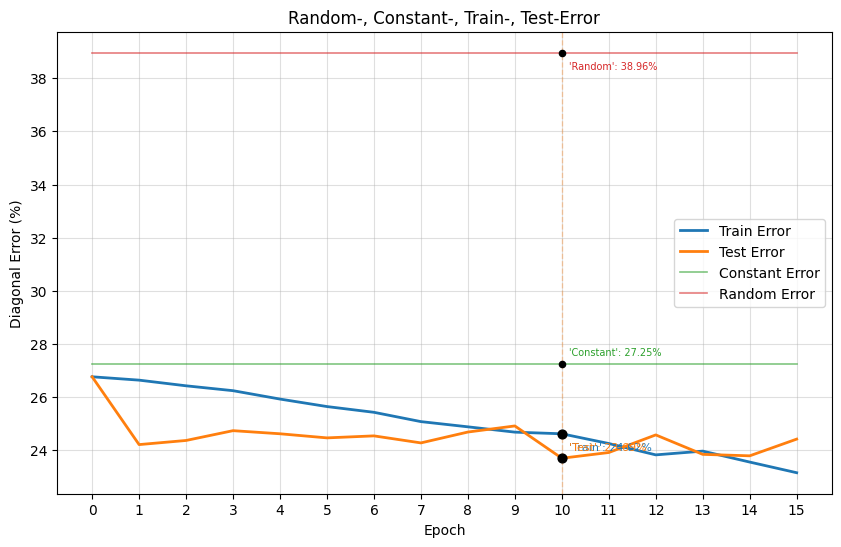

In [ ]:
# ============================================================
# Plot: Test Error for all Learning Rates
# ============================================================

if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70


# ============================================================
# Colors
# ============================================================

# Die Farbe
train_color = "tab:blue"
test_color = "tab:orange"
const_color = "tab:green"
rand_color = "tab:red"
point_color = "black"

# ============================================================
# Extract results
# ============================================================

for value in lr_epochs:
    # print(np.float64(lr_epochs[value]['train_errors']))
    train_errors = np.float64(lr_epochs[value]['train_errors'])
    # print(np.float64(lr_epochs[value]['test_errors']))
    test_errors = np.float64(lr_epochs[value]['test_errors'])
    best_test_error = lr_epochs[value]["best_test_error"]

print(f"\n\ntrain = {train_errors}")
print(f"\ntest = {test_errors}")
print(f"\n best-test: {best_test_error}")

# train_errors = norm_results["train_errors"]
# test_errors = norm_results["test_errors"]


print(f"\n\n Diagonal-Train-Error: {train_errors}\n")
print(f" Diagonal-Test-Error: {test_errors}\n\n")

print(f" Diagonal-Train-Error-Max: {np.max(train_errors)} \t Diagonal-Train-Error-Min: {np.min(train_errors)}\t")
# print(f" Diagonal-Train-Error-Ave: {np.mean(diag_train_error)}\n")

print(f" Diagonal-Test-Error-Max: {np.max(test_errors)}\t Diagonal-Test-Error-Min: {np.min(test_errors)}\t\n\n")
# print(f" Diagonal-Test-Error-Ave: {np.mean(diag_test_error)}\n")

# Epochs start at 0 if the initial evaluation is included.
# Otherwise, use range(1, len(test_errors) + 1).
epochs_axis = range(len(test_errors))

max_epochs = len(test_errors)
epochs_baseline = range(max_epochs)


# Curven:

# Minimum Test Error bestimmen
# min_test_error = min(test_errors)
# min_test_epoch = test_errors.index(min_test_error) + 1

min_test_error = np.min(test_errors)
min_test_epoch = np.argmin(test_errors) + 1

# Die vier Werte an dieser Epoch
train_at_min = train_errors[min_test_epoch - 1]
test_at_min = test_errors[min_test_epoch - 1]
const_at_min = bas_const_err
rand_at_min = bas_rand_err

print(
    "\n",
    f"min_test_epoch:     {min_test_epoch} \n"
    f"train_min:          {train_at_min} \n"
    f"test_min:           {test_at_min} \n"
)

# ============================================================
# Best test error
# ============================================================

# best_test_error = lr_epoch["best_test_error"]

min_test_epoch = int(np.argmin(test_errors))


# ============================================================
# Figure
# ============================================================

plt.figure(figsize=(10, 6))


# ============================================================
# Train Error Curve
# ============================================================

plt.plot(
    epochs_axis,
    train_errors,
    linestyle="-",
    linewidth=2,
    color=train_color,
    label="Train Error"
)


# ============================================================
# Test Error Curve
# ============================================================

plt.plot(
    epochs_axis,
    test_errors,
    linestyle="-",
    # marker="o",
    markersize=3,
    linewidth=2,
    color=test_color,
    label="Test Error"
)


# ============================================================
# Point at minimum test error
# ============================================================


# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)


# --------------------------------------------------------
# Vertical line through minimum
# --------------------------------------------------------

plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.0,
    alpha=0.35,
    color=test_color
)


# --------------------------------------------------------
# Annotation
# --------------------------------------------------------


# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.2f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(5, -12),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.2f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(5, 6),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)


# ============================================================
# Baselines
# ============================================================

epochs_baseline = range(0, len(test_errors))


# Constant baseline
plt.plot(
    epochs_baseline,
    [bas_const_err] * len(epochs_baseline),
    label="Constant Error",
    linestyle="-",
    linewidth=1.2,
    alpha=0.6,
    color=const_color
)


# Random baseline
plt.plot(
    epochs_baseline,
    [bas_rand_err] * len(epochs_baseline),
    label="Random Error",
    linestyle="-",
    linewidth=1.2,
    alpha=0.6,
    color=rand_color
)

plt.scatter(
    min_test_epoch,
    const_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.scatter(
    min_test_epoch,
    rand_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.annotate(
    f"'Constant': {const_at_min:.2f}%",
    xy=(min_test_epoch, const_at_min),
    xytext=(5, 6),
    textcoords="offset points",
    color=const_color,
    fontsize=7
)

plt.annotate(
    f"'Random': {rand_at_min:.2f}%",
    xy=(min_test_epoch, rand_at_min),
    xytext=(5, -12),
    textcoords="offset points",
    color=rand_color,
    fontsize=7
)


# ============================================================
# Labels and title
# ============================================================


plt.title("Random-, Constant-, Train-, Test-Error")


plt.xlabel("Epoch")

plt.ylabel("Diagonal Error (%)")


# ============================================================
# X-axis
# ============================================================

plt.xticks(
    range(len(epochs_baseline))
)


# ============================================================
# Y-axis
# ============================================================

# plt.yticks(
#     range(19, 40)
# )

# ============================================================
# Grid and legend
# ============================================================

plt.grid(
    True,
    alpha=0.4
)

plt.legend()


# ============================================================
# Save figure
# ============================================================

# os.makedirs(
#     "./results",
#     exist_ok=True
# )


plt.savefig(
    f"figures/"
    f"normalize_test_train_errors.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
# lr_curves_manual.py


patience = 1000
epochs = 15                                   # 15

act = "Sigmoid"

trainable_layers = "FC only"
# ============================================================
# Fixed configuration: NORMALIZED DATASET
# ============================================================
print("\n" + "=" * 70)
print("NORMALIZED DATASET EXPERIMENT: ")


print(f"\tDataset_type:         {dataset_name}")
print(f"\tDataset split:        {def_dataset}")
print(f"\tTrain size:           {def_dataset_size[0]}")
print(f"\tTest size:            {def_dataset_size[1]}")
print(f"\tBatch size:           {batch_Size}")
# print(f"\tLearning rate:        {learning_rate}")
print(f"\tActivation:           {act}")
print(f"\tTrainable layers:     {trainable_layers}")
print(f"\tMax_Epochs:           {epochs}")
print(f"\tPatience:             {patience}")
print("=" * 70)


lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 

lr_epochs = {}

for learning_rate in lr_type:

    # acts = ['Sigmoid', 'Gaussian', 'ReLU', 'None']
    # act = "Sigmoid"
    
    # trainable_layers = "FC only"
    
    
    # print("\n" + "=" * 70)
    # print("NORMALIZED DATASET EXPERIMENT: ")
    
    
    # print(f"\tDataset_type:         {dataset_name}")
    # print(f"\tDataset split:        {def_dataset}")
    # print(f"\tTrain size:           {def_dataset_size[0]}")
    # print(f"\tTest size:            {def_dataset_size[1]}")
    # print(f"\tBatch size:           {batch_Size}")
    # print(f"\tLearning rate:        {learning_rate}")
    # print(f"\tActivation:           {act}")
    # print(f"\tTrainable layers:     {trainable_layers}")
    # print(f"\tMax_Epochs:           {epochs}")
    # print(f"\tPatience:             {patience}")
    # print("=" * 70)
    
    
    
    
    if globals().get("bas_const_err") is None:
        bas_const_err = 27.245
    
    if globals().get("bas_rand_err") is None:
        bas_rand_err = 38.961
    
    
    
    # --------------------------------------------------------
    # Start total training timer
    # --------------------------------------------------------
    
    train_start = time.perf_counter()
    
    
    
    epochs = epochs
    
    
    
    # model_output = './models/best_models'
    # model_dir= Path(model_output)
    
    # if not os.path.exists(model_dir):
    #     model_dir.mkdir(
    #         parents=True,
    #         exist_ok=True
    #     )
    
    
    # diagrams_output = './results/best_diagrams'
    # diagrams_dir= Path(diagrams_output)
    
    # if not os.path.exists(diagrams_dir):
    #     diagrams_dir.mkdir(
    #         parents=True,
    #         exist_ok=True
    #     )
    
    
    
    # ============================================================
    # Store train and test error curves
    # ============================================================
    
    # train_errors = []
    # test_errors = []
    
    best_error = float("inf")
    
    patience_counter = 0                        # Number Epochen without Optimierung
    improvements = 0                            # Number Epochen with Optimierung
    best_epoch = 0
    
    diag_train_errors = []
    diag_test_errors  = []
    
    
    
    
    criterion = nn.L1Loss()
    
    criterion_base = nn.L1Loss()
    
    # --------------------------------------------------------
    # Reset model
    # --------------------------------------------------------
    
    model, model_name = reset_model(act=act)
    
    model.to(device)
    
    # --------------------------------------------------------
    # Freeze all parameters
    # --------------------------------------------------------
    
    for param in model.parameters():
        param.requires_grad = False
    
    
    # --------------------------------------------------------
    # Unfreeze ONLY FC
    # --------------------------------------------------------
    
    for param in model.layer4.parameters():
        param.requires_grad=False
    
    
    for param in model.fc.parameters():
        param.requires_grad = True
    
    
    
    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=weight_Decay
    )
    
    
    
    
    
    print('\n ',"=#=" * 25)
    # print(f"\t\t last Active Function: {act}")
    print(f"\tLearning rate:        {learning_rate}")
    print(' ',"=#=" * 25)
    
    
    # ============================================================
    # Initial evaluation before training
    # ============================================================
    print("\n\t Initial evaluation: \n")
    
    # model.eval()
    
    # print("train_error:")
    # train_mae, train_rmse, train_diag_pct = diagonal_errors(
    #     model,
    #     train_loader,
    #     device
    # )
    
    # train_diag_pct = np.round(float(train_diag_pct), 4)
    # diag_train_errors.append(train_diag_pct)
    
    
    
    
    # print("\ntest_error:")
    # test_mae, test_rmse, test_diag_pct = diagonal_errors(
    #     model,
    #     test_loader,
    #     device
    # )

    const_mae, const_rmse, test_diag_pct = constant_baseline(train_loader, test_loader)
    
    test_diag_pct = np.round(float(test_diag_pct), 4)
    diag_test_errors.append(test_diag_pct)
    diag_train_errors.append(test_diag_pct)
    
    
    print(
        f"Epoch 0 | "
        # f"Train error: {train_diag_pct:.4f}% | "
        f"Test error: {test_diag_pct:.4f}%"
    )
    
    
    
    # Initial best test error
    if best_error is None or test_diag_pct < best_error:  
        best_error = test_diag_pct
        best_epoch = 0
    
    
    # save the better Modell
    # torch.save(
    #     model.state_dict(),
    #     f"./models/best_models/"
    #     f"best_{model_name}_{act}_{def_dataset}.path"
    # )
    
    # ============================================================
    # Training
    # ============================================================
    
    print("\n\n\t Training: \n")
    
    
    for epoch in range(epochs):
    
        epoch_start = time.perf_counter()
    
        model.train()
    
        running_loss = 0.0
    
    
        loop = tqdm(
            train_loader,
            desc=f"Normalized | Epoch {epoch + 1}"
        )
        
    
        for images, targets in loop:
            
            images = images.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()
            
            preds = model(images)
    
            ################################
            # Loss 1:
            ################################
            
            # loss = criterion(
            #     preds,
            #     targets
            # )
    
    
            
            ################################
            # Loss 2: 
            ################################
            
            loss = sensitive_loss(
                preds,
                targets
            )
            
            ################################
    
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
            loop.set_postfix(
                loss=loss.item()
            )
    
        
    
        # ========================================================
        # Evaluation after epoch
        # ========================================================
    
        model.eval()
    
    
        # --------------------------------------------------------
        # Train error
        # --------------------------------------------------------
        print("\n Train:")
        
        # train_mae, train_rmse, train_diag_pct = evaluate_1(
        #     model,
        #     train_loader,
        #     device
        # )
        
        train_mae, train_rmse, train_diag_pct = diagonal_errors(
            model,
            train_loader,
            device
        )
    
        train_diag_pct = np.round(float(train_diag_pct), 4)
        diag_train_errors.append(train_diag_pct)
    
    
        # --------------------------------------------------------
        # Test error
        # --------------------------------------------------------
        print("\n Test:")
        # test_mae, test_rmse, test_diag_pct = evaluate_1(
        #     model,
        #     test_loader,
        #     device
        # )
        
        test_mae, test_rmse, test_diag_pct = diagonal_errors(
            model,
            test_loader,
            device
        )
    
        test_diag_pct = np.round(float(test_diag_pct), 4)
        diag_test_errors.append(test_diag_pct)
    
    
        # --------------------------------------------------
        # Early Stopping
        # --------------------------------------------------
    
        if test_diag_pct < best_error:
    
            best_error = test_diag_pct
    
            best_epoch = epoch + 1
    
            patience_counter = 0
            improvements += 1
    
            print(
                f"\nTest-Diagonal-Error: "
                f"{test_diag_pct:.4f}% | "
                f"Improvement: {improvements}"
            )
    
            # save the better Modell
            # torch.save(
            #     model.state_dict(),
            #     f"./models/best_models/"
            #     f"best_{model_name}_{act}_{def_dataset}.path"
            # )
        
    
        else:
    
            # without imporovement
            patience_counter += 1
    
            # print(
            #     f"\nPatience: "
            #     f"{patience_counter}/{patience}"
            # )
    
    
            # if patience_counter >= patience:
    
            #     print(
            #         f"\nEarly Stopping after "
            #         f"{epoch + 1} epochs."
            #     )
            #     print(
            #         f"Imporovments totally: {improvements}"
            #     )
    
            #     break
        
    
        # ========================================================
        # Epoch information
        # ========================================================
    
        epoch_end = time.perf_counter()
    
        epoch_time = epoch_end - epoch_start
    
    
        print(
            f"\n[{datetime.now().strftime('%H:%M:%S')}] "
            f"Epoch {epoch + 1}: | " 
            f"{epoch_time:.2f} s | "
            f"Loss: {running_loss / len(train_loader):.4f} | "
            f"Train-Error: {train_diag_pct:.4f}% | "
            f"Test-Error: {test_diag_pct:.4f}%"
        )
    
        # torch.save(
        #         model.state_dict(),
        #         f"./models/best_models/"
        #         f"last_{model_name}_{act}_{def_dataset}.path"
        #     )
    
    
    
    # ============================================================
    # Total running time
    # ============================================================
    
    train_end = time.perf_counter()
    
    elapsed_running_time = train_end - train_start
    
    elapsed_minutes = elapsed_running_time / 60
    
    print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} s")
    print(f"totll running-tiems (min): {elapsed_minutes:.2f} min\n")
    
    # ============================================================
    # Number of completed epochs
    # ============================================================
    
    epochs_completed = len(diag_test_errors)


# # ============================================================
# # Store normalized-dataset results
# # ============================================================

    norm_results = {
        "dataset": "normalized",
        "dataset_split": def_dataset,
        "train_size": def_dataset_size[0],
        "test_size": def_dataset_size[1],
        "batch_size": batch_Size,
        "learning_rate": learning_rate,
        "activation": act,
        "trainable_layers": trainable_layers,
        "patience": patience,
        "train_errors": diag_train_errors,
        "test_errors": diag_test_errors,
        "best_test_error": best_error,
        "running_time_minutes": elapsed_minutes,
        "epochs": epochs_completed,
        "best_epoch": best_epoch,
        "improvements": improvements
    }


    # ========================================================
    # Print result for this learning rate
    # ========================================================
    
    print("\n" + "=" * 70)
    print("NORMALIZED DATASET RESULTS")
    print("=" * 70)
    
    print(
        f"Best Test Error:   {norm_results['best_test_error']:.4f}%"
    )
    print(
        f"Running Time:      {norm_results['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:            {norm_results['epochs']}"
    )
    print(
        f"Best Epoch:        {norm_results['best_epoch']}"
    )
    print(
        f"Improvements:      {norm_results['improvements']}"
    )
    print("=" * 70)
    
    
    
    
    
    lr_epochs[learning_rate] = {
        "time_minutes": elapsed_minutes,
        "epochs": epoch + 1,
        "improvements": improvements,
        "best_test_error": best_error,
        "train_errors" : diag_train_errors,
        "test_errors" : diag_test_errors
    }





NORMALIZED DATASET EXPERIMENT: 
	Dataset_type:         norm_labels.csv
	Dataset split:        norm_random
	Train size:           1000
	Test size:            200
	Batch size:           32
	Activation:           Sigmoid
	Trainable layers:     FC only
	Max_Epochs:           15
	Patience:             1000

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
	Learning rate:        0.001
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Initial evaluation: 

Konstante Vorhersage: [0.470249, 0.477854]
MAE: 0.34148
RMSE: 0.37846
Diagonal-Error: 26.76126 %
Epoch 0 | Test error: 26.7613%


	 Training: 



Normalized | Epoch 1: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:44<00:00,  1.38s/it, loss=0.629]



 Train:
MAE : 0.2399 	 RMSE: 0.2875 
Diagonal-Error %: 20.3286 %

 Test:
MAE : 0.2283 	 RMSE: 0.2726 
Diagonal-Error %: 19.2757 %

Test-Diagonal-Error: 19.2757% | Improvement: 1

[22:46:10] Epoch 1: | 92.79 s | Loss: 0.3984 | Train-Error: 20.3286% | Test-Error: 19.2757%


Normalized | Epoch 2: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:45<00:00,  1.42s/it, loss=0.264]



 Train:
MAE : 0.2363 	 RMSE: 0.2843 
Diagonal-Error %: 20.1009 %

 Test:
MAE : 0.2274 	 RMSE: 0.2729 
Diagonal-Error %: 19.3000 %

[22:47:44] Epoch 2: | 93.53 s | Loss: 0.3798 | Train-Error: 20.1009% | Test-Error: 19.3000%


...


 Train:
MAE : 0.2474 	 RMSE: 0.2927 
Diagonal-Error %: 20.6980 %

 Test:
MAE : 0.2186 	 RMSE: 0.2669 
Diagonal-Error %: 18.8733 %

Test-Diagonal-Error: 18.8733% | Improvement: 11

[00:23:59] Epoch 13: | 90.83 s | Loss: 0.3952 | Train-Error: 20.6980% | Test-Error: 18.8733%


Normalized | Epoch 14: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:41<00:00,  1.30s/it, loss=0.407]



 Train:
MAE : 0.2473 	 RMSE: 0.2926 
Diagonal-Error %: 20.6878 %

 Test:
MAE : 0.2184 	 RMSE: 0.2668 
Diagonal-Error %: 18.8671 %

Test-Diagonal-Error: 18.8671% | Improvement: 12

[00:25:28] Epoch 14: | 89.37 s | Loss: 0.3954 | Train-Error: 20.6878% | Test-Error: 18.8671%


Normalized | Epoch 15: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:41<00:00,  1.30s/it, loss=0.383]



 Train:
MAE : 0.2472 	 RMSE: 0.2925 
Diagonal-Error %: 20.6801 %

 Test:
MAE : 0.2184 	 RMSE: 0.2668 
Diagonal-Error %: 18.8624 %

Test-Diagonal-Error: 18.8624% | Improvement: 13

[00:26:57] Epoch 15: | 89.25 s | Loss: 0.3945 | Train-Error: 20.6801% | Test-Error: 18.8624%

totll running-tiems (s): 1485.02 s
totll running-tiems (min): 24.75 min


NORMALIZED DATASET RESULTS
Best Test Error:   18.8624%
Running Time:      24.75 min
Epochs:            16
Best Epoch:        15
Improvements:      13


In [ ]:
for lr in lr_epochs:
    print(f"\n\n      Learnin_Rate = {lr}")
    print(f"   Running_Time = {np.float64(lr_epochs[lr]["time_minutes"]):.2f} min")
    print(f"   Train_Error = {np.float64(lr_epochs[lr]["train_errors"])}")
    print(f"   Test_Error = {np.float64(lr_epochs[lr]["test_errors"])}\n")



      Learnin_Rate = 0.001
   Running_Time = 23.84 min
   Train_Error = [26.7613 20.3286 20.1009 20.0442 19.9169 19.99   20.0501 21.9465 20.0429
 19.5231 18.6698 18.4451 19.5035 18.5001 18.2442 18.4308]
   Test_Error = [26.7613 19.2757 19.3    19.6181 18.5528 20.256  20.6281 20.5489 21.3131
 20.3573 19.5333 19.5706 19.5395 19.7659 20.3943 20.6487]



      Learnin_Rate = 0.0001
   Running_Time = 26.32 min
   Train_Error = [26.7613 20.3681 20.1991 20.1513 19.895  19.8262 20.0475 19.7732 19.3825
 19.0366 19.3451 18.7678 18.5138 18.3019 18.8784 18.3168]
   Test_Error = [26.7613 18.8595 19.0077 19.139  19.4053 19.6012 19.9554 20.1574 19.6079
 19.176  20.7267 19.6114 19.4939 19.9651 21.7989 20.9701]



      Learnin_Rate = 1e-05
   Running_Time = 27.44 min
   Train_Error = [26.7613 20.5988 20.5529 20.522  20.4994 20.4654 20.4341 20.3987 20.3604
 20.3325 20.3071 20.2709 20.2513 20.2059 20.1814 20.1553]
   Test_Error = [26.7613 18.8344 18.8301 18.8233 18.8309 18.8311 18.8341 18.8356 18.8507

In [ ]:
###################################################################################################
#============================ diagonal_errors  ====================================================
###################################################################################################

# ===========================
# Loss 1:
# ===========================

# a) 1e-3
Learnin_Rate3 = 0.001
Running_Time3 = 21.47     # min
Train_Error3 = [26.7613, 20.2908, 20.2278, 19.888, 19.987, 19.9416, 19.7682, 19.3153, 19.067, 18.9383, 18.567, 18.935, 19.5116, 20.6658, 17.7139, 18.3861]
# Train_Error3 = "26.7613 20.2908 20.2278 19.888  19.987  19.9416 19.7682 19.3153 19.067 18.9383 18.567  18.935  19.5116 20.6658 17.7139 18.3861"
Test_Error3 = [26.7613, 19.1811, 19.3748, 19.3052, 19.0801, 19.827, 19.93, 19.2928, 19.429, 19.4785, 18.5844, 19.5439, 21.7172, 23.4665, 19.522, 20.4312]
# Test_Error3  = "26.7613 19.1811 19.3748 19.3052 19.0801 19.827  19.93   19.2928 19.429 19.4785 18.5844 19.5439 21.7172 23.4665 19.522  20.4312"


# b) 1e-4
Learnin_Rate4 = 0.0001
Running_Time4 = 22.83     # min
Train_Error4 = [26.7613, 20.4437, 20.3329, 20.2, 19.9904, 20.0136, 19.8458, 19.6007, 19.7335, 19.4842, 19.514, 19.1169, 19.6188, 18.7189, 18.7731, 18.4407]
# Train_Error4 = "26.7613 20.4437 20.3329 20.2 19.9904 20.0136 19.8458 19.6007 19.7335 19.4842 19.514  19.1169 19.6188 18.7189 18.7731 18.4407"
Test_Error4 = [26.7613, 18.8461, 18.8011, 19.0535, 19.1444, 19.6174, 19.3199, 18.8861, 19.8718, 18.895, 20.117, 18.8817, 20.6028, 19.912, 19.6411, 19.8369]
# Test_Error4  = "26.7613 18.8461 18.8011 19.0535 19.1444 19.6174 19.3199 18.8861 19.8718 18.895  20.117  18.8817 20.6028 19.912  19.6411 19.8369"


# c) 1e-5
Learnin_Rate5 = 1e-05
Running_Time5 = 22.32     # min
Train_Error5 = [26.7613, 20.6468, 20.5803, 20.5505, 20.5091, 20.4872, 20.4475, 20.4015, 20.3905, 20.3684, 20.3227, 20.3116, 20.2796, 20.2525, 20.2154, 20.1663]
# Train_Error5 = "26.7613 20.6468 20.5803 20.5505 20.5091 20.4872 20.4475 20.4015 20.3905 20.3684 20.3227 20.3116 20.2796 20.2525 20.2154 20.1663"
Test_Error5 = [26.7613, 18.9309, 18.918, 18.9042, 18.9008, 18.8964, 18.8831, 18.8897, 18.882, 18.8772, 18.8878, 18.8717, 18.8728, 18.8509, 18.8736, 18.8642]
# Test_Error5  = "26.7613 18.9309 18.918  18.9042 18.9008 18.8964 18.8831 18.8897 18.882 18.8772 18.8878 18.8717 18.8728 18.8509 18.8736 18.8642"

# d) 1e-6
Learnin_Rate6 = 1e-06
Running_Time6 = 22.82     # min
Train_Error6 = [26.7613, 20.715, 20.7049, 20.6999, 20.689, 20.6775, 20.6711, 20.6635, 20.6572, 20.6496, 20.6436, 20.6333, 20.6281, 20.6226, 20.6187, 20.6121]
# Train_Error6 = "26.7613 20.715  20.7049 20.6999 20.689  20.6775 20.6711 20.6635 20.6572 20.6496 20.6436 20.6333 20.6281 20.6226 20.6187 20.6121"
Test_Error6 = [26.7613, 18.8857, 18.8862, 18.8809, 18.8772, 18.8735, 18.8697, 18.8624, 18.8604, 18.8561, 18.8566, 18.8559, 18.8517, 18.8496, 18.8456, 18.8423]
# Test_Error6  = "26.7613 18.8857 18.8862 18.8809 18.8772 18.8735 18.8697 18.8624 18.8604 18.8561 18.8566 18.8559 18.8517 18.8496 18.8456 18.8423"


# train_error3 = list(map(float,Train_Error3.split()))
# print(f"\nTrain_Error3 = {train_error3}")
# test_error3 = list(map(float,Test_Error3.split()))
# print(f"Test_Error3 = {test_error3}")

# train_error4 = list(map(float,Train_Error4.split()))
# print(f"\nTrain_Error4 = {train_error4}")
# test_error4 = list(map(float,Test_Error4.split()))
# print(f"Test_Error4 = {test_error4}")

# train_error5 = list(map(float,Train_Error5.split()))
# print(f"\nTrain_Error5 = {train_error5}")
# test_error5 = list(map(float,Test_Error5.split()))
# print(f"Test_Error5 = {test_error5}")

# train_error6 = list(map(float,Train_Error6.split()))
# print(f"\nTrain_Error6 = {train_error6}")
# test_error6 = list(map(float,Test_Error6.split()))
# print(f"Test_Error6 = {test_error6}")

de_learn_rate_loss1 = {
    "test_error3" : test_error3,
    "train_error3" : train_error3,
    "test_error4" : test_error4,
    "train_error4" : train_error4,
    "test_error5" : test_error5,
    "train_error5" : train_error5,
    "test_error6" : test_error6,
    "train_error6" : train_error6,
}

print(learn_rate_loss1)


###################################################################################################
#============================ diagonal_errors (loss2) =============================================
###################################################################################################
# ===========================
# Loss 2:
# ===========================

# a) 1e-3
Learnin_Rate = 0.001
Running_Time = 23.84     # min
Train_Error3 = [26.7613, 20.3286, 20.1009, 20.0442, 19.9169, 19.99, 20.0501, 21.9465, 20.0429, 19.5231, 18.6698, 18.4451, 19.5035, 18.5001, 18.2442, 18.4308]
# Train_Error3 = "26.7613 20.3286 20.1009 20.0442 19.9169 19.99 20.0501 21.9465 20.0429 19.5231 18.6698 18.4451 19.5035 18.5001 18.2442 18.4308"
Test_Error3 = [26.7613, 19.2757, 19.3, 19.6181, 18.5528, 20.256, 20.6281, 20.5489, 21.3131, 20.3573, 19.5333, 19.5706, 19.5395, 19.7659, 20.3943, 20.6487]
# Test_Error3 = "26.7613 19.2757 19.3 19.6181 18.5528 20.256 20.6281 20.5489 21.3131 20.3573 19.5333 19.5706 19.5395 19.7659 20.3943 20.6487"


# b) 1e-4
Learnin_Rate = 0.0001
Running_Time = 26.32     # min
Train_Error4 = [26.7613, 20.3681, 20.1991, 20.1513, 19.895, 19.8262, 20.0475, 19.7732, 19.3825, 19.0366, 19.3451, 18.7678, 18.5138, 18.3019, 18.8784, 18.3168]
# Train_Error4 = "26.7613 20.3681 20.1991 20.1513 19.895 19.8262 20.0475 19.7732 19.3825 19.0366 19.3451 18.7678 18.5138 18.3019 18.8784 18.3168"
Test_Error4 = [26.7613, 18.8595, 19.0077, 19.139, 19.4053, 19.6012, 19.9554, 20.1574, 19.6079, 19.176, 20.7267, 19.6114, 19.4939, 19.9651, 21.7989, 20.9701]
# Test_Error4 = "26.7613 18.8595 19.0077 19.139 19.4053 19.6012 19.9554 20.1574 19.6079 19.176 20.7267 19.6114 19.4939 19.9651 21.7989 20.9701"


# c) 1e-5
Learnin_Rate = 1e-05
Running_Time = 27.44     # min
Train_Error5 = [26.7613, 20.5988, 20.5529, 20.522, 20.4994, 20.4654, 20.4341, 20.3987, 20.3604, 20.3325, 20.3071, 20.2709, 20.2513, 20.2059, 20.1814, 20.1553]
# Train_Error5 = "26.7613 20.5988 20.5529 20.522  20.4994 20.4654 20.4341 20.3987 20.3604 20.3325 20.3071 20.2709 20.2513 20.2059 20.1814 20.1553"
Test_Error5 = [26.7613, 18.8344, 18.8301, 18.8233, 18.8309, 18.8311, 18.8341, 18.8356, 18.8507, 18.8356, 18.8476, 18.8509, 18.8488, 18.853, 18.8417, 18.8717]
# Test_Error5 = "26.7613 18.8344 18.8301 18.8233 18.8309 18.8311 18.8341 18.8356 18.8507 18.8356 18.8476 18.8509 18.8488 18.853  18.8417 18.8717"



# d) 1e-6
Learnin_Rate = 1e-06
Running_Time = 24.75     # min
Train_Error6 = [26.7613, 20.8575, 20.8509, 20.8294, 20.8099, 20.7954, 20.7851, 20.7719, 20.751, 20.7418, 20.732, 20.7222, 20.71, 20.698, 20.6878, 20.6801]
# Train_Error6 = "26.7613 20.8575 20.8509 20.8294 20.8099 20.7954 20.7851 20.7719 20.751 20.7418 20.732  20.7222 20.71   20.698  20.6878 20.6801"
Test_Error6 = [26.7613, 18.945, 18.9471, 18.9343, 18.9227, 18.9162, 18.911, 18.9056, 18.8938, 18.888, 18.8883, 18.8836, 18.8775, 18.8733, 18.8671, 18.8624]
# Test_Error6 = "26.7613 18.945  18.9471 18.9343 18.9227 18.9162 18.911  18.9056 18.8938 18.888  18.8883 18.8836 18.8775 18.8733 18.8671 18.8624"




# train_error3 = list(map(float,Train_Error3.split()))
# print(f"\nTrain_Error3 = {train_error3}")
# test_error3 = list(map(float,Test_Error3.split()))
# print(f"Test_Error3 = {test_error3}")

# train_error4 = list(map(float,Train_Error4.split()))
# print(f"\nTrain_Error4 = {train_error4}")
# test_error4 = list(map(float,Test_Error4.split()))
# print(f"Test_Error4 = {test_error4}")

# train_error5 = list(map(float,Train_Error5.split()))
# print(f"\nTrain_Error5 = {train_error5}")
# test_error5 = list(map(float,Test_Error5.split()))
# print(f"Test_Error5 = {test_error5}")

# train_error6 = list(map(float,Train_Error6.split()))
# print(f"\nTrain_Error6 = {train_error6}")
# test_error6 = list(map(float,Test_Error6.split()))
# print(f"Test_Error6 = {test_error6}")


de_learn_rate_loss2 = {
    "test_error3" : test_error3,
    "train_error3" : train_error3,
    "test_error4" : test_error4,
    "train_error4" : train_error4,
    "test_error5" : test_error5,
    "train_error5" : train_error5,
    "test_error6" : test_error6,
    "train_error6" : train_error6,
}

print(de_learn_rate_loss2)








{'test_error3': [26.7613, 19.1811, 19.3748, 19.3052, 19.0801, 19.827, 19.93, 19.2928, 19.429, 19.4785, 18.5844, 19.5439, 21.7172, 23.4665, 19.522, 20.4312], 'train_error3': [26.7613, 20.2908, 20.2278, 19.888, 19.987, 19.9416, 19.7682, 19.3153, 19.067, 18.9383, 18.567, 18.935, 19.5116, 20.6658, 17.7139, 18.3861], 'test_error4': [26.7613, 18.8461, 18.8011, 19.0535, 19.1444, 19.6174, 19.3199, 18.8861, 19.8718, 18.895, 20.117, 18.8817, 20.6028, 19.912, 19.6411, 19.8369], 'train_error4': [26.7613, 20.4437, 20.3329, 20.2, 19.9904, 20.0136, 19.8458, 19.6007, 19.7335, 19.4842, 19.514, 19.1169, 19.6188, 18.7189, 18.7731, 18.4407], 'test_error5': [26.7613, 18.9309, 18.918, 18.9042, 18.9008, 18.8964, 18.8831, 18.8897, 18.882, 18.8772, 18.8878, 18.8717, 18.8728, 18.8509, 18.8736, 18.8642], 'train_error5': [26.7613, 20.6468, 20.5803, 20.5505, 20.5091, 20.4872, 20.4475, 20.4015, 20.3905, 20.3684, 20.3227, 20.3116, 20.2796, 20.2525, 20.2154, 20.1663], 'test_error6': [26.7613, 18.8857, 18.8862, 18.880

In [ ]:
Learnin_Rate = 0.001
Running_Time = 23.84     # min
Train_Error3 = [26.7613, 20.3286, 20.1009, 20.0442, 19.9169, 19.99, 20.0501, 21.9465, 20.0429, 19.5231, 18.6698, 18.4451, 19.5035, 18.5001, 18.2442, 18.4308]
# Train_Error3 = "26.7613 20.3286 20.1009 20.0442 19.9169 19.99 20.0501 21.9465 20.0429 19.5231 18.6698 18.4451 19.5035 18.5001 18.2442 18.4308"
Test_Error3 = [26.7613, 19.2757, 19.3, 19.6181, 18.5528, 20.256, 20.6281, 20.5489, 21.3131, 20.3573, 19.5333, 19.5706, 19.5395, 19.7659, 20.3943, 20.6487]
# Test_Error3 = "26.7613 19.2757 19.3 19.6181 18.5528 20.256 20.6281 20.5489 21.3131 20.3573 19.5333 19.5706 19.5395 19.7659 20.3943 20.6487"



Learnin_Rate = 0.0001
Running_Time = 26.32     # min
Train_Error4 = [26.7613, 20.3681, 20.1991, 20.1513, 19.895, 19.8262, 20.0475, 19.7732, 19.3825, 19.0366, 19.3451, 18.7678, 18.5138, 18.3019, 18.8784, 18.3168]
# Train_Error4 = "26.7613 20.3681 20.1991 20.1513 19.895 19.8262 20.0475 19.7732 19.3825 19.0366 19.3451 18.7678 18.5138 18.3019 18.8784 18.3168"

Test_Error4 = [26.7613, 18.8595, 19.0077, 19.139, 19.4053, 19.6012, 19.9554, 20.1574, 19.6079, 19.176, 20.7267, 19.6114, 19.4939, 19.9651, 21.7989, 20.9701]
# Test_Error4 = "26.7613 18.8595 19.0077 19.139 19.4053 19.6012 19.9554 20.1574 19.6079 19.176 20.7267 19.6114 19.4939 19.9651 21.7989 20.9701"



Learnin_Rate = 1e-05
Running_Time = 27.44     # min
Train_Error5 = [26.7613, 20.5988, 20.5529, 20.522, 20.4994, 20.4654, 20.4341, 20.3987, 20.3604, 20.3325, 20.3071, 20.2709, 20.2513, 20.2059, 20.1814, 20.1553]
# Train_Error5 = "26.7613 20.5988 20.5529 20.522  20.4994 20.4654 20.4341 20.3987 20.3604 20.3325 20.3071 20.2709 20.2513 20.2059 20.1814 20.1553"

Test_Error5 = [26.7613, 18.8344, 18.8301, 18.8233, 18.8309, 18.8311, 18.8341, 18.8356, 18.8507, 18.8356, 18.8476, 18.8509, 18.8488, 18.853, 18.8417, 18.8717]
# Test_Error5 = "26.7613 18.8344 18.8301 18.8233 18.8309 18.8311 18.8341 18.8356 18.8507 18.8356 18.8476 18.8509 18.8488 18.853  18.8417 18.8717"



Learnin_Rate = 1e-06
Running_Time = 24.75     # min
Train_Error6 = [26.7613, 20.8575, 20.8509, 20.8294, 20.8099, 20.7954, 20.7851, 20.7719, 20.751, 20.7418, 20.732, 20.7222, 20.71, 20.698, 20.6878, 20.6801]
# Train_Error6 = "26.7613 20.8575 20.8509 20.8294 20.8099 20.7954 20.7851 20.7719 20.751 20.7418 20.732  20.7222 20.71   20.698  20.6878 20.6801"
Test_Error6 = [26.7613, 18.945, 18.9471, 18.9343, 18.9227, 18.9162, 18.911, 18.9056, 18.8938, 18.888, 18.8883, 18.8836, 18.8775, 18.8733, 18.8671, 18.8624]
# Test_Error6 = "26.7613 18.945  18.9471 18.9343 18.9227 18.9162 18.911  18.9056 18.8938 18.888  18.8883 18.8836 18.8775 18.8733 18.8671 18.8624"



# train_error3 = list(map(float,Train_Error3.split()))
# print(f"\nTrain_Error3 = {train_error3}")
# test_error3 = list(map(float,Test_Error3.split()))
# print(f"Test_Error3 = {test_error3}")

# train_error4 = list(map(float,Train_Error4.split()))
# print(f"\nTrain_Error4 = {train_error4}")
# test_error4 = list(map(float,Test_Error4.split()))
# print(f"Test_Error4 = {test_error4}")

# train_error5 = list(map(float,Train_Error5.split()))
# print(f"\nTrain_Error5 = {train_error5}")
# test_error5 = list(map(float,Test_Error5.split()))
# print(f"Test_Error5 = {test_error5}")

# train_error6 = list(map(float,Train_Error6.split()))
# print(f"\nTrain_Error6 = {train_error6}")
# test_error6 = list(map(float,Test_Error6.split()))
# print(f"Test_Error6 = {test_error6}")




In [ ]:

###################################################################################################
#============================ evaluate1 ==========================================================
###################################################################################################


# ===========================
# Loss 1:
# ===========================

# a) 1e-3
Learnin_Rate = 0.001
Running_Time = 27.13     # min
Train_Error3 = [26.7613, 26.302, 26.0489, 25.9738, 25.3458, 25.1136, 24.9533, 25.0355, 23.9215, 24.86, 24.3433, 24.5037, 22.4524, 24.1462, 23.864, 22.1731]
# Train_Error3 = "26.7613 26.302 26.0489 25.9738 25.3458 25.1136 24.9533 25.0355 23.9215 24.86 24.3433 24.5037 22.4524 24.1462 23.864 22.1731"

Test_Error3  = [26.7613, 24.3443, 23.772, 24.412, 24.8268, 24.096, 24.882, 24.7404, 24.9344, 27.1235, 25.8457, 25.7436, 24.8439, 26.1058, 28.393, 26.0798]
# Test_Error3  = "26.7613 24.3443 23.772 24.412 24.8268 24.096 24.882 24.7404 24.9344 27.1235 25.8457 25.7436 24.8439 26.1058 28.393 26.0798"


# b) 1e-4
Learnin_Rate = 0.0001
Running_Time = 25.30     # min
Train_Error4 = [26.7613, 26.6821, 26.4571, 26.3161, 25.9142, 25.8388, 25.3151, 25.0639, 24.9376, 25.2734, 24.5005, 24.1812, 23.6855, 23.4545, 23.2875, 22.7399]
# Train_Error4 = "26.7613 26.6821 26.4571 26.3161 25.9142 25.8388 25.3151 25.0639 24.9376 25.2734 24.5005 24.1812 23.6855 23.4545 23.2875 22.7399"

Test_Error4  = [26.7613, 24.1525, 24.269, 24.7303, 24.3221, 24.9596, 24.1055, 24.074, 23.5615, 23.5391, 24.1106, 24.467, 24.716, 24.1827, 25.2696, 25.1015]
# Test_Error4  = "26.7613 24.1525 24.269  24.7303 24.3221 24.9596 24.1055 24.074 23.5615 23.5391 24.1106 24.467 24.716 24.1827 25.2696 25.1015"


# c) 1e-5
Learnin_Rate = 1e-05
Running_Time = 25.58     # min
Train_Error5 = [26.7613, 26.9408, 26.8997, 26.8627, 26.8326, 26.7993, 26.7595, 26.7284, 26.6854, 26.6419, 26.6058, 26.5517, 26.5113, 26.4629, 26.4404, 26.3987]
# Train_Error5 = "26.7613 26.9408 26.8997 26.8627 26.8326 26.7993 26.7595 26.7284 26.6854 26.6419 26.6058 26.5517 26.5113 26.4629 26.4404 26.3987"

Test_Error5  = [26.7613, 24.3196, 24.3393, 24.3363, 24.3497, 24.359, 24.3493, 24.3621, 24.3412, 24.3334, 24.3336, 24.2977, 24.3206, 24.2994, 24.3349, 24.3416]
# Test_Error5  = "26.7613 24.3196 24.3393 24.3363 24.3497 24.359 24.3493 24.3621 24.3412 24.3334 24.3336 24.2977 24.3206 24.2994 24.3349 24.3416"


# d) 1e-6
Learnin_Rate = 1e-06
Running_Time = 24.93     # min
Train_Error6 = [26.7613, 27.1161, 27.09, 27.071, 27.0499, 27.0337, 27.0151, 27.005, 26.9869, 26.9745, 26.964, 26.9509, 26.942, 26.9366, 26.9271, 26.9186]
# Train_Error6 = "26.7613 27.1161 27.09 27.071 27.0499 27.0337 27.0151 27.005 26.9869 26.9745 26.964 26.9509 26.942 26.9366 26.9271 26.9186"

Test_Error6  = [26.7613, 24.522, 24.4903, 24.4736, 24.4565, 24.4431, 24.4253, 24.4237, 24.4042, 24.3882, 24.3815, 24.3723, 24.3605, 24.3563, 24.3446, 24.3443]
# Test_Error6  = "26.7613 24.522  24.4903 24.4736 24.4565 24.4431 24.4253 24.4237 24.4042 24.3882 24.3815 24.3723 24.3605 24.3563 24.3446 24.3443"

ev_learn_rate_loss1 = {
    "test_error3" : ts_lr3,
    "train_error3" : tr_lr3,
    "test_error4" : ts_lr4,
    "train_error4" : tr_lr4,
    "test_error5" : ts_lr5,
    "train_error5" : tr_lr5,
    "test_error6" : ts_lr6,
    "train_error6" : tr_lr6,
}


########################################################################################################################
########################################################################################################################
# ===========================
# Loss 2:
# ===========================

# a) 1e-3
Learnin_Rate = 0.001
Running_Time = 25.73    # min
Train_Error3 = [26.7613, 26.9894, 26.2942, 26.192, 25.7753, 25.3142, 24.8926, 24.1493, 23.7718, 23.6994, 24.6059, 24.1595, 23.9826, 22.1026, 23.856, 23.7558]
#Train_Error = [26.7613 26.9894 26.2942 26.192  25.7753 25.3142 24.8926 24.1493 23.7718 23.6994 24.6059 24.1595 23.9826 22.1026 23.856  23.7558]

Test_Error3 = [26.7613, 25.6874, 24.6315, 25.4221, 24.8888, 23.9215, 24.3515, 24.1183, 24.4657, 26.7336, 26.6825, 28.3161, 27.5588, 26.0648, 28.5534, 29.6812]
#Test_Error = [26.7613 25.6874 24.6315 25.4221 24.8888 23.9215 24.3515 24.1183 24.4657 26.7336 26.6825 28.3161 27.5588 26.0648 28.5534 29.6812]


# b) 1e-4:
Learnin_Rate = 0.0001
Running_Time = 25.16    # min
Train_Error4 = [26.7613, 26.7263, 26.4812, 26.0095, 25.7866, 25.8513, 25.7897, 25.4236, 25.1281, 24.6972, 24.2032, 24.3921, 24.517, 23.309, 22.8921, 22.7481]
#Train_Error = [26.7613 26.7263 26.4812 26.0095 25.7866 25.8513 25.7897 25.4236 25.1281 24.6972 24.2032 24.3921 24.517  23.309  22.8921 22.7481]

Test_Error4 = [26.7613, 24.3037, 24.5068, 24.1548, 24.4376, 24.9567, 25.3051, 25.0592, 24.8308, 25.2422, 24.2839, 24.5398, 27.1882, 25.0714, 25.4768, 25.8226]
#Test_Error = [26.7613 24.3037 24.5068 24.1548 24.4376 24.9567 25.3051 25.0592 24.8308 25.2422 24.2839 24.5398 27.1882 25.0714 25.4768 25.8226]


# c) 1e-5:
Learnin_Rate = 1e-05
Running_Time = 24.69    # min
Train_Error5 = [26.7613, 26.8859, 26.8464, 26.8188, 26.7923, 26.7568, 26.7181, 26.6741, 26.6452, 26.6003, 26.5635, 26.5415, 26.4971, 26.4321, 26.3877, 26.3273]
#Train_Error = [26.7613 26.8859 26.8464 26.8188 26.7923 26.7568 26.7181 26.6741 26.6452 26.6003 26.5635 26.5415 26.4971 26.4321 26.3877 26.3273]

Test_Error5 = [26.7613, 24.169, 24.1602, 24.1771, 24.1924, 24.1958, 24.201, 24.1569, 24.1962, 24.2021, 24.1895, 24.2568, 24.2673, 24.2654, 24.2766, 24.2643]
#Test_Error = [26.7613 24.169 24.1602 24.1771 24.1924 24.1958 24.201  24.1569 24.1962 24.2021 24.1895 24.2568 24.2673 24.2654 24.2766 24.2643]


# d) 1e-6:
Learnin_Rate = 1e-06
Running_Time = 25.23    # min
Train_Error6 = [26.7613, 27.098, 27.0801, 27.0654, 27.0567, 27.0419, 27.0349, 27.0208, 27.0126, 27.0024, 26.996, 26.9848, 26.9795, 26.9704, 26.9641, 26.9561]
# Train_Error  = [26.7613 27.098  27.0801 27.0654 27.0567 27.0419 27.0349 27.0208 27.0126 27.0024 26.996  26.9848 26.9795 26.9704 26.9641 26.9561]

Test_Error6 = [26.7613, 24.5916, 24.5759, 24.5591, 24.5588, 24.5419, 24.5326, 24.5166, 24.5165, 24.5131, 24.4975, 24.4868, 24.486, 24.48, 24.473, 24.4664]
# Test_Error  = [26.7613 24.5916 24.5759 24.5591 24.5588 24.5419 24.5326 24.5166 24.5165 24.5131 24.4975 24.4868 24.486  24.48   24.473  24.4664]


ev_learn_rate_loss2 = {
    "test_error3" : ts_lr3,
    "train_error3" : tr_lr3,
    "test_error4" : ts_lr4,
    "train_error4" : tr_lr4,
    "test_error5" : ts_lr5,
    "train_error5" : tr_lr5,
    "test_error6" : ts_lr6,
    "train_error6" : tr_lr6,
}


# loss 1 (diagonal_error):

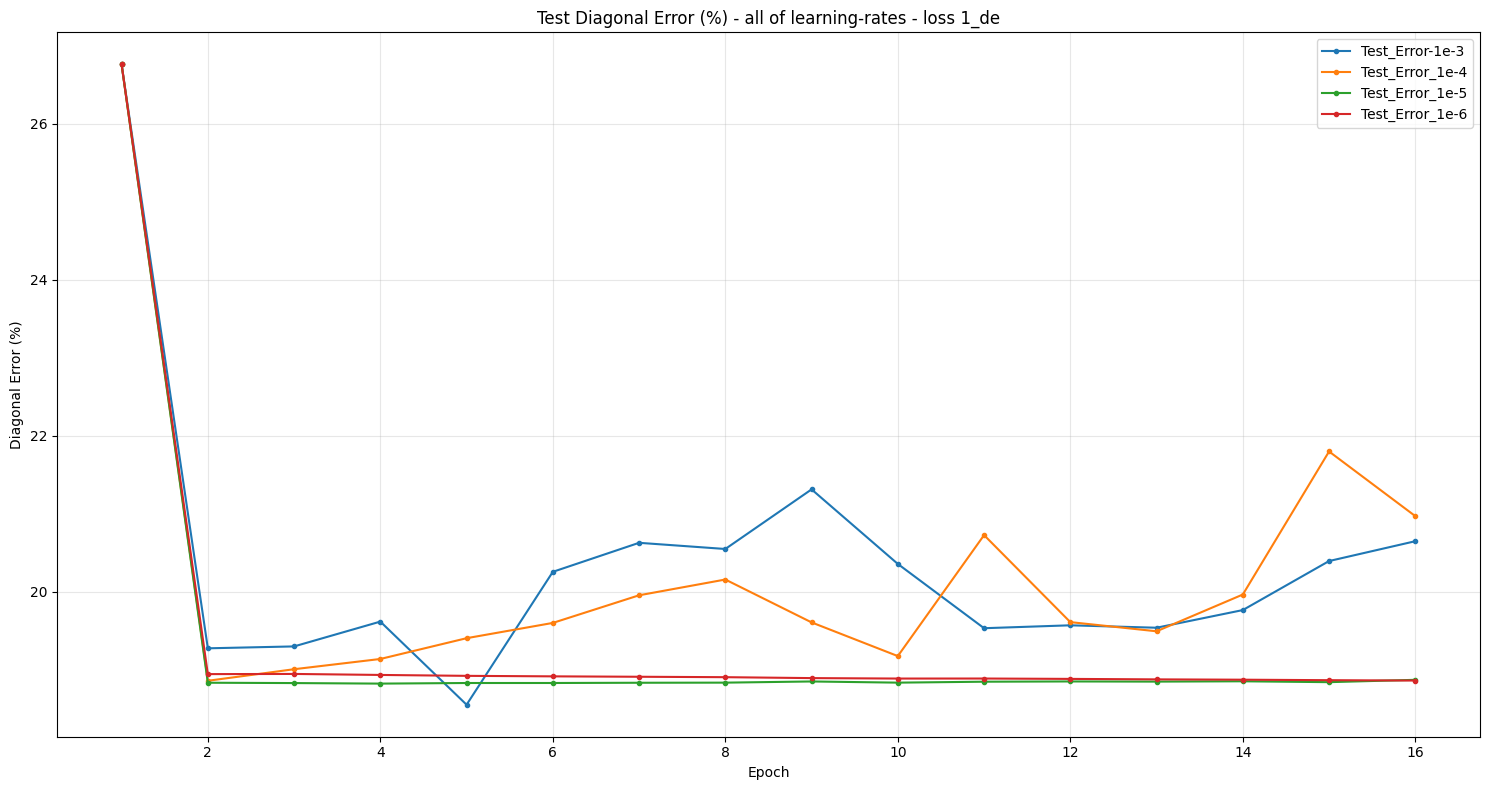

In [ ]:
if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70



# ============================================================
# Plot Test- vs. Train-Diagonal-Errors curves
# ============================================================

plt.figure(figsize=(15, 8))

# test_errors = norm_results["test_errors"]
# train_errors = norm_results["train_errors"]

test_error3  = de_learn_rate_loss1["test_error3"]
train_error3 = de_learn_rate_loss1["train_error3"]

test_error4  = de_learn_rate_loss1["test_error4"]
train_error4 = de_learn_rate_loss1["train_error4"]

test_error5  = de_learn_rate_loss1["test_error5"]
train_error5 = de_learn_rate_loss1["train_error5"]

test_error6  = de_learn_rate_loss1["test_error6"]
train_error6 = de_learn_rate_loss1["train_error6"]

# Epochs start at 1 because Epoch 0 was not stored in the lists
# epochs_axis = range(1, len(test_errors) + 1)
epochs_axis = range(1, len(test_error3) + 1)

# plt.plot(
#     epochs_axis,
#     test_errors,
#     linestyle="-",
#     marker="o",
#     markersize=3,
#     label="Test Error"
# )

# plt.plot(
#     epochs_axis,
#     train_errors,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train Error"
# )

#############################################################
"""
# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)
"""
#############################################################

plt.plot(
    epochs_axis,
    test_error3,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error-1e-3"
)

# plt.plot(
#     epochs_axis,
#     train_error3,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-3"
# )

######################

plt.plot(
    epochs_axis,
    test_error4,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-4"
)

# plt.plot(
#     epochs_axis,
#     train_error4,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-4"
# )

####################

plt.plot(
    epochs_axis,
    test_error5,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-5"
)

# plt.plot(
#     epochs_axis,
#     train_error5,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-5"
# )

###########################

plt.plot(
    epochs_axis,
    test_error6,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-6"
)

# plt.plot(
#     epochs_axis,
#     train_error6,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-6"
# )
#############################################################

plt.xlabel("Epoch")
plt.ylabel("Diagonal Error (%)")

plt.title(
    "Test Diagonal Error (%) - all of learning-rates - loss 1_de"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("./figures/learning-rates-l1-loss-de.png", dpi=300, bbox_inches="tight")

plt.show()

# loss 2 (diagonal_error):

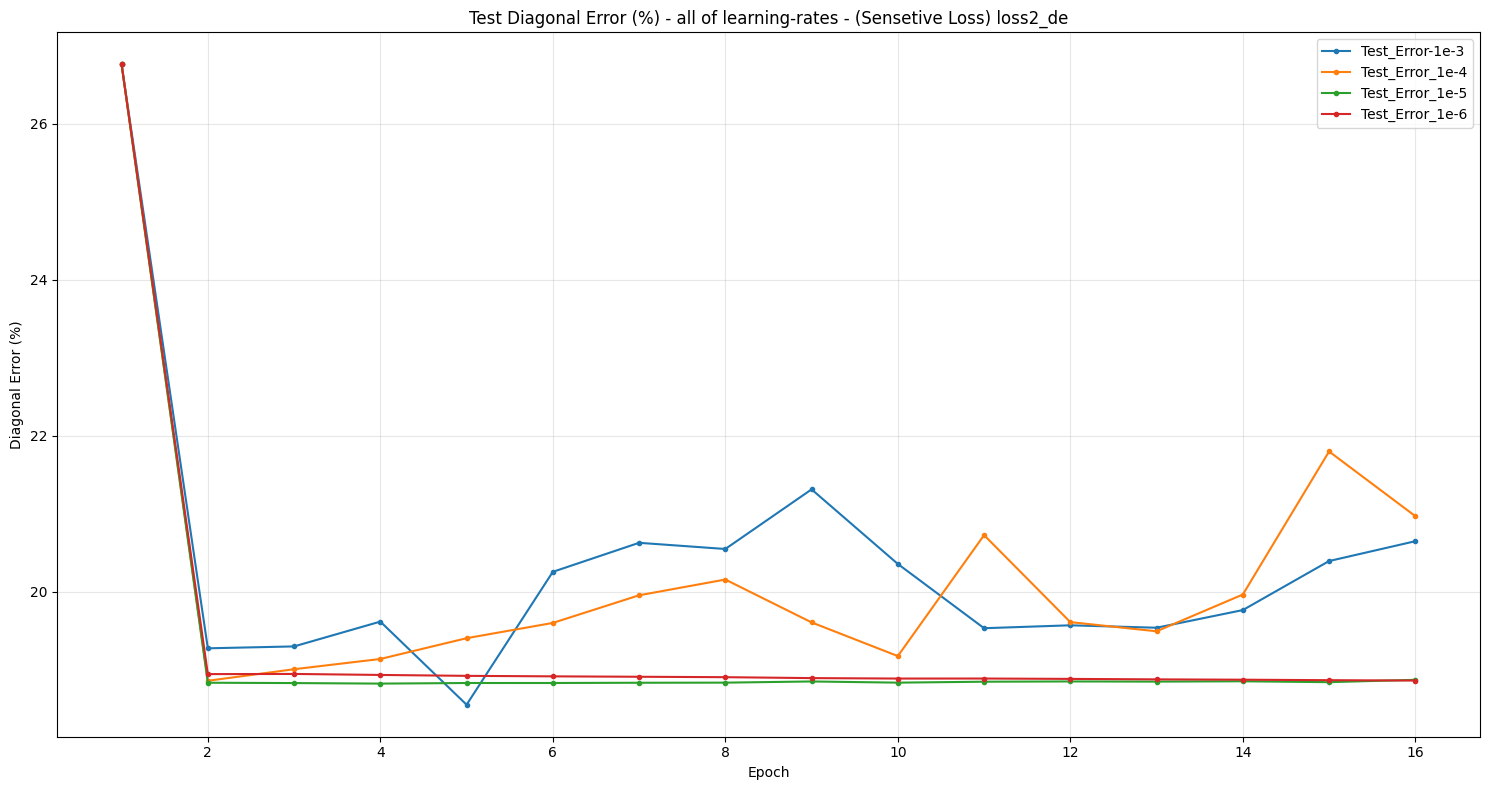

In [ ]:
if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70



# ============================================================
# Plot Test- vs. Train-Diagonal-Errors curves
# ============================================================

plt.figure(figsize=(15, 8))

# test_errors = norm_results["test_errors"]
# train_errors = norm_results["train_errors"]

test_error3  = de_learn_rate_loss2["test_error3"]
train_error3 = de_learn_rate_loss2["train_error3"]

test_error4  = de_learn_rate_loss2["test_error4"]
train_error4 = de_learn_rate_loss2["train_error4"]

test_error5  = de_learn_rate_loss2["test_error5"]
train_error5 = de_learn_rate_loss2["train_error5"]

test_error6  = de_learn_rate_loss2["test_error6"]
train_error6 = de_learn_rate_loss2["train_error6"]

# Epochs start at 1 because Epoch 0 was not stored in the lists
# epochs_axis = range(1, len(test_errors) + 1)
epochs_axis = range(1, len(test_error3) + 1)

# plt.plot(
#     epochs_axis,
#     test_errors,
#     linestyle="-",
#     marker="o",
#     markersize=3,
#     label="Test Error"
# )

# plt.plot(
#     epochs_axis,
#     train_errors,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train Error"
# )

#############################################################
"""
# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)
"""
#############################################################

plt.plot(
    epochs_axis,
    test_error3,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error-1e-3"
)

# plt.plot(
#     epochs_axis,
#     train_error3,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-3"
# )

######################

plt.plot(
    epochs_axis,
    test_error4,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-4"
)

# plt.plot(
#     epochs_axis,
#     train_error4,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-4"
# )

####################

plt.plot(
    epochs_axis,
    test_error5,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-5"
)

# plt.plot(
#     epochs_axis,
#     train_error5,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-5"
# )

###########################

plt.plot(
    epochs_axis,
    test_error6,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-6"
)

# plt.plot(
#     epochs_axis,
#     train_error6,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-6"
# )
#############################################################

plt.xlabel("Epoch")
plt.ylabel("Diagonal Error (%)")

plt.title(
    "Test Diagonal Error (%) - all of learning-rates - (Sensetive Loss) loss2_de"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("./figures/learning-rates-sensetive-loss(loss2)-de.png", dpi=300, bbox_inches="tight")

plt.show()

# loss 1

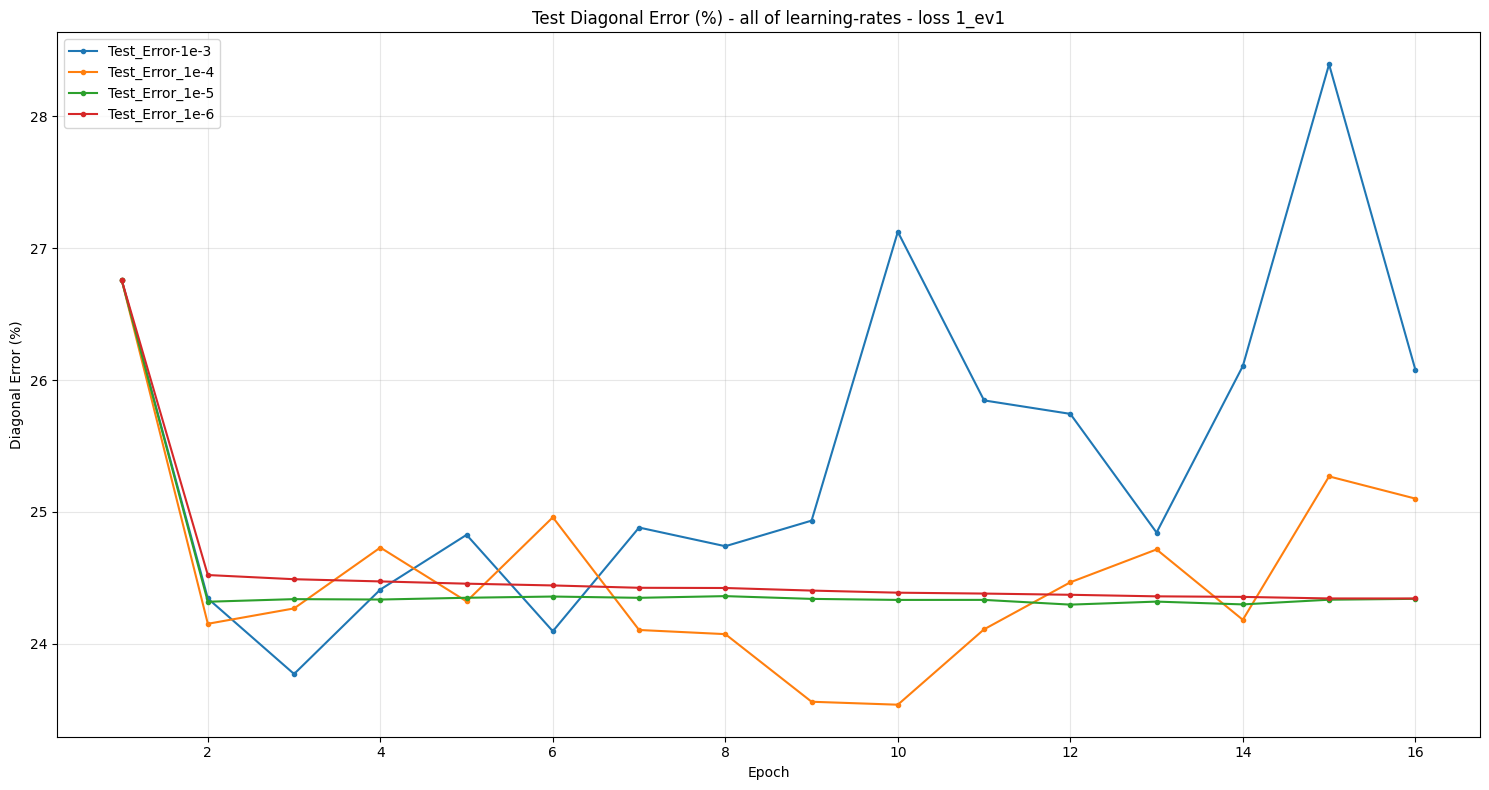

In [ ]:
if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70



# ============================================================
# Plot Test- vs. Train-Diagonal-Errors curves
# ============================================================

plt.figure(figsize=(15, 8))

# test_errors = norm_results["test_errors"]
# train_errors = norm_results["train_errors"]

test_error3  = ev_learn_rate_loss1["test_error3"]
train_error3 = ev_learn_rate_loss1["train_error3"]

test_error4  = ev_learn_rate_loss1["test_error4"]
train_error4 = ev_learn_rate_loss1["train_error4"]

test_error5  = ev_learn_rate_loss1["test_error5"]
train_error5 = ev_learn_rate_loss1["train_error5"]

test_error6  = ev_learn_rate_loss1["test_error6"]
train_error6 = ev_learn_rate_loss1["train_error6"]

# Epochs start at 1 because Epoch 0 was not stored in the lists
# epochs_axis = range(1, len(test_errors) + 1)
epochs_axis = range(1, len(test_error3) + 1)

# plt.plot(
#     epochs_axis,
#     test_errors,
#     linestyle="-",
#     marker="o",
#     markersize=3,
#     label="Test Error"
# )

# plt.plot(
#     epochs_axis,
#     train_errors,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train Error"
# )

#############################################################
"""
# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)
"""
#############################################################

plt.plot(
    epochs_axis,
    test_error3,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error-1e-3"
)

# plt.plot(
#     epochs_axis,
#     train_error3,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-3"
# )

######################

plt.plot(
    epochs_axis,
    test_error4,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-4"
)

# plt.plot(
#     epochs_axis,
#     train_error4,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-4"
# )

####################

plt.plot(
    epochs_axis,
    test_error5,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-5"
)

# plt.plot(
#     epochs_axis,
#     train_error5,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-5"
# )

###########################

plt.plot(
    epochs_axis,
    test_error6,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-6"
)

# plt.plot(
#     epochs_axis,
#     train_error6,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-6"
# )
#############################################################

plt.xlabel("Epoch")
plt.ylabel("Diagonal Error (%)")

plt.title(
    "Test Diagonal Error (%) - all of learning-rates - loss 1_ev1"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig("./figures/learning-rates-l1-loss-ev1.png", dpi=300, bbox_inches="tight")

plt.show()

# Loss 2:

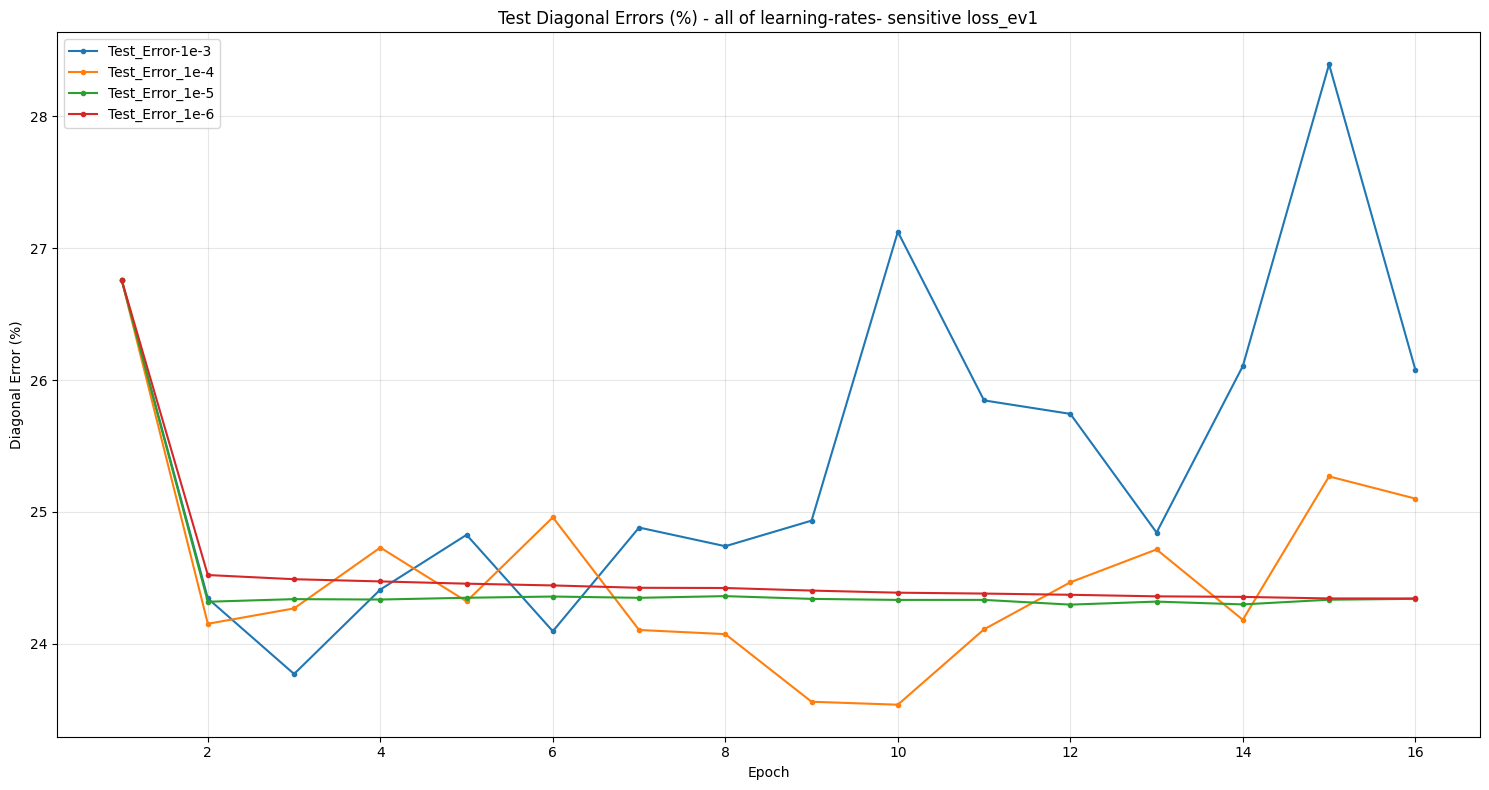

In [ ]:
if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70



# ============================================================
# Plot Test- vs. Train-Diagonal-Errors curves
# ============================================================

plt.figure(figsize=(15, 8))

# test_errors = norm_results["test_errors"]
# train_errors = norm_results["train_errors"]

test_error3  = ev_learn_rate_loss2["test_error3"]
train_error3 = ev_learn_rate_loss2["train_error3"]

test_error4  = ev_learn_rate_loss2["test_error4"]
train_error4 = ev_learn_rate_loss2["train_error4"]

test_error5  = ev_learn_rate_loss2["test_error5"]
train_error5 = ev_learn_rate_loss2["train_error5"]

test_error6  = ev_learn_rate_loss2["test_error6"]
train_error6 = ev_learn_rate_loss2["train_error6"]

# Epochs start at 1 because Epoch 0 was not stored in the lists
# epochs_axis = range(1, len(test_errors) + 1)
epochs_axis = range(1, len(test_error3) + 1)

# plt.plot(
#     epochs_axis,
#     test_errors,
#     linestyle="-",
#     marker="o",
#     markersize=3,
#     label="Test Error"
# )

# plt.plot(
#     epochs_axis,
#     train_errors,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train Error"
# )

#############################################################
"""
# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)
"""
#############################################################

plt.plot(
    epochs_axis,
    test_error3,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error-1e-3"
)

# plt.plot(
#     epochs_axis,
#     train_error3,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-3"
# )

######################

plt.plot(
    epochs_axis,
    test_error4,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-4"
)

# plt.plot(
#     epochs_axis,
#     train_error4,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-4"
# )

####################

plt.plot(
    epochs_axis,
    test_error5,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-5"
)

# plt.plot(
#     epochs_axis,
#     train_error5,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-5"
# )

###########################

plt.plot(
    epochs_axis,
    test_error6,
    linestyle="-",
    marker="o",
    markersize=3,
    label="Test_Error_1e-6"
)

# plt.plot(
#     epochs_axis,
#     train_error6,
#     linestyle="--",
#     marker="",
#     markersize=3,
#     label="Train_Error_1e-6"
# )
#############################################################

plt.xlabel("Epoch")
plt.ylabel("Diagonal Error (%)")

plt.title(
    "Test Diagonal Errors (%) - all of learning-rates- sensitive loss_ev1"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./figures/learning-rates-sensitive-loss-ev1.png", dpi=300, bbox_inches="tight")
plt.show()

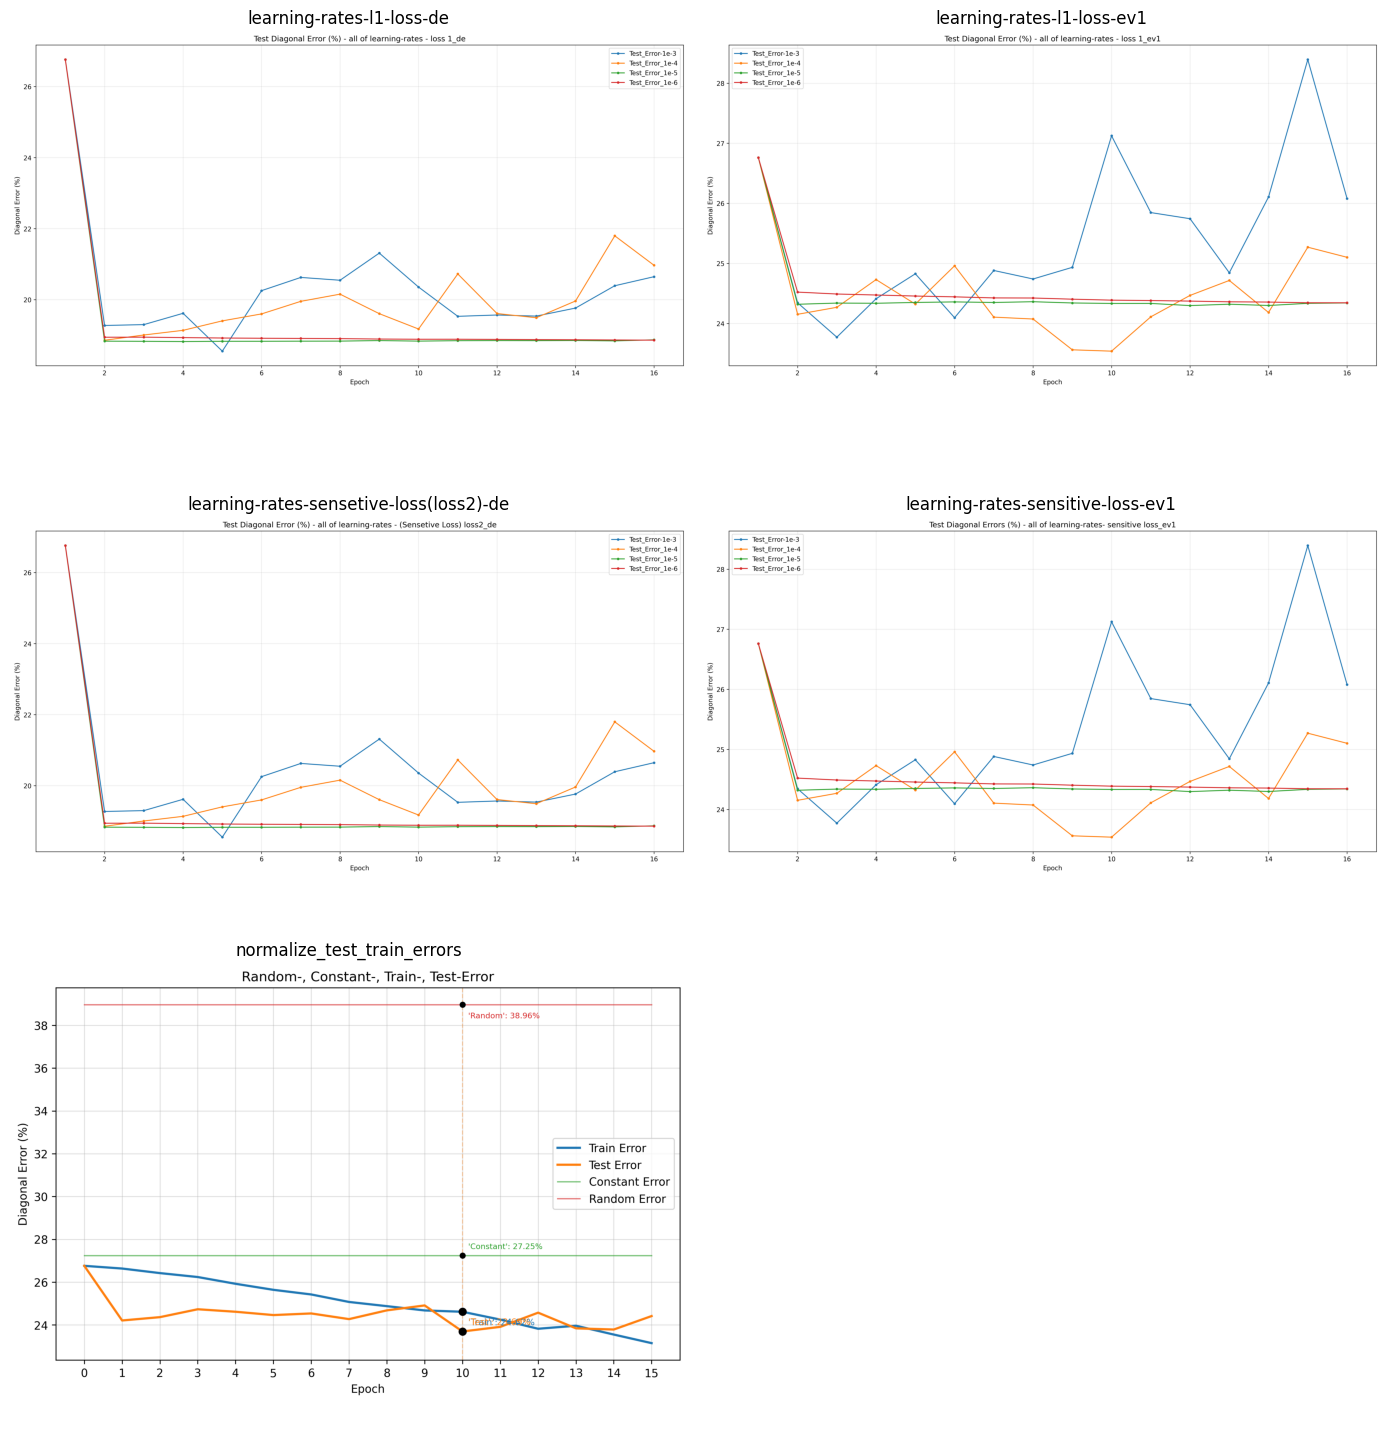

Gespeichert unter: figures/alle_diagramme.png


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import math

# Ordner mit den Diagrammen
INPUT_DIR = Path("./figures/")

# Unterstützte Bildformate
extensions = ["*.png", "*.jpg"]

files = sorted(
    file
    for pattern in extensions
    for file in INPUT_DIR.glob(pattern)
)

if not files:
    raise FileNotFoundError(f"Keine Diagramme gefunden in: {INPUT_DIR}")

# Anzahl der Spalten
cols = 2
rows = math.ceil(len(files) / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(14, 5 * rows),
    squeeze=False
)

for ax, file in zip(axes.flat, files):
    image = mpimg.imread(file)
    ax.imshow(image)
    ax.set_title(file.stem)
    ax.axis("off")

# Nicht verwendete Achsen ausblenden
for ax in axes.flat[len(files):]:
    ax.axis("off")

plt.tight_layout()

# Gesamtabbildung speichern
output_file = INPUT_DIR / "alle_diagramme.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gespeichert unter: {output_file}")

---
# 2. Archiv: `notebook_model_train.ipynb`
Rohdaten vs. Normalisierung, Baselines, Aktivierungs-Experimente, Visualisierung (Original). Zellen: 51 (ohne leere).

# Differenz between row-Data and Normalize-Data:

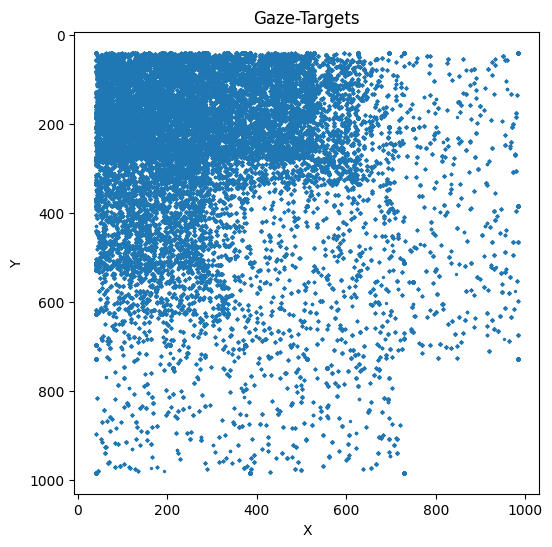



X_min: 0.0390625	 X_max: 1.0
Y_min: 0.0390625	 Y_max: 1.0 




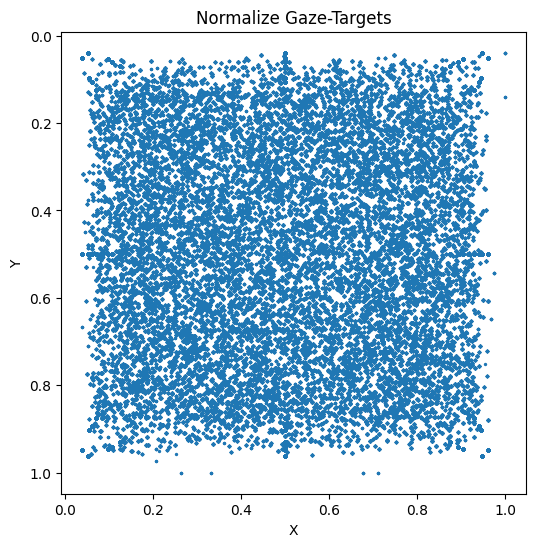

In [ ]:
# PLOT:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



labels_file = "./dataset/labels.csv"

df = pd.read_csv(labels_file)

# print(df.head())
# print("Anzahl Samples:", len(df))

x = df["x"]
y = df["y"]

# print(f"X_min: {np.min(x)}\t X_max: {np.max(x)}")
# print(f"Y_min: {np.min(y)}\t Y_max: {np.max(y)}")

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Gaze-Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()





# Normalize:

norm_labels_file = './dataset/norm_labels.csv'

df2 = pd.read_csv(norm_labels_file)

x = df2["x"]
y = df2["y"]

print(f"\n\nX_min: {np.min(x)}\t X_max: {np.max(x)}")
print(f"Y_min: {np.min(y)}\t Y_max: {np.max(y)} \n\n")
"""
df = pd.read_csv("./dataset/norm_labels.csv")

errors = df[(df["x_norm"] > 1) | (df["y_norm"] > 1)]

print(errors)
"""

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Normalize Gaze-Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()

# Baseline (Random and Constant):

In [ ]:
# Normalization: 

# -------------------------------------------------------------------
# ---------------------- Konstant_Error: -------------------------------
# -------------------------------------------------------------------

print("\nNormalization: \n")
norm_labels_file = './dataset/norm_labels.csv'
# norm_labels_file = './dataset/labels.csv'
df2 = pd.read_csv(norm_labels_file)



x_true = df2["x"].values
y_true = df2["y"].values

x_const = np.mean(x_true)
y_const = np.mean(y_true)

# x_const = 0.5
# y_const = 0.5

print(f"x_const: {x_const:.6f}")
print(f"y_const: {y_const:.6f}")

pred_x_const = np.full_like(x_true, x_const)
pred_y_const = np.full_like(y_true, y_const)

const_errors = np.sqrt(
    (x_true - pred_x_const) ** 2 +
    (y_true - pred_y_const) ** 2
)


mae = np.mean(const_errors)
rmse = np.sqrt(np.mean(const_errors ** 2))
const_error_pct = 100 * np.round(rmse, 5)
const_diagonal_error_pct = np.round(100 * rmse / np.sqrt(2), 5)

print("\nKonstant Baseline:\n")
print(f"Constant_Mean_Absolute_Error: {mae:.5f}")
print(f"Constant_Mean_Squared_Error: {rmse:.5f}")
# print(f"Constant_Mean_Squared_Error %: {const_error_pct} %")
print(f"Constant_Diagonal-Error %: {const_diagonal_error_pct} %")


# -------------------------------------------------------------------
# ---------------------- Random-Error -------------------------------
# -------------------------------------------------------------------

x = df2["x"]
y = df2["y"]
x_max = np.max(x)
x_min = np.min(x)
y_max = np.max(y)
y_min = np.min(y)

# x_max = 1.0
# y_max = 1.0


pred_x_random = np.random.uniform(x_min, x_max, len(x_true))
pred_y_random = np.random.uniform(y_min, y_max, len(y_true))

random_errors = np.sqrt(
    (x_true - pred_x_random)**2 +
    (y_true - pred_y_random)**2
)

mae = np.mean(random_errors)
rmse = np.sqrt(np.mean(random_errors ** 2))
random_error_pct = 100 * np.round(rmse, 5)
random_diagonal_error_pct = np.round(100 * rmse / np.sqrt(2), 5)

print("\nRandom Baseline:\n")
print(f"Random_Mean_Absolute_Error: {mae:.5f}")
print(f"Random_Mean_Squared_Error: {rmse:.5f}")
# print(f"Random_Mean_Squared_Error %: {random_error_pct} %")
print(f"Random_Diagonal-Error %: {random_diagonal_error_pct} % \n\n")


if globals().get("bas_const_err") is None:
    bas_const_err = const_diagonal_error_pct

if globals().get("bas_rand_err") is None:
    bas_rand_err = random_diagonal_error_pct

# print(f"\n\n bas_rand_error: {bas_const_err}\n bas_const_error: {bas_rand_err}")



Normalization: 

x_const: 0.501827
y_const: 0.500480

Konstant Baseline:

Constant_Mean_Absolute_Error: 0.35649
Constant_Mean_Squared_Error: 0.38530
Constant_Diagonal-Error %: 27.2447 %

Random Baseline:

Random_Mean_Absolute_Error: 0.49612
Random_Mean_Squared_Error: 0.54997
Random_Diagonal-Error %: 38.88893 % 




In [ ]:
# 1: Bib

import time
start_time = time.perf_counter()

import os
import re
import json
import csv
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)
from datetime import datetime

from torch.utils.tensorboard import SummaryWriter



In [ ]:

# 2: Dataset Class: transfer CSV in PyTorch.
class GazeDataset(Dataset):

    def __init__(self, csv_file, transform=None, dataset_size=None, read_all4once=True):

        self.df = pd.read_csv(csv_file)
        self.transform = transform
        self.dataset_size = dataset_size if dataset_size is not None else len(self.df)
        self.read_all4once = read_all4once

        if self.read_all4once:
            img = Image.new("RGB", (500, 300))  # any size
            out = transform(img)
            self.images = torch.zeros([self.dataset_size] + list(out.shape))
            self.targets = torch.zeros(self.dataset_size, 2)

        for idx in tqdm(range(self.dataset_size)):

            row = self.df.iloc[idx]

            image = Image.open(
                row["image_name"]
            ).convert("RGB")

            self.targets[idx] = torch.tensor(
                [row["x"], row["y"]],
                dtype=torch.float32
            )

            if self.transform:
                self.images[idx] = self.transform(image)
            else:
                self.images[idx] = image

    def __len__(self):

        return self.dataset_size

    def __getitem__(self, idx):

        return self.images[idx], self.targets[idx]

In [ ]:

# 5: func-Diagonal-Error:
def diagonal_errors(model, loader, device):
    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    
    mae = mean_absolute_error(targets, predictions)
    
    rmse = np.sqrt(mean_squared_error(targets, predictions))

    diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:
def evaluate_model(model, loader, device):

    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    
    # mae = mean_absolute_error(targets, predictions)
    
    # rmse = np.sqrt(mean_squared_error(targets, predictions))

    # diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    # print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    # print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    # return mae, rmse, diagonal_error_pct, targets, predictions, errors
    return targets, predictions, errors

In [ ]:
class GaussianActivation(nn.Module):

    def __init__(self, sigma=1.0):
        super().__init__()
        self.sigma = sigma

    def forward(self, x):
        return torch.exp(
            -(x ** 2) / (2 * self.sigma ** 2)
        )

In [ ]:
def sensitive_loss(preds, targets):

    x_total = 0.0

    for i in range(len(targets)):

        x = criterion_base(preds[i], targets[i])

        distance_from_center = (
            torch.abs(targets[i][0] - 0.5) +
            torch.abs(targets[i][1] - 0.5)
        )

        weight = 1.0 + distance_from_center

        x_total += x * weight

    return x_total / len(targets)

In [ ]:
# Hypoparameter:

name_dataset_type = ['norm_labels.csv', 'labels.csv']
dataset_size_type = [[10000, 2000], [1000, 200]]
dataset_type = ["norm_subject", "norm_random"]
batch_size_type = [32, 64, 128]
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
epochs_num = [1, 2, 10, 25, 500]



optimizer_name = "AdamW"

# ##########################################################################
# 1.type Dataset: 'norm_labels.csv' or 'labels.csv'
dataset_name = name_dataset_type[0]
print(f"\n dataset_name: \t {dataset_name}")

# 2.dataset_sizt: (10000 & 2000) or (1000, 200)
def_dataset_size = dataset_size_type[1]
print(f"\n def_dataset_size: train: {def_dataset_size[0]}, \t test: {def_dataset_size[1]}")

# 3.batch_size: '32', '64' or '128'
batch_Size = batch_size_type[1]
print(f"\n batch_Size: \t {batch_Size}")

# 4.type of dataset-split: "norm_subject_independed" or "norm_random"
def_dataset = dataset_type[0]
print(f"\n def_dataset: \t {def_dataset}")

# 5.learning_rate: '1e-3', '1e-4', '1e-5' or '1e-6'
learning_rate = lr_type[2]
print(f"\n learning_rate: \t {learning_rate}")

# 6.number of epochs: 1, 2, 10, 25 or 500
epochs = epochs_num[-1]
print(f"\n epochs: \t {epochs}")




weight_Decay = 1e-5

active_func = None

patience = 3               # after 3 Epochen without Optimierung has to stop training
print(f"\n patience: \t {patience}")


In [ ]:
# 6: CSV laden
root_folder = "./dataset"
csv_path = Path(f"{root_folder}/{dataset_name}")
# print(f"\n csv_path: {csv_path}")

df = pd.read_csv(csv_path)
df.head()
# check:
# print(df.shape)

,image_name,x,y,subject_ID,screen_w,screen_h
0,dataset/images/00002/00002/frames/00000.jpg,0.500000,0.500000,2,320,568
1,dataset/images/00002/00002/frames/00001.jpg,0.500000,0.500000,2,320,568
2,dataset/images/00002/00002/frames/00002.jpg,0.500000,0.500000,2,320,568
3,dataset/images/00002/00002/frames/00003.jpg,0.500000,0.500000,2,320,568
4,dataset/images/00002/00002/frames/00004.jpg,0.873929,0.114375,2,320,568


In [ ]:
# 7: check a image
# row = df.iloc[0]
# img = Image.open(row["image_name"])
# plt.imshow(img)
# plt.show()
# print(row["x"], row["y"])

In [ ]:
# 8: DataLoader
# Transformationen:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomGrayscale(p=0.05),

    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1,1.5)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Dataset:


if def_dataset == 'norm_subject':

    train_dataset = GazeDataset(
        "./splits/norm_subject_train.csv",
        transform, dataset_size=def_dataset_size[0],
    )
    
    test_dataset = GazeDataset(
        "./splits/norm_subject_test.csv",
        transform, dataset_size=def_dataset_size[1],
    )



elif def_dataset == 'norm_random':

    train_dataset = GazeDataset(
        "./splits/norm_random_train.csv",
        transform, dataset_size=def_dataset_size[0],
    )
    
    test_dataset = GazeDataset(
        "./splits/norm_random_test.csv",
        transform, dataset_size=def_dataset_size[1],
    )

else:

    raise ValueError(
                "The input as dataset_type is Wrong!"
            )


# Loader:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_Size,
    shuffle=True,
    num_workers=8,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_Size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:02<00:00, 96.46it/s]


In [ ]:
## Test:
# datasets_file = ["./dataset/labels.csv", "./dataset/norm_labels.csv"]
# d = datasets_file[0]
# print(f"{d}:")
# df = pd.read_csv(d)
# print(df[["x", "y"]].describe())

# d = datasets_file[1]
# print(f"{d}:")
# df = pd.read_csv(d)
# print(df[["x", "y"]].describe())



# print(f" len(train_dataset): {len(train_dataset)}")
# print(f" len(test_dataset):  {len(test_dataset)}")



In [ ]:
# 9: ResNet18 (Pretrainiertes Modell):
# Load:
def reset_model(act=None):
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    model_name = model.__class__.__name__
    
    # ---------------------------------------
    # Activation function for the last layer
    # ---------------------------------------
    if act == "Sigmoid":
        last_layer = nn.Sigmoid()

    elif act == "Gaussian":
        last_layer = GaussianActivation(sigma=1.0)

    elif act == "ReLU":
        last_layer = nn.ReLU()

    elif act == "None":
        last_layer = nn.Identity()

    else:
        raise ValueError(
            f"Unknown activation function: {act}"
        )

    # ---------------------------------------
    # Replace original ResNet FC
    # ---------------------------------------
    model.fc = nn.Sequential(
        nn.Linear(
            model.fc.in_features,
            512
        ),
        nn.ReLU(),

        nn.Linear(
            512,
            256
        ),
        nn.ReLU(),

        nn.Dropout(0.2),

        nn.Linear(
            256,
            128
        ),
        nn.ReLU(),

        nn.Linear(
            128,
            2
        ),

        # Last activation
        last_layer
    )

    return model, model_name


In [ ]:
# 10: GPU
# check:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

# print(device)


In [ ]:

criterion = nn.L1Loss()

criterion_base = nn.L1Loss()

epochs = epochs
# epochs = 2

if globals().get("bas_const_err") is None:
    bas_const_err = 27.245

if globals().get("bas_rand_err") is None:
    bas_rand_err = 38.961
    

model_output = './models'
model_dir= Path(model_output)

if not os.path.exists(model_dir):
    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

diag_test_errors = {}
diag_train_errors = {}

# act_time = {}
# act_epoch = {}
# act_time = {
#     "Sigmoid": [],
#     "Gaussian": [],
#     "ReLU": [],
#     "None": []
# }

# act_epoch = {
#     "Sigmoid": [],
#     "Gaussian": [],
#     "ReLU": [],
#     "None": []
# }

act_time_epochs = {}


diag_test_error, diag_train_error = [], []




writer = SummaryWriter(
        log_dir=os.path.join("runs", f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_"
                                     f"{def_dataset}_{def_dataset_size[0]}-{def_dataset_size[1]}")
    )


for act in ['Sigmoid']:
# for act in ['Sigmoid', 'Gaussian', 'ReLU', 'None']:

    train_start = time.perf_counter()

    act_time = {f"{act}": [] }

    act_epoch = {f"{act}": [] }
    
    model, model_name = reset_model(act=act)

    last_act_func = act
    
    active_func = act

    diag_test_errors[act] = []
    diag_train_errors[act] = []

    best_error = float("inf")

    t = 0                      # Number Epochen without Optimierung
    e = 0                      # Number Epochen with Optimierung


    model.to(device)



    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze the head
    for param in model.layer4.parameters():
        param.requires_grad=True

    for param in model.fc.parameters():
        param.requires_grad=True


    optimizer = torch.optim.AdamW(
        filter(lambda p:p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=weight_Decay
    )

    print('\n ',"=#=" * 25)
    print(f"\t\t act: {act}")
    print(' ',"=#=" * 25)

    print("\n\t Start: \n")
    
    print("train_error:")
    train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
    diag_train_error.append(np.round(train_diag_pct, 4))
    
    diag_train_errors[act].append(np.round(train_diag_pct, 4))

    


    print("\ntest_error:")
    test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
    diag_test_error.append(np.round(test_diag_pct, 4))

    diag_test_errors[act].append(np.round(test_diag_pct, 4))


    writer.add_scalars(
        main_tag="Diagnostic Error",
        tag_scalar_dict={
            "Train": f"{train_diag_pct:.4f}",
            "Test": f"{test_diag_pct:.4f}",
            "Constant": bas_const_err,
            "Random": bas_rand_err
        },
        global_step = 0
    )
    writer.flush()


    print("\n\n\t Training: \n")

    for epoch in range(epochs):

        epoch_start = time.perf_counter()

        model.train()
        running_loss = 0

        loop = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}"
        )

        for images, targets in loop:
            images = images.to(device)
            targets = targets.to(device)
            optimizer.zero_grad()
            preds = model(images)

            ################################
            
            # Loss 1:
            # loss = criterion(
            #     preds,
            #     targets
            # )

            
            # Loss 2: 
            loss = sensitive_loss(
                preds,
                targets
            )
            
            ################################

            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            loop.set_postfix(
                loss=loss.item()
            )

        # epoch_end = time.perf_counter()

        print(f"\ntrain_error:")
        train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
        diag_train_error.append(np.round(train_diag_pct, 4))

        diag_train_errors[last_act_func].append(np.round(train_diag_pct, 4))

        print(f"\ntest_error:")
        test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
        diag_test_error.append(np.round(test_diag_pct, 4))

        diag_test_errors[last_act_func].append(np.round(test_diag_pct, 4))

        # writer.add_scalar("train_error/epoch", float(f"{train_diag_pct:.4f}"), epoch + 1)
        # writer.add_scalar("test_error/epoch", float(f"{test_diag_pct:.4f}"), epoch + 1)
        # writer.add_scalar("train_loss/epoch", running_loss / len(train_loader), epoch + 1)
        writer.add_scalars(
            main_tag="Diagnostic Error",
            tag_scalar_dict={
                "Train": f"{train_diag_pct:.4f}",
                "Test": f"{test_diag_pct:.4f}",
                "Constant": bas_const_err,
                "Random": bas_rand_err
            },
            global_step=epoch + 1
        )
        writer.flush()

        # --------------------------------------------------
        # Early Stopping
        # --------------------------------------------------
        
        if best_error is None or test_diag_pct < best_error:
        
            # find an improvement
            best_error = test_diag_pct
            t = 0
            e += 1
        
            print(
                f"Test-Diagonal-Error: {test_diag_pct:.4f}% | "
                f"Improvment: {e}"
            )
        
            # save the better Modell
            # torch.save(
            #     model.state_dict(),
            #     f"./models/best_optim-model_"
            #     f"{def_dataset}_{def_dataset_size[0]}-{def_dataset_size[1]}.path"
            # )

            torch.save(
                model.state_dict(),
                f"./models/best-model_"
                f"{model_name}_{act}.path"
            )
        
        else:
        
            # without imporovement
            t += 1
        
            print(
                f"Patience: {t}/{patience}"
            )
        
            if t >= patience:
                print(
                    f"\nEarly Stopping after {epoch + 1} Epochen."
                )
                print(
                    f"Imporovments totally: {e}"
                )
                break



        epoch_end = time.perf_counter()


        print(
            f"\n[{datetime.now().strftime('%H:%M:%S')}] Epoch {epoch + 1}: {epoch_end - epoch_start:.2f} Sekunden | "
            f"Running_loss: {running_loss / len(train_loader):.3f} | "
            f"test_diag_error={test_diag_pct:.4f}% | "
            f"train_diag_error={train_diag_pct:.4f}% | \n"
        )

        # torch.save(model.state_dict(),
        #         f"./models/last_best_optim_model_{def_dataset}_{def_dataset_size[0]}-{def_dataset_size[1]}.path")

        torch.save(
                model.state_dict(),
                f"./models/last-model_"
                f"{model_name}_{act}.path"
            )


    train_end = time.perf_counter()

    writer.add_hparams(
        {
            "dataset": def_dataset,
            "dataset_size": str(def_dataset_size),
            "optimizer": optimizer_name,
            "learning_rate": float(learning_rate),
            "weight_decay": float(weight_Decay),
            "batch_size": batch_Size,
            "epochs": epochs
        },
        {
            "hparam/test_diag_error": float(diag_test_error[-1]),
            "hparam/train_diag_error": float(diag_train_error[-1]),
            "hparam/train_running_time_min": float((train_end - train_start) / 60)
        }
    )

    writer.add_text(
        tag=f"Train-Error & Test-Error for {epochs} Epochs",
        text_string=f"Train-Error: {np.float64(diag_train_error)}\n"
                    f"Test-Error: {np.float64(diag_test_error)}",
        global_step=0
    )

    writer.flush()


    elapsed_running_time = train_end - train_start
    print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
    print(f"totll running-tiems (min): {elapsed_running_time / 60:.2f} Minuten\n")

    
    act_time[act].append(elapsed_running_time)
    act_epoch[act].append(e)

    act_time_epochs[act] = {
        "time_minutes": elapsed_running_time / 60,
        "epochs": epoch + 1,
        "improvements": e,
        "best_test_error": best_error
    }



    # print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
    # print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")



  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
		 act: Sigmoid
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Start: 

train_error:
MAE : 0.2317 	 RMSE: 0.2801 
Diagonal-Error %: 19.8091 %

test_error:
MAE : 0.2381 	 RMSE: 0.2858 
Diagonal-Error %: 20.2071 %


	 Training: 



Epoch 1: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:00<00:00,  3.79s/it, loss=0.39]



train_error:
MAE : 0.2303 	 RMSE: 0.2787 
Diagonal-Error %: 19.7062 %

test_error:
MAE : 0.2380 	 RMSE: 0.2858 
Diagonal-Error %: 20.2069 %
Test-Diagonal-Error: 20.2069% | Improvment: 1

[15:41:20] Epoch 1: 113.33 Sekunden | Running_loss: 0.365 | test_diag_error=20.2069% | train_diag_error=19.7062% | 



Epoch 2: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:03<00:00,  3.97s/it, loss=0.366]



train_error:
MAE : 0.2286 	 RMSE: 0.2769 
Diagonal-Error %: 19.5782 %

test_error:
MAE : 0.2380 	 RMSE: 0.2857 
Diagonal-Error %: 20.1997 %
Test-Diagonal-Error: 20.1997% | Improvment: 2

[15:43:19] Epoch 2: 119.04 Sekunden | Running_loss: 0.361 | test_diag_error=20.1997% | train_diag_error=19.5782% | 



...


train_error:
MAE : 0.2273 	 RMSE: 0.2755 
Diagonal-Error %: 19.4812 %

test_error:
MAE : 0.2384 	 RMSE: 0.2859 
Diagonal-Error %: 20.2185 %
Patience: 1/3

[15:45:19] Epoch 3: 119.47 Sekunden | Running_loss: 0.360 | test_diag_error=20.2185% | train_diag_error=19.4812% | 



Epoch 4: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:06<00:00,  4.14s/it, loss=0.388]



train_error:
MAE : 0.2260 	 RMSE: 0.2742 
Diagonal-Error %: 19.3860 %

test_error:
MAE : 0.2387 	 RMSE: 0.2863 
Diagonal-Error %: 20.2434 %
Patience: 2/3

[15:47:20] Epoch 4: 121.43 Sekunden | Running_loss: 0.358 | test_diag_error=20.2434% | train_diag_error=19.3860% | 



Epoch 5: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:05<00:00,  4.10s/it, loss=0.366]



train_error:
MAE : 0.2246 	 RMSE: 0.2728 
Diagonal-Error %: 19.2909 %

test_error:
MAE : 0.2393 	 RMSE: 0.2867 
Diagonal-Error %: 20.2747 %
Patience: 3/3

Early Stopping after 5 Epochen.
Imporovments totally: 2

totll running-tiems (s): 649.05 Sekunden
totll running-tiems (min): 10.82 Minuten



In [ ]:
for t in range (5):

    print(f"t: {t}")
    
    epochs = 150
    # epochs = 2
    
    active_func = None
    
    patience = 3               # after 3 Epochen without Optimierung has to stop training
    
    
    #################################

    criterion = nn.L1Loss()
    
    criterion_base = nn.L1Loss()
    
    
    if globals().get("bas_const_err") is None:
        bas_const_err = 27.245
    
    if globals().get("bas_rand_err") is None:
        bas_rand_err = 38.961
        
    
    diag_test_errors = {}
    diag_train_errors = {}
    
    act_time_epochs = {}
    
    
    diag_test_error, diag_train_error = [], []
    
    
    
    
    for act in ['Sigmoid']:
    # for act in ['Sigmoid', 'Gaussian', 'ReLU', 'None']:
    
        train_start = time.perf_counter()
        
        model, model_name = reset_model(act=act)
    
        last_act_func = act
        
        active_func = act
    
        diag_test_errors[act] = []
        diag_train_errors[act] = []
    
        best_error = float("inf")
    
        t = 0                      # Number Epochen without Optimierung
        e = 0                      # Number Epochen with Optimierung
    
    
        model.to(device)
    
    
    
        for param in model.parameters():
            param.requires_grad = False
    
        # Unfreeze the head
        for param in model.layer4.parameters():
            param.requires_grad=True
    
        for param in model.fc.parameters():
            param.requires_grad=True
    
    
        optimizer = torch.optim.AdamW(
            filter(lambda p:p.requires_grad, model.parameters()),
            lr=learning_rate,
            weight_decay=weight_Decay
        )
    
        print('\n ',"=#=" * 25)
        print(f"\t\t act: {act}")
        print(' ',"=#=" * 25)
    
        print("\n\t Start: \n")
        
        print("train_error:")
        train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
        diag_train_error.append(np.round(train_diag_pct, 4))
        
        diag_train_errors[act].append(np.round(train_diag_pct, 4))
    
        
    
    
        print("\ntest_error:")
        test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
        diag_test_error.append(np.round(test_diag_pct, 4))
    
        diag_test_errors[act].append(np.round(test_diag_pct, 4))
    
    
    
    
        print("\n\n\t Training: \n")
    
        for epoch in range(epochs):
    
            epoch_start = time.perf_counter()
    
            model.train()
            running_loss = 0
    
            loop = tqdm(
                train_loader,
                desc=f"Epoch {epoch + 1}"
            )
    
            for images, targets in loop:
                images = images.to(device)
                targets = targets.to(device)
                optimizer.zero_grad()
                preds = model(images)
    
                ################################
                
                # # Loss 1:
                loss = criterion(
                    preds,
                    targets
                )
    
                
                # # Loss 2: 
                # loss = sensitive_loss(
                #     preds,
                #     targets
                # )
                
                ################################
    
                loss.backward()
                optimizer.step()
                running_loss += loss.item()
    
                loop.set_postfix(
                    loss=loss.item()
                )
    
            # epoch_end = time.perf_counter()
    
            print(f"\ntrain_error:")
            train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
            diag_train_error.append(np.round(train_diag_pct, 4))
    
            diag_train_errors[last_act_func].append(np.round(train_diag_pct, 4))
    
            print(f"\ntest_error:")
            test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
            diag_test_error.append(np.round(test_diag_pct, 4))
    
            diag_test_errors[last_act_func].append(np.round(test_diag_pct, 4))
    
    
            # --------------------------------------------------
            # Early Stopping
            # --------------------------------------------------
            
            if best_error is None or test_diag_pct < best_error:
            
                # find an improvement
                best_error = test_diag_pct
                t = 0
                e += 1
            
                print(
                    f"Test-Diagonal-Error: {test_diag_pct:.4f}% | "
                    f"Improvment: {e}"
                )
            
    
                torch.save(
                    model.state_dict(),
                    f"./models/best-model_"
                    f"{model_name}_{act}.path"
                )
            
            else:
            
                # without imporovement
                t += 1
            
                print(
                    f"Patience: {t}/{patience}"
                )
            
                if t >= patience:
                    print(
                        f"\nEarly Stopping after {epoch + 1} Epochen."
                    )
                    print(
                        f"Imporovments totally: {e}"
                    )
                    break
    
    
    
            epoch_end = time.perf_counter()
    
    
            print(
                f"\n[{datetime.now().strftime('%H:%M:%S')}] Epoch {epoch + 1}: {epoch_end - epoch_start:.2f} Sekunden | "
                f"Running_loss: {running_loss / len(train_loader):.3f} | "
                f"test_diag_error={test_diag_pct:.4f}% | "
                f"train_diag_error={train_diag_pct:.4f}% | \n"
            )
    
    
            torch.save(
                    model.state_dict(),
                    f"./models/last-model_"
                    f"{model_name}_{act}.path"
                )
    
    
        train_end = time.perf_counter()
    
    
        elapsed_running_time = train_end - train_start
        print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
        print(f"totll running-tiems (min): {elapsed_running_time / 60:.2f} Minuten\n")
    
        
        act_time[act].append(elapsed_running_time)
        act_epoch[act].append(e)
    
        act_time_epochs[act] = {
            "time_minutes": elapsed_running_time / 60,
            "epochs": epoch + 1,
            "improvements": e,
            "best_test_error": best_error
        }
    
    
    
        # print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
        # print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")
    
    for act, values in act_time_epochs.items():
        print(
            f"{act}: \t"
            f" epochs: {values['epochs']} Epochen \t| "
            f" running_time: {values['time_minutes']:.2f} min \t | "
            f" improvements: {values['improvements']} Epochen \t | "
            f" best_test_error: {values['best_test_error']:.4f} % "
        )


    # # ---------- Evaluation ----------

    # saved_model = "./models/best-model_ResNet_Sigmoid.path"
    
    # checkpoint = torch.load(
    #     saved_model,
    #     map_location=device
    # )
    
    # model.load_state_dict(checkpoint)
    
    # model.to(device)
    
    # model.eval()
    
    
    # print(f"Test:\n")
    # test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
    
    # print(
    #         f"test_diag_error={test_diag_pct:.4f}% "
    #     )
        


t: 0

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
		 act: Sigmoid
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Start: 

train_error:
MAE : 0.2322 	 RMSE: 0.2804 
Diagonal-Error %: 19.8244 %

test_error:
MAE : 0.2384 	 RMSE: 0.2863 
Diagonal-Error %: 20.2437 %


	 Training: 



Epoch 1: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:51<00:00,  3.24s/it, loss=0.207]



train_error:
MAE : 0.2302 	 RMSE: 0.2783 
Diagonal-Error %: 19.6812 %

test_error:
MAE : 0.2379 	 RMSE: 0.2858 
Diagonal-Error %: 20.2109 %
Test-Diagonal-Error: 20.2109% | Improvment: 1

[14:29:48] Epoch 1: 100.30 Sekunden | Running_loss: 0.231 | test_diag_error=20.2109% | train_diag_error=19.6812% | 



Epoch 2: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [00:51<00:00,  3.22s/it, loss=0.247]



train_error:
MAE : 0.2284 	 RMSE: 0.2766 
Diagonal-Error %: 19.5599 %

test_error:
MAE : 0.2381 	 RMSE: 0.2860 
Diagonal-Error %: 20.2260 %
Patience: 1/3

[14:31:36] Epoch 2: 108.62 Sekunden | Running_loss: 0.230 | test_diag_error=20.2260% | train_diag_error=19.5599% | 



Epoch 3: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:38<00:00,  6.13s/it, loss=0.252]



train_error:
MAE : 0.2268 	 RMSE: 0.2751 
Diagonal-Error %: 19.4551 %

test_error:
MAE : 0.2389 	 RMSE: 0.2867 
Diagonal-Error %: 20.2704 %
Patience: 2/3

[14:34:15] Epoch 3: 158.10 Sekunden | Running_loss: 0.229 | test_diag_error=20.2704% | train_diag_error=19.4551% | 



Epoch 4: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 16/16 [01:12<00:00,  4.53s/it, loss=0.228]



train_error:
MAE : 0.2254 	 RMSE: 0.2738 
Diagonal-Error %: 19.3602 %

test_error:
MAE : 0.2398 	 RMSE: 0.2875 
Diagonal-Error %: 20.3310 %
Patience: 3/3

Early Stopping after 4 Epochen.
Imporovments totally: 1

totll running-tiems (s): 543.21 Sekunden
totll running-tiems (min): 9.05 Minuten



NameError: name 'act_time' is not defined

In [ ]:

# print(f"\n{act_time_epochs}\n\n")

for act, values in act_time_epochs.items():
    print(
        f"{act}: \t"
        f" epochs: {values['epochs']} Epochen \t| "
        f" running_time: {values['time_minutes']:.2f} min \t | "
        f" improvements: {values['improvements']} Epochen \t | "
        f" best_test_error: {values['best_test_error']:.4f} % "
    )


Sigmoid: 	 epochs: 4 Epochen 	|  running_time: 8.91 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 20.1787 % 


## Loss 1:

# loss 1 | Try 1:

# Compare all of 4 Possibility
Sigmoid: 	 epochs: 7  Epochen 	|  running_time: 12.92 min 	 |  improvements: 4 Epochen 	 |  best_test_error: 20.2166 % 

Gaussian: 	 epochs: 21 Epochen 	|  running_time: 43.98 min 	 |  improvements: 16 Epochen 	 |  best_test_error: 20.6069 % 

ReLU: 	     epochs: 8  Epochen 	|  running_time: 16.43 min 	 |  improvements: 5 Epochen 	 |  best_test_error: 20.5478 % 

None: 	     epochs: 7  Epochen 	|  running_time: 13.77 min 	 |  improvements: 4 Epochen 	 |  best_test_error: 20.8638 % 

# loss 1 | Try 2:

# Compare all of 4 Possibility
Sigmoid: 	 epochs: 5 Epochen 	    |  running_time: 10.01 min 	 |  improvements: 2 Epochen 	 |  best_test_error: 20.0907 % 

Gaussian: 	 epochs: 19 Epochen 	|  running_time: 35.94 min 	 |  improvements: 12 Epochen 	 |  best_test_error: 20.5031 % 

ReLU: 	     epochs: 8 Epochen 	    |  running_time: 15.63 min 	 |  improvements: 5 Epochen 	 |  best_test_error: 21.4912 % 

None: 	     epochs: 11 Epochen 	|  running_time: 22.14 min 	 |  improvements: 8 Epochen 	 |  best_test_error: 20.2487 % 


In [ ]:
# Sigmoid:
best_test_error1 = [20.2166, 20.0907]
run_time1 = [12.92, 10.01]

# Gaussian:
best_test_error2 = [20.6069, 20.5031]
run_time2 = [43.98, 35.94]

# ReLU:
best_test_error3 = [20.5478, 21.4912]
run_time3 = [16.43, 15.63]

# None:
best_test_error4 = [20.8638, 20.2487]
run_time4 = [13.77, 22.14]

# loss 2  | Try 1

# Compare all of 4 Possibility
Sigmoid: 	 epochs: 4 Epochen 	    |  running_time: 7.57 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 19.9974 % 

Gaussian: 	 epochs: 14 Epochen     |  running_time: 26.75 min 	 |  improvements: 11 Epochen 	 |  best_test_error: 20.6437 % 

ReLU: 	     epochs: 7 Epochen 	    |  running_time: 13.29 min 	 |  improvements: 4 Epochen 	 |  best_test_error: 30.9172 % 

None: 	     epochs: 8 Epochen 	    |  running_time: 15.57 min 	 |  improvements: 5 Epochen 	 |  best_test_error: 20.8892 %

# loss 2 | Try 2:

# Compare all of 4 Possibility
Sigmoid: 	 epochs: 4 Epochen 	    |  running_time: 8.56 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 20.0369 % 

Gaussian: 	 epochs: 18 Epochen     |  running_time: 34.67 min 	 |  improvements: 12 Epochen 	 |  best_test_error: 21.5511 % 

ReLU: 	     epochs: 11 Epochen     |  running_time: 21.19 min 	 |  improvements: 7 Epochen 	 |  best_test_error: 20.3072 % 

None: 	     epochs: 9 Epochen 	    |  running_time: 17.40 min 	 |  improvements: 6 Epochen 	 |  best_test_error: 20.7143 %


# first loop for every possibility: loss 1
Sigmoid:   epochs: 1 Epochen 	|  running_time: 2.51 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 20.0370 % 

Gaussian:  epochs: 1 Epochen 	|  running_time: 2.65 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 42.8151 % 

ReLU: 	   epochs: 1 Epochen 	|  running_time: 2.74 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 34.6513 % 

None: 	   epochs: 1 Epochen 	|  running_time: 2.85 min 	 |  improvements: 1 Epochen 	 |  best_test_error: 34.1103 % 


# Sigmoid:
the Start_Test-Diagonal-Error: 19.9805%

the best Test-Diagonal-Error:  19.9653%%

nedded-epochs: 1 

Running-Time: 7.40 Min


# Gaussian:
the Start_Test-Diagonal-Error: %

the best Test-Diagonal-Error:  %

nedded-epochs: 1

Running-Time:  Min


# ReLU:
the Start_Test-Diagonal-Error: %

the best Test-Diagonal-Error:  %

nedded-epochs: 1

Running-Time:  Min


# None:
the Start_Test-Diagonal-Error: %

the best Test-Diagonal-Error:  %

nedded-epochs: 1

Running-Time:  Min 




In [ ]:
# 12: Training







 Diagonal-Train-Error: [19.7604 19.6713 19.5534 19.4529 19.3547]

 Diagonal-Test-Error: [20.0032 20.0219 20.0236 20.0402 20.076 ]


 Diagonal-Train-Error-Max: 19.7604 	 Diagonal-Train-Error-Min: 19.3547	
 Diagonal-Test-Error-Max: 20.076	 Diagonal-Test-Error-Min: 20.0032	 max_needed_epochs: 3



Minimum Test Error:
Epoch:           1
Test Error:      20.0032%
Train Error:     19.7604%
Constant Error:  27.2450%
Random Error:    38.9610%



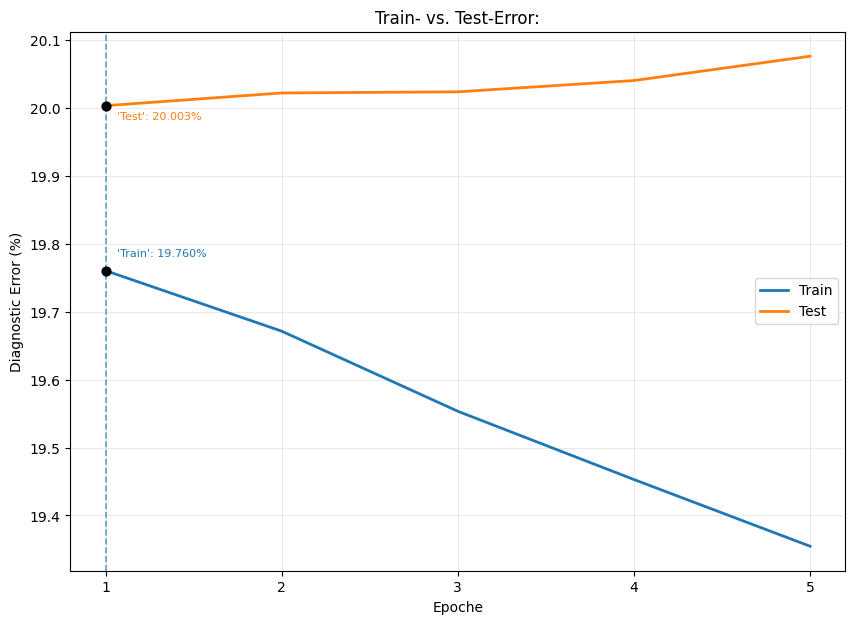

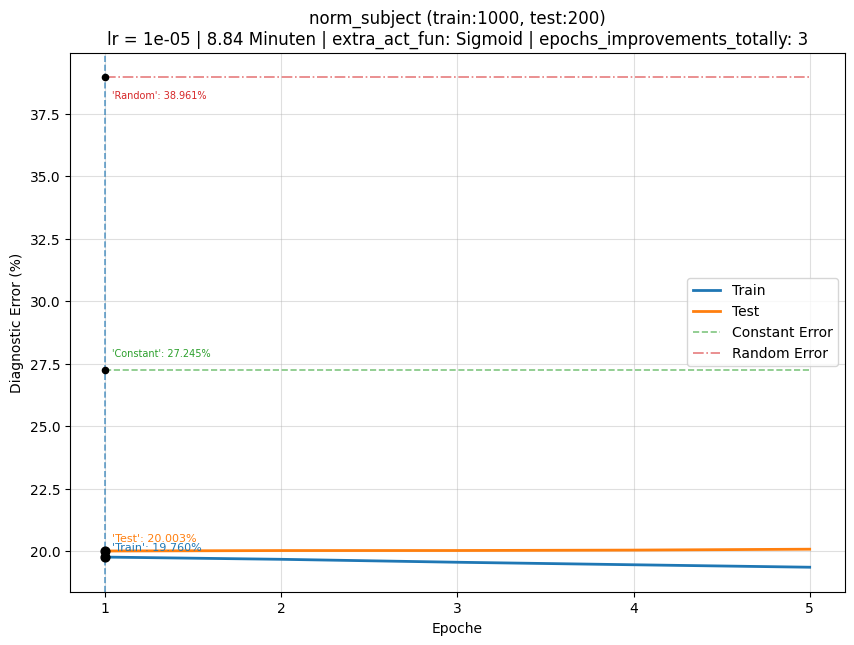

In [ ]:

print(f"\n\n Diagonal-Train-Error: {np.float64(diag_train_error)}\n")
print(f" Diagonal-Test-Error: {np.float64(diag_test_error)}\n\n")

print(f" Diagonal-Train-Error-Max: {np.max(diag_train_error)} \t Diagonal-Train-Error-Min: {np.min(diag_train_error)}\t")
# print(f" Diagonal-Train-Error-Ave: {np.mean(diag_train_error)}\n")

print(f" Diagonal-Test-Error-Max: {np.max(diag_test_error)}\t Diagonal-Test-Error-Min: {np.min(diag_test_error)}\t max_needed_epochs: {e+2}\n\n")
# print(f" Diagonal-Test-Error-Ave: {np.mean(diag_test_error)}\n")


if globals().get("bas_const_err") is None:
    bas_const_err = 30.99

if globals().get("bas_rand_err") is None:
    bas_rand_err = 42.70


# Curven:

# Minimum Test Error bestimmen
min_test_error = min(diag_test_error)
min_test_epoch = diag_test_error.index(min_test_error) + 1

# Die vier Werte an dieser Epoch
train_at_min = diag_train_error[min_test_epoch - 1]
test_at_min = diag_test_error[min_test_epoch - 1]
const_at_min = bas_const_err
rand_at_min = bas_rand_err

# Die Farbe
train_color = "tab:blue"
test_color = "tab:orange"
const_color = "tab:green"
rand_color = "tab:red"
point_color = "black"

# Epochs beginnen bei 1
epochs = range(1, len(diag_test_error) + 1)
# epochs = range(0, len(diag_test_error) + 1)

plt.figure(figsize=(10, 7))

# Train Error
plt.plot(epochs, diag_train_error, label="Train", linewidth=2, color=train_color)


# Test Error
plt.plot(epochs, diag_test_error, label="Test", linewidth=2, color=test_color)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=test_color,
    fontsize=8,
)


plt.title("Train- vs. Test-Error:")
plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(epochs)

plt.grid(True, alpha=0.3, linewidth=0.6)
plt.legend()



# ===================================================
# =============== all 4 Diagrams ====================
# ===================================================


plt.figure(figsize=(10, 7))


# Train Error
plt.plot(
    epochs,
    diag_train_error,
    label="Train",
    linewidth=2,
    color=train_color
)


# Test Error
plt.plot(
    epochs,
    diag_test_error,
    label="Test",
    linewidth=2,
    color=test_color
)


# Constant Baseline
plt.plot(
    epochs,
    [bas_const_err] * len(epochs),
    label="Constant Error",
    linestyle="--",
    linewidth=1.2,
    alpha=0.6,
    color=const_color
)


# Random Baseline
plt.plot(
    epochs,
    [bas_rand_err] * len(epochs),
    label="Random Error",
    linestyle="-.",
    linewidth=1.2,
    alpha=0.6,
    color=rand_color
)



print(f"\nMinimum Test Error:")
print(f"Epoch:           {min_test_epoch}")
print(f"Test Error:      {test_at_min:.4f}%")
print(f"Train Error:     {train_at_min:.4f}%")
print(f"Constant Error:  {bas_const_err:.4f}%")
print(f"Random Error:    {bas_rand_err:.4f}%\n")


# Punkt beim Minimum des Test Errors
plt.scatter(
    min_test_epoch,
    min_test_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

plt.scatter(
    min_test_epoch,
    const_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.scatter(
    min_test_epoch,
    rand_at_min,
    s=20,
    zorder=4,
    color=point_color
)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_test_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_test_epoch, train_at_min),
    xytext=(5, 5),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {test_at_min:.3f}%",
    xy=(min_test_epoch, test_at_min),
    xytext=(5, 7),
    textcoords="offset points",
    color=test_color,
    fontsize=8
)

plt.annotate(
    f"'Constant': {const_at_min:.3f}%",
    xy=(min_test_epoch, const_at_min),
    xytext=(5, 10),
    textcoords="offset points",
    color=const_color,
    fontsize=7
)

plt.annotate(
    f"'Random': {rand_at_min:.3f}%",
    xy=(min_test_epoch, rand_at_min),
    xytext=(5, -15),
    textcoords="offset points",
    color=rand_color,
    fontsize=7
)

# Titel
plt.title(
    f"{def_dataset} "
    f"(train:{def_dataset_size[0]}, test:{def_dataset_size[1]})\n"
    f"lr = {learning_rate} | "
    f"{elapsed_running_time / 60:.2f} Minuten | "
    f"extra_act_fun: {active_func} | "
    f"epochs_improvements_totally: {e + 2}"
)
# plt.title(f"{def_dataset}((train:{def_dataset_size[0]}, test:{def_dataset_size[1]})) \n" 
#           f" lr = {learning_rate} | {elapsed_running_time/60:.2f} Minuten | extra_act_fun: {active_func} | epochs_imporovments_totally: {e+2}"
# )

plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(epochs)

# plt.xticks(range(1, len(epochs) + 1, 1))
# plt.yticks(range(0, 51, 5))

plt.grid(True, alpha=0.4)
plt.legend()

# Ordner erstellen (falls er noch nicht existiert)
os.makedirs("./results", exist_ok=True)

# Diagramm speichern
plt.savefig(
    f"results/diag_error_{def_dataset}_{learning_rate}_{def_dataset_size[0]}_{def_dataset_size[1]}_a.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Compare : 
lr (1e-4 vs. 1e-5 vs. 1e-6) | 

datasets: (random_split vs. norm_subject_split) | 

train_size (1% vs 10%) 

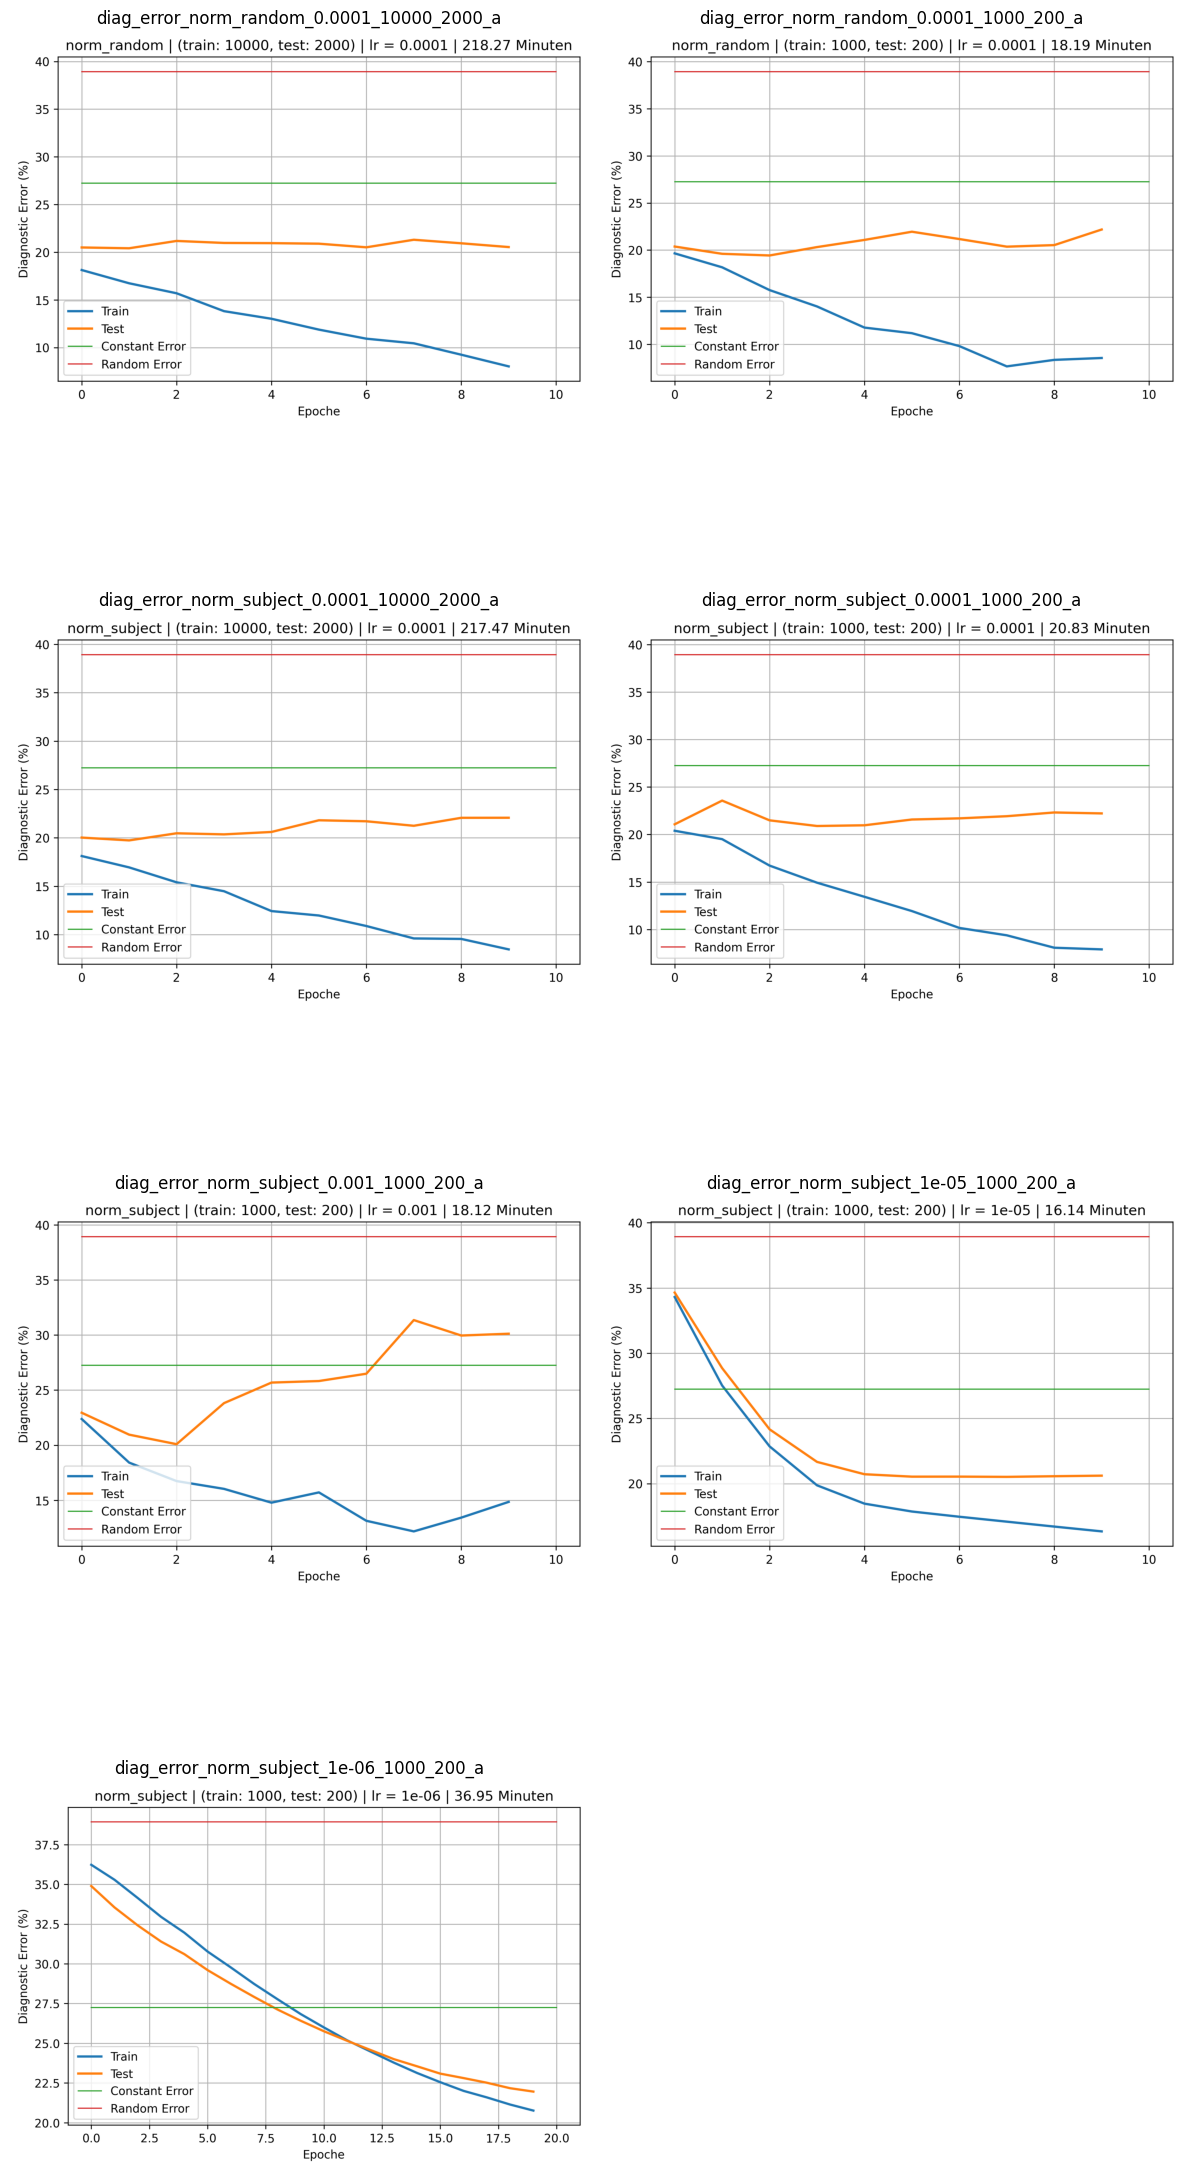

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

result_path = Path("./results/parameter")

images = sorted(result_path.glob("*.png"))

cols = 2
rows = (len(images) + cols - 1) // cols

plt.figure(figsize=(12, 6 * rows))

for i, img_path in enumerate(images):

    img = mpimg.imread(img_path)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(img_path.stem)

plt.tight_layout()
plt.show()

# ============== Evaluation ============= #

In [ ]:
# ---------- Evaluation ----------

saved_model_name = "models/ResNet_try_optim-model_norm_subject_1000-200.path"
saved_model = "./models/best-model_ResNet_Sigmoid.path"

checkpoint = torch.load(
    saved_model,
    map_location=device
)

model.load_state_dict(checkpoint)

model.to(device)

model.eval()


print(f"Test:\n")
test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)

print(
        f"test_diag_error={test_diag_pct:.4f}% "
    )


targets, predictions, errors = evaluate_model(
    model,
    test_loader,
    device
)

Test:

MAE : 0.2366 	 RMSE: 0.2847 
Diagonal-Error %: 20.1280 %
test_diag_error=20.1280% 


## Loss 1:

In [ ]:
import pandas as pd


results_df = pd.DataFrame({
    "gt_x": targets[:, 0],
    "gt_y": targets[:, 1],
    "pred_x": predictions[:, 0],
    "pred_y": predictions[:, 1]
})


results_df.to_csv(
    "results/baseline_predictions_loss2.csv",
    index=False
)


In [ ]:
# Test:
print(results_df.head(10))

print(f"\n Anzahl Ergebnisse: {len(results_df)}\n\n")

print(results_df.shape)


       gt_x      gt_y    pred_x    pred_y
0  0.609727  0.246337  0.479229  0.501485
1  0.609727  0.246337  0.478659  0.507570
2  0.609727  0.246337  0.474599  0.505390
3  0.609727  0.246337  0.479476  0.499415
4  0.113634  0.162799  0.477582  0.501991
5  0.113634  0.162799  0.478623  0.503317
6  0.113634  0.162799  0.479308  0.505337
7  0.113634  0.162799  0.474226  0.502242
8  0.113634  0.162799  0.479581  0.504091
9  0.389503  0.616551  0.477245  0.502086

 Anzahl Ergebnisse: 200


(200, 4)


# ---------- Visualization ----------

In [ ]:
import numpy as np
from scipy import stats

import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Ellipse


In [ ]:
class GazeVisualizer:

    def plot_ground_truth(self, targets):
        
        plt.figure(figsize=(6,6))

        plt.scatter(
            targets[:,0],
            targets[:,1],
            s=8
        )
        
        plt.title("Ground Truth")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.grid()
        plt.show()
        

    def plot_predictions(self, predictions):
        
        plt.figure(figsize=(6,6))

        plt.scatter(
            predictions[:,0],
            predictions[:,1],
            s=8
        )
        
        plt.title("Prediction")
        plt.grid()
        plt.show()

    
    def plot_comparison(self, predictions, targets):
        
        plt.figure(figsize=(7,7))
        
        plt.scatter(
            targets[:,0],
            targets[:,1],
            color="red",
            s=15,
            label="Ground Truth"
        )
        
        plt.scatter(
            predictions[:,0],
            predictions[:,1],
            color="blue",
            s=15,
            label="Prediction"
        )
        
        for i in range(len(targets)):
            plt.plot(
                [targets[i,0], predictions[i,0]],
                [targets[i,1], predictions[i,1]],
                color="gray",
                alpha=0.2
            )
        
        plt.legend()
        plt.grid()
        plt.show()



In [ ]:
def plot_confidence_ellipse(mu, cov, confidence, ax, **kwargs):

    # Chi-Square quantile für 2 Freiheitsgrade
    c = -2 * np.log(1 - confidence)

    # Eigenwerte und Eigenvektoren
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # Größten Eigenwert zuerst
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Breite und Höhe der Ellipse
    width, height = 2 * np.sqrt(c * eigenvalues)

    # Winkel des größten Eigenvektors
    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    ellipse = Ellipse(
        xy=mu,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        **kwargs
    )

    ax.add_patch(ellipse)

    return ellipse

In [ ]:
def confidence_interval(data, confidence=0.95):

    data = np.asarray(data)

    n = len(data)

    mean = np.mean(data)
    std = np.std(data, ddof=1)

    standard_error = std / np.sqrt(n)

    t_value = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = t_value * standard_error

    lower = mean - margin
    upper = mean + margin

    return mean, lower, upper

In [ ]:
try:
        df = pd.read_csv('results/baseline_predictions2.csv')

        
except Exception as e:
    print(f"Error loading CSV file: {e}")

gt_x, gt_y = df[['gt_x']].to_numpy(), df[['gt_y']].to_numpy()
pred_x, pred_y = df[['pred_x']].to_numpy(), df[['pred_y']].to_numpy()

mean_x, lower_x, upper_x = confidence_interval(gt_x)
mean_y, lower_y, upper_y = confidence_interval(gt_y)

mean_px, lower_px, upper_px = confidence_interval(pred_x)
mean_py, lower_py, upper_py = confidence_interval(pred_y)

## Output:
# Grund Truth:
print(f"\nX Mean: {mean_x:.4f}")
print(f"X 95% CI: [{lower_x:.4f}, {upper_x:.4f}]")

print(f"\nY Mean: {mean_y:.4f}")
print(f"Y 95% CI: [{lower_y:.4f}, {upper_y:.4f}]\n")

# Predictions:
print(f"\nPred_X Mean: {mean_px:.4f}")
print(f"Pred_X 95% CI: [{lower_px:.4f}, {upper_px:.4f}]")

print(f"\nPred_Y Mean: {mean_py:.4f}")
print(f"Pred_Y 95% CI: [{lower_py:.4f}, {upper_py:.4f}]\n")


X Mean: 0.4483
X 95% CI: [0.4072, 0.4894]

Y Mean: 0.4730
Y 95% CI: [0.4355, 0.5105]


Pred_X Mean: 0.4790
Pred_X 95% CI: [0.4786, 0.4794]

Pred_Y Mean: 0.5035
Pred_Y 95% CI: [0.5030, 0.5041]



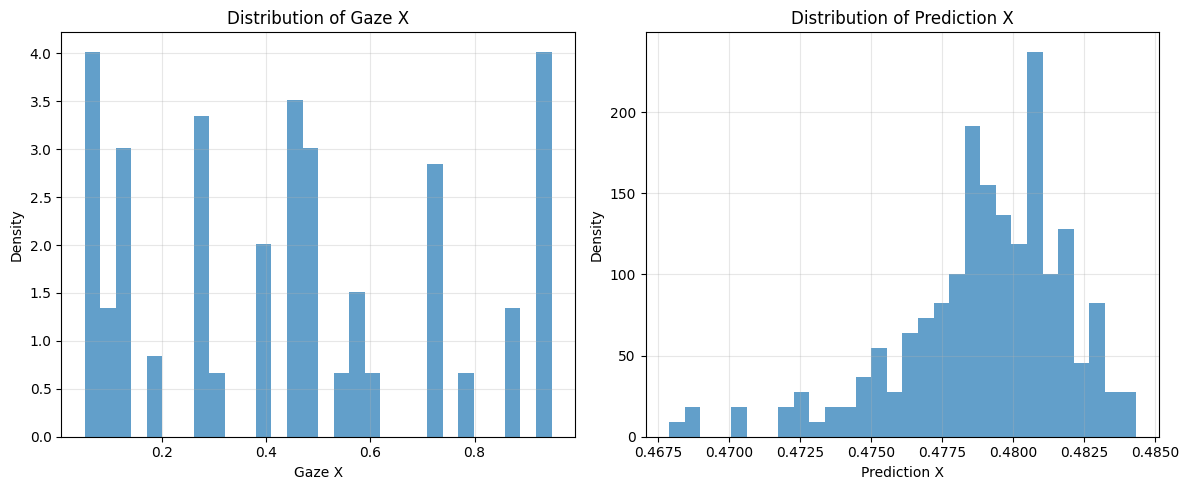

In [ ]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# -------------------------
# Ground Truth X
# -------------------------
ax1.hist(
    gt_x,
    bins=30,
    density=True,
    alpha=0.7
)

ax1.set_xlabel("Gaze X")
ax1.set_ylabel("Density")
ax1.set_title("Distribution of Gaze X")
ax1.grid(True, alpha=0.3)


# -------------------------
# Prediction X
# -------------------------
ax2.hist(
    pred_x,
    bins=30,
    density=True,
    alpha=0.7
)

ax2.set_xlabel("Prediction X")
ax2.set_ylabel("Density")
ax2.set_title("Distribution of Prediction X")
ax2.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

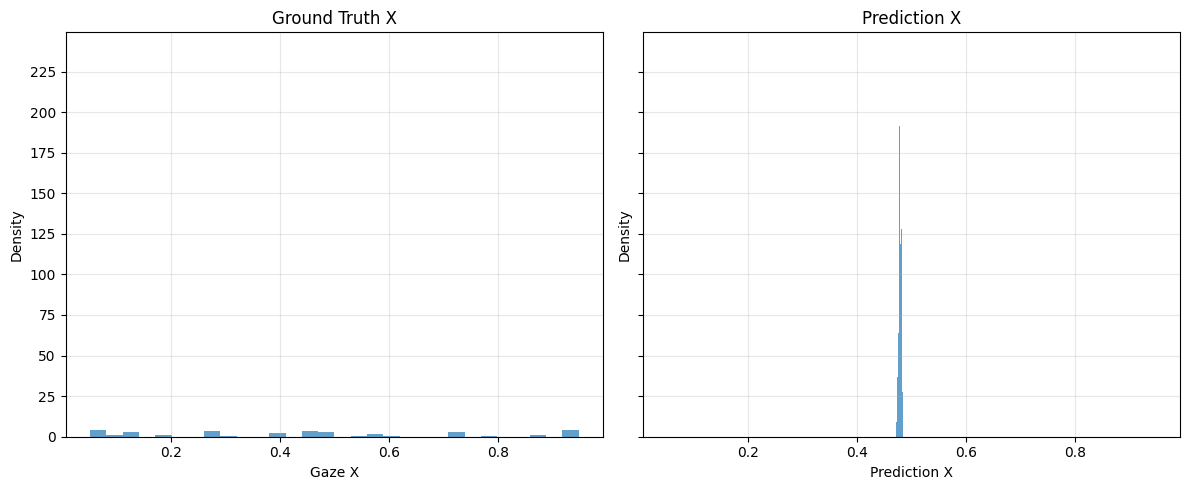

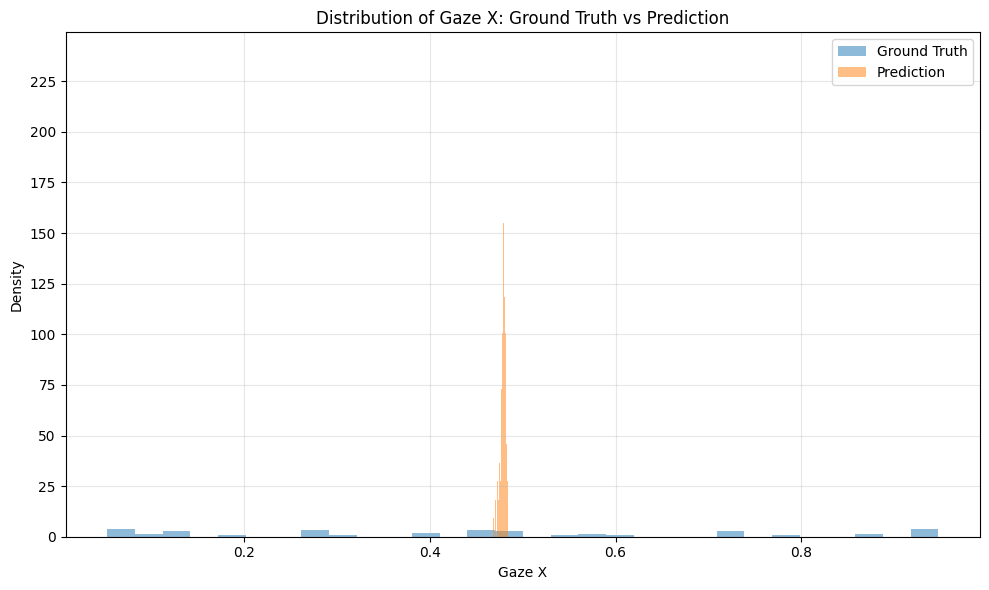

In [ ]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Ground Truth
ax1.hist(
    gt_x,
    bins=30,
    density=True,
    alpha=0.7
)

ax1.set_xlabel("Gaze X")
ax1.set_ylabel("Density")
ax1.set_title("Ground Truth X")
ax1.grid(True, alpha=0.3)


# Prediction
ax2.hist(
    pred_x,
    bins=30,
    density=True,
    alpha=0.7
)

ax2.set_xlabel("Prediction X")
ax2.set_ylabel("Density")
ax2.set_title("Prediction X")
ax2.grid(True, alpha=0.3)

plt.yticks(range(0, 250, 25))
plt.tight_layout()
plt.show()




plt.figure(figsize=(10, 6))

plt.hist(
    gt_x,
    bins=30,
    density=True,
    alpha=0.5,
    label="Ground Truth"
)

plt.hist(
    pred_x,
    bins=30,
    density=True,
    alpha=0.5,
    label="Prediction"
)

plt.xlabel("Gaze X")
plt.ylabel("Density")
plt.title("Distribution of Gaze X: Ground Truth vs Prediction")

plt.legend()
plt.grid(True, alpha=0.3)

plt.yticks(range(0, 250, 25))
plt.tight_layout()
plt.show()

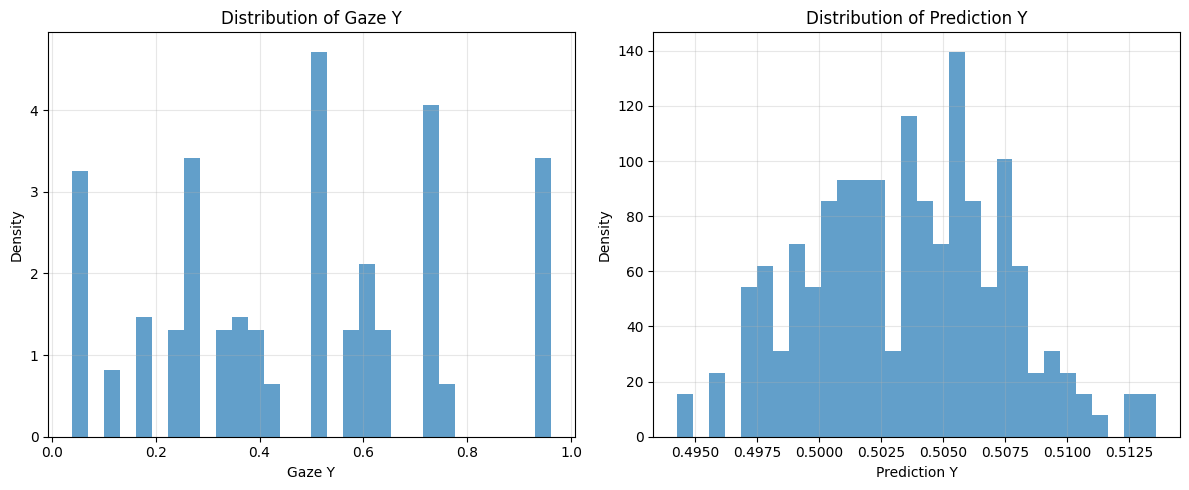

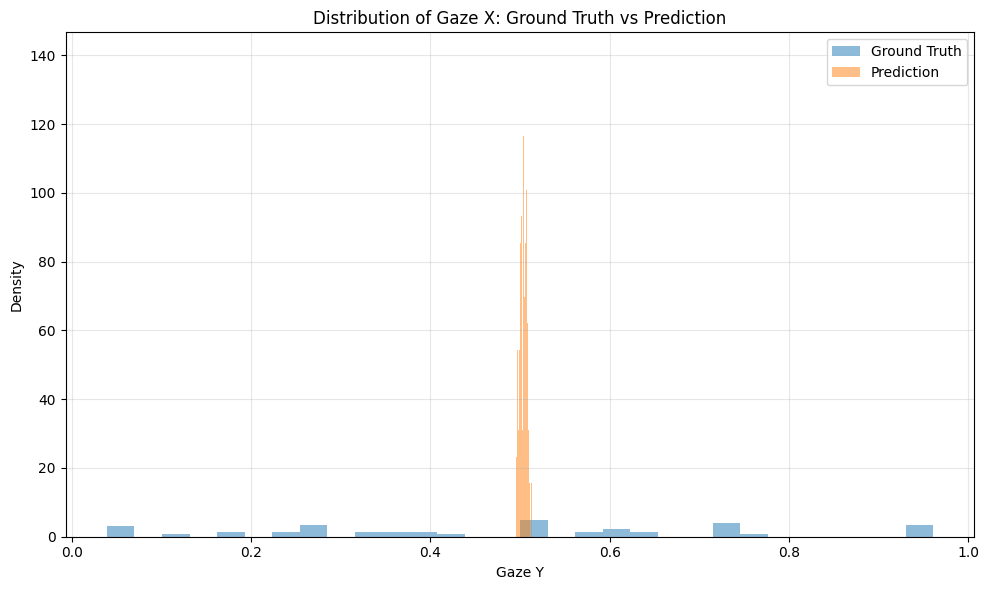

In [ ]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# -------------------------
# Ground Truth Y
# -------------------------
ax1.hist(
    gt_y,
    bins=30,
    density=True,
    alpha=0.7
)

ax1.set_xlabel("Gaze Y")
ax1.set_ylabel("Density")
ax1.set_title("Distribution of Gaze Y")
ax1.grid(True, alpha=0.3)


# -------------------------
# Prediction Y
# -------------------------
ax2.hist(
    pred_y,
    bins=30,
    density=True,
    alpha=0.7
)

ax2.set_xlabel("Prediction Y")
ax2.set_ylabel("Density")
ax2.set_title("Distribution of Prediction Y")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

plt.hist(
    gt_y,
    bins=30,
    density=True,
    alpha=0.5,
    label="Ground Truth"
)

plt.hist(
    pred_y,
    bins=30,
    density=True,
    alpha=0.5,
    label="Prediction"
)

plt.xlabel("Gaze Y")
plt.ylabel("Density")
plt.title("Distribution of Gaze X: Ground Truth vs Prediction")

plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

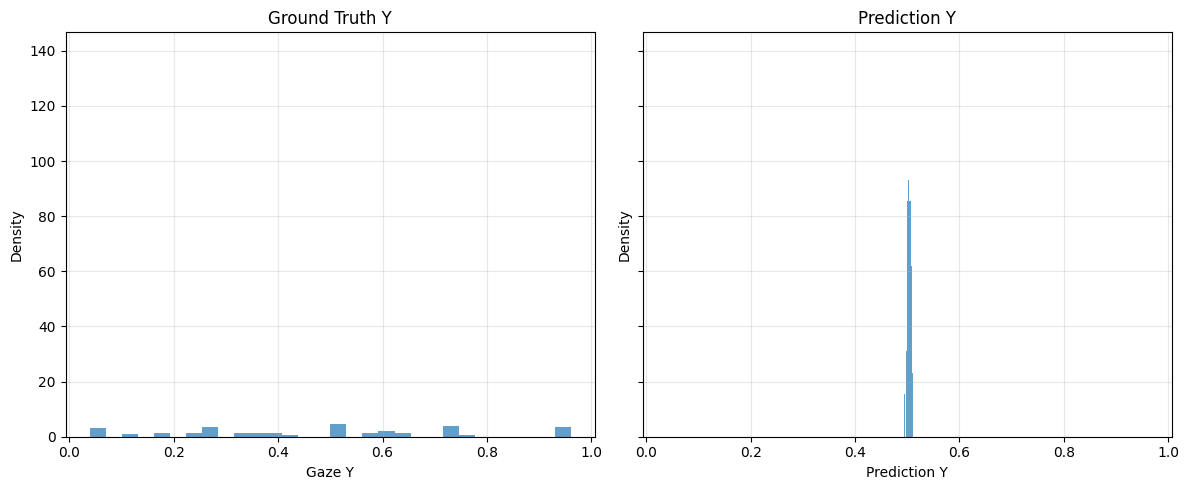

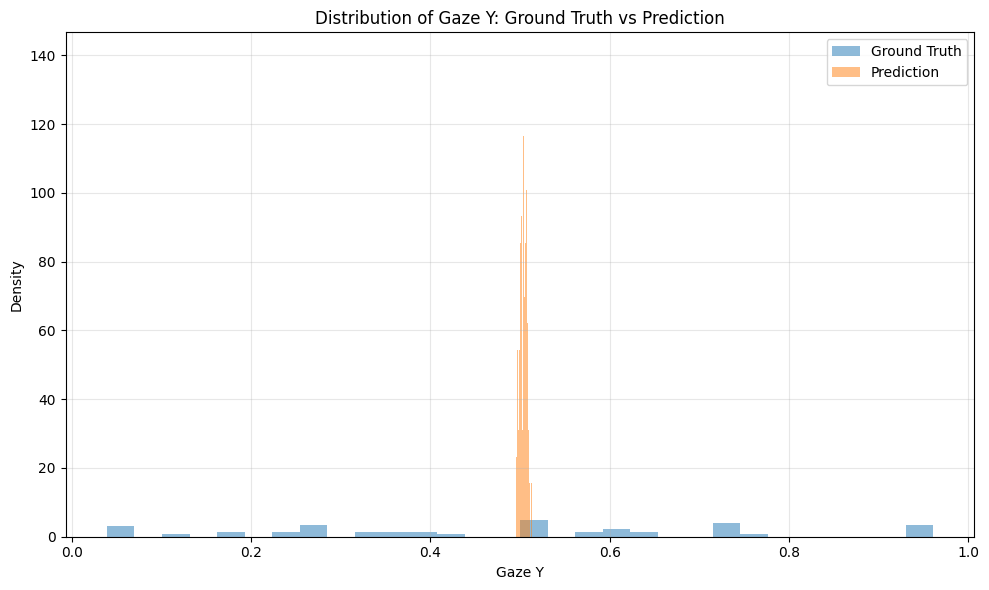

In [ ]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Ground Truth
ax1.hist(
    gt_y,
    bins=30,
    density=True,
    alpha=0.7
)

ax1.set_xlabel("Gaze Y")
ax1.set_ylabel("Density")
ax1.set_title("Ground Truth Y")
ax1.grid(True, alpha=0.3)


# Prediction
ax2.hist(
    pred_y,
    bins=30,
    density=True,
    alpha=0.7
)

ax2.set_xlabel("Prediction Y")
ax2.set_ylabel("Density")
ax2.set_title("Prediction Y")
ax2.grid(True, alpha=0.3)

plt.yticks(range(0, 160, 20))
plt.tight_layout()
plt.show()




plt.figure(figsize=(10, 6))

plt.hist(
    gt_y,
    bins=30,
    density=True,
    alpha=0.5,
    label="Ground Truth"
)

plt.hist(
    pred_y,
    bins=30,
    density=True,
    alpha=0.5,
    label="Prediction"
)

plt.xlabel("Gaze Y")
plt.ylabel("Density")
plt.title("Distribution of Gaze Y: Ground Truth vs Prediction")

plt.legend()
plt.grid(True, alpha=0.3)


plt.yticks(range(0, 160, 20))
plt.tight_layout()
plt.show()


Min_gt_X: [0.05208333] 	 Max_gt_X: [0.9479167]
Min_gt_Y:[0.0390625] 	 Max_gt_Y: [0.9609375]


len(points_gt): 200
len(points_prd): 200


Mean Ground-Truth:
	 X-mean: 0.448291 	 Y-mean: 0.472981 

Covariance - Ground Truth:
	 X-Cov: [0.087038, 0.006601]

	 Y-Cov: [0.006601, 0.072284]


Mean Predictions:
	 X-mean: 0.478976 	 Y-mean: 0.503518 

Covariance - Prediction:
	 X-Cov: [0.000009, 0.000004]

	 Y-Cov: [0.000004, 0.000015]


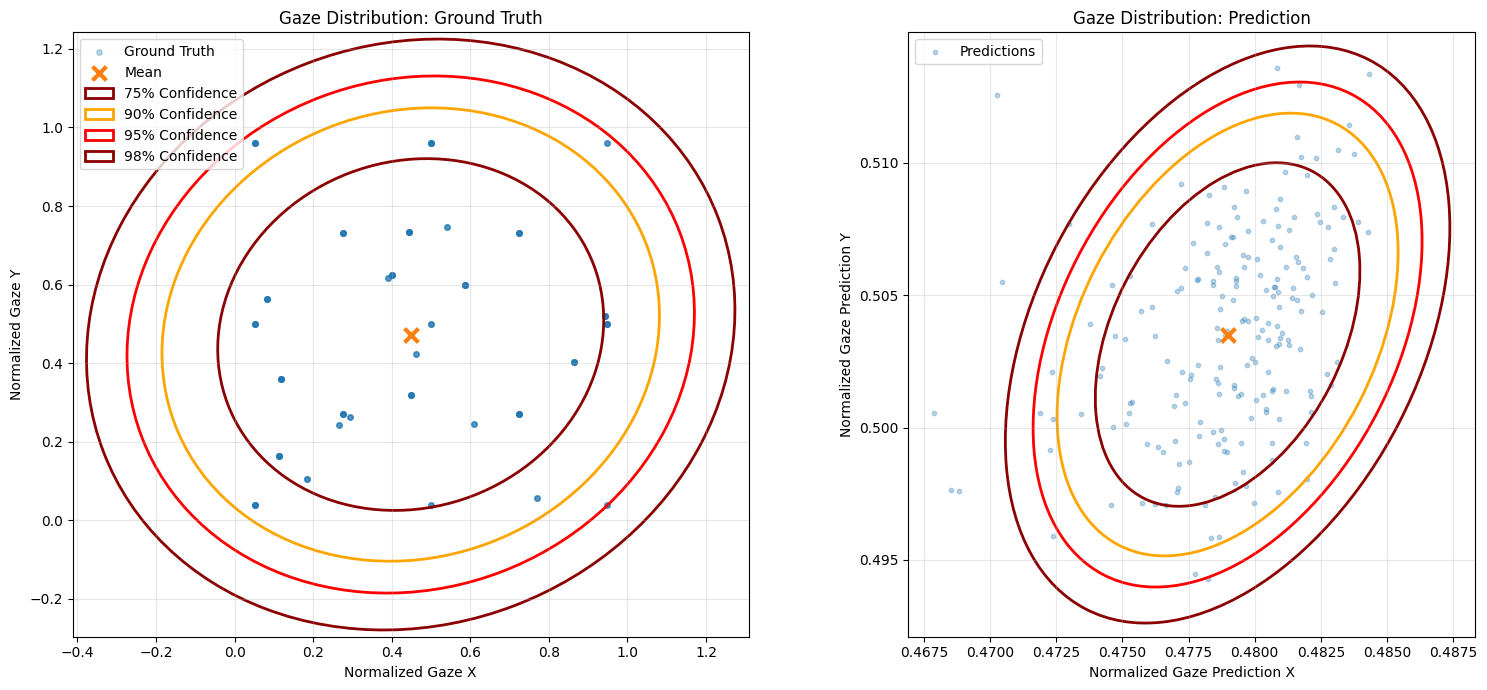

In [ ]:

# df = pd.read_csv("results/baseline_predictions.csv")

# gt_x = df["gt_x"].to_numpy()
# gt_y = df["gt_y"].to_numpy()
# pred_x = df["pred_x"].to_numpy()
# pred_y = df["pred_y"].to_numpy()

print(f"\nMin_gt_X: {min(gt_x)} \t Max_gt_X: {max(gt_x)}\n"
      f"Min_gt_Y:{min(gt_y)} \t Max_gt_Y: {max(gt_y)}\n\n")

points_gt = np.column_stack((gt_x, gt_y))
print(f"len(points_gt): {len(points_gt)}")

points_prd = np.column_stack((pred_x, pred_y))
print(f"len(points_prd): {len(points_prd)}")


mu_gt = np.mean(points_gt, axis=0)
cov_gt = np.cov(points_gt, rowvar=False)

mu_prd = np.mean(points_prd, axis=0)
cov_prd = np.cov(points_prd, rowvar=False)

print(f"\n\nMean Ground-Truth:\n\t X-mean: {mu_gt[0]:.6f} \t Y-mean: {mu_gt[1]:.6f} " 
      f"\n\nCovariance - Ground Truth:\n\t X-Cov: [{cov_gt[0][0]:.6f}, {cov_gt[0][1]:.6f}]" 
      f"\n\n\t Y-Cov: [{cov_gt[1][0]:.6f}, {cov_gt[1][1]:.6f}]")


print(f"\n\nMean Predictions:\n\t X-mean: {mu_prd[0]:.6f} \t Y-mean: {mu_prd[1]:.6f} " 
      f"\n\nCovariance - Prediction:\n\t X-Cov: [{cov_prd[0][0]:.6f}, {cov_prd[0][1]:.6f}]" 
      f"\n\n\t Y-Cov: [{cov_prd[1][0]:.6f}, {cov_prd[1][1]:.6f}]")


# =============================================================
# =================== PLOT ====================================
# =============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# =============================================================
# ================= Ground Truth ==============================
# =============================================================

# Datenpunkte
ax1.scatter(
    gt_x,
    gt_y,
    s=15,
    alpha=0.3,
    label="Ground Truth"
)

# Mean
ax1.scatter(
    mu_gt[0],
    mu_gt[1],
    marker="x",
    s=100,
    linewidths=3,
    label="Mean"
)

# 75% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.75,
    ax1,
    edgecolor="darkred",
    linewidth=2,
    label="75% Confidence"
)

# 90% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.90,
    ax1,
    edgecolor="orange",
    linewidth=2,
    label="90% Confidence"
)

# 95% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.95,
    ax1,
    edgecolor="red",
    linewidth=2,
    label="95% Confidence"
)

# 98% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.98,
    ax1,
    edgecolor="darkred",
    linewidth=2,
    label="98% Confidence"
)


ax1.set_xlabel("Normalized Gaze X")
ax1.set_ylabel("Normalized Gaze Y")

ax1.set_title(
    "Gaze Distribution: Ground Truth"
)

ax1.grid(True, alpha=0.3)
ax1.legend()

ax1.set_aspect("equal")



# =============================================================
# ================= Prediction ================================
# =============================================================

# Datenpunkte
ax2.scatter(
    pred_x,
    pred_y,
    s=10,
    alpha=0.3,
    label="Predictions"
)

# Mean
ax2.scatter(
    mu_prd[0],
    mu_prd[1],
    marker="x",
    s=100,
    linewidths=3,
    # label="Mean"
)

# 75% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.75,
    ax2,
    edgecolor="darkred",
    linewidth=2,
    # label="75% Confidence"
)

# 90% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.90,
    ax2,
    edgecolor="orange",
    linewidth=2,
    # label="90% Confidence"
)

# 95% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.95,
    ax2,
    edgecolor="red",
    linewidth=2,
    # label="95% Confidence"
)

# 98% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.98,
    ax2,
    edgecolor="darkred",
    linewidth=2,
    # label="98% Confidence"
)

# 99.995% Confidence
# plot_confidence_ellipse(
#     mu_prd,
#     cov_prd,
#     0.99995,
#     ax2,
#     edgecolor="yellow",
#     linewidth=2,
#     label="99.995% Confidence"
# )


ax2.set_xlabel("Normalized Gaze Prediction X")
ax2.set_ylabel("Normalized Gaze Prediction Y")

ax2.set_title(
    "Gaze Distribution: Prediction"
)

ax2.grid(True, alpha=0.3)
ax2.legend()

ax2.set_aspect("equal")


# =============================================================
# =================== Gemeinsames Layout ======================
# =============================================================

plt.tight_layout()
plt.show()



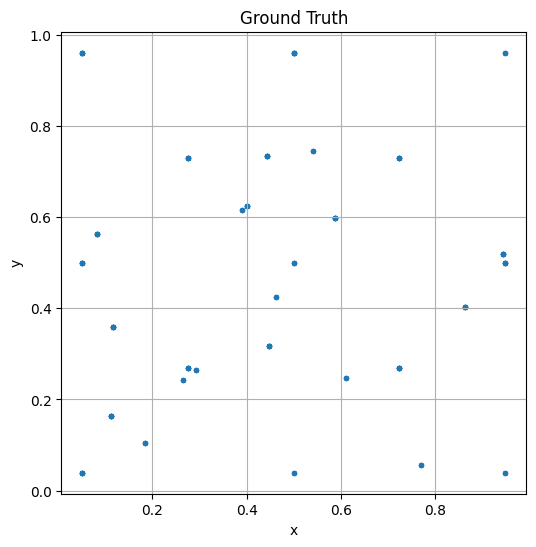

In [ ]:

vis = GazeVisualizer()

vis.plot_ground_truth(targets)



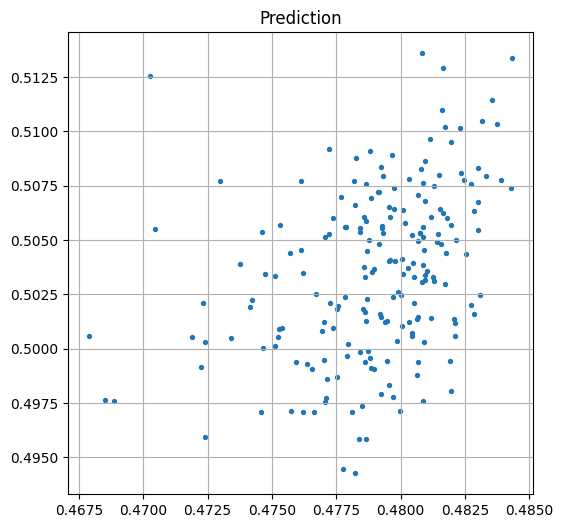

In [ ]:
vis.plot_predictions(predictions)


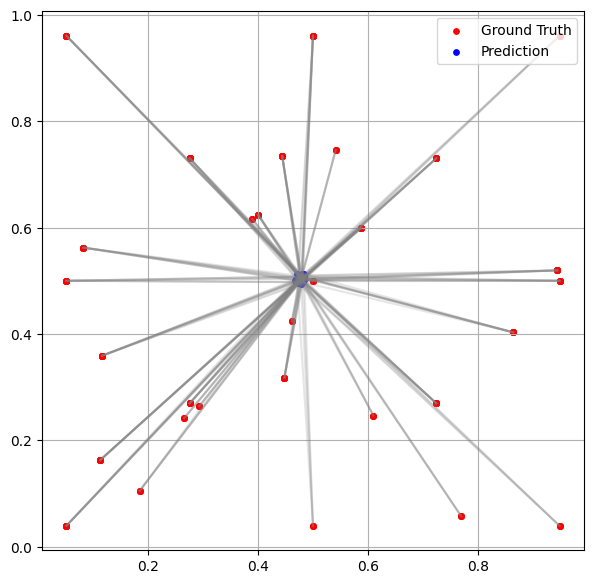

In [ ]:
vis.plot_comparison(predictions, targets)



---
# 3. Archiv: `02_baseline.ipynb`
Erste Baseline-Berechnungen (Original). Zellen: 11 (ohne leere).

In [ ]:
# Inhalt ansehen

import os
dataset_path = "/kaggle/input/datasets/dhruv413/gaze-capture-20gb-zip"

i = 0
for root, dirs, files in os.walk(dataset_path):
    i += 1
    print("ROOT:", root)
    print("FILES:", files[:10])
    print("*" * 60)

    if i > 8:
        break




In [ ]:
# Step 0:
! pip install datasets huggingface_hub pandas pillow
! pip install -U huggingface_hub


In [ ]:
# Step 1:

from huggingface_hub import snapshot_download
import os

#DATASET_REPO = "RafeiKAr/my_dataset_gaze"
DATASET_REPO = "RafeiKAr/gaze-estimation_gazecapture"

LOCAL_DATASET_DIR = "./data"

if not os.path.exists(LOCAL_DATASET_DIR):
    print("Lade Dataset von Hugging Face herunter...")

    snapshot_download(
        repo_id=DATASET_REPO,
        repo_type="dataset",
        local_dir=LOCAL_DATASET_DIR,
        local_dir_use_symlinks=False
    )

    print("Download fertig.")
else:
    print("Dataset bereits vorhanden.")

Lade Dataset von Hugging Face herunter...


/home/ari/PycharmProjects/Ven/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Download fertig.


In [ ]:
images_dir = "./data/images"
labels_file = "./data/labels.csv"

In [ ]:
import pandas as pd

df = pd.read_csv("./data/labels.csv")

print(df.head())
print("Anzahl Samples:", len(df))

        image_name           x           y
0  00002_00000.jpg  160.000000  284.000000
1  00002_00001.jpg  160.000000  284.000000
2  00002_00002.jpg  160.000000  284.000000
3  00002_00003.jpg  160.000000  284.000000
4  00002_00004.jpg  279.657292   64.965084
Anzahl Samples: 21844


In [ ]:
# Step 4:

print("Anzahl Samples:", len(df))


Anzahl Samples: 21844


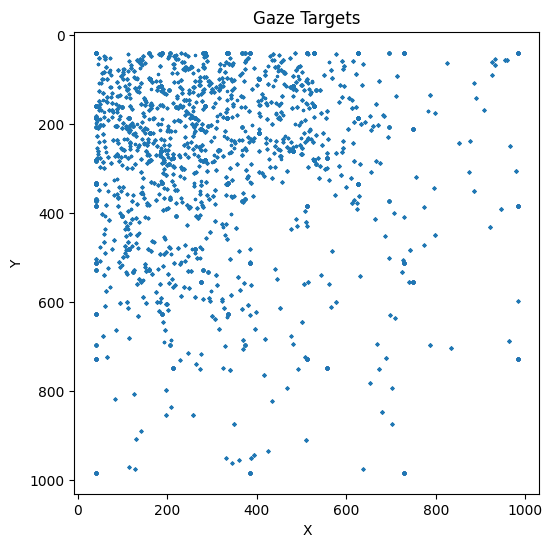

In [ ]:
# Step 5:

import matplotlib.pyplot as plt

x = df["x"]
y = df["y"]

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Gaze Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()


In [ ]:
screen_w = df["x"].max()
screen_h = df["y"].max()

print(screen_w, screen_h)

984.0 984.0


In [ ]:
# Step 6.1. Constante Baseline

import numpy as np

x_true = df["x"].values
y_true = df["y"].values

x_const = np.mean(x_true)
y_const = np.mean(y_true)

pred_x_const = np.full_like(x_true, x_const)
pred_y_const = np.full_like(y_true, y_const)

errors = np.sqrt(
    (x_true - pred_x_const)**2 +
    (y_true - pred_y_const)**2
)

print("\nKonstante Baseline: \n")
print(f"Mean Error: {np.mean(errors)}")
#print("Median Error:", np.median(errors))

print(
    f"Error %: {100*np.mean(errors)/screen_w:.2f}%"
)

print(f"Diagonal-Error %: {100*np.round(np.mean(errors) / np.sqrt(2*screen_w**2), 3)} %")


Konstante Baseline: 

Mean Error: 268.5927937860636
Error %: 27.30%
Diagonal-Error %: 19.3 %


In [ ]:
# 6.2. random Baseline

pred_x_random = np.random.uniform(
    0,
    screen_w,
    len(x_true)
)

pred_y_random = np.random.uniform(
    0,
    screen_h,
    len(y_true)
)

errors_random = np.sqrt(
    (x_true - pred_x_random)**2 +
    (y_true - pred_y_random)**2
)

print("\nRandom Baseline: \n")
print(f"\nMean Error: {np.mean(errors_random)}\n")

print(f"Error %: {np.round(np.mean(errors_random) / screen_w, 3)*100} %")

print(f"Diagonal-Error %: {100*np.round(np.mean(errors_random) / np.sqrt(2*screen_w**2), 3)} %")

Random Baseline
Mean Error: 513.7782718568463
Error %: 52.2 %
Diagonal-Error %: 36.9 %


In [ ]:

# Step 1: Verstehen, was in dofInfo.json steckt.

import json
import os

subject_path = "/kaggle/input/datasets/dhruv413/gaze-capture-20gb-zip/00114/00114"

with open(os.path.join(subject_path, "dotInfo.json")) as f:
    dotinfo = json.load(f)

print(type(dotinfo))
print(dotinfo.keys() if isinstance(dotinfo, dict) else dotinfo[:3])


###################################
# Step 2: check the size of Monitor

with open(os.path.join(subject_path, "screen.json")) as f:
    screen = json.load(f)

#print(f"Screen: {screen}")

###################################
# Step 3: check the number of frames

frames_path = os.path.join(subject_path, "frames")

frames = os.listdir(frames_path)

print("Anzahl Frames:", len(frames))
print(frames[:10])

###################################
# step 4: check the size of Xpts, Ypts, frames

print(len(dotinfo["XPts"]))
print(len(dotinfo["YPts"]))
print(len(frames))
    
###################################
# Step 5: visualisieren - Gaze points plot

import matplotlib.pyplot as plt

x = dotinfo["XPts"]
y = dotinfo["YPts"]

print(f"X_max:{max(x)}, Y_max: {max(y)}")

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Gaze Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()
    
###################################
# Step 6: create baseline
# Step 6_1: constante Baseline

# Mittelpunkt-Baseline

import numpy as np

x_true = np.array(dotinfo["XPts"])
y_true = np.array(dotinfo["YPts"])

x_const = np.mean(x_true)
y_const = np.mean(y_true)

pred_x_const = np.full_like(x_true, x_const)
pred_y_const = np.full_like(y_true, y_const)

###################################
errors = np.sqrt(
    (x_true - pred_x_const)**2 +
    (y_true - pred_y_const)**2
)

# anhand screen.json
screen_w = 568
screen_h = 568

print("konstante Baseline:")
print("Mean Error:", np.mean(errors))
print("Median Error:", np.median(errors))

print(f"Error in Prozent: {np.round(np.mean(errors) / screen_w, 3)*100} %")

print(f"Diagonal-Error in Prozent: {np.round(np.mean(errors) / np.sqrt(2*screen_w**2)*100, 3)} %")

###################################
# Step 6_2: Random Baseline

# anhand screen.json
screen_w = 568
screen_h = 568


pred_x_random = np.random.uniform(0, screen_w, len(x_true))
pred_y_random = np.random.uniform(0, screen_h, len(y_true))

errors_random = np.sqrt(
    (x_true - pred_x_random)**2 +
    (y_true - pred_y_random)**2
)

print("Random Baseline:")
print("Random Mean Error:", np.mean(errors_random))

print(f"Error in Prozent: {np.round(np.mean(errors_random) / screen_w, 3)*100} %")

print(f"Diagonal-Error in Prozent: {np.round(np.mean(errors_random) / np.sqrt(2*screen_w**2)*100, 3)} %")



---
# 4. Archiv: `03_training.ipynb`
Erstes Trainings-Notebook (Original). Zellen: 10 (ohne leere).

In [ ]:
import json
import csv
import os
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit

In [ ]:
def reformat(in_path, out_path):
    # shutil.unpack_archive(zip_path, extract_to)

    DATASET_ROOT = Path(in_path)

    OUTPUT_DIR = Path(out_path)

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    IMAGES_DIR = OUTPUT_DIR / "images"

    csv_path = OUTPUT_DIR / "labels.csv"

    with open(csv_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.writer(csv_file)

        writer.writerow([
            "image_name",
            "x",
            "y",
            "subject_ID"
        ])

        total_images = 0
        total_subjects = 0

        # ======================================================
        # Alle Subjekte durchlaufen
        # ======================================================

        for outer_subject_dir in sorted(DATASET_ROOT.iterdir()):

            if not outer_subject_dir.is_dir():
                continue

            subject_id = outer_subject_dir.name

            inner_subject_dir = (
                outer_subject_dir / subject_id
            )

            if not inner_subject_dir.exists():
                continue

            # ==================================================
            # Dateien laden
            # ==================================================

            frames_file = (
                inner_subject_dir / "frames.json"
            )

            dotinfo_file = (
                inner_subject_dir / "dotInfo.json"
            )

            frames_folder = (
                inner_subject_dir / "frames"
            )

            # --------------------------------------------------
            if not frames_file.exists():
                print(f"Skipping {subject_id}: frames.json missing")
                # skipped_subjects += 1
                continue

            if not dotinfo_file.exists():
                print(f"Skipping {subject_id}: dotInfo.json missing")
                # skipped_subjects += 1
                continue

            if not frames_folder.exists():
                print(f"Skipping {subject_id}: frames folder missing")
                # skipped_subjects += 1
                continue

            # --------------------------------------------------

            try:
                with open(frames_file, "r", encoding="utf-8") as f:
                    frame_names = json.load(f)

                with open(dotinfo_file, "r", encoding="utf-8") as f:
                    dot_info = json.load(f)


            except Exception as e:
                print(f"Skipping {subject_id}: JSON read error --> {e}")

            try:
                x_values = dot_info["XPts"]
                y_values = dot_info["YPts"]

            except KeyError as e:
                print(f"Skipping {subject_id}: missing key --> {e}")

            if len(frame_names) != len(x_values):
                print(
                    f"ERROR in {subject_id}: "
                    f"{len(frame_names)} frames but "
                    f"{len(x_values)} labels"
                )
                continue

            total_subjects += 1

            # ==================================================
            # Alle Frames bearbeiten
            # ==================================================

            for idx in range(len(frame_names)):

                original_image_name = frame_names[idx]

                x = x_values[idx]
                y = y_values[idx]

                source_image = (
                    frames_folder /
                    original_image_name
                )

                if not source_image.exists():
                    print(
                        f"Missing image: {source_image}"
                    )
                    continue

                writer.writerow([
                    source_image,
                    x,
                    y,
                    subject_id
                ])

                total_images += 1

    print()
    print("=" * 50)
    print("DONE")
    print("=" * 50)
    print(f"Subjects processed\t: {total_subjects}")
    print(f"Images processed\t: {total_images}")
    print(f"CSV saved to\t\t: {csv_path}")

In [ ]:
# 3: Normalization:

def normalize(in_path, out_path):

    DATASET_ROOT = Path(in_path)

    OUTPUT_DIR = Path(out_path)

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    IMAGES_DIR = OUTPUT_DIR / "images"

    csv_path = OUTPUT_DIR / "norm_labels.csv"

    with open(csv_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.writer(csv_file)

        writer.writerow([
            "image_name",
            "x_norm",
            "y_norm",
            "subject_ID",
            "screen_w",
            "screen_h"
        ])

        total_images = 0
        total_subjects = 0

        # ======================================================
        # Alle Subjekte durchlaufen
        # ======================================================

        for outer_subject_dir in sorted(DATASET_ROOT.iterdir()):

            if not outer_subject_dir.is_dir():
                continue

            subject_id = outer_subject_dir.name

            inner_subject_dir = (
                outer_subject_dir / subject_id
            )

            if not inner_subject_dir.exists():
                continue

            # ==================================================
            # Dateien laden
            # ==================================================

            frames_file = (
                inner_subject_dir / "frames.json"
            )

            dotinfo_file = (
                inner_subject_dir / "dotInfo.json"
            )

            frames_folder = (
                inner_subject_dir / "frames"
            )

            screen_file = (
                    inner_subject_dir / "screen.json"
            )

            # --------------------------------------------------
            if not frames_file.exists():
                print(f"Skipping {subject_id}: frames.json missing")
                continue

            if not dotinfo_file.exists():
                print(f"Skipping {subject_id}: dotInfo.json missing")
                continue

            if not frames_folder.exists():
                print(f"Skipping {subject_id}: frames folder missing")
                continue

            if not screen_file.exists():
                print(f"Skipping {subject_id}: frames folder missing")
                continue
            # --------------------------------------------------

            try:
                with open(frames_file, "r", encoding="utf-8") as f:
                    frame_names = json.load(f)

                with open(dotinfo_file, "r", encoding="utf-8") as f:
                    dot_info = json.load(f)

                with open(screen_file, "r", encoding="utf-8") as f:
                    screen_info = json.load(f)

            except Exception as e:
                print(f"Skipping {subject_id}: JSON read error --> {e}")

            try:
                x_values = dot_info["XPts"]
                y_values = dot_info["YPts"]

                h_values = screen_info["H"]
                w_values = screen_info["W"]
                orientation_values = screen_info["Orientation"]

            except KeyError as e:
                print(f"Skipping {subject_id}: missing key --> {e}")

            if len(frame_names) != len(x_values):
                print(
                    f"ERROR in {subject_id}: "
                    f"{len(frame_names)} frames but "
                    f"{len(x_values)} labels"
                )
                continue

            total_subjects += 1

            # ==================================================
            # Alle Frames bearbeiten
            # ==================================================

            for idx in range(len(frame_names)):

                original_image_name = frame_names[idx]

                x = x_values[idx]
                y = y_values[idx]
                
                screen_h = h_values[idx]
                screen_w = w_values[idx]
                
                orientation = screen_info["Orientation"][idx]
                
                
                # Rotation korrigieren
                if orientation == 1:
                    # normal
                    x_corr = x
                    y_corr = y
                
                elif orientation == 2:
                    # 180 Grad
                    x_corr = screen_w - x
                    y_corr = screen_h - y
                
                elif orientation == 3:
                    # 270 Grad
                    x_corr = y
                    y_corr = screen_w - x
                
                    # Breite/Höhe tauschen
                    screen_w, screen_h = screen_h, screen_w
                
                elif orientation == 4:
                    # 90 Grad
                    x_corr = screen_h - y
                    y_corr = x
                
                    # Breite/Höhe tauschen
                    screen_w, screen_h = screen_h, screen_w
                
                
                x_norm = x_corr / screen_w
                y_norm = y_corr / screen_h
                y_norm = np.clip(y_norm, 0, 1)
                    
                


                # Normalisation:
                # x_norm = x / screen_w
                # y_norm = y / screen_h

                # x_norm = x_corr / screen_w
                # y_norm = y_corr / screen_h


                source_image = (
                    frames_folder /
                    original_image_name
                )

                if not source_image.exists():
                    print(
                        f"Missing image: {source_image}"
                    )
                    continue


                writer.writerow([
                    source_image,
                    x_norm,
                    y_norm,
                    subject_id,
                    screen_w,
                    screen_h
                ])

                # pause = input ("Wait a moment!")

                total_images += 1


    print()
    print("=" * 50)
    print(f"{'#'*10} Normalisation DONE {'#'*10}")
    print("=" * 100)
    print(f"Subjects processed : {total_subjects}")
    print(f"Images processed   : {total_images}")
    print(f"CSV saved to       : {csv_path}")

In [ ]:
# Checking for file (labels.csv):
dataset_path = './dataset/images/'
if not os.path.exists('./dataset/labels.csv'):
    print(f"The file: 'labels.csv' is necessary, but doesn't find!\n Try to create it ...  ")
    reformat(dataset_path, "./dataset/")
    if os.path.exists('./dataset/labels.csv'):
        print(f"Now can find the file: 'labels.csv' !\n ")


In [ ]:
import os
import re
import json
import csv
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


# Checking for normalize-file (norm_labels.csv):
dataset_path = './dataset/images/'
if not os.path.exists('./dataset/norm_labels.csv'):
    print(
        f"The file: 'norm_labels.csv' is maybe needed, but doesn't find!\n Try to create it ... ")
    normalize(dataset_path, "./dataset/")
    if os.path.exists('./dataset/norm_labels.csv'):
        print(f"Now can find the file: 'norm_labels.csv' !\n ")

The file: 'norm_labels.csv' is maybe needed, but doesn't find!
 Try to create it ... 
Skipping 00678: frames.json missing

########## Normalisation DONE ##########
Subjects processed : 262
Images processed   : 347085
CSV saved to       : dataset/norm_labels.csv
Now can find the file: 'norm_labels.csv' !
 


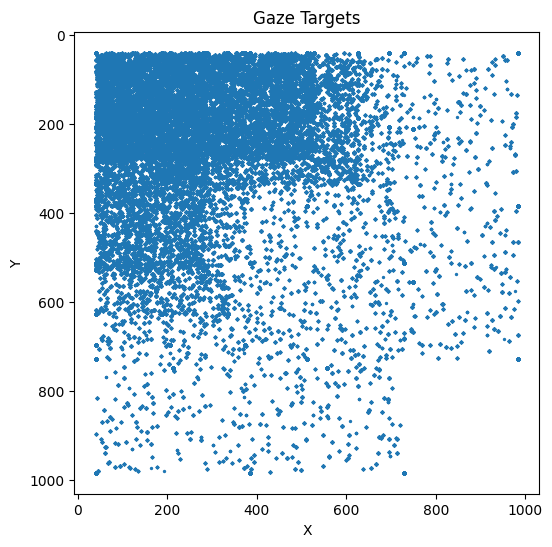

In [ ]:

labels_file = "dataset/labels.csv"

df = pd.read_csv(labels_file)

# print(df.head())
# print("Anzahl Samples:", len(df))

x = df["x"]
y = df["y"]

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Gaze Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()


X_min: 0.0390625	 X_max: 0.9609375
Y_min: 0.0	 Y_max: 1.0


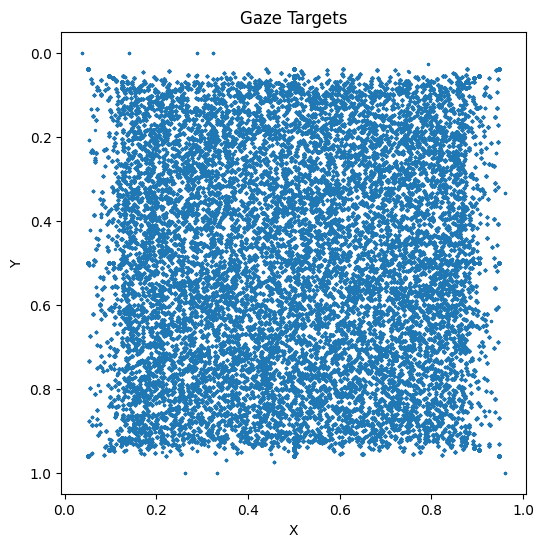

In [ ]:
# Normalize:
import numpy as np

norm_labels_file = './dataset/norm_labels.csv'
df2 = pd.read_csv(norm_labels_file)

x = df2["x_norm"]
y = df2["y_norm"]

print(f"X_min: {np.min(x)}\t X_max: {np.max(x)}")
print(f"Y_min: {np.min(y)}\t Y_max: {np.max(y)}")

plt.figure(figsize=(6,6))
plt.scatter(x, y, s=2)

plt.title("Gaze Targets")
plt.xlabel("X")
plt.ylabel("Y")

plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Konstant_Error:
#df2 = pd.read_csv(norm_labels_file)
x_true = df2["x_norm"].values
y_true = df2["y_norm"].values

x_const = np.mean(x_true)
y_const = np.mean(y_true)

# x_const = 0.5
# y_const = 0.5

print(f"x_const: {x_const}")
print(f"y_const: {y_const}")

pred_x_const = np.full_like(x_true, x_const)
pred_y_const = np.full_like(y_true, y_const)

const_errors = np.sqrt(
    (x_true - pred_x_const) ** 2 +
    (y_true - pred_y_const) ** 2
)


mae = np.mean(const_errors)
rmse = np.sqrt(np.mean(const_errors ** 2))
const_error_pct = 100 * np.round(rmse, 5)
const_diagonal_error_pct = 100 * np.round(rmse / np.sqrt(2), 5)

print("\nRandom Baseline:\n")
print(f"Constant_Mean_Absolute_Error: {mae}")
print(f"Constant_Mean_Squared_Error: {rmse}")
print(f"Constant_Mean_Squared_Error %: {const_error_pct} %")
print(f"Constant_Diagonal-Error %: {const_diagonal_error_pct} %")



# -------------------------------------------------------------------
# --------------- x- and y-constant: 0.0, 0.0 -----------------------
# -------------------------------------------------------------------

x_const = 0.0
y_const = 0.0

print(f"\nx_const: {x_const}")
print(f"y_const: {y_const}")

pred_x_const = np.full_like(x_true, x_const)
pred_y_const = np.full_like(y_true, y_const)

const_errors = np.sqrt(
    (x_true - pred_x_const) ** 2 +
    (y_true - pred_y_const) ** 2
)


mae = np.mean(const_errors)
rmse = np.sqrt(np.mean(const_errors ** 2))
const_error_pct = 100 * np.round(rmse, 5)
const_diagonal_error_pct = 100 * np.round(rmse / np.sqrt(2), 5)

print("\nRandom Baseline:\n")
print(f"Constant_Mean_Absolute_Error: {mae}")
print(f"Constant_Mean_Squared_Error: {rmse}")
print(f"Constant_Mean_Squared_Error %: {const_error_pct} %")
print(f"Constant_Diagonal-Error %: {const_diagonal_error_pct} %")


x_const: 0.49942676242613293
y_const: 0.4991836176653093

Random Baseline:

Constant_Mean_Absolute_Error: 0.3564706456624816
Constant_Mean_Squared_Error: 0.38530152103324283
Constant_Mean_Squared_Error %: 38.53 %
Constant_Diagonal-Error %: 27.245 %

x_const: 0.0
y_const: 0.0

Random Baseline:

Constant_Mean_Absolute_Error: 0.7575864425829059
Constant_Mean_Squared_Error: 0.8044057665652362
Constant_Mean_Squared_Error %: 80.441 %
Constant_Diagonal-Error %: 56.879999999999995 %


In [ ]:
# Random_Error:

x_max = 1.0
y_max = 1.0


pred_x_random = np.random.uniform(0, x_max, len(x_true))
pred_y_random = np.random.uniform(0, y_max, len(y_true))

random_errors = np.sqrt(
    (x_true - pred_x_random)**2 +
    (y_true - pred_y_random)**2
)

mae = np.mean(random_errors)
rmse = np.sqrt(np.mean(random_errors ** 2))
random_error_pct = 100 * np.round(rmse, 5)
random_diagonal_error_pct = 100 * np.round(rmse / np.sqrt(2), 5)

print("\nRandom Baseline:\n")
print(f"Random_Mean_Absolute_Error: {mae}")
print(f"Random_Mean_Squared_Error: {rmse}")
print(f"Random_Mean_Squared_Error %: {random_error_pct} %")
print(f"Random_Diagonal-Error %: {random_diagonal_error_pct} %")


Random Baseline:

Random_Mean_Absolute_Error: 0.5067053370671556
Random_Mean_Squared_Error: 0.5613016289153375
Random_Mean_Squared_Error %: 56.13 %
Random_Diagonal-Error %: 39.69 %


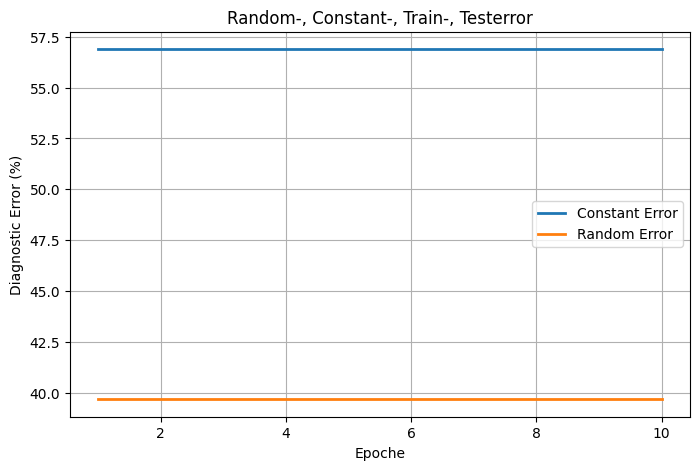

In [ ]:
# epochs = range(1, len(diag_test_error) + 1)
epochs = range(1, 11)
plt.figure(figsize=(8, 5))

# plt.plot(diag_train_error, label="Train", linewidth=2)
# plt.plot(diag_test_error, label="Test", linewidth=2)


plt.plot(epochs, [const_diagonal_error_pct] * len(epochs),
         label="Constant Error", linewidth=2)

plt.plot(epochs, [random_diagonal_error_pct] * len(epochs),
         label="Random Error", linewidth=2)

# plt.plot(epochs, diag_test_error, marker='o', linewidth=2)

plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")
plt.title("Random-, Constant-, Train-, Testerror")
plt.grid(True)
plt.legend()

plt.show()

---
# 5. Archiv: `personal_compare.ipynb`
Personalisierung: Session-Training (Original). Zellen: 34 (ohne leere).

In [ ]:
# 0: Lib
import numpy as np
import torch
import torch.nn as nn

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
from pathlib import Path
from torchvision import transforms
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from tqdm import tqdm
import time
import os
from datetime import datetime
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from torch.utils.data import DataLoader, Subset, random_split



In [ ]:

# 1: PersonalGazeDataset
# Lädt Bilder als PIL-Objekte und transformiert sie NICHT vorab.

class PersonalGazeDataset(Dataset):

    def __init__(
        self,
        root_dir,
        dataset_size=None,
        ##### orginal: ###############
        # dataset_name="norm_labels.csv"

        ##### clear: ###############
        dataset_name="norm_labels_clean.csv"
        
    ):
        self.root_dir = Path(root_dir)

        # CSV mit Bildnamen und normalisierten Blickkoordinaten
        csv_path = self.root_dir / dataset_name
        self.df = pd.read_csv(csv_path)

        # Prüfen, ob die erforderlichen Spalten existieren
        required_columns = {"frame", "x", "y"}

        if not required_columns.issubset(self.df.columns):
            raise ValueError(
                f"CSV muss diese Spalten enthalten: {required_columns}"
            )

        # Optional: Dataset für Tests verkleinern
        if dataset_size is not None:
            if dataset_size <= 0:
                raise ValueError("dataset_size muss > 0 sein.")

            self.df = self.df.iloc[:dataset_size].copy()

        if self.df.empty:
            raise ValueError("Das Dataset ist leer.")

        # Prüfen, ob Labels numerisch und gültig sind
        self.df[["x", "y"]] = self.df[["x", "y"]].apply(
            pd.to_numeric,
            errors="raise"
        )

        if not np.isfinite(self.df[["x", "y"]].to_numpy()).all():
            raise ValueError("Die Labels enthalten NaN oder Inf.")

    def __len__(self):
        return len(self.df)

    def get_raw_item(self, idx):
        """
        Gibt ein unverändertes PIL-Bild und die Ground-Truth zurück.
        Hier findet KEINE Transformation statt.
        """

        row = self.df.iloc[idx]

        image_path = self.root_dir / "images2" / str(row["frame"])

        # Image.open innerhalb von with sicher schließen
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        target = torch.tensor(
            [row["x"], row["y"]],
            dtype=torch.float32
        )

        return image, target

    def __getitem__(self, idx):
        """
        Standardzugriff ohne Transformation.
        Die Transformation wird im TransformSubset angewendet.
        """
        return self.get_raw_item(idx)

In [ ]:
# # 1: calss PersonalGazeDataset
# class PersonalGazeDataset(Dataset):

#     def __init__(
#         self,
#         root_dir,
#         transform=None,
#         dataset_size=None,
#         read_all4once=True
#     ):

#         self.root_dir = Path(root_dir)
#         self.transform = transform
#         self.read_all4once = read_all4once

#         self.df = pd.read_csv(
#             self.root_dir / "norm_labels.csv"
#             # self.root_dir 
#         )

#         self.dataset_size = (
#             dataset_size
#             if dataset_size is not None
#             else len(self.df)
#         )


#         if self.read_all4once:

#             # Form des transformierten Bildes bestimmen
#             img = Image.new("RGB", (500, 300))
#             out = transform(img)

#             self.images = torch.zeros(
#                 [self.dataset_size] + list(out.shape)
#             )

#             self.targets = torch.zeros(
#                 self.dataset_size,
#                 2
#             )


#             for idx in tqdm(range(self.dataset_size)):

#                 row = self.df.iloc[idx]

#                 image = Image.open(
#                     self.root_dir
#                     / "images"
#                     / row["frame"]
#                 ).convert("RGB")


#                 self.targets[idx] = torch.tensor(
#                     [
#                         row["x"],
#                         row["y"]
#                     ],
#                     dtype=torch.float32
#                 )


#                 if self.transform:
#                     self.images[idx] = self.transform(image)
#                 else:
#                     self.images[idx] = image

#     def __len__(self):

#         return self.dataset_size
        

#     def get_raw_item(self, idx):
    
#         image = self.images[idx].clone()
#         target = self.targets[idx].clone()
    
#         return image, target


#     # def __getitem__(self, idx):

#     #     if self.read_all4once:

#     #         return (
#     #             self.images[idx],
#     #             self.targets[idx]
#     #         )

#     #     row = self.df.iloc[idx]

#     #     image = Image.open(
#     #         self.root_dir
#     #         / "images"
#     #         / row["frame"]
#     #     ).convert("RGB")

#     #     target = torch.tensor(
#     #         [
#     #             row["x"],
#     #             row["y"]
#     #         ],
#     #         dtype=torch.float32
#     #     )

#     #     if self.transform:
#     #         image = self.transform(image)

#     #     return image, target

#     def __getitem__(self, idx):

#         image, target = self.get_raw_item(idx)
    
#         if self.transform:
#             image = self.transform(image)
    
#         return image, target

In [ ]:

class TransformSubset(Dataset):

    def __init__(
        self,
        dataset,
        indices,
        transform=None
    ):
        self.dataset = dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        original_idx = self.indices[idx]

        # PIL-Bild und Label aus dem Basis-Dataset
        image, target = self.dataset.get_raw_item(original_idx)

        # Transformation GENAU EINMAL anwenden
        if self.transform is not None:
            image = self.transform(image)

        return image, target

In [ ]:
# 2: func diagonal_error
def diagonal_errors(model, loader, device):

    # Evaluation-Modus
    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets_all = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)

    mae = mean_absolute_error(targets_all, predictions)

    rmse = np.sqrt(mean_squared_error(targets_all, predictions))

    diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:
def evaluate_model(model, loader, device):

    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    return targets, predictions, errors

In [ ]:
def sensitive_loss(preds, targets):

    x_total = 0.0

    for i in range(len(targets)):

        x = criterion_base(preds[i], targets[i])

        distance_from_center = (
            torch.abs(targets[i][0] - 0.5) +
            torch.abs(targets[i][1] - 0.5)
        )

        weight = 1.0 + distance_from_center

        x_total += x * weight

    return x_total / len(targets)

In [ ]:

def create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="random",
    seed=42,
    original_fps=60,
    frame_step=5,
    reset_interval=5,
    exclusion_time=0.5,
    test_dataset=None
):

    dataset_size = len(full_dataset)


    # ============================================================
    # A: Random Split
    # ============================================================

    if split_type == "random":

        generator = torch.Generator().manual_seed(seed)

        train_dataset, validat_dataset, test_dataset = random_split(
            full_dataset,
            [train_size, validat_size, test_size],
            generator=generator
        )



    # ============================================================
    # B1: Sequential Split
    # ============================================================

    elif split_type == "sequential":

        train_indices = list(
            range(0, train_size)
        )

        validat_indices = list(
            range(
                train_size,
                train_size + validat_size
            )
        )

        test_indices = list(
            range(
                train_size + validat_size,
                dataset_size
            )
        )

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )



    # ============================================================
    # B2: Test first, then Train + Validation
    # ============================================================

    elif split_type == "test_first_random":

        generator = torch.Generator().manual_seed(seed)

        train_valid_size = train_size + validat_size

        train_valid_dataset, test_dataset = random_split(
            full_dataset,
            [train_valid_size, test_size],
            generator=generator
        )

        train_dataset, validat_dataset = random_split(
            train_valid_dataset,
            [train_size, validat_size],
            generator=generator
        )


    # ============================================================
    # C: Video 1 = Train + Validation
    #    Video 2 = Test
    # ============================================================

    elif split_type == "different_videos":

        if test_dataset is None:

            raise ValueError(
                "Für split_type='different_videos' "
                "muss test_dataset angegeben werden."
            )


        # --------------------------------------------------------
        # Train + Validation aus Video 1
        # --------------------------------------------------------

        train_valid_size = train_size + validat_size

        if train_valid_size > len(full_dataset):

            raise ValueError(
                "Train + Validation sind größer als "
                "das Train/Validation-Video."
            )


        generator = torch.Generator().manual_seed(seed)


        train_dataset, validat_dataset = random_split(
            full_dataset,
            [train_size, validat_size],
            generator=generator
        )


        # --------------------------------------------------------
        # Test = komplettes zweites Video
        # --------------------------------------------------------

        test_dataset = test_dataset


        print("\n" + "=" * 60)
        print("DIFFERENT-VIDEO SPLIT")
        print("=" * 60)

        print(
            f"Train/Validation Video: "
            f"{len(full_dataset)} Samples"
        )

        print(
            f"Test Video: "
            f"{len(test_dataset)} Samples"
        )

        print("\nSplit:")

        print(
            f"Train:       {len(train_dataset)}"
        )

        print(
            f"Validation:  {len(validat_dataset)}"
        )

        print(
            f"Test:        {len(test_dataset)}"
        )

        print("=" * 60)


    # ============================================================
    # D: Reset-aware Random Split
    # ============================================================

    elif split_type == "reset_aware":

        # --------------------------------------------------------
        # Tatsächliche Samplingrate nach Frame-Subsampling
        # --------------------------------------------------------

        effective_fps = original_fps / frame_step


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples pro Reset-Intervall
        # --------------------------------------------------------

        reset_samples = int(
            round(reset_interval * effective_fps)
        )

        if reset_samples <= 0:
            raise ValueError(
                "reset_samples muss größer als 0 sein."
            )


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples, die nach jedem Reset
        # ausgeschlossen werden
        # --------------------------------------------------------

        exclusion_samples = int(
            round(exclusion_time * effective_fps)
        )


        print("\n" + "=" * 60)
        print("RESET-AWARE SPLIT")
        print("=" * 60)

        print(f"Original FPS:          {original_fps}")
        print(f"Frame Step:            {frame_step}")
        print(f"Effektive FPS:         {effective_fps}")

        print(f"\nReset alle:            {reset_interval} s")
        print(f"Reset-Samples:         {reset_samples}")

        print(f"\nAusschlusszeit:        {exclusion_time} s")
        print(f"Ausschluss-Samples:    {exclusion_samples}")


        # --------------------------------------------------------
        # Gültige und ausgeschlossene Indizes bestimmen
        # --------------------------------------------------------

        valid_indices = []
        excluded_indices = []


        for idx in range(dataset_size):

            position_in_reset = idx % reset_samples


            # Erste 0.5 Sekunden nach jedem Reset
            if position_in_reset < exclusion_samples:

                excluded_indices.append(idx)

            else:

                valid_indices.append(idx)


        print(f"\nGesamte Samples:       {dataset_size}")
        print(f"Ausgeschlossen:        {len(excluded_indices)}")
        print(f"Verwendbar:            {len(valid_indices)}")


        # --------------------------------------------------------
        # Prüfen, ob genügend Daten vorhanden sind
        # --------------------------------------------------------

        required_size = (
            train_size
            + validat_size
            + test_size
        )


        if required_size > len(valid_indices):

            raise ValueError(
                "\nNicht genügend gültige Samples!\n"
                f"Benötigt:   {required_size}\n"
                f"Verfügbar: {len(valid_indices)}"
            )


        # --------------------------------------------------------
        # Gültige Daten zufällig mischen
        # --------------------------------------------------------

        generator = torch.Generator().manual_seed(seed)

        permutation = torch.randperm(
            len(valid_indices),
            generator=generator
        ).tolist()


        shuffled_indices = [
            valid_indices[i]
            for i in permutation
        ]


        # --------------------------------------------------------
        # Train
        # --------------------------------------------------------

        train_indices = shuffled_indices[
            :train_size
        ]


        # --------------------------------------------------------
        # Validation
        # --------------------------------------------------------

        validat_indices = shuffled_indices[
            train_size:
            train_size + validat_size
        ]


        # --------------------------------------------------------
        # Test
        # --------------------------------------------------------

        test_indices = shuffled_indices[
            train_size + validat_size:
            train_size + validat_size + test_size
        ]


        # --------------------------------------------------------
        # Subsets
        # --------------------------------------------------------

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )


        print("\nSplit:")
        print(f"Train:                 {len(train_dataset)}")
        print(f"Validation:            {len(validat_dataset)}")
        print(f"Test:                  {len(test_dataset)}")

        print("=" * 60)


    else:

        raise ValueError(
            f"Unbekannter split_type: {split_type}"
        )


    return (
        train_dataset,
        validat_dataset,
        test_dataset
    )

In [ ]:
# # Transformationen:
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),

#     transforms.ColorJitter(
#         brightness=0.3,
#         contrast=0.3,
#         saturation=0.2
#     ),

#     transforms.RandomGrayscale(p=0.05),

#     transforms.GaussianBlur(
#         kernel_size=3,
#         sigma=(0.1, 1.5)
#     ),
#     transforms.ToTensor(),
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

In [ ]:
# ================================================
# Train Transform:
# ================================================

# Training: Augmentation + Normalisierung
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomGrayscale(p=0.05),

    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1, 1.5)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])



# ================================================
# Test/Validation Transform:
# ================================================

# Validation und Test: nur Resize + Normalisierung
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# Hypoparameter:

name_dataset_type = ['norm_labels_clean.csv','norm_labels.csv', 'labels.csv']
dataset_size_type = [[10000, 2000], [1000, 200]]
dataset_type = ["norm_subject", "norm_random"]
batch_size_type = [32, 64, 128]
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
epochs_num = [1, 2, 10, 25, 500]



optimizer_name = "AdamW"

# ##########################################################################
# 1.type Dataset: 'norm_labels.csv' or 'labels.csv'
dataset_name = name_dataset_type[0]                       # norm_labels_clean.csv
# dataset_name = name_dataset_type[1]                       # norm_labels.csv
# dataset_name = name_dataset_type[2]                       # labels.csv
print(f"\n dataset_name: \t\t {dataset_name}")


# 2.dataset_sizt: (10000 & 2000) or (1000, 200)
# def_dataset_size = dataset_size_type[0]                   # [10000, 2000]
def_dataset_size = dataset_size_type[1]                   # [1000, 200]

print(f"\n def_dataset_size: \n train: \t\t {def_dataset_size[0]} \n test: \t\t\t {def_dataset_size[1]}")


# 3.batch_size: '32', '64' or '128'
batch_size = batch_size_type[0]                           # 32
# batch_Size = batch_size_type[1]                           # 64
# batch_Size = batch_size_type[2]                           # 128
print(f"\n batch_Size: \t\t {batch_size}")


# 4.type of dataset-split: "norm_subject_independed" or "norm_random"
# load model:
dataset_type = ["norm_subject", "norm_random"]

# load model:
#============================================================================
#                 normalize_subject_indipended 
#============================================================================
def_dataset = dataset_type[0]                             # norm_subject
# saved_model = "./models/best_models/best_ResNet_Sigmoid_norm_subject.path"


#============================================================================
#                 normalize_random
#============================================================================
# # def_dataset = dataset_type[1]                             # norm_random
# saved_model = "./models/best_models/best_ResNet_Sigmoid_norm_random.path"

print(f"\n def_dataset: \t\t {def_dataset}")

# load model:



# 5.learning_rate: '1e-3', '1e-4', '1e-5' or '1e-6'
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
# learning_rate = lr_type[0]                                # 1e-3
learning_rate = lr_type[1]                                # 1e-4
# learning_rate = lr_type[2]                                # 1e-5
# learning_rate = lr_type[3]                                # 1e-6
print(f"\n learning_rate: \t {learning_rate}")


# 6.number of epochs: 1, 2, 10, 25 or 500
epochs = epochs_num[-1]                                   # 500
print(f"\n epochs: \t\t {epochs}")




weight_Decay = 1e-5

active_func = None

patience = 3               # after 3 Epochen without Optimierung has to stop training
print(f"\n patience: \t\t {patience}")





# session = "03"

# best_model_name = "./models/ResNet_best_optim-model_norm_subject_1000-200.path"

# last best model: with Sigmoid
# saved_model = "./models/best_models/best_ResNet_Sigmoid.path"


# load model:



best_saved_model = f"./models/best_models/best_ResNet_Sigmoid_{def_dataset}.path"
print(f"\n model_name: \t\t {best_saved_model}")


#============================================================================
#                 normalize_subject_indipended 
#============================================================================
# saved_model1 = f"./models/best_models/best_ResNet_Sigmoid_{def_dataset}.path"

#============================================================================
#                 normalize_random
#============================================================================
# saved_model2 = f"./models/best_models/best_ResNet_Sigmoid_{def_dataset}.path"



 dataset_name: 		 norm_labels_clean.csv

 def_dataset_size: 
 train: 		 1000 
 test: 			 200

 batch_Size: 		 32

 def_dataset: 		 norm_subject

 learning_rate: 	 0.0001

 epochs: 		 500

 patience: 		 3

 model_name: 		 ./models/best_models/best_ResNet_Sigmoid_norm_subject.path


In [ ]:
# 9: ResNet18 (Pretrainiertes Modell):
# Load:
def reset_model(act=None):
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    model_name = model.__class__.__name__
    
    # ---------------------------------------
    # Activation function for the last layer
    # ---------------------------------------
    if act == "Sigmoid":
        last_layer = nn.Sigmoid()

    elif act == "Gaussian":
        last_layer = GaussianActivation(sigma=1.0)

    elif act == "ReLU":
        last_layer = nn.ReLU()

    elif act == "None":
        last_layer = nn.Identity()

    else:
        raise ValueError(
            f"Unknown activation function: {act}"
        )

    # ---------------------------------------
    # Replace original ResNet FC
    # ---------------------------------------
    model.fc = nn.Sequential(
        nn.Linear(
            model.fc.in_features,
            512
        ),
        nn.ReLU(),

        nn.Linear(
            512,
            256
        ),
        nn.ReLU(),

        nn.Dropout(0.2),

        nn.Linear(
            256,
            128
        ),
        nn.ReLU(),

        nn.Linear(
            128,
            2
        ),

        # Last activation
        last_layer
    )

    return model, model_name

In [ ]:
# 10: GPU or CPU
# check:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

In [ ]:
norm_labels_files = []
root_folder = Path("./personalization/")


for folder in sorted(root_folder.iterdir()):

    if folder.is_dir():

        norm_file = folder / "norm_labels.csv"


        if not norm_file.exists():

            # print(f"Fehlt: {norm_file.resolve()}\n\n")
            continue

        else:

            norm_labels_files.append(norm_file.as_posix())


for n in norm_labels_files:
    print(f"norm_file: {n}")

print(f"\n Anzahl der norm_files: {len(norm_labels_files)}\n")


sessions = []

for i in range(len(norm_labels_files)):
    path = str(norm_labels_files[i])
    session = path.split("/")[1]
    # print(f"Session: {session}")
    sessions.append(session)

print(f"Sessions: {sessions}")

print(f"\n Anzahl der Sessions: {len(sessions)}")

norm_file: personalization/01/norm_labels.csv
norm_file: personalization/02/norm_labels.csv
norm_file: personalization/03/norm_labels.csv
norm_file: personalization/04/norm_labels.csv
norm_file: personalization/05/norm_labels.csv
norm_file: personalization/06/norm_labels.csv
norm_file: personalization/07/norm_labels.csv
norm_file: personalization/08/norm_labels.csv
norm_file: personalization/09/norm_labels.csv
norm_file: personalization/10/norm_labels.csv
norm_file: personalization/11/norm_labels.csv
norm_file: personalization/12/norm_labels.csv
norm_file: personalization/13/norm_labels.csv
norm_file: personalization/14/norm_labels.csv
norm_file: personalization/15/norm_labels.csv
norm_file: personalization/16/norm_labels.csv
norm_file: personalization/17/norm_labels.csv
norm_file: personalization/18/norm_labels.csv
norm_file: personalization/19/norm_labels.csv
norm_file: personalization/20/norm_labels.csv
norm_file: personalization/21/norm_labels.csv
norm_file: personalization/22/norm

In [ ]:

# ============================================================
# Smoke Test: Dataset und DataLoader prüfen
# ============================================================
session = '25'
print(f"\nSession: {session}")

dirs = f"personalization/{session}"

csv_path = Path(dirs) / "norm_labels_clean.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Fehlt: {csv_path.resolve()}")

# print(f"csv_pfad: {csv_path}")

df = pd.read_csv(csv_path)


dataset_size = len(df)

print(f"Gesamte Daten: {dataset_size}")


# ============================================================
# Full Dataset
# ============================================================

# full_dataset = PersonalGazeDataset(
#     root_dir=dirs,
#     transform=None,
# )

full_dataset = PersonalGazeDataset(
    root_dir=dirs,
    dataset_name="norm_labels_clean.csv"
)

dataset_size = len(full_dataset)

print(f"Dataset Size: {dataset_size}")



# 1. Rohbild muss ein PIL-Bild sein
raw_image, raw_target = full_dataset.get_raw_item(0)

assert isinstance(raw_image, Image.Image), (
    f"Erwartet PIL.Image, erhalten: {type(raw_image)}"
)

print("Raw image type:", type(raw_image))
print("Raw target:", raw_target)


# ============================================================
# 1. Reproduzierbare Random-Split-Indizes
# ============================================================

split_seed = 42

generator = torch.Generator().manual_seed(split_seed)

indices = torch.randperm(
    dataset_size,
    generator=generator
).tolist()

# ============================================================
# Split Sizes
# ============================================================

train_size = int(dataset_size * 0.70)
validat_size = int(dataset_size * 0.15)

test_size = (
    dataset_size
    - train_size
    - validat_size
)

train_indices = indices[:train_size]

validat_indices = indices[
    train_size:train_size + validat_size
]

test_indices = indices[
    train_size + validat_size:
]


# ============================================================
# 2. Subsets mit getrennten Transformationen
# ============================================================

train_dataset = TransformSubset(
    full_dataset,
    train_indices,
    transform=train_transform
)

validat_dataset = TransformSubset(
    full_dataset,
    validat_indices,
    transform=eval_transform
)

test_dataset = TransformSubset(
    full_dataset,
    test_indices,
    transform=eval_transform
)


# ============================================================
# 3. Kontrolle der Dataset-Größen
# ============================================================

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")


# ============================================================
# 4. DataLoader
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=8,
    persistent_workers=True
)



validat_loader = DataLoader(
    validat_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)



test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)

##########################################################################
##########################################################################
train_eval_dataset = TransformSubset(
    full_dataset,
    train_indices,
    transform=eval_transform
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)



# 2. Transformiertes Bild muss ein Tensor sein
train_image, train_target = train_dataset[0]

assert isinstance(train_image, torch.Tensor)

assert train_image.shape == (3, 224, 224)

assert train_target.shape == (2,)

print("Train image shape:", train_image.shape)
print("Train target:", train_target)


# 3. Validation und Test ebenfalls prüfen
val_image, val_target = validat_dataset[0]
test_image, test_target = test_dataset[0]

assert isinstance(val_image, torch.Tensor)
assert isinstance(test_image, torch.Tensor)

assert val_image.shape == (3, 224, 224)
assert test_image.shape == (3, 224, 224)


# 4. Einen echten Batch laden
images, targets = next(iter(train_loader))

assert images.ndim == 4
assert images.shape[1:] == (3, 224, 224)

assert targets.ndim == 2
assert targets.shape[1] == 2

print("Batch images:", images.shape)
print("Batch targets:", targets.shape)

print("\nSmoke Test erfolgreich!")


Session: 25
Gesamte Daten: 720
Dataset Size: 720
Raw image type: <class 'PIL.Image.Image'>
Raw target: tensor([0.0944, 0.9557])
Train:      503
Validation: 108
Test:       109
Train image shape: torch.Size([3, 224, 224])
Train target: tensor([0.1023, 0.4537])
Batch images: torch.Size([32, 3, 224, 224])
Batch targets: torch.Size([32, 2])

Smoke Test erfolgreich!


In [ ]:

results = {}

# sess = ['01', '02']
# sess = ['01']

# for s in sess: 
for s in sessions:

    session = s

    print("\n" + "=" * 70)
    print(f"{def_dataset.upper()} Session: {session.upper()}")
    print("=" * 70)
    
    dirs = f"personalization/{session}"
    
    csv_path = Path(dirs) / "norm_labels.csv"
    
    if not csv_path.exists():
        raise FileNotFoundError(f"Fehlt: {csv_path.resolve()}")
    
    print(f"csv_pfad: {csv_path}")
    
    df = pd.read_csv(csv_path)
    
    dataset_size = len(df)
    
    print(f"Gesamte Daten: {dataset_size}")
    
    
    # ============================================================
    # Full Dataset
    # ============================================================
    
    # full_dataset = PersonalGazeDataset(
    #     root_dir=dirs,
    #     transform=None,
    # )

    full_dataset = PersonalGazeDataset(
        root_dir=dirs,
        dataset_name="norm_labels.csv"
    )

    dataset_size = len(full_dataset)

    print(f"Dataset Size: {dataset_size}")
    

    # ============================================================
    # 1. Reproduzierbare Random-Split-Indizes
    # ============================================================

    split_seed = 42

    generator = torch.Generator().manual_seed(split_seed)

    indices = torch.randperm(
        dataset_size,
        generator=generator
    ).tolist()

    # ============================================================
    # Split Sizes
    # ============================================================
    
    train_size = int(dataset_size * 0.70)
    validat_size = int(dataset_size * 0.15)
    
    test_size = (
        dataset_size
        - train_size
        - validat_size
    )

    train_indices = indices[:train_size]

    validat_indices = indices[
        train_size:train_size + validat_size
    ]

    test_indices = indices[
        train_size + validat_size:
    ]


    # ============================================================
    # 2. Subsets mit getrennten Transformationen
    # ============================================================

    train_dataset = TransformSubset(
        full_dataset,
        train_indices,
        transform=train_transform
    )

    validat_dataset = TransformSubset(
        full_dataset,
        validat_indices,
        transform=eval_transform
    )

    test_dataset = TransformSubset(
        full_dataset,
        test_indices,
        transform=eval_transform
    )


    # ============================================================
    # 3. Kontrolle der Dataset-Größen
    # ============================================================

    print(f"Train:      {len(train_dataset)}")
    print(f"Validation: {len(validat_dataset)}")
    print(f"Test:       {len(test_dataset)}")


    # ============================================================
    # 4. DataLoader
    # ============================================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=8,
        persistent_workers=True
    )
    
    
    
    validat_loader = DataLoader(
        validat_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )
    
    
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )

##########################################################################
##########################################################################
    train_eval_dataset = TransformSubset(
        full_dataset,
        train_indices,
        transform=eval_transform
    )

    train_eval_loader = DataLoader(
        train_eval_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )
##########################################################################
##########################################################################




    ##########################################################################
    ##########################################################################

    # ========================================================================
    # Data Loading Strategies:
    # ========================================================================

    # # A1: Random
    # #split = "a_random"
    # train_dataset, validat_dataset, test_dataset = create_splits(
    #     full_dataset,
    #     train_size,
    #     validat_size,
    #     test_size,
    #     split_type="random",
    #     seed=42
    # )
    
    
    # print(f"Train:      {len(train_dataset)}")
    # print(f"Validation: {len(validat_dataset)}")
    # print(f"Test:       {len(test_dataset)}")



    
    
    
    # # Loader:
    # train_loader = DataLoader(
    #     train_dataset,
    #     batch_size=train_size,
    #     shuffle=True,
    #     num_workers=8,
    #     persistent_workers=True
    # )
    
    
    
    # validat_loader = DataLoader(
    #     validat_dataset,
    #     batch_size=validat_size,
    #     shuffle=False,
    #     num_workers=8,
    #     persistent_workers=True
    # )
    
    
    
    # test_loader = DataLoader(
    #     test_dataset,
    #     batch_size=test_size,
    #     shuffle=False,
    #     num_workers=8,
    #     persistent_workers=True
    # )

    ##########################################################################
    ##########################################################################


    # ============================================================
    # Training:
    # ============================================================
    
    # acts = ['Sigmoid', 'Gaussian', 'ReLU', 'None']
    act = "Sigmoid"
    
    trainable_layers = "FC only"
    
    
    print("\n" + "=" * 70)
    print(f"{def_dataset} EXPERIMENT: ")
    
    
    print(f"\t Dataset Type:         {dataset_name}")
    print(f"\t Dataset Split:        {def_dataset}")
    print(f"\t Train Size:           {def_dataset_size[0]}")
    print(f"\t Test Size:            {def_dataset_size[1]}")
    print(f"\t Batch Size:           {batch_size}")
    print(f"\t Learning Rate:        {learning_rate}")
    print(f"\t Activation:           {act}")
    print(f"\t Trainable Layers:     {trainable_layers}")
    print(f"\t Loaded_Model:         {best_saved_model}")
    print(f"\t Max_Epochs:           {epochs}")
    print(f"\t Patience:             {patience}")
    print("=" * 70)
    
    
    
    
    if globals().get("bas_const_err") is None:
        bas_const_err = 27.245
    
    if globals().get("bas_rand_err") is None:
        bas_rand_err = 38.961
    
    
    
    # --------------------------------------------------------
    # Start total training timer
    # --------------------------------------------------------
    
    train_start = time.perf_counter()
    
    
    
    epochs = epochs
    
    
    
    model_output = './models/best_models/personal/'
    model_dir= Path(model_output)
    
    if not os.path.exists(model_dir):
        model_dir.mkdir(
            parents=True,
            exist_ok=True
        )
    
    
    diagrams_output = './results/best_diagrams/personal'
    diagrams_dir= Path(diagrams_output)
    
    if not os.path.exists(diagrams_dir):
        diagrams_dir.mkdir(
            parents=True,
            exist_ok=True
        )
    
    
    
    # ============================================================
    # Store train and test error curves
    # ============================================================
    
    # train_errors = []
    # test_errors = []
    
    best_error = float("inf")
    
    patience_counter = 0                        # Number Epochen without Optimierung
    improvements = 0                            # Number Epochen with Optimierung
    best_epoch = 0
    
    diag_train_errors = []
    diag_validat_errors  = []
    
    act_time_epochs = {}
    
    
    
    criterion = nn.L1Loss()
    
    criterion_base = nn.L1Loss()
    
    # --------------------------------------------------------
    # Reset model
    # --------------------------------------------------------
    
    model, model_name = reset_model(act=act)

    checkpoint = torch.load(
        # checkpoint_path,
        best_saved_model,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint)
    
    model.to(device)
    
    # --------------------------------------------------------
    # Freeze all parameters
    # --------------------------------------------------------
    
    for param in model.parameters():
        param.requires_grad = False
    
    
    # --------------------------------------------------------
    # Unfreeze ONLY FC
    # --------------------------------------------------------
    
    for param in model.layer4.parameters():
        param.requires_grad=False
    
    
    for param in model.fc.parameters():
        param.requires_grad = True
    
    
    
    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=weight_Decay
    )
    
    
    
    
    
    print('\n ',"=#=" * 25)
    print(f"\t\t Session: {session}")
    print(' ',"=#=" * 25)
    
    
    # ============================================================
    # Initial evaluation before training
    # ============================================================
    print("\n\t Initial evaluation: \n")
    
    model.eval()
    
    print("\n Train_error:")
    # train_mae, train_rmse, train_diag_pct = diagonal_errors(
    #     model,
    #     train_loader,
    #     device
    # )

    train_mae, train_rmse, train_diag_pct = diagonal_errors(
        model,
        train_eval_loader,
        device
    )
    
    train_diag_pct = np.round(float(train_diag_pct), 4)
    # diag_train_errors.append(train_diag_pct)
    
    
    
    
    print("\n Validat_error:")
    validat_mae, validat_rmse, validat_diag_pct = diagonal_errors(
        model,
        validat_loader,
        device
    )
    
    validat_diag_pct = np.round(float(validat_diag_pct), 4)
    # diag_validat_errors.append(validat_diag_pct)
    
    
    
    print(
        f"Epoch 0 | "
        f"Train error: {train_diag_pct:.4f}% | "
        f"Validat error: {validat_diag_pct:.4f}%"
    )
    
    
    
    # Initial best test error
    if validat_diag_pct < best_error:  
        best_error = validat_diag_pct
        best_epoch = 0
    
    
    # save the better Modell
    torch.save(
        model.state_dict(),
        f"{model_output}"
        f"best_{model_name}_{act}_{def_dataset}_{session}.path"
    )
    
    # ============================================================
    # Training
    # ============================================================
    
    print("\n\n\t Training: \n")
    
    for epoch in range(epochs):
    
        epoch_start = time.perf_counter()
    
        model.train()
    
        running_loss = 0.0
    
    
        loop = tqdm(
            train_loader,
            desc=f"Normalized | Epoch {epoch + 1}"
        )
        
    
        for images, targets in loop:
            
            images = images.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()
            
            preds = model(images)
    
            ################################
            # Loss 1:
            ################################
            
            # loss = criterion(
            #     preds,
            #     targets
            # )
    
    
            
            ################################
            # Loss 2: 
            ################################
            
            loss = sensitive_loss(
                preds,
                targets
            )
            
            ################################
    
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
            loop.set_postfix(
                loss=loss.item()
            )
    
        
    
        # ========================================================
        # Evaluation after epoch
        # ========================================================
    
        model.eval()
    
    
        # --------------------------------------------------------
        # Train error
        # --------------------------------------------------------
        print("\n Train:")
        # train_mae, train_rmse, train_diag_pct = diagonal_errors(
        #     model,
        #     train_loader,
        #     device
        # )

        train_mae, train_rmse, train_diag_pct = diagonal_errors(
            model,
            train_eval_loader,
            device
        ) 
   
        
    
        train_diag_pct = np.round(float(train_diag_pct), 4)
        diag_train_errors.append(train_diag_pct)
    
    
        # --------------------------------------------------------
        # Test error
        # --------------------------------------------------------
        print("\n Validat:")
        validat_mae, validat_rmse, validat_diag_pct = diagonal_errors(
            model,
            validat_loader,
            device
        )
    
        validat_diag_pct = np.round(float(validat_diag_pct), 4)
        diag_validat_errors.append(validat_diag_pct)
    
    
        # --------------------------------------------------
        # Early Stopping
        # --------------------------------------------------
    
        if validat_diag_pct < best_error:
    
            best_error = validat_diag_pct
    
            best_epoch = epoch + 1
    
            patience_counter = 0
            improvements += 1
    
            print(
                f"\nValidat-Diagonal-Error: "
                f"{validat_diag_pct:.4f}% | "
                f"Improvement: {improvements}"
            )
    
            # save the better Modell
            torch.save(
                model.state_dict(),
                f"{model_output}"
                f"best_{model_name}_{act}_{def_dataset}_{session}.path"
            )
        
    
        else:
    
            # without imporovement
            patience_counter += 1
    
            print(
                f"\nPatience: "
                f"{patience_counter}/{patience}"
            )
    
    
            if patience_counter >= patience:
    
                print(
                    f"\nEarly Stopping after "
                    f"{epoch + 1} epochs."
                )
                print(
                    f"Imporovments totally: {improvements}"
                )
    
                break
        
    
        # ========================================================
        # Epoch information
        # ========================================================
    
        epoch_end = time.perf_counter()
    
        epoch_time = epoch_end - epoch_start
    
    
        print(
            f"\n[{datetime.now().strftime('%H:%M:%S')}] "
            f"Epoch {epoch + 1}: | " 
            f"{epoch_time:.2f} s | "
            f"Loss: {running_loss / len(train_loader):.4f} | "
            f"Train-Error: {train_diag_pct:.4f}% | "
            f"Test-Error: {validat_diag_pct:.4f}%"
        )
    
        torch.save(
            model.state_dict(),
            f"{model_output}"
            f"last_{model_name}_{act}_{def_dataset}_{session}.path"
        )
    
    
    
    # ============================================================
    # Total running time
    # ============================================================
    
    train_end = time.perf_counter()
    
    elapsed_running_time = train_end - train_start
    
    elapsed_minutes = elapsed_running_time / 60
    
    print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} s")
    print(f"totll running-tiems (min): {elapsed_minutes:.2f} min\n")
    
    # ============================================================
    # Number of completed epochs
    # ============================================================
    
    epochs_completed = len(diag_validat_errors)
    
    
    # # ============================================================
    # # Store normalized-dataset results
    # # ============================================================
    
    results[session] = {
        "split_type" : def_dataset,
        "train_errors": diag_train_errors,
        "validat_errors": diag_validat_errors,
        "best_validat_error": best_error,
        "running_time_minutes": elapsed_minutes,
        "epochs": epochs_completed,
        "best_epoch": best_epoch,
        "improvements": improvements
    }
    
    
    # ========================================================
    # Print result for this learning rate
    # ========================================================
    
    print("\n" + "=" * 70)
    print(f"{def_dataset.upper()} Session: {session.upper()} RESULTS: ")
    print("=" * 70)
    
    print(
        f"Best Validation Error:   {results[session]['best_validat_error']:.4f}%"
    )
    print(
        f"Running Time:            {results[session]['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                  {results[session]['epochs']}"
    )
    print(
        f"Best Epoch:              {results[session]['best_epoch']}"
    )
    print(
        f"Improvements:            {results[session]['improvements']}"
    )
    print("=" * 70)
    
    
    # ---------- Evaluation ----------
    
    # norm_subject:
    # saved_model1 = "./models/best_models/best_ResNet_Sigmoid_norm_subject.path"
    # saved_model1 = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}.path"
    
    # norm_random:
    # saved_model2 = "./models/best_models/best_ResNet_Sigmoid_norm_random.path"
    # saved_model2 = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}.path"

    test_saved_model = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}.path"

    checkpoint = torch.load(
        test_saved_model,
        map_location=device
    )
    
    model.load_state_dict(checkpoint)
    
    model.to(device)
    
    model.eval()
    
    
    print(f"Test:\n")
    test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
    
    test_diag_pct = np.round(float(test_diag_pct), 4)
    
    print(
            f"Final diagonal Test Error= {test_diag_pct:.4f}% "
        )

    results[session]["test_error_at_best_validation"] = test_diag_pct





NORM_RANDOM Session: 01
csv_pfad: personalization/01/norm_labels.csv
Gesamte Daten: 498
Dataset Size: 498
Train:      348
Validation: 74
Test:       76

norm_random EXPERIMENT: 
	Dataset_type:         norm_labels.csv
	Dataset split:        norm_random
	Train size:           1000
	Test size:            200
	Batch size:           32
	Learning rate:        0.0001
	Activation:           Sigmoid
	Trainable layers:     FC only
	Max_Epochs:           500
	Patience:             3

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
		 Session: 01
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Initial evaluation: 


 Train_error:
MAE : 0.2571 	 RMSE: 0.2964 
Diagonal-Error %: 20.9575 %

 Validat_error:
MAE : 0.2376 	 RMSE: 0.2778 
Diagonal-Error %: 19.6418 %
Epoch 0 | Train error: 20.9575% | Validat error: 19.6418%


	 Training: 



Normalized | Epoch 1: 100%|██████████████████████████████████████████████████████████| 11/11 [00:15<00:00,  1.39s/it, loss=0.254]



 Train:
MAE : 0.2506 	 RMSE: 0.2889 
Diagonal-Error %: 20.4269 %

 Validat:
MAE : 0.2288 	 RMSE: 0.2693 
Diagonal-Error %: 19.0437 %

Validat-Diagonal-Error: 19.0437% | Improvement: 1

[13:49:52] Epoch 1: | 34.83 s | Loss: 0.2546 | Train-Error: 20.4269% | Test-Error: 19.0437%


Normalized | Epoch 2: 100%|██████████████████████████████████████████████████████████| 11/11 [00:18<00:00,  1.67s/it, loss=0.227]



 Train:
MAE : 0.2403 	 RMSE: 0.2781 
Diagonal-Error %: 19.6670 %

 Validat:
MAE : 0.2197 	 RMSE: 0.2586 
Diagonal-Error %: 18.2882 %

Validat-Diagonal-Error: 18.2882% | Improvement: 2

[13:50:26] Epoch 2: | 33.67 s | Loss: 0.2474 | Train-Error: 19.6670% | Test-Error: 18.2882%


...


 Train:
MAE : 0.2814 	 RMSE: 0.3243 
Diagonal-Error %: 22.9292 %

 Validat:
MAE : 0.3023 	 RMSE: 0.3456 
Diagonal-Error %: 24.4368 %

Patience: 1/3

[16:59:32] Epoch 6: | 75.81 s | Loss: 0.2870 | Train-Error: 22.9292% | Test-Error: 24.4368%


Normalized | Epoch 7: 100%|██████████████████████████████████████████████████████████| 25/25 [00:36<00:00,  1.45s/it, loss=0.288]



 Train:
MAE : 0.2874 	 RMSE: 0.3475 
Diagonal-Error %: 24.5755 %

 Validat:
MAE : 0.3189 	 RMSE: 0.3778 
Diagonal-Error %: 26.7162 %

Patience: 2/3

[17:00:48] Epoch 7: | 76.33 s | Loss: 0.2753 | Train-Error: 24.5754% | Test-Error: 26.7162%


Normalized | Epoch 8: 100%|██████████████████████████████████████████████████████████| 25/25 [00:37<00:00,  1.48s/it, loss=0.355]



 Train:
MAE : 0.2802 	 RMSE: 0.3449 
Diagonal-Error %: 24.3865 %

 Validat:
MAE : 0.3121 	 RMSE: 0.3754 
Diagonal-Error %: 26.5451 %

Patience: 3/3

Early Stopping after 8 epochs.
Imporovments totally: 4

totll running-tiems (s): 665.94 s
totll running-tiems (min): 11.10 min


NORM_RANDOM Session: 18 RESULTS: 
Best Validation Error:   24.2063%
Running Time:            11.10 min
Epochs:                  8
Best Epoch:              5
Improvements:            4
Test:

MAE : 0.3010 	 RMSE: 0.3394 
Diagonal-Error %: 23.9968 %
Final diagonal Test Error= 23.9968% 


In [ ]:
for session, values in results.items():

    #  print(
    # f" Sessions: {session} |"
    # f" epochs: {values['epochs']} Epochen |"
    # f" running_time: {values['time_minutes']:.2f} min |"
    # f" improvements: {values['improvements']} Epochen |"
    # f" best_test_error: {values['best_test_error']:.4f} % |"
    # )

    print("\n" + "=" * 40)
    print(f"{def_dataset.upper()} Session: {session.upper()} RESULTS: ")
    print("=" * 40)
    
    print(
        f"Best Validation Error:                  {results[session]['best_validat_error']:.4f}%"
    )
    print(
        f"Tetst-Error at best validation:         {results[session]['test_error_at_best_validation']:.4f}%"
    )
    print(
        f"Running Time:                           {results[session]['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                                 {results[session]['epochs']}"
    )
    print(
        f"Best Epoch:                             {results[session]['best_epoch']}"
    )
    print(
        f"Improvements:                           {results[session]['improvements']}"
    )
    print("=" * 30)
    print("\n")


NORM_RANDOM Session: 01 RESULTS: 
Best Validation Error:   9.1266%
Best Test Error:         10.2422%
Running Time:            25.67 min
Epochs:                  47
Best Epoch:              44
Improvements:            29



NORM_RANDOM Session: 02 RESULTS: 
Best Validation Error:   9.4785%
Best Test Error:         9.1323%
Running Time:            7.82 min
Epochs:                  15
Best Epoch:              12
Improvements:            11



NORM_RANDOM Session: 03 RESULTS: 
Best Validation Error:   14.5845%
Best Test Error:         15.5043%
Running Time:            6.86 min
Epochs:                  12
Best Epoch:              9
Improvements:            7



NORM_RANDOM Session: 04 RESULTS: 
Best Validation Error:   12.4310%
Best Test Error:         11.1467%
Running Time:            8.64 min
Epochs:                  13
Best Epoch:              10
Improvements:            9



NORM_RANDOM Session: 05 RESULTS: 
Best Validation Error:   18.5911%
Best Test Error:         15.5761%
Running Ti

In [ ]:
# NORM_SUBJECT

========================================
NORM_SUBJECT Session: 01 RESULTS: 
========================================
Best Validation Error:   10.7186%
Best Test Error:         11.4291%
Running Time:            13.35 min
Epochs:                  20
Best Epoch:              17
Improvements:            14
==============================



========================================
NORM_SUBJECT Session: 02 RESULTS: 
========================================
Best Validation Error:   9.1110%
Best Test Error:         8.5165%
Running Time:            10.28 min
Epochs:                  16
Best Epoch:              13
Improvements:            12
==============================



========================================
NORM_SUBJECT Session: 03 RESULTS: 
========================================
Best Validation Error:   11.6067%
Best Test Error:         12.1000%
Running Time:            14.92 min
Epochs:                  25
Best Epoch:              22
Improvements:            17
==============================



========================================
NORM_SUBJECT Session: 04 RESULTS: 
========================================
Best Validation Error:   12.4003%
Best Test Error:         10.8391%
Running Time:            10.44 min
Epochs:                  16
Best Epoch:              13
Improvements:            11
==============================



========================================
NORM_SUBJECT Session: 05 RESULTS: 
========================================
Best Validation Error:   17.1120%
Best Test Error:         12.7782%
Running Time:            7.52 min
Epochs:                  30
Best Epoch:              27
Improvements:            22
==============================



========================================
NORM_SUBJECT Session: 06 RESULTS: 
========================================
Best Validation Error:   13.1890%
Best Test Error:         10.4886%
Running Time:            8.97 min
Epochs:                  30
Best Epoch:              27
Improvements:            23
==============================



========================================
NORM_SUBJECT Session: 07 RESULTS: 
========================================
Best Validation Error:   17.4645%
Best Test Error:         15.4393%
Running Time:            5.52 min
Epochs:                  25
Best Epoch:              22
Improvements:            18
==============================



========================================
NORM_SUBJECT Session: 08 RESULTS: 
========================================
Best Validation Error:   18.7970%
Best Test Error:         19.5001%
Running Time:            1.02 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 09 RESULTS: 
========================================
Best Validation Error:   19.3284%
Best Test Error:         18.5149%
Running Time:            1.85 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_SUBJECT Session: 10 RESULTS: 
========================================
Best Validation Error:   20.9562%
Best Test Error:         21.4255%
Running Time:            13.20 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_SUBJECT Session: 11 RESULTS: 
========================================
Best Validation Error:   24.0390%
Best Test Error:         25.5719%
Running Time:            4.31 min
Epochs:                  5
Best Epoch:              2
Improvements:            2
==============================



========================================
NORM_SUBJECT Session: 12 RESULTS: 
========================================
Best Validation Error:   21.0522%
Best Test Error:         20.4153%
Running Time:            39.41 min
Epochs:                  19
Best Epoch:              16
Improvements:            12
==============================



========================================
NORM_SUBJECT Session: 13 RESULTS: 
========================================
Best Validation Error:   20.3144%
Best Test Error:         20.1779%
Running Time:            11.56 min
Epochs:                  10
Best Epoch:              7
Improvements:            4
==============================



========================================
NORM_SUBJECT Session: 14 RESULTS: 
========================================
Best Validation Error:   22.5814%
Best Test Error:         22.4166%
Running Time:            3.12 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 15 RESULTS: 
========================================
Best Validation Error:   19.8634%
Best Test Error:         20.6428%
Running Time:            16.59 min
Epochs:                  15
Best Epoch:              12
Improvements:            8
==============================



========================================
NORM_SUBJECT Session: 16 RESULTS: 
========================================
Best Validation Error:   22.1187%
Best Test Error:         23.7873%
Running Time:            4.95 min
Epochs:                  4
Best Epoch:              1
Improvements:            1
==============================



========================================
NORM_SUBJECT Session: 17 RESULTS: 
========================================
Best Validation Error:   23.6528%
Best Test Error:         23.7854%
Running Time:            4.59 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 18 RESULTS: 
========================================
Best Validation Error:   23.3862%
Best Test Error:         23.8104%
Running Time:            12.42 min
Epochs:                  9
Best Epoch:              6
Improvements:            5
==============================

In [ ]:
# NORM_RANDOM

========================================
NORM_RANDOM Session: 01 RESULTS: 
========================================
Best Validation Error:   9.1266%
Best Test Error:         10.2422%
Running Time:            25.67 min
Epochs:                  47
Best Epoch:              44
Improvements:            29
==============================



========================================
NORM_RANDOM Session: 02 RESULTS: 
========================================
Best Validation Error:   9.4785%
Best Test Error:         9.1323%
Running Time:            7.82 min
Epochs:                  15
Best Epoch:              12
Improvements:            11
==============================



========================================
NORM_RANDOM Session: 03 RESULTS: 
========================================
Best Validation Error:   14.5845%
Best Test Error:         15.5043%
Running Time:            6.86 min
Epochs:                  12
Best Epoch:              9
Improvements:            7
==============================



========================================
NORM_RANDOM Session: 04 RESULTS: 
========================================
Best Validation Error:   12.4310%
Best Test Error:         11.1467%
Running Time:            8.64 min
Epochs:                  13
Best Epoch:              10
Improvements:            9
==============================



========================================
NORM_RANDOM Session: 05 RESULTS: 
========================================
Best Validation Error:   18.5911%
Best Test Error:         15.5761%
Running Time:            3.90 min
Epochs:                  15
Best Epoch:              12
Improvements:            12
==============================



========================================
NORM_RANDOM Session: 06 RESULTS: 
========================================
Best Validation Error:   13.5419%
Best Test Error:         11.0817%
Running Time:            6.40 min
Epochs:                  25
Best Epoch:              22
Improvements:            20
==============================



========================================
NORM_RANDOM Session: 07 RESULTS: 
========================================
Best Validation Error:   18.5788%
Best Test Error:         16.2649%
Running Time:            3.41 min
Epochs:                  19
Best Epoch:              16
Improvements:            16
==============================



========================================
NORM_RANDOM Session: 08 RESULTS: 
========================================
Best Validation Error:   18.6294%
Best Test Error:         20.1716%
Running Time:            1.01 min
Epochs:                  4
Best Epoch:              1
Improvements:            1
==============================



========================================
NORM_RANDOM Session: 09 RESULTS: 
========================================
Best Validation Error:   16.9268%
Best Test Error:         14.9900%
Running Time:            3.48 min
Epochs:                  17
Best Epoch:              14
Improvements:            12
==============================



========================================
NORM_RANDOM Session: 10 RESULTS: 
========================================
Best Validation Error:   21.0107%
Best Test Error:         20.6791%
Running Time:            13.72 min
Epochs:                  8
Best Epoch:              5
Improvements:            4
==============================



========================================
NORM_RANDOM Session: 11 RESULTS: 
========================================
Best Validation Error:   18.8287%
Best Test Error:         21.6370%
Running Time:            11.89 min
Epochs:                  18
Best Epoch:              15
Improvements:            11
==============================



========================================
NORM_RANDOM Session: 12 RESULTS: 
========================================
Best Validation Error:   21.0497%
Best Test Error:         20.6046%
Running Time:            29.15 min
Epochs:                  15
Best Epoch:              12
Improvements:            9
==============================



========================================
NORM_RANDOM Session: 13 RESULTS: 
========================================
Best Validation Error:   20.2498%
Best Test Error:         19.8629%
Running Time:            10.08 min
Epochs:                  9
Best Epoch:              6
Improvements:            5
==============================



========================================
NORM_RANDOM Session: 14 RESULTS: 
========================================
Best Validation Error:   22.6881%
Best Test Error:         22.3185%
Running Time:            3.10 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_RANDOM Session: 15 RESULTS: 
========================================
Best Validation Error:   18.8891%
Best Test Error:         19.7295%
Running Time:            27.15 min
Epochs:                  25
Best Epoch:              22
Improvements:            16
==============================



========================================
NORM_RANDOM Session: 16 RESULTS: 
========================================
Best Validation Error:   22.2695%
Best Test Error:         23.9960%
Running Time:            4.90 min
Epochs:                  4
Best Epoch:              1
Improvements:            1
==============================



========================================
NORM_RANDOM Session: 17 RESULTS: 
========================================
Best Validation Error:   21.2905%
Best Test Error:         21.2379%
Running Time:            13.35 min
Epochs:                  10
Best Epoch:              7
Improvements:            4
==============================



========================================
NORM_RANDOM Session: 18 RESULTS: 
========================================
Best Validation Error:   24.2063%
Best Test Error:         23.9968%
Running Time:            11.10 min
Epochs:                  8
Best Epoch:              5
Improvements:            4
==============================


## Norm-Subject:

In [ ]:

name = f"{def_dataset}_results"

globals()[name] = results.copy()


for session, values in globals()[name].items():

    print("\n" + "=" * 40)
    print(f"{def_dataset.upper()} Session: {session.upper()}: ")
    print("=" * 40)
    
    print(
        f"Best Validation Error:                   {values['best_validat_error']:.4f}%"
    )
    print(
        f"Tetst-Error at best validation:          {values['test_error_at_best_validation']:.4f}%"
    )
    print(
        f"Running Time:                            {values['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                                  {values['epochs']}"
    )
    print(
        f"Best Epoch:                              {values['best_epoch']}"
    )
    print(
        f"Improvements:                            {values['improvements']}"
    )
    print("=" * 30)
    print("\n")





NORM_SUBJECT Session: 01 RESULTS: 
Best Validation Error:   10.7186%
Best Test Error:         11.4291%
Running Time:            13.35 min
Epochs:                  20
Best Epoch:              17
Improvements:            14



NORM_SUBJECT Session: 02 RESULTS: 
Best Validation Error:   9.1110%
Best Test Error:         8.5165%
Running Time:            10.28 min
Epochs:                  16
Best Epoch:              13
Improvements:            12



NORM_SUBJECT Session: 03 RESULTS: 
Best Validation Error:   11.6067%
Best Test Error:         12.1000%
Running Time:            14.92 min
Epochs:                  25
Best Epoch:              22
Improvements:            17



NORM_SUBJECT Session: 04 RESULTS: 
Best Validation Error:   12.4003%
Best Test Error:         10.8391%
Running Time:            10.44 min
Epochs:                  16
Best Epoch:              13
Improvements:            11



NORM_SUBJECT Session: 05 RESULTS: 
Best Validation Error:   17.1120%
Best Test Error:         12.7782

In [ ]:
========================================
NORM_SUBJECT Session: 01 RESULTS: 
========================================
Best Validation Error:   10.7186%
Best Test Error:         11.4291%
Running Time:            13.35 min
Epochs:                  20
Best Epoch:              17
Improvements:            14
==============================



========================================
NORM_SUBJECT Session: 02 RESULTS: 
========================================
Best Validation Error:   9.1110%
Best Test Error:         8.5165%
Running Time:            10.28 min
Epochs:                  16
Best Epoch:              13
Improvements:            12
==============================



========================================
NORM_SUBJECT Session: 03 RESULTS: 
========================================
Best Validation Error:   11.6067%
Best Test Error:         12.1000%
Running Time:            14.92 min
Epochs:                  25
Best Epoch:              22
Improvements:            17
==============================



========================================
NORM_SUBJECT Session: 04 RESULTS: 
========================================
Best Validation Error:   12.4003%
Best Test Error:         10.8391%
Running Time:            10.44 min
Epochs:                  16
Best Epoch:              13
Improvements:            11
==============================



========================================
NORM_SUBJECT Session: 05 RESULTS: 
========================================
Best Validation Error:   17.1120%
Best Test Error:         12.7782%
Running Time:            7.52 min
Epochs:                  30
Best Epoch:              27
Improvements:            22
==============================



========================================
NORM_SUBJECT Session: 06 RESULTS: 
========================================
Best Validation Error:   13.1890%
Best Test Error:         10.4886%
Running Time:            8.97 min
Epochs:                  30
Best Epoch:              27
Improvements:            23
==============================



========================================
NORM_SUBJECT Session: 07 RESULTS: 
========================================
Best Validation Error:   17.4645%
Best Test Error:         15.4393%
Running Time:            5.52 min
Epochs:                  25
Best Epoch:              22
Improvements:            18
==============================



========================================
NORM_SUBJECT Session: 08 RESULTS: 
========================================
Best Validation Error:   18.7970%
Best Test Error:         19.5001%
Running Time:            1.02 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 09 RESULTS: 
========================================
Best Validation Error:   19.3284%
Best Test Error:         18.5149%
Running Time:            1.85 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_SUBJECT Session: 10 RESULTS: 
========================================
Best Validation Error:   20.9562%
Best Test Error:         21.4255%
Running Time:            13.20 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_SUBJECT Session: 11 RESULTS: 
========================================
Best Validation Error:   24.0390%
Best Test Error:         25.5719%
Running Time:            4.31 min
Epochs:                  5
Best Epoch:              2
Improvements:            2
==============================



========================================
NORM_SUBJECT Session: 12 RESULTS: 
========================================
Best Validation Error:   21.0522%
Best Test Error:         20.4153%
Running Time:            39.41 min
Epochs:                  19
Best Epoch:              16
Improvements:            12
==============================



========================================
NORM_SUBJECT Session: 13 RESULTS: 
========================================
Best Validation Error:   20.3144%
Best Test Error:         20.1779%
Running Time:            11.56 min
Epochs:                  10
Best Epoch:              7
Improvements:            4
==============================



========================================
NORM_SUBJECT Session: 14 RESULTS: 
========================================
Best Validation Error:   22.5814%
Best Test Error:         22.4166%
Running Time:            3.12 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 15 RESULTS: 
========================================
Best Validation Error:   19.8634%
Best Test Error:         20.6428%
Running Time:            16.59 min
Epochs:                  15
Best Epoch:              12
Improvements:            8
==============================



========================================
NORM_SUBJECT Session: 16 RESULTS: 
========================================
Best Validation Error:   22.1187%
Best Test Error:         23.7873%
Running Time:            4.95 min
Epochs:                  4
Best Epoch:              1
Improvements:            1
==============================



========================================
NORM_SUBJECT Session: 17 RESULTS: 
========================================
Best Validation Error:   23.6528%
Best Test Error:         23.7854%
Running Time:            4.59 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_SUBJECT Session: 18 RESULTS: 
========================================
Best Validation Error:   23.3862%
Best Test Error:         23.8104%
Running Time:            12.42 min
Epochs:                  9
Best Epoch:              6
Improvements:            5
==============================

### Norm-Random:

In [ ]:
name = f"{def_dataset}_results"
globals()[name] = results.copy()


for session, values in globals()[name].items():

    print("\n" + "=" * 40)
    print(f"{def_dataset.upper()} Session: {session.upper()}: ")
    print("=" * 40)
    
    print(
        f"Best Validation Error:                   {values['best_validat_error']:.4f}%"
    )
    print(
        f"Tetst-Error at best validation:          {values['test_error_at_best_validation']:.4f}%"
    )
    print(
        f"Running Time:                            {values['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                                  {values['epochs']}"
    )
    print(
        f"Best Epoch:                              {values['best_epoch']}"
    )
    print(
        f"Improvements:                            {values['improvements']}"
    )
    print("=" * 30)
    print("\n")




NORM_RANDOM Session: 01: 
Best Validation Error:   10.7186%
Best Test Error:         11.4291%
Running Time:            13.35 min
Epochs:                  20
Best Epoch:              17
Improvements:            14



NORM_RANDOM Session: 02: 
Best Validation Error:   9.1110%
Best Test Error:         8.5165%
Running Time:            10.28 min
Epochs:                  16
Best Epoch:              13
Improvements:            12



NORM_RANDOM Session: 03: 
Best Validation Error:   11.6067%
Best Test Error:         12.1000%
Running Time:            14.92 min
Epochs:                  25
Best Epoch:              22
Improvements:            17



NORM_RANDOM Session: 04: 
Best Validation Error:   12.4003%
Best Test Error:         10.8391%
Running Time:            10.44 min
Epochs:                  16
Best Epoch:              13
Improvements:            11



NORM_RANDOM Session: 05: 
Best Validation Error:   17.1120%
Best Test Error:         12.7782%
Running Time:            7.52 min
Epochs:  

In [ ]:
========================================
NORM_RANDOM Session: 01: 
========================================
Best Validation Error:   10.7186%
Best Test Error:         11.4291%
Running Time:            13.35 min
Epochs:                  20
Best Epoch:              17
Improvements:            14
==============================



========================================
NORM_RANDOM Session: 02: 
========================================
Best Validation Error:   9.1110%
Best Test Error:         8.5165%
Running Time:            10.28 min
Epochs:                  16
Best Epoch:              13
Improvements:            12
==============================



========================================
NORM_RANDOM Session: 03: 
========================================
Best Validation Error:   11.6067%
Best Test Error:         12.1000%
Running Time:            14.92 min
Epochs:                  25
Best Epoch:              22
Improvements:            17
==============================



========================================
NORM_RANDOM Session: 04: 
========================================
Best Validation Error:   12.4003%
Best Test Error:         10.8391%
Running Time:            10.44 min
Epochs:                  16
Best Epoch:              13
Improvements:            11
==============================



========================================
NORM_RANDOM Session: 05: 
========================================
Best Validation Error:   17.1120%
Best Test Error:         12.7782%
Running Time:            7.52 min
Epochs:                  30
Best Epoch:              27
Improvements:            22
==============================



========================================
NORM_RANDOM Session: 06: 
========================================
Best Validation Error:   13.1890%
Best Test Error:         10.4886%
Running Time:            8.97 min
Epochs:                  30
Best Epoch:              27
Improvements:            23
==============================



========================================
NORM_RANDOM Session: 07: 
========================================
Best Validation Error:   17.4645%
Best Test Error:         15.4393%
Running Time:            5.52 min
Epochs:                  25
Best Epoch:              22
Improvements:            18
==============================



========================================
NORM_RANDOM Session: 08: 
========================================
Best Validation Error:   18.7970%
Best Test Error:         19.5001%
Running Time:            1.02 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_RANDOM Session: 09: 
========================================
Best Validation Error:   19.3284%
Best Test Error:         18.5149%
Running Time:            1.85 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_RANDOM Session: 10: 
========================================
Best Validation Error:   20.9562%
Best Test Error:         21.4255%
Running Time:            13.20 min
Epochs:                  6
Best Epoch:              3
Improvements:            3
==============================



========================================
NORM_RANDOM Session: 11: 
========================================
Best Validation Error:   24.0390%
Best Test Error:         25.5719%
Running Time:            4.31 min
Epochs:                  5
Best Epoch:              2
Improvements:            2
==============================



========================================
NORM_RANDOM Session: 12: 
========================================
Best Validation Error:   21.0522%
Best Test Error:         20.4153%
Running Time:            39.41 min
Epochs:                  19
Best Epoch:              16
Improvements:            12
==============================



========================================
NORM_RANDOM Session: 13: 
========================================
Best Validation Error:   20.3144%
Best Test Error:         20.1779%
Running Time:            11.56 min
Epochs:                  10
Best Epoch:              7
Improvements:            4
==============================



========================================
NORM_RANDOM Session: 14: 
========================================
Best Validation Error:   22.5814%
Best Test Error:         22.4166%
Running Time:            3.12 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_RANDOM Session: 15: 
========================================
Best Validation Error:   19.8634%
Best Test Error:         20.6428%
Running Time:            16.59 min
Epochs:                  15
Best Epoch:              12
Improvements:            8
==============================



========================================
NORM_RANDOM Session: 16: 
========================================
Best Validation Error:   22.1187%
Best Test Error:         23.7873%
Running Time:            4.95 min
Epochs:                  4
Best Epoch:              1
Improvements:            1
==============================



========================================
NORM_RANDOM Session: 17: 
========================================
Best Validation Error:   23.6528%
Best Test Error:         23.7854%
Running Time:            4.59 min
Epochs:                  3
Best Epoch:              0
Improvements:            0
==============================



========================================
NORM_RANDOM Session: 18: 
========================================
Best Validation Error:   23.3862%
Best Test Error:         23.8104%
Running Time:            12.42 min
Epochs:                  9
Best Epoch:              6
Improvements:            5
==============================

In [ ]:
sess1 = ['10', '11','12', '13', '14', '15', '16', '17', '18']

sess2 = ['19', '20', '21', '22', '23', '24', '25', '26', '27']

sess  = sess1 + sess2
print(sess)

['10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27']


In [ ]:
patience = 3
print(f"\t Patience:             {patience}")

#============================================================================
#                 normalize_Subject
#============================================================================
# def_dataset = dataset_type[0]                             # norm_subject

#============================================================================
#                 normalize_random
#============================================================================
# def_dataset = dataset_type[1]                             # norm_random


# best_saved_model = f"./models/best_models/best_ResNet_Sigmoid_{def_dataset}.path"
print(f"\n model_name: \t\t {best_saved_model}")





test_results = {}

sess1 = ['10', '11','12', '13', '14', '15', '16', '17', '18']
sess2 = ['19', '20', '21', '22', '23', '24', '25', '26', '27']

sess = sess1 + sess2


# sess = ['17','18']
# sess = ['26','27']

for s in sess: 
# for s in sessions:

    session = s

    print("\n" + "=" * 70)
    print(f"{def_dataset.upper()} Session: {session.upper()}")
    print("=" * 70)
    
    dirs = f"personalization/{session}"
    
    csv_path = Path(dirs) / "norm_labels_clean.csv"
    
    if not csv_path.exists():
        raise FileNotFoundError(f"Fehlt: {csv_path.resolve()}")
    
    print(f"csv_pfad: {csv_path}")
    
    df = pd.read_csv(csv_path)
    
    dataset_size = len(df)
    
    print(f"Gesamte Daten: {dataset_size}")
    
    
    # ============================================================
    # Full Dataset
    # ============================================================
    
    # full_dataset = PersonalGazeDataset(
    #     root_dir=dirs,
    #     transform=None,
    # )

    full_dataset = PersonalGazeDataset(
        root_dir=dirs,
        dataset_name="norm_labels_clean.csv"
    )

    dataset_size = len(full_dataset)

    print(f"Dataset Size: {dataset_size}")
    

    # ============================================================
    # Reproduzierbare Splits-Indizes
    # ============================================================

        
    generator = torch.Generator().manual_seed(42)
    
    indices = torch.randperm(
        dataset_size,
        generator=generator
    ).tolist()
    
    # ============================================================
    # Split Sizes
    # ============================================================
    
    train_size = int(dataset_size * 0.70)
    validat_size = int(dataset_size * 0.15)
    
    test_size = (
        dataset_size
        - train_size
        - validat_size
    )
    
    train_indices = indices[:train_size]
    
    validat_indices = indices[
        train_size:train_size + validat_size
    ]
    
    test_indices = indices[
        train_size + validat_size:
    ]
    

    # ============================================================
    # 2. Subsets mit getrennten Transformationen
    # ============================================================

    train_dataset = TransformSubset(
        full_dataset,
        train_indices,
        transform=train_transform
    )

    validat_dataset = TransformSubset(
        full_dataset,
        validat_indices,
        transform=eval_transform
    )

    test_dataset = TransformSubset(
        full_dataset,
        test_indices,
        transform=eval_transform
    )


    # ============================================================
    # 3. Kontrolle der Dataset-Größen
    # ============================================================

    print(f"Train:      {len(train_dataset)}")
    print(f"Validation: {len(validat_dataset)}")
    print(f"Test:       {len(test_dataset)}")


    # ============================================================
    # 4. DataLoader
    # ============================================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=8,
        persistent_workers=True
    )
    
    
    
    validat_loader = DataLoader(
        validat_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )
    
    
    
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )

##########################################################################
##########################################################################
    train_eval_dataset = TransformSubset(
        full_dataset,
        train_indices,
        transform=eval_transform
    )

    train_eval_loader = DataLoader(
        train_eval_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=8,
        persistent_workers=True
    )



    # ============================================================
    # Training:
    # ============================================================
    
    # acts = ['Sigmoid', 'Gaussian', 'ReLU', 'None']
    act = "Sigmoid"
    
    trainable_layers = "FC only"
    
    
    print("\n" + "=" * 70)
    print(f"{def_dataset} EXPERIMENT: ")
    
     
    print(f"\t Dataset Type:         {dataset_name}")
    print(f"\t Dataset Split:        {def_dataset}")
    print(f"\t Train Size:           {def_dataset_size[0]}")
    print(f"\t Test Size:            {def_dataset_size[1]}")
    print(f"\t Batch Size:           {batch_size}")
    print(f"\t Learning Rate:        {learning_rate}")
    print(f"\t Activation:           {act}")
    print(f"\t Trainable Layers:     {trainable_layers}")
    print(f"\t Loaded_Model:         {best_saved_model}")
    print(f"\t Max_Epochs:           {epochs}")
    print(f"\t Patience:             {patience}")
    print("=" * 70)
    
    
    
    
    if globals().get("bas_const_err") is None:
        bas_const_err = 27.245
    
    if globals().get("bas_rand_err") is None:
        bas_rand_err = 38.961
    
    
    
    # --------------------------------------------------------
    # Start total training timer
    # --------------------------------------------------------
    
    train_start = time.perf_counter()
    
    
    
    epochs = epochs
    
    
    
    model_output = './models/best_models/personal/test/'
    model_dir= Path(model_output)
    
    if not os.path.exists(model_dir):
        model_dir.mkdir(
            parents=True,
            exist_ok=True
        )
    
    
    diagrams_output = './results/best_diagrams/personal'
    diagrams_dir= Path(diagrams_output)
    
    if not os.path.exists(diagrams_dir):
        diagrams_dir.mkdir(
            parents=True,
            exist_ok=True
        )
    
    
    
    # ============================================================
    # Store train and test error curves
    # ============================================================
    
    # train_errors = []
    # test_errors = []
    
    best_error = float("inf")
    
    patience_counter = 0                        # Number Epochen without Optimierung
    improvements = 0                            # Number Epochen with Optimierung
    best_epoch = 0
    
    diag_train_errors = []
    diag_validat_errors  = []
    
    act_time_epochs = {}
    
    
    
    criterion = nn.L1Loss()
    
    criterion_base = nn.L1Loss()
    
    # --------------------------------------------------------
    # Reset model
    # --------------------------------------------------------
    
    model, model_name = reset_model(act=act)

    checkpoint = torch.load(
        # checkpoint_path,
        best_saved_model,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(checkpoint)
    
    model.to(device)
    
    # --------------------------------------------------------
    # Freeze all parameters
    # --------------------------------------------------------
    
    for param in model.parameters():
        param.requires_grad = False
    
    
    # --------------------------------------------------------
    # Unfreeze ONLY FC
    # --------------------------------------------------------
    
    for param in model.layer4.parameters():
        param.requires_grad=False
    
    
    for param in model.fc.parameters():
        param.requires_grad = True
    
    
    
    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------
    
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=weight_Decay
    )
    
    
    
    
    
    print('\n ',"=#=" * 25)
    print(f"\t\t Session: {session}")
    print(' ',"=#=" * 25)
    
    
    # ============================================================
    # Initial evaluation before training
    # ============================================================
    print("\n\t Initial evaluation: \n")
    
    model.eval()
    
    print("\n Train_error:")
    train_mae, train_rmse, train_diag_pct = diagonal_errors(
        model,
        train_loader,
        device
    )

    # train_mae, train_rmse, train_diag_pct = diagonal_errors(
    #     model,
    #     train_eval_loader,
    #     device
    # )
    
    train_diag_pct = np.round(float(train_diag_pct), 4)
    # diag_train_errors.append(train_diag_pct)
    
    
    
    
    print("\n Validat_error:")
    validat_mae, validat_rmse, validat_diag_pct = diagonal_errors(
        model,
        validat_loader,
        device
    )
    
    validat_diag_pct = np.round(float(validat_diag_pct), 4)
    # diag_validat_errors.append(validat_diag_pct)
    
    
    
    print(
        f"Epoch 0 | "
        f"Train error: {train_diag_pct:.4f}% | "
        f"Validat error: {validat_diag_pct:.4f}%"
    )
    
    
    
    # Initial best test error
    if validat_diag_pct < best_error:  
        best_error = validat_diag_pct
        best_epoch = 0
    
    
    # save the better Modell
    torch.save(
        model.state_dict(),
        f"{model_output}"
        f"best_{model_name}_{act}_{def_dataset}_{session}_test.path"
    )
    
    # ============================================================
    # Training
    # ============================================================
    
    print("\n\n\t Training: \n")
    
    for epoch in range(epochs):
    
        epoch_start = time.perf_counter()
    
        model.train()
    
        running_loss = 0.0
    
    
        loop = tqdm(
            train_loader,
            desc=f"Normalized | Epoch {epoch + 1}"
        )
        
    
        for images, targets in loop:
            
            images = images.to(device)
            targets = targets.to(device)
            
            optimizer.zero_grad()
            
            preds = model(images)
    
            ################################
            # Loss 1:
            ################################
            
            # loss = criterion(
            #     preds,
            #     targets
            # )
    
    
            
            ################################
            # Loss 2: 
            ################################
            
            loss = sensitive_loss(
                preds,
                targets
            )
            
            ################################
    
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
            loop.set_postfix(
                loss=loss.item()
            )
    
        
    
        # ========================================================
        # Evaluation after epoch
        # ========================================================
    
        model.eval()
    
    
        # --------------------------------------------------------
        # Train error
        # --------------------------------------------------------
        print("\n Train:")
        train_mae, train_rmse, train_diag_pct = diagonal_errors(
            model,
            train_loader,
            device
        )

        # train_mae, train_rmse, train_diag_pct = diagonal_errors(
        #     model,
        #     train_eval_loader,
        #     device
        # ) 
   
        
    
        train_diag_pct = np.round(float(train_diag_pct), 4)
        diag_train_errors.append(train_diag_pct)
    
    
        # --------------------------------------------------------
        # Test error
        # --------------------------------------------------------
        print("\n Validat:")
        validat_mae, validat_rmse, validat_diag_pct = diagonal_errors(
            model,
            validat_loader,
            device
        )
    
        validat_diag_pct = np.round(float(validat_diag_pct), 4)
        diag_validat_errors.append(validat_diag_pct)
    
    
        # --------------------------------------------------
        # Early Stopping
        # --------------------------------------------------
    
        if validat_diag_pct < best_error:
    
            best_error = validat_diag_pct
    
            best_epoch = epoch + 1
    
            patience_counter = 0
            improvements += 1
    
            print(
                f"\nValidat-Diagonal-Error: "
                f"{validat_diag_pct:.4f}% | "
                f"Improvement: {improvements}"
            )
    
            # save the better Modell
            torch.save(
                model.state_dict(),
                f"{model_output}"
                f"best_{model_name}_{act}_{def_dataset}_{session}_test.path"
            )
        
    
        else:
    
            # without imporovement
            patience_counter += 1
    
            print(
                f"\nPatience: "
                f"{patience_counter}/{patience}"
            )
    
    
            if patience_counter >= patience:
    
                print(
                    f"\nEarly Stopping after "
                    f"{epoch + 1} epochs."
                )
                print(
                    f"Imporovments totally: {improvements}"
                )
    
                break
        
    
        # ========================================================
        # Epoch information
        # ========================================================
    
        epoch_end = time.perf_counter()
    
        epoch_time = epoch_end - epoch_start
    
    
        print(
            f"\n[{datetime.now().strftime('%H:%M:%S')}] "
            f"Epoch {epoch + 1}: | " 
            f"{epoch_time:.2f} s | "
            f"Loss: {running_loss / len(train_loader):.4f} | "
            f"Train-Error: {train_diag_pct:.4f}% | "
            f"Test-Error: {validat_diag_pct:.4f}%"
        )
    
        torch.save(
            model.state_dict(),
            f"{model_output}"
            f"last_{model_name}_{act}_{def_dataset}_{session}_test.path"
        )
    
    
    
    # ============================================================
    # Total running time
    # ============================================================
    
    train_end = time.perf_counter()
    
    elapsed_running_time = train_end - train_start
    
    elapsed_minutes = elapsed_running_time / 60
    
    print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} s")
    print(f"totll running-tiems (min): {elapsed_minutes:.2f} min\n")
    
    # ============================================================
    # Number of completed epochs
    # ============================================================
    
    epochs_completed = len(diag_validat_errors)
    
    
    # # ============================================================
    # # Store normalized-dataset results
    # # ============================================================
    
    test_results[session] = {
        "split_type" : def_dataset,
        "train_errors": diag_train_errors,
        "validat_errors": diag_validat_errors,
        "best_validat_error": best_error,
        "running_time_minutes": elapsed_minutes,
        "epochs": epochs_completed,
        "best_epoch": best_epoch,
        "improvements": improvements
    }
    
    
    # ========================================================
    # Print result for this learning rate
    # ========================================================
    
    print("\n" + "=" * 70)
    print(f"{def_dataset.upper()} Session: {session.upper()} RESULTS: ")
    print("=" * 70)
    
    print(
        f"Best Validation Error:   {test_results[session]['best_validat_error']:.4f}%"
    )
    print(
        f"Running Time:            {test_results[session]['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                  {test_results[session]['epochs']}"
    )
    print(
        f"Best Epoch:              {test_results[session]['best_epoch']}"
    )
    print(
        f"Improvements:            {test_results[session]['improvements']}"
    )
    print("=" * 70)
    
    
    # ---------- Evaluation ----------
    
    # norm_subject:
    # saved_model1 = "./models/best_models/best_ResNet_Sigmoid_norm_subject.path"
    # saved_model1 = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}.path"
    
    # norm_random:
    # saved_model2 = "./models/best_models/best_ResNet_Sigmoid_norm_random.path"
    # saved_model2 = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}.path"

    test_saved_model = f"{model_output}best_{model_name}_{act}_{def_dataset}_{session}_test.path"

    checkpoint = torch.load(
        test_saved_model,
        map_location=device
    )
    
    model.load_state_dict(checkpoint)
    
    model.to(device)
    
    model.eval()
    
    
    print(f"Test:\n")
    test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)
    
    test_diag_pct = np.round(float(test_diag_pct), 4)
    
    print(
            f"Final diagonal Test Error= {test_diag_pct:.4f}% "
        )

    test_results[session]["test_error_at_best_validation"] = test_diag_pct




	 Patience:             3

 model_name: 		 ./models/best_models/best_ResNet_Sigmoid_norm_subject.path

NORM_SUBJECT Session: 10
csv_pfad: personalization/10/norm_labels_clean.csv
Gesamte Daten: 1468
Dataset Size: 1468
Train:      1027
Validation: 220
Test:       221

norm_subject EXPERIMENT: 
	 Dataset Type:         norm_labels_clean.csv
	 Dataset Split:        norm_subject
	 Train Size:           1000
	 Test Size:            200
	 Batch Size:           32
	 Learning Rate:        0.0001
	 Activation:           Sigmoid
	 Trainable Layers:     FC only
	 Loaded_Model:         ./models/best_models/best_ResNet_Sigmoid_norm_subject.path
	 Max_Epochs:           500
	 Patience:             3

  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=
		 Session: 10
  =#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#==#=

	 Initial evaluation: 


 Train_error:
MAE : 0.2905 	 RMSE: 0.3229 
Diagonal-Error %: 22.8349 %

 Validat_error:
MAE : 0.2866 	 RMSE: 

Normalized | Epoch 1: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 33/33 [00:41<00:00,  1.26s/it, loss=0.375]



 Train:
MAE : 0.2830 	 RMSE: 0.3172 
Diagonal-Error %: 22.4317 %

 Validat:
MAE : 0.2823 	 RMSE: 0.3166 
Diagonal-Error %: 22.3841 %

Validat-Diagonal-Error: 22.3841% | Improvement: 1

[00:52:44] Epoch 1: | 87.86 s | Loss: 0.4742 | Train-Error: 22.4316% | Test-Error: 22.3841%


Normalized | Epoch 2: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 33/33 [00:43<00:00,  1.32s/it, loss=0.447]



 Train:
MAE : 0.2671 	 RMSE: 0.3054 
Diagonal-Error %: 21.5977 %

 Validat:
MAE : 0.2714 	 RMSE: 0.3101 
Diagonal-Error %: 21.9239 %

Validat-Diagonal-Error: 21.9239% | Improvement: 2

[00:54:15] Epoch 2: | 90.94 s | Loss: 0.4611 | Train-Error: 21.5977% | Test-Error: 21.9239%


...


 Train:
MAE : 0.2012 	 RMSE: 0.2587 
Diagonal-Error %: 18.2945 %

 Validat:
MAE : 0.2184 	 RMSE: 0.2698 
Diagonal-Error %: 19.0754 %

Patience: 1/3

[04:22:34] Epoch 11: | 37.11 s | Loss: 0.3419 | Train-Error: 18.2944% | Test-Error: 19.0754%


Normalized | Epoch 12: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:18<00:00,  1.53s/it, loss=0.342]



 Train:
MAE : 0.1920 	 RMSE: 0.2534 
Diagonal-Error %: 17.9187 %

 Validat:
MAE : 0.2217 	 RMSE: 0.2937 
Diagonal-Error %: 20.7712 %

Patience: 2/3

[04:23:13] Epoch 12: | 38.91 s | Loss: 0.3265 | Train-Error: 17.9187% | Test-Error: 20.7712%


Normalized | Epoch 13: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:17<00:00,  1.48s/it, loss=0.352]



 Train:
MAE : 0.1865 	 RMSE: 0.2570 
Diagonal-Error %: 18.1734 %

 Validat:
MAE : 0.2137 	 RMSE: 0.2895 
Diagonal-Error %: 20.4722 %

Patience: 3/3

Early Stopping after 13 epochs.
Imporovments totally: 8

totll running-tiems (s): 512.97 s
totll running-tiems (min): 8.55 min


NORM_SUBJECT Session: 27 RESULTS: 
Best Validation Error:   18.7631%
Running Time:            8.55 min
Epochs:                  13
Best Epoch:              10
Improvements:            8
Test:

MAE : 0.2013 	 RMSE: 0.2557 
Diagonal-Error %: 18.0842 %
Final diagonal Test Error= 18.0842% 


In [ ]:
name = f"{def_dataset}_test_results"
globals()[name] = test_results.copy()


for session, values in globals()[name].items():

    print("\n" + "=" * 40)
    print(f"{def_dataset.upper()} Session: {session.upper()}: ")
    print("=" * 40)
    
    print(
        f"Best Validation Error:                   {values['best_validat_error']:.4f}%"
    )
    print(
        f"Tetst-Error at best validation:          {values['test_error_at_best_validation']:.4f}%"
    )
    print(
        f"Running Time:                            {values['running_time_minutes']:.2f} min"
    )
    print(
        f"Epochs:                                  {values['epochs']}"
    )
    print(
        f"Best Epoch:                              {values['best_epoch']}"
    )
    print(
        f"Improvements:                            {values['improvements']}"
    )
    print("=" * 30)
    print("\n")



NORM_SUBJECT Session: 10: 
Best Validation Error:                   20.9274%
Tetst-Error at best validation:          21.1872%
Running Time:                            11.53 min
Epochs:                                  7
Best Epoch:                              4
Improvements:                            4



NORM_SUBJECT Session: 11: 
Best Validation Error:                   24.2208%
Tetst-Error at best validation:          26.2037%
Running Time:                            3.41 min
Epochs:                                  5
Best Epoch:                              2
Improvements:                            2



NORM_SUBJECT Session: 12: 
Best Validation Error:                   21.3445%
Tetst-Error at best validation:          20.9778%
Running Time:                            22.67 min
Epochs:                                  13
Best Epoch:                              10
Improvements:                            8



NORM_SUBJECT Session: 13: 
Best Validation Error:                   

In [ ]:
# Normal Code:

========================================
NORM_SUBJECT Session: 19: 
========================================
Best Validation Error:                   14.0122%
Tetst-Error at best validation:          12.4800%
Running Time:                            21.18 min
Epochs:                                  34
Best Epoch:                              31
Improvements:                            19
==============================



========================================
NORM_SUBJECT Session: 20: 
========================================
Best Validation Error:                   14.9563%
Tetst-Error at best validation:          16.1742%
Running Time:                            9.68 min
Epochs:                                  15
Best Epoch:                              12
Improvements:                            12
==============================



========================================
NORM_SUBJECT Session: 21: 
========================================
Best Validation Error:                   8.6580%
Tetst-Error at best validation:          9.3512%
Running Time:                            12.19 min
Epochs:                                  14
Best Epoch:                              11
Improvements:                            10
==============================



========================================
NORM_SUBJECT Session: 22: 
========================================
Best Validation Error:                   11.8545%
Tetst-Error at best validation:          11.8010%
Running Time:                            11.69 min
Epochs:                                  17
Best Epoch:                              14
Improvements:                            11
==============================



========================================
NORM_SUBJECT Session: 23: 
========================================
Best Validation Error:                   15.0827%
Tetst-Error at best validation:          15.1915%
Running Time:                            15.50 min
Epochs:                                  18
Best Epoch:                              15
Improvements:                            13
==============================



========================================
NORM_SUBJECT Session: 24: 
========================================
Best Validation Error:                   20.1407%
Tetst-Error at best validation:          16.4405%
Running Time:                            8.39 min
Epochs:                                  10
Best Epoch:                              7
Improvements:                            7
==============================



========================================
NORM_SUBJECT Session: 25: 
========================================
Best Validation Error:                   22.0912%
Tetst-Error at best validation:          19.1398%
Running Time:                            6.09 min
Epochs:                                  7
Best Epoch:                              4
Improvements:                            3
==============================



========================================
NORM_SUBJECT Session: 26: 
========================================
Best Validation Error:                   15.0829%
Tetst-Error at best validation:          13.8051%
Running Time:                            16.61 min
Epochs:                                  20
Best Epoch:                              17
Improvements:                            15
==============================



========================================
NORM_SUBJECT Session: 27: 
========================================
Best Validation Error:                   18.9188%
Tetst-Error at best validation:          18.6520%
Running Time:                            7.16 min
Epochs:                                  11
Best Epoch:                              8
Improvements:                            8
==============================


In [ ]:
# Normal Code:
========================================
NORM_SUBJECT Session: 26: 
========================================
Best Validation Error:                   14.9322%
Tetst-Error at best validation:          13.3481%
Running Time:                            16.19 min
Epochs:                                  21
Best Epoch:                              18
Improvements:                            13
==============================



========================================
NORM_SUBJECT Session: 27: 
========================================
Best Validation Error:                   19.5005%
Tetst-Error at best validation:          19.3828%
Running Time:                            7.13 min
Epochs:                                  11
Best Epoch:                              8
Improvements:                            8
==============================


## Clear Code:

In [ ]:
# clear Code:

========================================
NORM_SUBJECT Session: 26: 
========================================
Best Validation Error:                   15.1363%
Tetst-Error at best validation:          13.5950%
Running Time:                            14.36 min
Epochs:                                  18
Best Epoch:                              15
Improvements:                            13
==============================



========================================
NORM_SUBJECT Session: 27: 
========================================
Best Validation Error:                   18.6618%
Tetst-Error at best validation:          17.9640%
Running Time:                            9.12 min
Epochs:                                  14
Best Epoch:                              11
Improvements:                            9
==============================

In [ ]:
# Clear Code:

========================================
NORM_SUBJECT Session: 17: 
========================================
Best Validation Error:                   23.6528%
Tetst-Error at best validation:          23.7854%
Running Time:                            3.90 min
Epochs:                                  3
Best Epoch:                              0
Improvements:                            0
==============================



========================================
NORM_SUBJECT Session: 18: 
========================================
Best Validation Error:                   24.9106%
Tetst-Error at best validation:          25.4427%
Running Time:                            5.44 min
Epochs:                                  4
Best Epoch:                              1
Improvements:                            1
==============================

In [ ]:
========================================
NORM_SUBJECT Session: 10: 
========================================
Best Validation Error:                   20.9274%
Tetst-Error at best validation:          21.1872%
Running Time:                            11.53 min
Epochs:                                  7
Best Epoch:                              4
Improvements:                            4
==============================



========================================
NORM_SUBJECT Session: 11: 
========================================
Best Validation Error:                   24.2208%
Tetst-Error at best validation:          26.2037%
Running Time:                            3.41 min
Epochs:                                  5
Best Epoch:                              2
Improvements:                            2
==============================



========================================
NORM_SUBJECT Session: 12: 
========================================
Best Validation Error:                   21.3445%
Tetst-Error at best validation:          20.9778%
Running Time:                            22.67 min
Epochs:                                  13
Best Epoch:                              10
Improvements:                            8
==============================



========================================
NORM_SUBJECT Session: 13: 
========================================
Best Validation Error:                   20.3425%
Tetst-Error at best validation:          20.1829%
Running Time:                            10.01 min
Epochs:                                  9
Best Epoch:                              6
Improvements:                            5
==============================



========================================
NORM_SUBJECT Session: 14: 
========================================
Best Validation Error:                   22.5814%
Tetst-Error at best validation:          22.4166%
Running Time:                            2.96 min
Epochs:                                  3
Best Epoch:                              0
Improvements:                            0
==============================



========================================
NORM_SUBJECT Session: 15: 
========================================
Best Validation Error:                   20.1330%
Tetst-Error at best validation:          20.7841%
Running Time:                            11.30 min
Epochs:                                  10
Best Epoch:                              7
Improvements:                            6
==============================



========================================
NORM_SUBJECT Session: 16: 
========================================
Best Validation Error:                   22.1227%
Tetst-Error at best validation:          23.7597%
Running Time:                            4.87 min
Epochs:                                  4
Best Epoch:                              1
Improvements:                            1
==============================



========================================
NORM_SUBJECT Session: 17: 
========================================
Best Validation Error:                   23.6528%
Tetst-Error at best validation:          23.7854%
Running Time:                            4.54 min
Epochs:                                  3
Best Epoch:                              0
Improvements:                            0
==============================



========================================
NORM_SUBJECT Session: 18: 
========================================
Best Validation Error:                   23.6379%
Tetst-Error at best validation:          23.1504%
Running Time:                            16.72 min
Epochs:                                  12
Best Epoch:                              9
Improvements:                            5
==============================



========================================
NORM_SUBJECT Session: 19: 
========================================
Best Validation Error:                   13.5924%
Tetst-Error at best validation:          11.7885%
Running Time:                            27.87 min
Epochs:                                  41
Best Epoch:                              38
Improvements:                            24
==============================



========================================
NORM_SUBJECT Session: 20: 
========================================
Best Validation Error:                   13.0972%
Tetst-Error at best validation:          12.2980%
Running Time:                            13.67 min
Epochs:                                  21
Best Epoch:                              18
Improvements:                            14
==============================



========================================
NORM_SUBJECT Session: 21: 
========================================
Best Validation Error:                   8.4815%
Tetst-Error at best validation:          9.3477%
Running Time:                            12.98 min
Epochs:                                  15
Best Epoch:                              12
Improvements:                            11
==============================



========================================
NORM_SUBJECT Session: 22: 
========================================
Best Validation Error:                   11.9396%
Tetst-Error at best validation:          12.4755%
Running Time:                            10.93 min
Epochs:                                  17
Best Epoch:                              14
Improvements:                            11
==============================



========================================
NORM_SUBJECT Session: 23: 
========================================
Best Validation Error:                   17.0901%
Tetst-Error at best validation:          17.0680%
Running Time:                            7.14 min
Epochs:                                  8
Best Epoch:                              5
Improvements:                            5
==============================



========================================
NORM_SUBJECT Session: 24: 
========================================
Best Validation Error:                   20.1008%
Tetst-Error at best validation:          16.8279%
Running Time:                            7.94 min
Epochs:                                  9
Best Epoch:                              6
Improvements:                            6
==============================



========================================
NORM_SUBJECT Session: 25: 
========================================
Best Validation Error:                   18.8294%
Tetst-Error at best validation:          15.6494%
Running Time:                            19.86 min
Epochs:                                  24
Best Epoch:                              21
Improvements:                            12
==============================



========================================
NORM_SUBJECT Session: 26: 
========================================
Best Validation Error:                   14.9355%
Tetst-Error at best validation:          13.5404%
Running Time:                            14.63 min
Epochs:                                  17
Best Epoch:                              14
Improvements:                            11
==============================



========================================
NORM_SUBJECT Session: 27: 
========================================
Best Validation Error:                   18.7631%
Tetst-Error at best validation:          18.0842%
Running Time:                            8.55 min
Epochs:                                  13
Best Epoch:                              10
Improvements:                            8
==============================


---
# 6. Archiv: `personal_code.ipynb`
Personalisierung: Explorativer Code, Session-Baselines (Original). Zellen: 103 (ohne leere).

# Personalization:


In [ ]:
from cProfile import label

import pandas as pd
import numpy as np
import cv2
from pathlib import Path
import os
import time

In [ ]:
root_folder = Path("./personalization/")
text_files = []
video_files = []

for f, folder in enumerate(sorted(root_folder.iterdir())):

    if folder.is_dir():

        # print(f"\nfolder_name: {folder.name}")
        images_folder = Path(f"{root_folder}/{folder.name}/images")
        images_folder.mkdir(
                parents=True,
                exist_ok=True
            )
        # os.makedirs("images", exist_ok=True)

        for file in folder.iterdir():

            if file.suffix == ".txt" and file.name == f"{folder.name}_position.txt":
                # print("TXT gefunden:", file)
                txt_file = Path(f"{root_folder}/{folder.name}/{folder.name}_position.txt")
                # print(f"Text_File: {txt_file.as_posix()}\n")
                text_files.append(txt_file.as_posix())


                

            elif file.suffix == ".mp4":
                # print("MP4 gefunden:", file)
                video_file = Path(f"{root_folder}/{folder.name}/{folder.name}_video.mp4")
                # print(f"Video_File: {video_file.as_posix()}\n")
                video_files.append(video_file.as_posix())

print(f"\nText_Files: {text_files}")
print(f"\nlen(Text_Files) : {len(text_files)}")

print(f"\nVideo_Files: {video_files}")
print(f"\nlen(Video_Files) : {len(video_files)}")


Text_Files: ['personalization/01/01_position.txt', 'personalization/02/02_position.txt', 'personalization/03/03_position.txt', 'personalization/04/04_position.txt', 'personalization/05/05_position.txt', 'personalization/06/06_position.txt', 'personalization/07/07_position.txt', 'personalization/08/08_position.txt', 'personalization/09/09_position.txt', 'personalization/10/10_position.txt', 'personalization/11/11_position.txt', 'personalization/12/12_position.txt', 'personalization/13/13_position.txt', 'personalization/14/14_position.txt', 'personalization/15/15_position.txt', 'personalization/16/16_position.txt', 'personalization/17/17_position.txt', 'personalization/18/18_position.txt', 'personalization/19/19_position.txt', 'personalization/20/20_position.txt', 'personalization/21/21_position.txt', 'personalization/22/22_position.txt', 'personalization/23/23_position.txt', 'personalization/24/24_position.txt', 'personalization/25/25_position.txt', 'personalization/26/26_position.txt'

In [ ]:
def clean_gen4_session(session_dir, subject_name):
    # 1. position.txt einlesen (enthält: segment_id, frame, x, y, phase)
    df_pos = pd.read_csv(f"{session_dir}/{subject_name}_position.txt")
    
    # 2. Nur "move" Phasen behalten
    df_clean = df_pos[df_pos["phase"] == "move"].copy()
    
    # 3. Entsprechende Frames aus norm_labels.csv filtern
    df_labels = pd.read_csv(f"{session_dir}/norm_labels.csv")
    df_labels_clean = df_labels[df_labels["frame"].isin(df_clean["frame"])]
    
    # 4. Speichern
    df_labels_clean.to_csv(f"{session_dir}/norm_labels_clean.csv", index=False)
    df_clean.to_csv(f"{session_dir}/{subject_name}_position_clean.txt", index=False)
    
    print(f"Entfernt: {len(df_pos) - len(df_clean)} WAIT-Frames ({(len(df_pos)-len(df_clean))/len(df_pos)*100:.1f}%)")

In [ ]:

# step 3:

print("Anzahl Textdateien :", len(text_files))
print("Anzahl Videodateien:", len(video_files))

if len(text_files) != len(video_files):
    print("\nText files:")
    for i1, f1 in enumerate(text_files):
        print(i1, f1)
        # continue

    print("\nVideo files:")
    for i2, f2 in enumerate(video_files):
        print(i2, f2)
        # continue


# elif len(text_files) == len(video_files):
#     f = len(video_files)

# for session_id in range(1, f+1):

#     subject_name = str(session_id)

for i in range(len(text_files)):

    labels = pd.read_csv(text_files[i], sep=",") 
    # print(labels.head())
    # print(labels.columns)

    labels.columns = labels.columns.str.strip()

    # subject_name = f"{text_files[i].split('/')[1]}"
    subject_name = Path(text_files[i]).parent.name
    
    print(f"\nsubject_name: {subject_name}\n")

    images_folder = Path(f"./personalization") / subject_name / "images"

    images_folder.mkdir(parents=True, exist_ok=True)


    cap = cv2.VideoCapture(video_files[i])

    rows = []
    norm_rows = []
    frame_id = 0
    saved_id = 0

    FPS = 30
    Steps = 5

    effective_fps = FPS / Steps

    # print(f"Original FPS: {FPS}")
    # print(f"Steps: {Steps}")
    # print(f"Effektive FPS: {effective_fps}")

    # Min und Max berechnen
    x_min = labels["x"].min()
    x_max = labels["x"].max()

    y_min = labels["y"].min()
    y_max = labels["y"].max()

    # print(f"x_min = {x_min}, x_max = {x_max}")
    # print(f"y_min = {y_min}, y_max = {y_max}")

    if (np.abs(1430 - x_max) < 100) and (np.abs(880 - y_max) < 100):
        
        x_Max, y_Max = 1430, 880
        # print(1430 - x_max)
        

    elif (np.abs(1870 - x_max) < 100) and (np.abs(1000 - y_max) < 100):

        x_Max, y_Max = 1870, 1000
        # print(1870 - x_max)
        

    
    # if subject_name == '01' or subject_name == '02' or subject_name == '03' or subject_name == '04': 
    #     x_max, y_max = 1430, 880
        # x_max, y_max = 1870, 1000
        
        # print(f"System: {sys1}")
        # print(f"\nX_max = {x_max}, Y_max = {y_max}")

    # if (
    #     subject_name == '05' or subject_name == '06' or subject_name == '07' or subject_name == '08' or subject_name == '09' 
    #     or subject_name == '07' or subject_name == '08' or subject_name == '09'):

    # elif subject_name == '11':
    #     continue
    
    # else:
    #     x_max, y_max = 1870, 1000
        
        # print(f"System: {sys2}")
        # print(f"\nX_max = {x_max}, Y_max = {y_max}")
        
    print(f" X_max = {x_Max},\n Y_max = {y_Max}")
    # X_max = 1430, Y_max = 880

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_id % Steps == 0:

            filename = f"{saved_id:04d}.jpg"

            image_path = images_folder / filename

            cv2.imwrite(str(image_path), frame)

            label = labels.loc[labels["frame"] == frame_id].iloc[0]

            rows.append({
                "frame": filename,
                "x": max(0, float(f"{label['x']:.6f}")),
                "y": max(0, float(f"{label['y']:.6f}"))
            })

            norm_rows.append({
                "frame": filename,
                "x": min(max(0, float(f"{label['x'] / x_Max:.6f}")), 1),
                "y": min(max(0, float(f"{label['y'] / y_Max:.6f}")), 1)
            })


            # rows.append({
            #     "frame": filename,
            #     "x": max(0, float(f"{(labels.loc[frame_id, "x"]):.6f}")),
            #     "y": max(0, float(f"{(labels.loc[frame_id, "y"]):.6f}"))
            # })

            # norm_rows.append({
            #     "frame": filename,
            #     "x": min(max(0, float(f"{(labels.loc[frame_id, "x"] / x_Max):.6f}")), 1),
            #     "y": min(max(0, float(f"{(labels.loc[frame_id, "y"] / y_Max):.6f}")), 1)
            # })

            saved_id += 1


        frame_id += 1

    cap.release()

    pd.DataFrame(rows).to_csv(
        f"./personalization/{subject_name}/labels.csv", index=False
    )

    pd.DataFrame(norm_rows).to_csv(
        f"./personalization/{subject_name}/norm_labels.csv", index=False
        )

Anzahl Textdateien : 27
Anzahl Videodateien: 27

subject_name: 01

 X_max = 1430,
 Y_max = 880

subject_name: 02

 X_max = 1430,
 Y_max = 880

subject_name: 03

 X_max = 1430,
 Y_max = 880

subject_name: 04

 X_max = 1430,
 Y_max = 880

subject_name: 05

 X_max = 1870,
 Y_max = 1000

subject_name: 06

 X_max = 1870,
 Y_max = 1000

subject_name: 07

 X_max = 1870,
 Y_max = 1000

subject_name: 08

 X_max = 1870,
 Y_max = 1000

subject_name: 09

 X_max = 1870,
 Y_max = 1000

subject_name: 10

 X_max = 1870,
 Y_max = 1000

subject_name: 11

 X_max = 1870,
 Y_max = 1000

subject_name: 12

 X_max = 1870,
 Y_max = 1000

subject_name: 13

 X_max = 1870,
 Y_max = 1000

subject_name: 14

 X_max = 1870,
 Y_max = 1000

subject_name: 15

 X_max = 1870,
 Y_max = 1000

subject_name: 16

 X_max = 1870,
 Y_max = 1000

subject_name: 17

 X_max = 1870,
 Y_max = 1000

subject_name: 18

 X_max = 1870,
 Y_max = 1000

subject_name: 19

 X_max = 1870,
 Y_max = 1000

subject_name: 20

 X_max = 1870,
 Y_max = 1

In [ ]:
print(text_files)
print(f"\n\n{video_files}")

text_files2 = text_files[9:]
video_files2 = video_files[9:]
print(f"\n\n{text_files2}")
print(f"\n\n{video_files2}")

['personalization/01/01_position.txt', 'personalization/02/02_position.txt', 'personalization/03/03_position.txt', 'personalization/04/04_position.txt', 'personalization/05/05_position.txt', 'personalization/06/06_position.txt', 'personalization/07/07_position.txt', 'personalization/08/08_position.txt', 'personalization/09/09_position.txt', 'personalization/10/10_position.txt', 'personalization/11/11_position.txt', 'personalization/12/12_position.txt', 'personalization/13/13_position.txt', 'personalization/14/14_position.txt', 'personalization/15/15_position.txt', 'personalization/16/16_position.txt', 'personalization/17/17_position.txt', 'personalization/18/18_position.txt', 'personalization/19/19_position.txt', 'personalization/20/20_position.txt', 'personalization/21/21_position.txt', 'personalization/22/22_position.txt', 'personalization/23/23_position.txt', 'personalization/24/24_position.txt', 'personalization/25/25_position.txt', 'personalization/26/26_position.txt', 'personaliz

In [ ]:
for file in sorted(text_files2):

    labels = pd.read_csv(file, sep=",") 
    # print(labels.head())
    # print(labels.columns)

    labels.columns = labels.columns.str.strip()

    # subject_name = f"{text_files[i].split('/')[1]}"
    subject_name = Path(file).parent.name
    
    print(f"\nsubject_name: {subject_name}\n")

    session_dir = Path(f"./personalization") / subject_name 
    clean_gen4_session(session_dir, subject_name)


# step 3:

print("Anzahl Textdateien :", len(text_files2))
print("Anzahl Videodateien:", len(video_files2))

if len(text_files2) != len(video_files2):
    print("\nText files2:")
    for i1, f1 in enumerate(text_files2):
        print(i1, f1)
        # continue

    print("\nVideo files2:")
    for i2, f2 in enumerate(video_files2):
        print(i2, f2)
        # continue


# elif len(text_files) == len(video_files):
#     f = len(video_files)

# for session_id in range(1, f+1):

#     subject_name = str(session_id)

for i, file in enumerate(sorted(text_files2)):

    labels = pd.read_csv(file, sep=",") 
    # print(labels.head())
    # print(labels.columns)

    labels.columns = labels.columns.str.strip()

    # subject_name = f"{text_files[i].split('/')[1]}"
    subject_name = Path(file).parent.name
    
    print(f"\nsubject_name: {subject_name}\n")

    images_folder = Path(f"./personalization") / subject_name / "images2"

    images_folder.mkdir(parents=True, exist_ok=True)


    cap = cv2.VideoCapture(video_files2[i])

    rows = []
    norm_rows = []
    frame_id = 0
    saved_id = 0

    FPS = 30
    Steps = 5

    effective_fps = FPS / Steps

    # print(f"Original FPS: {FPS}")
    # print(f"Steps: {Steps}")
    # print(f"Effektive FPS: {effective_fps}")

    # Min und Max berechnen
    x_min = labels["x"].min()
    x_max = labels["x"].max()

    y_min = labels["y"].min()
    y_max = labels["y"].max()

    # print(f"x_min = {x_min}, x_max = {x_max}")
    # print(f"y_min = {y_min}, y_max = {y_max}")

    if (np.abs(1430 - x_max) < 100) and (np.abs(880 - y_max) < 100):
        
        x_Max, y_Max = 1430, 880
        # print(1430 - x_max)
        

    elif (np.abs(1870 - x_max) < 100) and (np.abs(1000 - y_max) < 100):

        x_Max, y_Max = 1870, 1000
        # print(1870 - x_max)
        

    print(f" X_max = {x_Max},\n Y_max = {y_Max}")
    # X_max = 1430, Y_max = 880

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_id % Steps == 0:

            filename = f"{saved_id:04d}.jpg"

            image_path = images_folder / filename

            cv2.imwrite(str(image_path), frame)

            label = labels.loc[labels["frame"] == frame_id].iloc[0]

            rows.append({
                "frame": filename,
                "x": max(0, float(f"{label['x']:.6f}")),
                "y": max(0, float(f"{label['y']:.6f}"))
            })

            norm_rows.append({
                "frame": filename,
                "x": min(max(0, float(f"{label['x'] / x_Max:.6f}")), 1),
                "y": min(max(0, float(f"{label['y'] / y_Max:.6f}")), 1)
            })


            saved_id += 1


        frame_id += 1

    cap.release()

    # pd.DataFrame(rows).to_csv(
    #     f"./personalization/{subject_name}/labels.csv", index=False
    # )

    pd.DataFrame(norm_rows).to_csv(
        f"./personalization/{subject_name}/norm_labels_clean.csv", index=False
        )
    


subject_name: 10

Entfernt: 827 WAIT-Frames (11.3%)

subject_name: 11

Entfernt: 279 WAIT-Frames (10.4%)

subject_name: 12

Entfernt: 829 WAIT-Frames (11.3%)

subject_name: 13

Entfernt: 518 WAIT-Frames (11.4%)

subject_name: 14

Entfernt: 407 WAIT-Frames (11.3%)

subject_name: 15

Entfernt: 520 WAIT-Frames (11.2%)

subject_name: 16

Entfernt: 525 WAIT-Frames (11.3%)

subject_name: 17

Entfernt: 613 WAIT-Frames (11.2%)

subject_name: 18

Entfernt: 639 WAIT-Frames (11.3%)

subject_name: 19

Entfernt: 300 WAIT-Frames (10.5%)

subject_name: 20

Entfernt: 270 WAIT-Frames (10.0%)

subject_name: 21

Entfernt: 360 WAIT-Frames (10.0%)

subject_name: 22

Entfernt: 270 WAIT-Frames (10.0%)

subject_name: 23

Entfernt: 360 WAIT-Frames (10.0%)

subject_name: 24

Entfernt: 360 WAIT-Frames (10.0%)

subject_name: 25

Entfernt: 360 WAIT-Frames (10.0%)

subject_name: 26

Entfernt: 360 WAIT-Frames (10.0%)

subject_name: 27

Entfernt: 270 WAIT-Frames (10.0%)
Anzahl Textdateien : 18
Anzahl Videodateien: 1

# Nur für Session 10, 11, 12, bis 18 wenn man andere Struktur braucht:

In [ ]:
# ==========================================================
# Video + Labels verarbeiten
# ==========================================================

print("Anzahl Textdateien :", len(text_files))
print("Anzahl Videodateien:", len(video_files))

if len(text_files) != len(video_files):
    print("\nText files:")
    for i1, f1 in enumerate(text_files):
        print(i1, f1)
        # continue

    print("\nVideo files:")
    for i2, f2 in enumerate(video_files):
        print(i2, f2)
        # continue
        

for i in range(len(text_files) + 1):

    if str(i+1) in ['10', '11', '12', '13', '14', '15', '16', '17' , '18']:

        # ------------------------------------------------------
        # Subject bestimmen
        # ------------------------------------------------------

        subject_name = Path(text_files[i]).parent.name

        # print(f"\n========================================")
        print(f"\n\nSubject: {subject_name}\n")
        # print(f"========================================")


        # ------------------------------------------------------
        # Neues / altes Format erkennen
        # ------------------------------------------------------

        new_format = True       #  Format: segment_id + frame + x + y + phase


        # ------------------------------------------------------
        # Labels laden
        # ------------------------------------------------------
        labels = pd.read_csv(
            text_files[i],
            sep=","
        )

        # start P1:   ###########################
        print(
            f"Subject {subject_name}: "
            f"Label frames: {labels.index.min()} - {labels.index.max()}"
        )

        # end P1:     ###########################

        labels.columns = labels.columns.str.strip()


        # ------------------------------------------------------
        # Prüfen, ob erwartete Spalten vorhanden sind
        # ------------------------------------------------------

        required_columns = [
            "segment_id",
            "frame",
            "x",
            "y",
            "phase"
        ]


        missing_columns = [
            col for col in required_columns
            if col not in labels.columns
        ]

        if missing_columns:

            raise ValueError(
                f"Subject {subject_name}: "
                f"folgende Spalten fehlen: {missing_columns}"
            )


        # ------------------------------------------------------
        # Frame als Index setzen
        # ------------------------------------------------------
        labels["frame"] = labels["frame"].astype(int)
        labels = labels.set_index("frame")

        # ------------------------------------------------------
        # Images-Ordner
        # ------------------------------------------------------
        images_folder = Path("./personalization") / subject_name / "images"

        images_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        # ------------------------------------------------------
        # Video öffnen
        # ------------------------------------------------------
        cap = cv2.VideoCapture(video_files[i])

        if not cap.isOpened():

            raise RuntimeError(
                f"Video konnte nicht geöffnet werden: "
                f"{video_files[i]}"
            )
        # start P2:   ###########################
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        print(
            f"Subject {subject_name}: "
            f"Video frames: 0 - {total_frames - 1}"
        )
        # end P2: ##############################

        # ------------------------------------------------------
        # Listen für CSV
        # ------------------------------------------------------

        rows = []
        rows2 = []
        norm_rows = []
        norm_rows2 = []

        frame_id = 0
        saved_id = 0

        FPS = 30
        Steps = 5

        effective_fps = FPS / Steps


        # ======================================================
        # Bildschirmgröße für Normalisierung
        # ======================================================
        x_max = 1870
        y_max = 1000


        # ======================================================
        # Video Frame für Frame lesen
        # ======================================================
        while True:

            ret, frame = cap.read()

            if not ret:
                break


            # --------------------------------------------------
            # Nur jedes 5. Frame speichern
            # --------------------------------------------------
            if frame_id % Steps == 0:

                # ----------------------------------------------
                # Prüfen, ob Label für diesen Frame existiert
                # ----------------------------------------------
                if frame_id not in labels.index:

                    print(
                        f"Warnung: Kein Label für "
                        f"Frame {frame_id}"
                    )

                    frame_id += 1

                    continue


                # ----------------------------------------------
                # Label holen
                # ----------------------------------------------
                label = labels.loc[frame_id]

                x = max(0, float(label["x"]))
                y = max(0, float(label["y"]))

                # ----------------------------------------------
                # Bild speichern
                # ----------------------------------------------
                filename = f"{saved_id:04d}.jpg"

                image_path = images_folder / filename

                cv2.imwrite(
                    str(image_path),
                    frame
                )

                # ==================================================
                # LABELS.CSV
                # ==================================================
                rows.append({
                    "frame": filename,
                    "x": x,
                    "y": y
                })

                rows2.append({
                    "segment_id": int(label["segment_id"]),
                    "frame": filename,
                    "x": x,
                    "y": y,
                    "phase": label["phase"]
                })



                # ==================================================
                # NORMALISIERTE LABELS
                # ==================================================
                x_norm = min(max(0, x / x_max), 1)
                y_norm = min(max(0, y / y_max), 1)


                norm_rows2.append({
                    "segment_id": int(label["segment_id"]),
                    "frame": filename,
                    "x": round(x_norm, 6),
                    "y": round(y_norm, 6),
                    "phase": label["phase"]
                })

                norm_rows.append({
                    "frame": filename,
                    "x": round(x_norm, 6),
                    "y": round(y_norm, 6)
                })

                saved_id += 1


            frame_id += 1


        # ------------------------------------------------------
        # Video schließen
        # ------------------------------------------------------

        cap.release()


        # ======================================================
        # CSV speichern
        # ======================================================

        output_folder = (
            Path("./personalization")
            / subject_name
        )


        pd.DataFrame(rows).to_csv(
            output_folder / "labels.csv",
            index=False
        )
        

        pd.DataFrame(rows2).to_csv(
                output_folder / "labels2.csv",
                index=False
            )


        pd.DataFrame(norm_rows).to_csv(
            output_folder / "norm_labels.csv",
            index=False
        )


        pd.DataFrame(norm_rows2).to_csv(
            output_folder / "norm_labels2.csv",
            index=False
        )

    else:
        continue




Subject: 10

Subject 10: Label frames: 0 - 7335
Subject 10: Video frames: 0 - 2691


Subject: 11

Subject 11: Label frames: 0 - 2691
Subject 11: Video frames: 0 - 7323
Warnung: Kein Label für Frame 2695
Warnung: Kein Label für Frame 2700
Warnung: Kein Label für Frame 2705
Warnung: Kein Label für Frame 2710
Warnung: Kein Label für Frame 2715
Warnung: Kein Label für Frame 2720
Warnung: Kein Label für Frame 2725
Warnung: Kein Label für Frame 2730
Warnung: Kein Label für Frame 2735
Warnung: Kein Label für Frame 2740
Warnung: Kein Label für Frame 2745
Warnung: Kein Label für Frame 2750
Warnung: Kein Label für Frame 2755
Warnung: Kein Label für Frame 2760
Warnung: Kein Label für Frame 2765
Warnung: Kein Label für Frame 2770
Warnung: Kein Label für Frame 2775
Warnung: Kein Label für Frame 2780
Warnung: Kein Label für Frame 2785
Warnung: Kein Label für Frame 2790
Warnung: Kein Label für Frame 2795
Warnung: Kein Label für Frame 2800
Warnung: Kein Label für Frame 2805
Warnung: Kein Label für F

IndexError: list index out of range

# Random and Constant Error

In [ ]:
def confidence_interval(data, confidence=0.95):

    data = np.asarray(data)

    n = len(data)

    mean = np.mean(data)
    std = np.std(data, ddof=1)

    standard_error = std / np.sqrt(n)

    t_value = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    )

    margin = t_value * standard_error

    lower = mean - margin
    upper = mean + margin

    return mean, lower, upper

In [ ]:
def plot_confidence_ellipse(mu, cov, confidence, ax, **kwargs):

    # Chi-Square quantile für 2 Freiheitsgrade
    c = -2 * np.log(1 - confidence)

    # Eigenwerte und Eigenvektoren
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # Größten Eigenwert zuerst
    order = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Breite und Höhe der Ellipse
    width, height = 2 * np.sqrt(c * eigenvalues)

    # Winkel des größten Eigenvektors
    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    ellipse = Ellipse(
        xy=mu,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        **kwargs
    )

    ax.add_patch(ellipse)

    return ellipse

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats


norm_labels_files = []
root_folder = Path("./personalization/")


for folder in sorted(root_folder.iterdir()):

    if folder.is_dir():

        norm_file = folder / "norm_labels.csv"


        if not norm_file.exists():

            print(f"Fehlt: {norm_file.resolve()}")

        else:

            norm_labels_files.append(norm_file.as_posix())



print(f"norm_files:{norm_labels_files}")
print(f"Anzahl der norm_files: {len(norm_labels_files)}\n")

# df2 = pd.read_csv(norm_labels_files[0])

# print(df2.head())

random_baseline = []
constant_baseline = []

for i in range(len(norm_labels_files)):

    
    norm_label = (norm_labels_files[i])

# -------------------------------------------------------------------
# ---------------------- Konstant_Error: ----------------------------
# -------------------------------------------------------------------
    
    print(f"\nKonstant Baseline: {norm_label}\n")

    norm_label = (norm_labels_files[i])
    # print(f"norm_file: {norm_label}")
    # norm_label = Path('./personalization/01/norm_labels.csv')
    df2 = pd.read_csv(norm_label)
    # print(df2.head())



    x_true = df2["x"].values
    y_true = df2["y"].values

    x_const = np.mean(x_true)
    y_const = np.mean(y_true)



    pred_x_const = np.full_like(x_true, x_const)
    pred_y_const = np.full_like(y_true, y_const)

    const_errors = np.sqrt(
        (x_true - pred_x_const) ** 2 +
        (y_true - pred_y_const) ** 2
    )


    mae = np.mean(const_errors)
    rmse = np.sqrt(np.mean(const_errors ** 2))
    const_error_pct = np.round(100 * rmse, 5)
    const_diagonal_error_pct = np.round(100 * rmse / np.sqrt(2), 5)

    # print(f"Constant_Mean_Absolute_Error: {mae}")
    # print(f"Constant_Mean_Squared_Error: {rmse}")
    # print(f"Constant_Mean_Squared_Error %: {const_error_pct} %")
    print(f"Constant_Diagonal-Error: \t {const_diagonal_error_pct} %")
    constant_baseline.append(const_diagonal_error_pct)


    # -------------------------------------------------------------------
    # ---------------------- Random-Error -------------------------------
    # -------------------------------------------------------------------

    x = df2["x"]
    y = df2["y"]
    x_max = np.max(x)
    x_min = np.min(x)
    y_max = np.max(y)
    y_min = np.min(y)



    pred_x_random = np.random.uniform(x_min, x_max, len(x_true))
    pred_y_random = np.random.uniform(y_min, y_max, len(y_true))

    random_errors = np.sqrt(
        (x_true - pred_x_random)**2 +
        (y_true - pred_y_random)**2
    )

    mae = np.mean(random_errors)
    rmse = np.sqrt(np.mean(random_errors ** 2))
    random_error_pct = np.round(100 * rmse, 5)
    random_diagonal_error_pct = np.round(100 * rmse / np.sqrt(2), 5)

    # print(f"\nRandom Baseline: {norm_label}\n")
    # print(f"Random_Mean_Absolute_Error: {mae}")
    # print(f"Random_Mean_Squared_Error: {rmse}")
    # print(f"Random_Mean_Squared_Error %: {random_error_pct} %")
    print(f"Random_Diagonal-Error : \t {random_diagonal_error_pct} % \n\n")
    random_baseline.append(random_diagonal_error_pct)


Fehlt: /home/ari/PycharmProjects/Ven/Abschloss/gaze-estimation/personalization/__pycache__/norm_labels.csv
norm_files:['personalization/01/norm_labels.csv', 'personalization/02/norm_labels.csv', 'personalization/03/norm_labels.csv', 'personalization/04/norm_labels.csv', 'personalization/05/norm_labels.csv', 'personalization/06/norm_labels.csv', 'personalization/07/norm_labels.csv', 'personalization/08/norm_labels.csv', 'personalization/09/norm_labels.csv', 'personalization/10/norm_labels.csv', 'personalization/11/norm_labels.csv', 'personalization/12/norm_labels.csv', 'personalization/13/norm_labels.csv', 'personalization/14/norm_labels.csv', 'personalization/15/norm_labels.csv', 'personalization/16/norm_labels.csv', 'personalization/17/norm_labels.csv', 'personalization/18/norm_labels.csv', 'personalization/19/norm_labels.csv', 'personalization/20/norm_labels.csv', 'personalization/21/norm_labels.csv', 'personalization/22/norm_labels.csv', 'personalization/23/norm_labels.csv', 'person

# Konstant Baseline: personalization/01/norm_labels.csv
Constant_Diagonal-Error: 	 28.77637 %

Random_Diagonal-Error : 	 41.05408 % 


# Konstant Baseline: personalization/02/norm_labels.csv
Constant_Diagonal-Error: 	 29.30417 %

Random_Diagonal-Error : 	 41.00951 % 


# Konstant Baseline: personalization/03/norm_labels.csv
Constant_Diagonal-Error: 	 28.75691 %

Random_Diagonal-Error : 	 40.73115 % 


# Konstant Baseline: personalization/04/norm_labels.csv
Constant_Diagonal-Error: 	 28.50943 %

Random_Diagonal-Error : 	 38.45547 % 


# Konstant Baseline: personalization/05/norm_labels.csv
Constant_Diagonal-Error: 	 30.88308 %

Random_Diagonal-Error : 	 43.16937 % 


# Konstant Baseline: personalization/06/norm_labels.csv
Constant_Diagonal-Error: 	 27.4493 %

Random_Diagonal-Error : 	 39.71674 % 


# Konstant Baseline: personalization/07/norm_labels.csv
Constant_Diagonal-Error: 	 28.45881 %

Random_Diagonal-Error : 	 41.85134 % 


# Konstant Baseline: personalization/08/norm_labels.csv
Constant_Diagonal-Error: 	 26.94685 %

Random_Diagonal-Error : 	 39.97005 % 


# Konstant Baseline: personalization/09/norm_labels.csv
Constant_Diagonal-Error: 	 25.86613 %

Random_Diagonal-Error : 	 40.90327 % 


# Konstant Baseline: personalization/10/norm_labels.csv
Constant_Diagonal-Error: 	 32.1378 %

Random_Diagonal-Error : 	 43.05688 % 


# Konstant Baseline: personalization/11/norm_labels.csv
Constant_Diagonal-Error: 	 35.72445 %

Random_Diagonal-Error : 	 46.73033 % 


# Konstant Baseline: personalization/12/norm_labels.csv
Constant_Diagonal-Error: 	 34.56785 %

Random_Diagonal-Error : 	 44.82046 % 


# Konstant Baseline: personalization/13/norm_labels.csv
Constant_Diagonal-Error: 	 33.55816 %

Random_Diagonal-Error : 	 44.48229 % 


# Konstant Baseline: personalization/14/norm_labels.csv
Constant_Diagonal-Error: 	 31.39361 %

Random_Diagonal-Error : 	 41.88183 % 


# Konstant Baseline: personalization/15/norm_labels.csv
Constant_Diagonal-Error: 	 33.87911 %

Random_Diagonal-Error : 	 45.22413 % 


# Konstant Baseline: personalization/16/norm_labels.csv
Constant_Diagonal-Error: 	 32.51169 %

Random_Diagonal-Error : 	 43.80687 % 


# Konstant Baseline: personalization/17/norm_labels.csv
Constant_Diagonal-Error: 	 33.94209 %

Random_Diagonal-Error : 	 43.40356 % 


# Konstant Baseline: personalization/18/norm_labels.csv
Constant_Diagonal-Error: 	 35.10876 %

Random_Diagonal-Error : 	 45.29767 % 


# Konstant Baseline: personalization/19/norm_labels.csv
Constant_Diagonal-Error: 	 30.79236 %

Random_Diagonal-Error : 	 42.14856 % 


# Konstant Baseline: personalization/20/norm_labels.csv
Constant_Diagonal-Error: 	 31.82363 %

Random_Diagonal-Error : 	 41.35664 % 


# Konstant Baseline: personalization/21/norm_labels.csv
Constant_Diagonal-Error: 	 31.62243 %

Random_Diagonal-Error : 	 41.97698 % 


# Konstant Baseline: personalization/22/norm_labels.csv
Constant_Diagonal-Error: 	 30.57442 %

Random_Diagonal-Error : 	 43.36335 % 


# Konstant Baseline: personalization/23/norm_labels.csv
Constant_Diagonal-Error: 	 31.80651 %

Random_Diagonal-Error : 	 42.96989 % 


# Konstant Baseline: personalization/24/norm_labels.csv
Constant_Diagonal-Error: 	 33.09283 %

Random_Diagonal-Error : 	 44.35355 % 


# Konstant Baseline: personalization/25/norm_labels.csv
Constant_Diagonal-Error: 	 31.25057 %

Random_Diagonal-Error : 	 42.99306 % 


# Konstant Baseline: personalization/26/norm_labels.csv
Constant_Diagonal-Error: 	 29.8298 %

Random_Diagonal-Error : 	 41.58859 % 


# Konstant Baseline: personalization/27/norm_labels.csv
Constant_Diagonal-Error: 	 31.52212 %

Random_Diagonal-Error : 	 43.14927 % 


In [ ]:
print('\n\n')
print(f"\n Min_Costant_Error: {min(constant_baseline):.5f}, \t\t Session: {np.argmin(constant_baseline) + 1}" 
      f"\n Max_Constant_Error: {max(constant_baseline):.5f}, \t\t Session: {np.argmax(constant_baseline) + 1}\n"

      f"\n Min_Random_Error: {min(random_baseline):.5f}, \t\t Session: {np.argmin(random_baseline) + 1}" 
      f"\n Max_Random_Error: {max(random_baseline):.5f}, \t\t Session: {np.argmax(random_baseline) + 1}\n"
)


print('#'*50)
print("\t Mean: ")
print('#'*50)

print(f"Mean constant_Diagonal_Error: \t {np.mean(constant_baseline):.6f} % ")
print(f"Mean Random_Diagonal_Error: \t {np.mean(random_baseline):.6f} % ")


print('\n\n')
print('#'*60)
print("\t Confidence Intervall: ")
print('#'*60)

conf = 0.98

const_confidence = confidence_interval(constant_baseline, conf)
rand_confidence  = confidence_interval(random_baseline, conf)

print(
    f"\nConstant-Error : \t\t Mean = {const_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}% = [{const_confidence[1]:.5f}, {const_confidence[2]:.5f}]"
)

print(
    f"\nRandom-Error: \t\t Mean = {rand_confidence[0]:.5f}, "
    f"\n\t Confidence interval {conf}%:  [{rand_confidence[1]:.5f}, {rand_confidence[2]:.5f}]\n\n"
)





 Min_Costant_Error: 25.86613, 		 Session: 9
 Max_Constant_Error: 35.72445, 		 Session: 11

 Min_Random_Error: 38.45547, 		 Session: 4
 Max_Random_Error: 46.73033, 		 Session: 11

##################################################
	 Mean: 
##################################################
Mean constant_Diagonal_Error: 	 31.114416 % 
Mean Random_Diagonal_Error: 	 42.572774 % 



############################################################
	 Confidence Intervall: 
############################################################

Constant-Error : 		 Mean = 31.11442, 
	 Confidence interval 0.98% = [29.90279, 32.32604]

Random-Error: 		 Mean = 42.57277, 
	 Confidence interval 0.98%:  [41.66338, 43.48217]




* Min_Costant_Error: 25.86613, 		     Session: 9
 
* Max_Constant_Error: 35.72445, 		 Session: 11

* Min_Random_Error: 38.38553, 		     Session: 8
 
* Max_Random_Error: 47.52464, 		     Session: 11


	 # Mean: 
* Mean constant_Diagonal_Error: 	 30.987476 % 
* Mean Random_Diagonal_Error: 	     42.702343 % 



	 # Confidence Intervall: 
Constant-Error : 		 
* Mean =                            [30.98748]
* Confidence interval 0.98% = [29.13091, 32.84404]


Random-Error:
* Mean =                            [42.70234] 
* Confidence interval 0.98%:  [41.23280, 44.17189]


In [ ]:
mu_constant = np.mean(constant_baseline, axis=0)
cov_constant = np.cov(constant_baseline, rowvar=False)

mu_random = np.mean(random_baseline, axis=0)
cov_random = np.cov(random_baseline, rowvar=False)



In [ ]:

print(f"Mean constant_Diagonal_Error: \t {np.mean(constant_baseline):.6f} % ")
print(f"Mean Random_Diagonal_Error: \t {np.mean(random_baseline):.6f} % ")


print(f"\n Min_Costant_Error: {min(constant_baseline):.5f}, \t\t Session: {np.argmin(constant_baseline) + 1}" 
      f"\n Max_Constant_Error: {max(constant_baseline):.5f}, \t\t Session: {np.argmax(constant_baseline) + 1}\n"

      f"\n Min_Random_Error: {min(random_baseline):.5f}, \t\t Session: {np.argmin(random_baseline) + 1}" 
      f"\n Max_Random_Error: {max(random_baseline):.5f}, \t\t Session: {np.argmax(random_baseline) + 1}\n"
)


points_gt = np.column_stack((gt_x, gt_y))
print(f"len(points_gt): {len(points_gt)}")

points_prd = np.column_stack((pred_x, pred_y))
print(f"len(points_prd): {len(points_prd)}")


mu_gt = np.mean(points_gt, axis=0)
cov_gt = np.cov(points_gt, rowvar=False)

mu_prd = np.mean(points_prd, axis=0)
cov_prd = np.cov(points_prd, rowvar=False)

print(f"\n\nMean Ground-Truth:\n\t X-mean: {mu_gt[0]:.6f} \t Y-mean: {mu_gt[1]:.6f} " 
      f"\n\nCovariance - Ground Truth:\n\t X-Cov: [{cov_gt[0][0]:.6f}, {cov_gt[0][1]:.6f}]" 
      f"\n\n\t Y-Cov: [{cov_gt[1][0]:.6f}, {cov_gt[1][1]:.6f}]")


print(f"\n\nMean Predictions:\n\t X-mean: {mu_prd[0]:.6f} \t Y-mean: {mu_prd[1]:.6f} " 
      f"\n\nCovariance - Prediction:\n\t X-Cov: [{cov_prd[0][0]:.6f}, {cov_prd[0][1]:.6f}]" 
      f"\n\n\t Y-Cov: [{cov_prd[1][0]:.6f}, {cov_prd[1][1]:.6f}]")


# =============================================================
# =================== PLOT ====================================
# =============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# =============================================================
# ================= Ground Truth ==============================
# =============================================================

# Datenpunkte
ax1.scatter(
    gt_x,
    gt_y,
    s=15,
    alpha=0.3,
    label="Ground Truth"
)

# Mean
ax1.scatter(
    mu_gt[0],
    mu_gt[1],
    marker="x",
    s=100,
    linewidths=3,
    label="Mean"
)

# 75% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.75,
    ax1,
    edgecolor="darkred",
    linewidth=2,
    label="75% Confidence"
)

# 90% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.90,
    ax1,
    edgecolor="orange",
    linewidth=2,
    label="90% Confidence"
)

# 95% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.95,
    ax1,
    edgecolor="red",
    linewidth=2,
    label="95% Confidence"
)

# 98% Confidence
plot_confidence_ellipse(
    mu_gt,
    cov_gt,
    0.98,
    ax1,
    edgecolor="darkred",
    linewidth=2,
    label="98% Confidence"
)


ax1.set_xlabel("Normalized Gaze X")
ax1.set_ylabel("Normalized Gaze Y")

ax1.set_title(
    "Gaze Distribution: Ground Truth"
)

ax1.grid(True, alpha=0.3)
ax1.legend()

ax1.set_aspect("equal")



# =============================================================
# ================= Prediction ================================
# =============================================================

# Datenpunkte
ax2.scatter(
    pred_x,
    pred_y,
    s=10,
    alpha=0.3,
    label="Predictions"
)

# Mean
ax2.scatter(
    mu_prd[0],
    mu_prd[1],
    marker="x",
    s=100,
    linewidths=3,
    # label="Mean"
)

# 75% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.75,
    ax2,
    edgecolor="darkred",
    linewidth=2,
    # label="75% Confidence"
)

# 90% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.90,
    ax2,
    edgecolor="orange",
    linewidth=2,
    # label="90% Confidence"
)

# 95% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.95,
    ax2,
    edgecolor="red",
    linewidth=2,
    # label="95% Confidence"
)

# 98% Confidence
plot_confidence_ellipse(
    mu_prd,
    cov_prd,
    0.98,
    ax2,
    edgecolor="darkred",
    linewidth=2,
    # label="98% Confidence"
)



ax2.set_xlabel("Normalized Gaze Prediction X")
ax2.set_ylabel("Normalized Gaze Prediction Y")

ax2.set_title(
    "Gaze Distribution: Prediction"
)

ax2.grid(True, alpha=0.3)
ax2.legend()

ax2.set_aspect("equal")


# =============================================================
# =================== Gemeinsames Layout ======================
# =============================================================

plt.tight_layout()
plt.show()



## Evaluation: without train

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torchvision.models import resnet18

from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
from pathlib import Path
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from tqdm import tqdm




In [ ]:
class PersonalGazeDataset(Dataset):

    def __init__(
        self,
        root_dir,
        transform=None,
        dataset_size=None,
        read_all4once=True
    ):

        self.root_dir = Path(root_dir)
        self.transform = transform
        self.read_all4once = read_all4once

        self.df = pd.read_csv(
            self.root_dir / "norm_labels.csv"
        )

        self.dataset_size = (
            dataset_size
            if dataset_size is not None
            else len(self.df)
        )


        if self.read_all4once:

            # Form des transformierten Bildes bestimmen
            img = Image.new("RGB", (500, 300))
            out = transform(img)

            self.images = torch.zeros(
                [self.dataset_size] + list(out.shape)
            )

            self.targets = torch.zeros(
                self.dataset_size,
                2
            )


            for idx in tqdm(range(self.dataset_size)):

                row = self.df.iloc[idx]

                image = Image.open(
                    self.root_dir
                    / "images"
                    / row["frame"]
                ).convert("RGB")


                self.targets[idx] = torch.tensor(
                    [
                        row["x"],
                        row["y"]
                    ],
                    dtype=torch.float32
                )


                if self.transform:
                    self.images[idx] = self.transform(image)
                else:
                    self.images[idx] = image

    def __len__(self):

        return self.dataset_size


    def __getitem__(self, idx):

        if self.read_all4once:

            return (
                self.images[idx],
                self.targets[idx]
            )

        row = self.df.iloc[idx]

        image = Image.open(
            self.root_dir
            / "images"
            / row["frame"]
        ).convert("RGB")

        target = torch.tensor(
            [
                row["x"],
                row["y"]
            ],
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, target

In [ ]:
def diagonal_errors(model, loader, device):

    # Evaluation-Modus
    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets_all = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)

    mae = mean_absolute_error(targets_all, predictions)

    rmse = np.sqrt(mean_squared_error(targets_all, predictions))

    diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:

# Transformationen:
transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomGrayscale(p=0.05),

    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1, 1.5)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
dataset = PersonalGazeDataset(
    root_dir="./personalization/03",
    transform=transform
)

print(f"\nPfade: {dataset.root_dir}\n")

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)



100%|██████████████████████████████████████████████████████████████████████████████████████████| 482/482 [00:08<00:00, 57.03it/s]


Pfade: personalization/03



In [ ]:
model = resnet18(weights=None)

model_name = model.__class__.__name__

print(f"\nModel: {model_name}")

# letzte Schicht ändern

model.fc = nn.Sequential(
        nn.Linear(
            model.fc.in_features,
            512
        ),
        nn.ReLU(),

        nn.Linear(
            512,
            256
        ),
        nn.ReLU(),

        nn.Dropout(0.2),

        nn.Linear(
            256,
            128
        ),
        nn.ReLU(),

        nn.Linear(
            128,
            2
        ),
        nn.Sigmoid()
    )



Model: ResNet


In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

saved_model = "./models/best-model_ResNet_Sigmoid.path"

# Gewicht laden
checkpoint = torch.load(
    # "./models/ResNet_optim-model_norm_subject_1000-200.path",
    saved_model,
    map_location=device
)

model.load_state_dict(checkpoint)

model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
pfad = str(dataset.root_dir)
print(pfad)
print(f"\nSession: {pfad.split('/')[1]}")


personalization/03

Session: 03


In [ ]:
pfad = str(dataset.root_dir)
# print(pfad)
print(f"\nSession: {pfad.split('/')[1]}")
print(f"\nBaseline-Erorr:")
baseline_mae, baseline_rmse, baseline_diag_pct = diagonal_errors(model, loader, device)
# diag_train_error.append(np.round(train_diag_pct, 4))

print(f"baseline_diag_error={baseline_diag_pct:.4f}%")




Session: 03

Baseline-Erorr:
MAE : 0.2498 	 RMSE: 0.2880 
Diagonal-Error %: 20.3614 %
baseline_diag_error=20.3614%


# Session: 03
Baseline-Erorr:
* MAE : 0.2498 	 
* RMSE: 0.2880 
* baseline_diag_error=20.3614%

# Session: 11
Baseline-Erorr:

MAE : 0.3508 	 RMSE: 0.3765 

Diagonal-Error %: 26.6212 %

baseline_diag_error=26.6212%


# Subject: 01
Baseline-Erorr:

MAE : 0.2554 	 RMSE: 0.2979 

Diagonal-Error %: 21.0671 %

baseline_diag_error=21.0671%

# Subject: 02
Baseline-Erorr:

MAE : 0.2543 	 RMSE: 0.2927 

Diagonal-Error %: 20.6937 %

baseline_diag_error=20.6937%

# Subject: 04
Baseline-Erorr:

MAE : 0.2569 	 RMSE: 0.3003 

Diagonal-Error %: 21.2322 %

baseline_diag_error=21.2322%

# Subject: 10

Baseline-Erorr:

MAE : 0.3004 	 RMSE: 0.3446 

Diagonal-Error %: 24.3690 %

baseline_diag_error=24.3690%


## Evaluation: Train: 

In [ ]:
# 0: Lib
import numpy as np
import torch
import torch.nn as nn
from torchvision.models import resnet18

from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
from pathlib import Path
from torchvision import transforms
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from tqdm import tqdm
import time
import os
from datetime import datetime
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from torch.utils.data import DataLoader, Subset, random_split



In [ ]:
# 1: calss PersonalGazeDataset
class PersonalGazeDataset(Dataset):

    def __init__(
        self,
        root_dir,
        transform=None,
        dataset_size=None,
        read_all4once=True
    ):

        self.root_dir = Path(root_dir)
        self.transform = transform
        self.read_all4once = read_all4once

        self.df = pd.read_csv(
            self.root_dir / "norm_labels.csv"
            # self.root_dir 
        )

        self.dataset_size = (
            dataset_size
            if dataset_size is not None
            else len(self.df)
        )


        if self.read_all4once:

            # Form des transformierten Bildes bestimmen
            img = Image.new("RGB", (500, 300))
            out = transform(img)

            self.images = torch.zeros(
                [self.dataset_size] + list(out.shape)
            )

            self.targets = torch.zeros(
                self.dataset_size,
                2
            )


            for idx in tqdm(range(self.dataset_size)):

                row = self.df.iloc[idx]

                image = Image.open(
                    self.root_dir
                    / "images"
                    / row["frame"]
                ).convert("RGB")


                self.targets[idx] = torch.tensor(
                    [
                        row["x"],
                        row["y"]
                    ],
                    dtype=torch.float32
                )


                if self.transform:
                    self.images[idx] = self.transform(image)
                else:
                    self.images[idx] = image

    def __len__(self):

        return self.dataset_size


    def __getitem__(self, idx):

        if self.read_all4once:

            return (
                self.images[idx],
                self.targets[idx]
            )

        row = self.df.iloc[idx]

        image = Image.open(
            self.root_dir
            / "images"
            / row["frame"]
        ).convert("RGB")

        target = torch.tensor(
            [
                row["x"],
                row["y"]
            ],
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, target

In [ ]:
# 2: func diagonal_error
def diagonal_errors(model, loader, device):

    # Evaluation-Modus
    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets_all = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)

    mae = mean_absolute_error(targets_all, predictions)

    rmse = np.sqrt(mean_squared_error(targets_all, predictions))

    diagonal_error_pct = np.round(100 * (rmse / np.sqrt(2)), 5)

    print(f"MAE : {mae:.4f} \t RMSE: {rmse:.4f} ")
    # print(f"RMSE: {rmse:.4f}")
    print(f"Diagonal-Error %: {diagonal_error_pct:.4f} %")

    return mae, rmse, diagonal_error_pct

In [ ]:
def evaluate_model(model, loader, device):

    model.eval()

    targets_list = []
    preds_list = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            preds = model(images)
            targets_list.append(targets.cpu().numpy())
            preds_list.append(preds.cpu().numpy())

    targets = np.concatenate(targets_list, axis=0)
    predictions = np.concatenate(preds_list, axis=0)
    

    errors = np.sqrt(
        np.sum(
            (predictions-targets)**2,
            axis=1
        )
    )

    return targets, predictions, errors

In [ ]:

def create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="random",
    seed=42,
    original_fps=60,
    frame_step=5,
    reset_interval=5,
    exclusion_time=0.5,
    test_dataset=None
):

    dataset_size = len(full_dataset)


    # ============================================================
    # A: Random Split
    # ============================================================

    if split_type == "random":

        generator = torch.Generator().manual_seed(seed)

        train_dataset, validat_dataset, test_dataset = random_split(
            full_dataset,
            [train_size, validat_size, test_size],
            generator=generator
        )



    # ============================================================
    # B1: Sequential Split
    # ============================================================

    elif split_type == "sequential":

        train_indices = list(
            range(0, train_size)
        )

        validat_indices = list(
            range(
                train_size,
                train_size + validat_size
            )
        )

        test_indices = list(
            range(
                train_size + validat_size,
                dataset_size
            )
        )

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )



    # ============================================================
    # B2: Test first, then Train + Validation
    # ============================================================

    elif split_type == "test_first_random":

        generator = torch.Generator().manual_seed(seed)

        train_valid_size = train_size + validat_size

        train_valid_dataset, test_dataset = random_split(
            full_dataset,
            [train_valid_size, test_size],
            generator=generator
        )

        train_dataset, validat_dataset = random_split(
            train_valid_dataset,
            [train_size, validat_size],
            generator=generator
        )


    # ============================================================
    # C: Video 1 = Train + Validation
    #    Video 2 = Test
    # ============================================================

    elif split_type == "different_videos":

        if test_dataset is None:

            raise ValueError(
                "Für split_type='different_videos' "
                "muss test_dataset angegeben werden."
            )


        # --------------------------------------------------------
        # Train + Validation aus Video 1
        # --------------------------------------------------------

        train_valid_size = train_size + validat_size

        if train_valid_size > len(full_dataset):

            raise ValueError(
                "Train + Validation sind größer als "
                "das Train/Validation-Video."
            )


        generator = torch.Generator().manual_seed(seed)


        train_dataset, validat_dataset = random_split(
            full_dataset,
            [train_size, validat_size],
            generator=generator
        )


        # --------------------------------------------------------
        # Test = komplettes zweites Video
        # --------------------------------------------------------

        test_dataset = test_dataset


        print("\n" + "=" * 60)
        print("DIFFERENT-VIDEO SPLIT")
        print("=" * 60)

        print(
            f"Train/Validation Video: "
            f"{len(full_dataset)} Samples"
        )

        print(
            f"Test Video: "
            f"{len(test_dataset)} Samples"
        )

        print("\nSplit:")

        print(
            f"Train:       {len(train_dataset)}"
        )

        print(
            f"Validation:  {len(validat_dataset)}"
        )

        print(
            f"Test:        {len(test_dataset)}"
        )

        print("=" * 60)


    # ============================================================
    # D: Reset-aware Random Split
    # ============================================================

    elif split_type == "reset_aware":

        # --------------------------------------------------------
        # Tatsächliche Samplingrate nach Frame-Subsampling
        # --------------------------------------------------------

        effective_fps = original_fps / frame_step


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples pro Reset-Intervall
        # --------------------------------------------------------

        reset_samples = int(
            round(reset_interval * effective_fps)
        )


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples, die nach jedem Reset
        # ausgeschlossen werden
        # --------------------------------------------------------

        exclusion_samples = int(
            round(exclusion_time * effective_fps)
        )


        print("\n" + "=" * 60)
        print("RESET-AWARE SPLIT")
        print("=" * 60)

        print(f"Original FPS:          {original_fps}")
        print(f"Frame Step:            {frame_step}")
        print(f"Effektive FPS:         {effective_fps}")

        print(f"\nReset alle:            {reset_interval} s")
        print(f"Reset-Samples:         {reset_samples}")

        print(f"\nAusschlusszeit:        {exclusion_time} s")
        print(f"Ausschluss-Samples:    {exclusion_samples}")


        # --------------------------------------------------------
        # Gültige und ausgeschlossene Indizes bestimmen
        # --------------------------------------------------------

        valid_indices = []
        excluded_indices = []


        for idx in range(dataset_size):

            position_in_reset = idx % reset_samples


            # Erste 0.5 Sekunden nach jedem Reset
            if position_in_reset < exclusion_samples:

                excluded_indices.append(idx)

            else:

                valid_indices.append(idx)


        print(f"\nGesamte Samples:       {dataset_size}")
        print(f"Ausgeschlossen:        {len(excluded_indices)}")
        print(f"Verwendbar:            {len(valid_indices)}")


        # --------------------------------------------------------
        # Prüfen, ob genügend Daten vorhanden sind
        # --------------------------------------------------------

        required_size = (
            train_size
            + validat_size
            + test_size
        )


        if required_size > len(valid_indices):

            raise ValueError(
                "\nNicht genügend gültige Samples!\n"
                f"Benötigt:   {required_size}\n"
                f"Verfügbar: {len(valid_indices)}"
            )


        # --------------------------------------------------------
        # Gültige Daten zufällig mischen
        # --------------------------------------------------------

        generator = torch.Generator().manual_seed(seed)

        permutation = torch.randperm(
            len(valid_indices),
            generator=generator
        ).tolist()


        shuffled_indices = [
            valid_indices[i]
            for i in permutation
        ]


        # --------------------------------------------------------
        # Train
        # --------------------------------------------------------

        train_indices = shuffled_indices[
            :train_size
        ]


        # --------------------------------------------------------
        # Validation
        # --------------------------------------------------------

        validat_indices = shuffled_indices[
            train_size:
            train_size + validat_size
        ]


        # --------------------------------------------------------
        # Test
        # --------------------------------------------------------

        test_indices = shuffled_indices[
            train_size + validat_size:
            train_size + validat_size + test_size
        ]


        # --------------------------------------------------------
        # Subsets
        # --------------------------------------------------------

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )


        print("\nSplit:")
        print(f"Train:                 {len(train_dataset)}")
        print(f"Validation:            {len(validat_dataset)}")
        print(f"Test:                  {len(test_dataset)}")

        print("=" * 60)


    else:

        raise ValueError(
            f"Unbekannter split_type: {split_type}"
        )


    return (
        train_dataset,
        validat_dataset,
        test_dataset
    )

In [ ]:
# Hypoparameter:

name_dataset_type = ['norm_labels.csv', 'labels.csv']
batch_size_type = [32, 64, 128]
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
epochs_num = [1, 2, 10, 25, 500]



optimizer_name = "AdamW"

# ##########################################################################
# 1.type Dataset: 'norm_labels.csv' or 'labels.csv'
dataset_name = name_dataset_type[0]                       # norm_labels.csv
# dataset_name = name_dataset_type[1]                       # labels.csv
print(f"\n dataset_name: \t {dataset_name}")



# 3.batch_size: '32', '64' or '128'
batch_Size = batch_size_type[0]                           # 32
# batch_Size = batch_size_type[1]                           # 64
# batch_Size = batch_size_type[2]                           # 128
print(f"\n batch_Size: \t {batch_Size}")


# 5.learning_rate: '1e-3', '1e-4', '1e-5' or '1e-6'
lr_type = [1e-3, 1e-4, 1e-5, 1e-6] 
# learning_rate = lr_type[0]                                # 1e-3
learning_rate = lr_type[1]                                # 1e-4
# learning_rate = lr_type[2]                                # 1e-5
# learning_rate = lr_type[3]                                # 1e-6
print(f"\n learning_rate: \t {learning_rate}")


# 6.number of epochs: 1, 2, 10, 25 or 500
epochs = epochs_num[-1]                                   # 500
print(f"\n epochs: \t {epochs}")



weight_Decay = 1e-5

active_func = None

patience = 3               # after 3 Epochen without Optimierung has to stop training
print(f"\n patience: \t {patience}")




session = "03"

# best_model_name = "./models/ResNet_best_optim-model_norm_subject_1000-200.path"

# last best model: with Sigmoid
saved_model = "./models/best_models/best_ResNet_Sigmoid.path"



 dataset_name: 	 norm_labels.csv

 batch_Size: 	 32

 learning_rate: 	 0.0001

 epochs: 	 500

 patience: 	 3


In [ ]:
# Transformationen:
transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomGrayscale(p=0.05),

    transforms.GaussianBlur(
        kernel_size=3,
        sigma=(0.1, 1.5)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:

dirs = f"personalization/{session}"

pfad = Path(dirs)/"norm_labels.csv"

if not pfad.exists():
    print(f"Fehlt: {pfad.resolve()}")

else:
    csv_pfad = pfad.as_posix()

print(f"csv_pfad: {csv_pfad}")


df3 = pd.read_csv(csv_pfad)
len_df3 = len(df3)
print(f"len(df3):{len_df3}")



train_size = int(np.round(len_df3) * 0.7) 
validat_size = int(np.round(len_df3) * 0.15) 
test_size = len_df3 - (train_size + validat_size)


sum_tvt = train_size + validat_size + test_size


print(f"\n train_size: {train_size}" 
      f"\n validat_size: {validat_size}" 
      f"\n test_size: {test_size} \n"
)

# print(f"validat_size: {validat_size}")
# print(f"test_size: {test_size}")
sum_tvt = train_size + validat_size + test_size
print(f"Summe : {sum_tvt}")

print(f"{ int(len_df3) == int(sum_tvt) }")


csv_pfad: personalization/10/norm_labels.csv
len(df3):1468

 train_size: 1027
 validat_size: 220
 test_size: 221 

Summe : 1468
True


In [ ]:
print(f"\nSession: {session}")

dirs = f"personalization/{session}"

csv_path = Path(dirs) / "norm_labels.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Fehlt: {csv_path.resolve()}")

print(f"csv_pfad: {csv_path}")

df = pd.read_csv(csv_path)

dataset_size = len(df)

print(f"Gesamte Daten: {dataset_size}")


# ============================================================
# Vollständiges Dataset
# ============================================================

full_dataset = PersonalGazeDataset(
    root_dir=dirs,
    transform=transform,
)

print(f"len(full_dataset): {len(full_dataset)}")


train_size = int(dataset_size * 0.70)
validat_size = int(dataset_size * 0.15)

test_size = dataset_size - train_size - validat_size

print(
    f"\nTrain:      {train_size} \n"
    f"Validation: {validat_size} \n"
    f"Test:       {test_size} "
    f"\n\nSumme:      {train_size + validat_size + test_size}"
)



Session: 03
csv_pfad: personalization/03/norm_labels.csv
Gesamte Daten: 482


100%|██████████████████████████████████████████████████████████████████████████████████████████| 482/482 [00:08<00:00, 56.98it/s]

len(full_dataset): 482

Train:      337 
Validation: 72 
Test:       73 

Summe:      482


# Split:

    a) random: 70% train, 15% validation, 15% test
    b) sequential: first 70% train, next 15% validation, last 15% test

    c) first Video for train and validation, another Video for test

    d1) train and validation: after every 5 Second start movement with a random Startpoint
    d2) test: frames start 0.5 sec after every new Starting

    e) another Video with another camera und lighing-conditions

# A1: Random

In [ ]:

# from torch.utils.data import DataLoader, Subset, random_split


# A1: Random
split = "a_random"
train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="random",
    seed=42
)


print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")



Train:      337
Validation: 72
Test:       73


# B1: Sequential

In [ ]:

# B1: Sequential:
splits = "b1_sequential"

train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="sequential"
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")


Train:      337
Validation: 72
Test:       73


# B2: Sequential, but better: first Test next Train and Validation

In [ ]:

# B2: another Split 
splits = "b2_sequential"

all_indices = np.arange(dataset_size)

test_indices = all_indices[-test_size:]

train_valid_indices = all_indices[:-test_size]

train_indices = train_valid_indices[:train_size]

validat_indices = train_valid_indices[train_size:]


train_dataset = Subset(
    full_dataset,
    train_indices
)

validat_dataset = Subset(
    full_dataset,
    validat_indices
)

test_dataset = Subset(
    full_dataset,
    test_indices
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")



# C: two Videos: one for Train and one for Test

In [ ]:

# C: one Video for Train and Validation and another Video for Test
splits = "c_two-videos"

session1, session2 = str('03'), str('04') 

train_valid_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session1}",
    transform=transform
)

test_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session2}",
    transform=transform
)

dataset_size = len(train_valid_dataset)

train_size = int(dataset_size * 0.80)

validat_size = dataset_size - train_size

print(f"Session1: {session1}-->{dataset_size}")
print(f"Train:      {train_size}")
print(f"Validation: {validat_size}")
print(f"Session2 Test: {session2}-->{len(test_dataset)}")


train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset=train_valid_dataset,

    train_size=train_size,
    validat_size=validat_size,

    # Wird bei different_videos nicht für die Größe
    # des Testsets verwendet
    test_size=len(test_dataset),

    split_type="different_videos",

    seed=42,

    test_dataset=test_dataset
)



# Loader:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=8,
    persistent_workers=True
)



validat_loader = DataLoader(
    validat_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)



test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 548/548 [00:05<00:00, 98.26it/s]


Session1: 03-->482
Train:      385
Validation: 97
Session2 Test: 04-->548

DIFFERENT-VIDEO SPLIT
Train/Validation Video: 482 Samples
Test Video: 548 Samples

Split:
Train:       385
Validation:  97
Test:        548


# d: every 5 sec, but after 0.5 sec

In [ ]:

# d: every 5 sec but after 0.5 sec:
splits = "5sec-0.5sec"

train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="reset_aware",

    seed=42,

    original_fps=60,
    frame_step=5,

    reset_interval=5,
    exclusion_time=0.5
)

In [ ]:
# dataset = PersonalGazeDataset(
#     root_dir=root_dirs,
#     transform=transform
# )

train_dataset = PersonalGazeDataset(
    root_dir=dirs,
    transform=transform, 
    dataset_size=train_size,
)


validat_dataset = PersonalGazeDataset(
    root_dir=dirs,
    transform=transform,
    dataset_size=validat_size,
)


test_dataset = PersonalGazeDataset(
    root_dir=dirs,
    transform=transform, 
    dataset_size=test_size,
)


print(f"\n len(train_dataset): {len(train_dataset)}")
print(f" len(validat_dataset):  {len(validat_dataset)}")
print(f" len(test_dataset): {len(test_dataset)}")




# Loader:
train_loader = DataLoader(
    train_dataset,
    batch_size=train_size,
    shuffle=True,
    num_workers=8,
    persistent_workers=True
)



validat_loader = DataLoader(
    validat_dataset,
    batch_size=validat_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)



test_loader = DataLoader(
    test_dataset,
    batch_size=test_size,
    shuffle=False,
    num_workers=8,
    persistent_workers=True
)




100%|████████████████████████████████████████████████████████████████████████████████████████████| 73/73 [00:00<00:00, 73.85it/s]


 len(train_dataset): 337
 len(validat_dataset):  72
 len(test_dataset): 73


In [ ]:
## Test:
# batch = next(iter(train_loader))

# images, targets = batch

# print(images.shape)
# print(targets.shape)

In [ ]:
model = resnet18(weights=None)

model_name = model.__class__.__name__

print(f"\nModel: {model_name}")

# letzte Schicht ändern
model.fc = nn.Sequential(
    nn.Linear(
        model.fc.in_features,
        512
    ),
    nn.ReLU(),
    nn.Linear(
        512,
        256
    ),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(
        256,
        128
    ),
    nn.ReLU(),
    nn.Linear(
        128,
        2
    ),
    nn.Sigmoid()
)

active_func = 'Sigmoid'


Model: ResNet


In [ ]:
# saved_model = "./models/best_models/best_ResNet_Sigmoid.path"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Gewicht laden
# checkpoint = torch.load(
#     "./models/ResNet_optim-model_norm_subject_1000-200.path",
#     map_location=device
# )

checkpoint = torch.load(
    # best_model_name,
    saved_model,
    map_location=device
)

model.load_state_dict(checkpoint)

model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
# 11: Loss and Optimizer ---> for regression:

# criterion = nn.MSELoss()
criterion = nn.SmoothL1Loss()


for param in model.parameters():
    param.requires_grad = False

# Unfreeze the head
for param in model.layer4.parameters():
    param.requires_grad=False
    

for param in model.fc.parameters():
    param.requires_grad=True


optimizer = torch.optim.AdamW(
    filter(lambda p:p.requires_grad, model.parameters()),
    lr=learning_rate,
    weight_decay=1e-5
)


In [ ]:
print(f"model: {saved_model}")
model_name = str(saved_model)

model_save = model_name.split('/')[2].split('.')[0].upper()

print(model_save)

print(f"saving: \t {model_save}_session({session}).path")

# print(f"saving: \t {model_save}_session({session1}+{session2}).path")

# print(f"saving: \t Last-{model_save}_session({session1}+{session2}).path")


model: ./models/best_models/best_ResNet_Sigmoid.path
BEST_MODELS
saving: 	 BEST_MODELS_session(03).path


In [ ]:
# import os

diagram_model_output = './models/personal/Newcompare_diagrams'
model_dir= Path(diagram_model_output)

if not os.path.exists(model_dir):
    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

save_model_output = './models/personal/best_models'
model_dir= Path(save_model_output)

if not os.path.exists(model_dir):
    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )


train_start = time.perf_counter()
print(f"\nSession: {session}\n")

best_error = None
diag_val_error, diag_train_error = [], []


t = 0                      # Number Epochen without Optimierung
e = 0                      # Number Epochen with Optimierung

# patience = 4               # after 4 Epochen without Optimierung has to stop training


print("\n\t Start: \n")

print("\n train_error:")
train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
diag_train_error.append(np.round(train_diag_pct, 4))

print("\n valid_error:")
valid_mae, valid_rmse, valid_diag_pct = diagonal_errors(model, validat_loader, device)
diag_val_error.append(np.round(valid_diag_pct, 4))


print("\n\n\t Training: \n")

for epoch in range(epochs):

    epoch_start = time.perf_counter()

    model.train()
    running_loss = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}"
    )

    for images, targets in loop:
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        preds = model(images)

        loss = criterion(
            preds,
            targets
        )

        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        loop.set_postfix(
            loss=loss.item()
        )

    # epoch_end = time.perf_counter()
    
    print(f"\n train_error:")
    train_mae, train_rmse, train_diag_pct = diagonal_errors(model, train_loader, device)
    diag_train_error.append(np.round(train_diag_pct, 4))

    print(f"\n valid_error:")
    valid_mae, valid_rmse, valid_diag_pct = diagonal_errors(model, validat_loader, device)
    diag_val_error.append(np.round(valid_diag_pct, 4))

    # --------------------------------------------------
    # Early Stopping
    # --------------------------------------------------
    
    if best_error is None or valid_diag_pct < best_error:
    
        # find an improvement
        best_error = valid_diag_pct
        t = 0
        e += 1
    
        print(
            f"Validation-Diagonal-Error: {valid_diag_pct:.4f}% | "
            f"Improvment: {e}"
        )
    
        # save the better Modell
        # torch.save(
        #     model.state_dict(),
        #     f"./models/personal/{model_name}_best_model_lr({learning_rate})_"
        #     f"session({session}).path"
        # )

        torch.save(
            model.state_dict(),
            f"./models/personal/best_models/{model_save}_"
            f"session({session}).path"
        )
        
        # torch.save(
        #     model.state_dict(),
        #     f"./models/personal/{model_save}_"
        #     f"session({session1}+{session2}).path"
        # )
    
    else:
    
        # without imporovement
        t += 1
    
        print(
            f"Patience: {t}/{patience}"
        )
    
        if t >= patience:
            print(
                f"\nEarly Stopping after {epoch + 1} Epochen."
            )
            print(
                f"Imporovments totally: {e}"
            )
            break
    
    

    epoch_end = time.perf_counter()

    print(
        f"\n[{datetime.now().strftime('%H:%M:%S')}] Epoch {epoch + 1}: {epoch_end - epoch_start:.2f} Sekunden | "
        f"Running_loss: {running_loss / len(train_loader):.3f} | "
        f"validation_diag_error={valid_diag_pct:.4f}% | "
        f"train_diag_error={train_diag_pct:.4f}% \n"
    )

    # save last model:
    # torch.save(
    #         model.state_dict(),
    #         f"./models/personal/{model_name}_last_model_lr({learning_rate})_"
    #         f"session({session}).path"
    #     )

    torch.save(
            model.state_dict(),
            f"./models/personal/best_models/Last-{model_save}_"
            f"session({session}).path"
        )

    # torch.save(
    #         model.state_dict(),
    #         f"./models/personal/Last-{model_save}_"
    #         f"session({session1}+{session2}).path"
    #     )


train_end = time.perf_counter()
elapsed_running_time = train_end - train_start
print(f"min Epochs: {e}\n")
print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")


# end_time = time.perf_counter()
# elapsed_time = end_time - start_time
# print(f"\nGesamte Laufzeit: {elapsed_time:.2f} Sekunden")
# print(f"Gesamte Laufzeit: {elapsed_time/60:.2f} Minuten\n")


Session: 03


	 Start: 


 train_error:
MAE : 0.2527 	 RMSE: 0.2899 
Diagonal-Error %: 20.4970 %

 valid_error:
MAE : 0.2651 	 RMSE: 0.2977 
Diagonal-Error %: 21.0535 %


	 Training: 



Epoch 1: 100%|████████████████████████████████████████████████████████████████████████| 1/1 [00:30<00:00, 30.46s/it, loss=0.0421]



 train_error:
MAE : 0.2525 	 RMSE: 0.2897 
Diagonal-Error %: 20.4834 %

 valid_error:
MAE : 0.2649 	 RMSE: 0.2976 
Diagonal-Error %: 21.0405 %
Validation-Diagonal-Error: 21.0405% | Improvment: 1

[15:21:45] Epoch 1: 65.39 Sekunden | Running_loss: 0.042 | validation_diag_error=21.0405% | train_diag_error=20.4834% 



Epoch 2: 100%|████████████████████████████████████████████████████████████████████████| 1/1 [00:31<00:00, 31.03s/it, loss=0.0418]



 train_error:
MAE : 0.2522 	 RMSE: 0.2894 
Diagonal-Error %: 20.4631 %

 valid_error:
MAE : 0.2647 	 RMSE: 0.2973 
Diagonal-Error %: 21.0251 %
Validation-Diagonal-Error: 21.0251% | Improvment: 2

[15:22:54] Epoch 2: 69.35 Sekunden | Running_loss: 0.042 | validation_diag_error=21.0251% | train_diag_error=20.4631% 



...


 train_error:
MAE : 0.1180 	 RMSE: 0.1441 
Diagonal-Error %: 10.1862 %

 valid_error:
MAE : 0.1390 	 RMSE: 0.1763 
Diagonal-Error %: 12.4634 %
Patience: 1/3

[16:45:55] Epoch 76: 71.12 Sekunden | Running_loss: 0.011 | validation_diag_error=12.4634% | train_diag_error=10.1862% 



Epoch 77: 100%|███████████████████████████████████████████████████████████████████████| 1/1 [00:32<00:00, 32.03s/it, loss=0.0112]



 train_error:
MAE : 0.1167 	 RMSE: 0.1430 
Diagonal-Error %: 10.1084 %

 valid_error:
MAE : 0.1396 	 RMSE: 0.1762 
Diagonal-Error %: 12.4566 %
Patience: 2/3

[16:47:05] Epoch 77: 69.68 Sekunden | Running_loss: 0.011 | validation_diag_error=12.4566% | train_diag_error=10.1084% 



Epoch 78: 100%|███████████████████████████████████████████████████████████████████████| 1/1 [00:31<00:00, 31.71s/it, loss=0.0111]



 train_error:
MAE : 0.1161 	 RMSE: 0.1422 
Diagonal-Error %: 10.0531 %

 valid_error:
MAE : 0.1389 	 RMSE: 0.1746 
Diagonal-Error %: 12.3478 %
Patience: 3/3

Early Stopping after 78 Epochen.
Imporovments totally: 73
min Epochs: 73


totll running-tiems (s): 5294.99 Sekunden
totll running-tiems (min): 88.25 Minuten





 Diagonal-Train-Error: [20.497  20.4834 20.4632 20.4347 20.3996 20.356  20.3048 20.2449 20.1784
 20.1043 20.0235 19.9373 19.8448 19.7457 19.6404 19.5298 19.4139 19.2931
 19.1662 19.0325 18.893  18.7473 18.5949 18.4359 18.2707 18.1002 17.9252
 17.7448 17.5597 17.3697 17.1764 16.9794 16.7795 16.5783 16.3759 16.1726
 15.9681 15.765  15.5648 15.3652 15.1685 14.9767 14.7855 14.5972 14.4123
 14.232  14.055  13.8841 13.709  13.5395 13.378  13.2181 13.0656 12.9119
 12.7638 12.6197 12.4891 12.3578 12.2104 12.0816 11.9542 11.8238 11.7078
 11.5814 11.4595 11.344  11.2589 11.1274 11.006  10.9026 10.7993 10.6839
 10.5902 10.4884 10.3829 10.2804 10.1862 10.1084 10.0531]

 Diagonal-Validation-Error: [21.0535 21.0406 21.0251 21.0034 20.9759 20.9397 20.8965 20.8487 20.7971
 20.7436 20.6912 20.6382 20.5809 20.5193 20.4509 20.3773 20.2991 20.2173
 20.1321 20.0426 19.952  19.8566 19.7556 19.6477 19.5349 19.4194 19.3038
 19.1863 19.0629 18.9359 18.8021 18.6763 18.5522 18.4213 18.2769 18.1273
 18.0007 17.

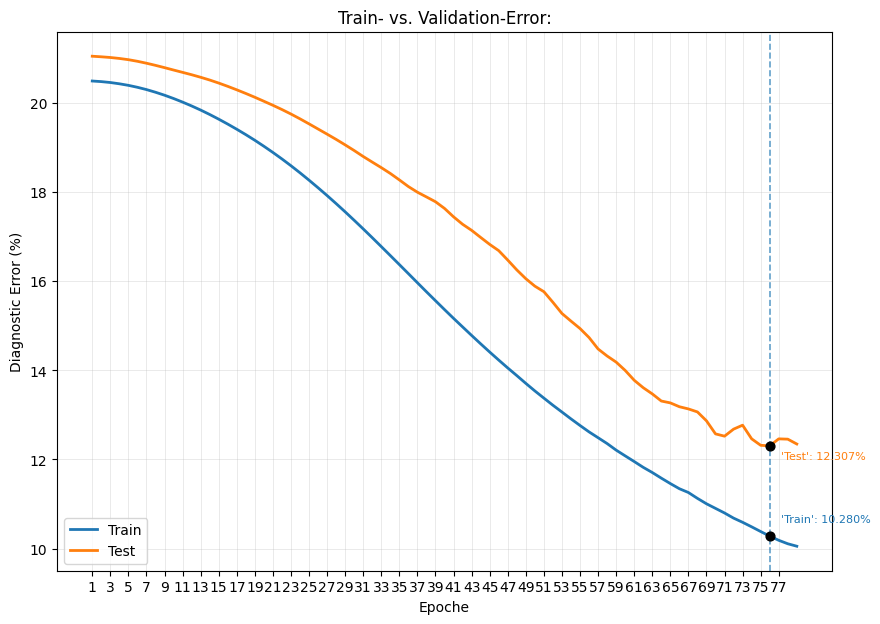

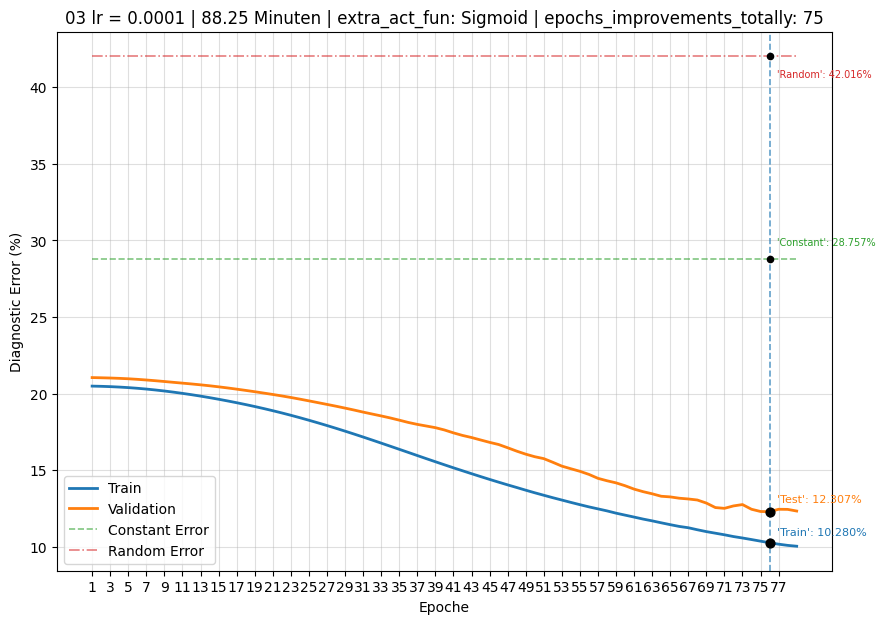

In [ ]:

print(f"\n\n Diagonal-Train-Error: {np.float64(diag_train_error)}\n")
print(f" Diagonal-Validation-Error: {np.float64(diag_val_error)}\n\n")

print(f" Diagonal-Train-Error-Max: {np.max(diag_train_error)} \t Diagonal-Train-Error-Min: {np.min(diag_train_error)}\t")
# print(f" Diagonal-Train-Error-Ave: {np.mean(diag_train_error)}\n")

print(f" Diagonal-Validation-Error-Max: {np.max(diag_val_error)}\t Diagonal-Validation-Error-Min: {np.min(diag_val_error)}\t max_needed_epochs: {e+2}\n\n")
# print(f" Diagonal-Test-Error-Ave: {np.mean(diag_test_error)}\n")

# Session: 01
# if globals().get("bas_const_err") is None:
#     bas_const_err = 28.776

# if globals().get("bas_rand_err") is None:
#     bas_rand_err = 39.232


# Session: 03
if globals().get("bas_const_err") is None:
    bas_const_err = 28.7569

if globals().get("bas_rand_err") is None:
    bas_rand_err  = 42.0157 
    

# Curven:

# Minimum Test Error bestimmen
min_val_error = min(diag_val_error)
min_val_epoch = diag_val_error.index(min_val_error) + 1

# Die vier Werte an dieser Epoch
train_at_min = diag_train_error[min_val_epoch - 1]
val_at_min = diag_val_error[min_val_epoch - 1]
const_at_min = bas_const_err
rand_at_min = bas_rand_err

# Die Farbe
train_color = "tab:blue"
val_color = "tab:orange"
const_color = "tab:green"
rand_color = "tab:red"
point_color = "black"

# Epochs beginnen bei 1
epochs = range(1, len(diag_val_error) + 1)
# epochs = range(0, len(diag_test_error) + 1)

plt.figure(figsize=(10, 7))

# Train Error
plt.plot(epochs, diag_train_error, label="Train", linewidth=2, color=train_color)


# Validation Error
plt.plot(epochs, diag_val_error, label="Test", linewidth=2, color=val_color)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_val_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Punkt beim Minimum des Test Errors
plt.scatter(
    min_val_epoch,
    min_val_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_val_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_val_epoch, train_at_min),
    xytext=(8, 10),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {val_at_min:.3f}%",
    xy=(min_val_epoch, val_at_min),
    xytext=(8, -10),
    textcoords="offset points",
    color=val_color,
    fontsize=8,
)


plt.title("Train- vs. Validation-Error:")
plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(np.arange(min(epochs), max(epochs), 2))

plt.grid(True, alpha=0.3, linewidth=0.6)
plt.legend()



# ===================================================
# =============== all 4 Diagrams ====================
# ===================================================


plt.figure(figsize=(10, 7))


# Train Error
plt.plot(
    epochs,
    diag_train_error,
    label="Train",
    linewidth=2,
    color=train_color
)


# Validation Error
plt.plot(
    epochs,
    diag_val_error,
    label="Validation",
    linewidth=2,
    color=val_color
)


# Constant Baseline
plt.plot(
    epochs,
    [bas_const_err] * len(epochs),
    label="Constant Error",
    linestyle="--",
    linewidth=1.2,
    alpha=0.6,
    color=const_color
)


# Random Baseline
plt.plot(
    epochs,
    [bas_rand_err] * len(epochs),
    label="Random Error",
    linestyle="-.",
    linewidth=1.2,
    alpha=0.6,
    color=rand_color
)



print(f"\nMinimum Test Error:")
print(f"Epoch:           {min_val_epoch}")
print(f"Validation Error:      {val_at_min:.4f}%")
print(f"Train Error:     {train_at_min:.4f}%")
print(f"Constant Error:  {bas_const_err:.4f}%")
print(f"Random Error:    {bas_rand_err:.4f}%\n")


# Punkt beim Minimum des Test Errors
plt.scatter(
    min_val_epoch,
    min_val_error,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Min Test Error ({min_test_error:.2f}%)"
)

plt.scatter(
    min_val_epoch,
    train_at_min,
    s=40,
    zorder=5,
    color=point_color
    # label=f"Train at min_Test_Error ({train_at_min_test:.2f}%)"
)

plt.scatter(
    min_val_epoch,
    const_at_min,
    s=20,
    zorder=4,
    color=point_color
)

plt.scatter(
    min_val_epoch,
    rand_at_min,
    s=20,
    zorder=4,
    color=point_color
)


# Vertikale Linie durch alle vier Kurven
plt.axvline(
    x=min_val_epoch,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    # label=f"Min Test Error (Epoch {min_test_epoch})"
)

# Werte an der vertikalen Linie anzeigen
plt.annotate(
    f"'Train': {train_at_min:.3f}%",
    xy=(min_val_epoch, train_at_min),
    xytext=(5, 5),
    textcoords="offset points",
    color=train_color,
    fontsize=8
)

plt.annotate(
    f"'Test': {val_at_min:.3f}%",
    xy=(min_val_epoch, val_at_min),
    xytext=(5, 7),
    textcoords="offset points",
    color=val_color,
    fontsize=8
)

plt.annotate(
    f"'Constant': {const_at_min:.3f}%",
    xy=(min_val_epoch, const_at_min),
    xytext=(5, 10),
    textcoords="offset points",
    color=const_color,
    fontsize=7
)

plt.annotate(
    f"'Random': {rand_at_min:.3f}%",
    xy=(min_val_epoch, rand_at_min),
    xytext=(5, -15),
    textcoords="offset points",
    color=rand_color,
    fontsize=7
)

# Titel
plt.title(
    f"{session} "
    f"lr = {learning_rate} | "
    f"{elapsed_running_time / 60:.2f} Minuten | "
    f"extra_act_fun: {active_func} | "
    f"epochs_improvements_totally: {e + 2}"
)
# plt.title(f"{def_dataset}((train:{def_dataset_size[0]}, test:{def_dataset_size[1]})) \n" 
#           f" lr = {learning_rate} | {elapsed_running_time/60:.2f} Minuten | extra_act_fun: {active_func} | epochs_imporovments_totally: {e+2}"
# )

plt.xlabel("Epoche")
plt.ylabel("Diagnostic Error (%)")

plt.xticks(np.arange(min(epochs), max(epochs), 2))

# plt.xticks(range(1, len(epochs) + 1, 1))
# plt.yticks(range(0, 51, 5))

plt.grid(True, alpha=0.4)
plt.legend()

# Ordner erstellen (falls er noch nicht existiert)
os.makedirs('./rusults/personal/Newcompare_diagrams/', exist_ok=True)

# Diagramm speichern
plt.savefig(
    f"./rusults/personal/Newcompare_diagrams//diag_error_{session}_{learning_rate}.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# a_random:
session: 03

 Diagonal-Train-Error: 
 [20.497  20.4834 20.4632 20.4347 20.3996 20.356  20.3048 20.2449 20.1784
 20.1043 20.0235 19.9373 19.8448 19.7457 19.6404 19.5298 19.4139 19.2931
 19.1662 19.0325 18.893  18.7473 18.5949 18.4359 18.2707 18.1002 17.9252
 17.7448 17.5597 17.3697 17.1764 16.9794 16.7795 16.5783 16.3759 16.1726
 15.9681 15.765  15.5648 15.3652 15.1685 14.9767 14.7855 14.5972 14.4123
 14.232  14.055  13.8841 13.709  13.5395 13.378  13.2181 13.0656 12.9119
 12.7638 12.6197 12.4891 12.3578 12.2104 12.0816 11.9542 11.8238 11.7078
 11.5814 11.4595 11.344  11.2589 11.1274 11.006  10.9026 10.7993 10.6839
 10.5902 10.4884 10.3829 10.2804 10.1862 10.1084 10.0531]

 Diagonal-Validation-Error: 
 [21.0535 21.0406 21.0251 21.0034 20.9759 20.9397 20.8965 20.8487 20.7971
 20.7436 20.6912 20.6382 20.5809 20.5193 20.4509 20.3773 20.2991 20.2173
 20.1321 20.0426 19.952  19.8566 19.7556 19.6477 19.5349 19.4194 19.3038
 19.1863 19.0629 18.9359 18.8021 18.6763 18.5522 18.4213 18.2769 18.1273
 18.0007 17.8943 17.7865 17.6364 17.4478 17.2808 17.1446 16.9855 16.8292
 16.6885 16.4765 16.2567 16.0588 15.8918 15.7671 15.5286 15.2783 15.1069
 14.9404 14.7381 14.4815 14.3236 14.1863 13.9997 13.7788 13.6115 13.4729
 13.3127 13.2708 13.1848 13.1353 13.0678 12.8684 12.575  12.5239 12.6816
 12.7703 12.4643 12.3188 12.3068 12.4634 12.4566 12.3478]


 Diagonal-Train-Error-Max: 20.497 	        Diagonal-Train-Error-Min: 10.0531	
 Diagonal-Validation-Error-Max: 21.0535	    Diagonal-Validation-Error-Min: 12.3068	           max_needed_epochs: 75
 
 totll running-tiems (min): 88.25 Minuten


Minimum Test Error:
Epoch:                 76
Validation Error:      12.3068%
Train Error:           10.2804%
Constant Error:        28.7569%
Random Error:          42.0157%

# Test:
* Session: 03
* MAE : 0.0734
* RMSE: 0.0949
* Diagonal-Error : 6.7092 %
* test_diag_error = 6.7092%


# Test:
* Session: 03
* MAE : 0.1503
* RMSE: 0.1824 
* test_diag_error = 12.8958 %

# ================================================================================================

b1) sequential:
session: 03 

 Diagonal-Train-Error: [20.4734 20.434  20.3619 20.2566 20.1315 20.0039 19.8758 19.7453 19.6044
 19.4389 19.2593 19.0579 18.8418 18.5957 18.327  18.024  17.68   17.3228
 16.9188 16.5125 16.0577 15.6182 15.1587 14.6237 14.0987 13.6284 13.1482
 12.6038 12.0918 11.5639 11.0552 10.5529 10.0504  9.5557  9.0125  8.525
  8.0616  7.6321  7.2532  6.8485  6.4839  6.1019  5.815   5.5005  5.2699
  4.9691  4.7712  4.5204  4.3534  4.157   4.009   3.8775  3.7054  3.5916
  3.4916  3.4304  3.2971  3.1581  3.0936  3.035   2.9875]

 Diagonal-Validation-Error: [21.0789 21.0385 20.9773 20.9093 20.8291 20.7547 20.675  20.5876 20.4794
 20.3646 20.2192 20.071  19.9093 19.7336 19.5208 19.2781 19.0017 18.7326
 18.3673 17.9969 17.5618 17.1835 16.7869 16.2901 15.8112 15.2803 14.7942
 14.2626 13.7438 13.2294 12.8184 12.3282 11.7988 11.3553 10.9598 10.4758
 10.0988  9.6982  9.3955  9.1695  8.9442  8.6453  8.4306  8.323   8.3117
  8.2503  8.0054  7.8579  7.8058  7.6049  7.5505  7.4823  7.4169  7.3668
  7.3405  7.3579  7.3611  7.1191  7.1942  7.1688  7.128 ]


 Diagonal-Train-Error-Max: 20.4734 	       Diagonal-Train-Error-Min: 2.9875	
 Diagonal-Validation-Error-Max: 21.0789	   Diagonal-Validation-Error-Min: 7.1191	 max_needed_epochs: 57



Minimum Error:
Epoch:                 58
Validation Error:      7.1191%
Train Error:           3.1581%
Constant Error:        28.7569%
Random Error:          40.4452%


# ===============================================================================================
d: two Videos
session: 03

 Diagonal-Train-Error: [20.4943 20.4205 20.3222 20.2067 20.099  19.9595 19.8481 19.695  19.555
 19.3986 19.2236 19.0826 18.847  18.6135 18.3637 18.1207 17.842  17.5889
 17.3044 17.0534 16.6926 16.365  15.9398 15.6131 15.416  14.6871 14.3851
 13.9832 13.6334 13.3919 13.1806 12.6639 12.0695 11.8195 11.4011 10.9265
 10.6008 10.2857 10.2497  9.7905  9.4225  9.3187  9.0837  8.8702  8.4353
  8.2733  7.9494  7.6057  7.4646  7.1788  6.9277  6.9685  6.968   6.8493]

 Diagonal-Test-Error: [19.9141 19.8758 19.7909 19.7179 19.6388 19.5554 19.4617 19.3517 19.247
 19.104  18.9699 18.8496 18.679  18.495  18.305  18.0962 17.8542 17.6387
 17.4103 17.1899 16.8777 16.6347 16.24   15.9645 15.7293 15.2073 14.9025
 14.5639 14.3895 14.1429 13.9575 13.5442 13.1274 12.7653 12.4627 12.1037
 11.7685 11.5732 11.6008 11.1178 10.8408 10.773  10.6023 10.2894 10.0266
 10.0704  9.8214  9.4245  9.3022  9.2181  9.0643  9.1174  9.0819  9.0703]


 Diagonal-Train-Error-Max: 20.4943 	 Diagonal-Train-Error-Min: 6.8493	
 Diagonal-Test-Error-Max: 19.9141	 Diagonal-Test-Error-Min: 9.0643	 max_needed_epochs: 50



Minimum Test Error:
Epoch:           51
Validation Error:      9.0643%
Train Error:     6.9277%
Constant Error:  28.7569%
Random Error:    40.4452%

# ---------- Evaluation ----------

In [ ]:
# ---------- Evaluation ----------

# saved_model = "./models/best_models/best_ResNet_Sigmoid.path"

best_saved_model2 = "./models/personal/BEST_MODELS_session(03).path"

saved_model_name = "models/personal/ResNet_best_model_lr(1e-05)_session(10).path"

last_saved_model = "models/personal/BEST-MODEL_RESNET_SIGMOID_session(03).path"

last_saved_model2 = "models/personal/BEST-MODEL_RESNET_SIGMOID_session(03+04).path"

# saved_model = "./models/best_models/best_ResNet_Sigmoid.path"

checkpoint = torch.load(
    # saved_model_name,
    best_saved_model2,
    map_location=device
)

model.load_state_dict(checkpoint)

model.to(device)

model.eval()

print("Test:\n")
print(f"Session: {session}")
test_mae, test_rmse, test_diag_pct = diagonal_errors(model, test_loader, device)

print(
        f"test_diag_error = {test_diag_pct:.4f}% "
    )

targets, predictions, errors = evaluate_model(
    model,
    test_loader,
    device
)

Test:

Session: 03
MAE : 0.1503 	 RMSE: 0.1824 
Diagonal-Error %: 12.8958 %
test_diag_error = 12.8958% 


# Test: two Videos 03 + 04

session: 04

MAE : 0.2541 --|-- RMSE: 0.2971 

Diagonal-Error %: 21.0104 %

test_diag_error = 21.0104% 

# Test:

Session: 03

MAE : 0.0734 --|-- RMSE: 0.0949 

Diagonal-Error : 6.7092 %

test_diag_error = 6.7092% 

# Test:

MAE : 0.1341 	 RMSE: 0.1672 

Diagonal-Error %: 11.8241 %

test_diag_error=11.8241%

In [ ]:
import pandas as pd


results_df = pd.DataFrame({
    "gt_x": targets[:, 0],
    "gt_y": targets[:, 1],
    "pred_x": predictions[:, 0],
    "pred_y": predictions[:, 1]
})


results_df.to_csv(
    f"results/personal/predictions_{session}.csv",
    index=False
)

# Split:

    a) random: 70% train, 15% validation, 15% test
    b) sequential: first 70% train, next 15% validation, last 15% test

    c) first Video for train and validation, another Video for test

    d1) train and validation: after every 5 Second start movement with a random Startpoint
    d2) test: frames start 0.5 sec after every new Starting

    e) another Video with another camera und lighing-conditions


In [ ]:
dirs = f"personalization/{session}"

csv_path = Path(dirs) / "norm_labels.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Fehlt: {csv_path.resolve()}")

df = pd.read_csv(csv_path)

dataset_size = len(df)

print(f"Gesamte Daten: {dataset_size}")


# ============================================================
# Vollständiges Dataset
# ============================================================

full_dataset = PersonalGazeDataset(
    root_dir=dirs,
    transform=transform,
)

print(f"len(full_dataset): {len(full_dataset)}")


Gesamte Daten: 498


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 498/498 [00:05<00:00, 93.69it/s]

len(full_dataset): 498


In [ ]:
train_size = int(dataset_size * 0.70)
validat_size = int(dataset_size * 0.15)

test_size = dataset_size - train_size - validat_size

print(
    f"\nTrain:      {train_size} | "
    f"Validation: {validat_size} | "
    f"Test:       {test_size} | "
    f"\n\nSumme:      {train_size + validat_size + test_size}"
)



Train:      348 | Validation: 74 | Test:       76 | 

Summe:      498


# Func: Create Splits

In [ ]:

def create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="random",
    seed=42,
    original_fps=60,
    frame_step=5,
    reset_interval=5,
    exclusion_time=0.5,
    test_dataset=None
):

    dataset_size = len(full_dataset)


    # ============================================================
    # A: Random Split
    # ============================================================

    if split_type == "random":

        generator = torch.Generator().manual_seed(seed)

        train_dataset, validat_dataset, test_dataset = random_split(
            full_dataset,
            [train_size, validat_size, test_size],
            generator=generator
        )



    # ============================================================
    # B1: Sequential Split
    # ============================================================

    elif split_type == "sequential":

        train_indices = list(
            range(0, train_size)
        )

        validat_indices = list(
            range(
                train_size,
                train_size + validat_size
            )
        )

        test_indices = list(
            range(
                train_size + validat_size,
                dataset_size
            )
        )

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )



    # ============================================================
    # B2: Test first, then Train + Validation
    # ============================================================

    elif split_type == "test_first_random":

        generator = torch.Generator().manual_seed(seed)

        train_valid_size = train_size + validat_size

        train_valid_dataset, test_dataset = random_split(
            full_dataset,
            [train_valid_size, test_size],
            generator=generator
        )

        train_dataset, validat_dataset = random_split(
            train_valid_dataset,
            [train_size, validat_size],
            generator=generator
        )


    # ============================================================
    # C: Video 1 = Train + Validation
    #    Video 2 = Test
    # ============================================================

    elif split_type == "different_videos":

        if test_dataset is None:

            raise ValueError(
                "Für split_type='different_videos' "
                "muss test_dataset angegeben werden."
            )


        # --------------------------------------------------------
        # Train + Validation aus Video 1
        # --------------------------------------------------------

        train_valid_size = train_size + validat_size

        if train_valid_size > len(full_dataset):

            raise ValueError(
                "Train + Validation sind größer als "
                "das Train/Validation-Video."
            )


        generator = torch.Generator().manual_seed(seed)


        train_dataset, validat_dataset = random_split(
            full_dataset,
            [train_size, validat_size],
            generator=generator
        )


        # --------------------------------------------------------
        # Test = komplettes zweites Video
        # --------------------------------------------------------

        test_dataset = test_dataset


        print("\n" + "=" * 60)
        print("DIFFERENT-VIDEO SPLIT")
        print("=" * 60)

        print(
            f"Train/Validation Video: "
            f"{len(full_dataset)} Samples"
        )

        print(
            f"Test Video: "
            f"{len(test_dataset)} Samples"
        )

        print("\nSplit:")

        print(
            f"Train:       {len(train_dataset)}"
        )

        print(
            f"Validation:  {len(validat_dataset)}"
        )

        print(
            f"Test:        {len(test_dataset)}"
        )

        print("=" * 60)


    # ============================================================
    # D: Reset-aware Random Split
    # ============================================================

    elif split_type == "reset_aware":

        # --------------------------------------------------------
        # Tatsächliche Samplingrate nach Frame-Subsampling
        # --------------------------------------------------------

        effective_fps = original_fps / frame_step


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples pro Reset-Intervall
        # --------------------------------------------------------

        reset_samples = int(
            round(reset_interval * effective_fps)
        )


        # --------------------------------------------------------
        # Anzahl gespeicherter Samples, die nach jedem Reset
        # ausgeschlossen werden
        # --------------------------------------------------------

        exclusion_samples = int(
            round(exclusion_time * effective_fps)
        )


        print("\n" + "=" * 60)
        print("RESET-AWARE SPLIT")
        print("=" * 60)

        print(f"Original FPS:          {original_fps}")
        print(f"Frame Step:            {frame_step}")
        print(f"Effektive FPS:         {effective_fps}")

        print(f"\nReset alle:            {reset_interval} s")
        print(f"Reset-Samples:         {reset_samples}")

        print(f"\nAusschlusszeit:        {exclusion_time} s")
        print(f"Ausschluss-Samples:    {exclusion_samples}")


        # --------------------------------------------------------
        # Gültige und ausgeschlossene Indizes bestimmen
        # --------------------------------------------------------

        valid_indices = []
        excluded_indices = []


        for idx in range(dataset_size):

            position_in_reset = idx % reset_samples


            # Erste 0.5 Sekunden nach jedem Reset
            if position_in_reset < exclusion_samples:

                excluded_indices.append(idx)

            else:

                valid_indices.append(idx)


        print(f"\nGesamte Samples:       {dataset_size}")
        print(f"Ausgeschlossen:        {len(excluded_indices)}")
        print(f"Verwendbar:            {len(valid_indices)}")


        # --------------------------------------------------------
        # Prüfen, ob genügend Daten vorhanden sind
        # --------------------------------------------------------

        required_size = (
            train_size
            + validat_size
            + test_size
        )


        if required_size > len(valid_indices):

            raise ValueError(
                "\nNicht genügend gültige Samples!\n"
                f"Benötigt:   {required_size}\n"
                f"Verfügbar: {len(valid_indices)}"
            )


        # --------------------------------------------------------
        # Gültige Daten zufällig mischen
        # --------------------------------------------------------

        generator = torch.Generator().manual_seed(seed)

        permutation = torch.randperm(
            len(valid_indices),
            generator=generator
        ).tolist()


        shuffled_indices = [
            valid_indices[i]
            for i in permutation
        ]


        # --------------------------------------------------------
        # Train
        # --------------------------------------------------------

        train_indices = shuffled_indices[
            :train_size
        ]


        # --------------------------------------------------------
        # Validation
        # --------------------------------------------------------

        validat_indices = shuffled_indices[
            train_size:
            train_size + validat_size
        ]


        # --------------------------------------------------------
        # Test
        # --------------------------------------------------------

        test_indices = shuffled_indices[
            train_size + validat_size:
            train_size + validat_size + test_size
        ]


        # --------------------------------------------------------
        # Subsets
        # --------------------------------------------------------

        train_dataset = Subset(
            full_dataset,
            train_indices
        )

        validat_dataset = Subset(
            full_dataset,
            validat_indices
        )

        test_dataset = Subset(
            full_dataset,
            test_indices
        )


        print("\nSplit:")
        print(f"Train:                 {len(train_dataset)}")
        print(f"Validation:            {len(validat_dataset)}")
        print(f"Test:                  {len(test_dataset)}")

        print("=" * 60)


    else:

        raise ValueError(
            f"Unbekannter split_type: {split_type}"
        )


    return (
        train_dataset,
        validat_dataset,
        test_dataset
    )

# a) random 

In [ ]:

from torch.utils.data import DataLoader, Subset, random_split


# A1: Random
train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="random",
    seed=42
)


print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")



# B1: Sequential:

train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="sequential"
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")



# B2: another Split but better: first Test next Train and Validation

all_indices = np.arange(dataset_size)

test_indices = all_indices[-test_size:]

train_valid_indices = all_indices[:-test_size]

train_indices = train_valid_indices[:train_size]

validat_indices = train_valid_indices[train_size:]


train_dataset = Subset(
    full_dataset,
    train_indices
)

validat_dataset = Subset(
    full_dataset,
    validat_indices
)

test_dataset = Subset(
    full_dataset,
    test_indices
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")




# C: C: one Video for Train and Validation and another Video for Test
session1, session2 = str('03'), str('04') 

train_valid_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session1}",
    transform=transform
)

test_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session2}",
    transform=transform
)

dataset_size = len(train_valid_dataset)

train_size = int(dataset_size * 0.80)

validat_size = dataset_size - train_size

print(f"Session1: {session1}-->{dataset_size}")
print(f"Train:      {train_size}")
print(f"Validation: {validat_size}")
print(f"Session2 Test: {session2}-->{len(test_dataset)}")


train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset=train_valid_dataset,

    train_size=train_size,
    validat_size=validat_size,

    # Wird bei different_videos nicht für die Größe
    # des Testsets verwendet
    test_size=len(test_dataset),

    split_type="different_videos",

    seed=42,

    test_dataset=test_dataset
)



# d: every 5 sec but after 0.5 sec:
train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="reset_aware",

    seed=42,

    original_fps=60,
    frame_step=5,

    reset_interval=5,
    exclusion_time=0.5
)






Train:      348
Validation: 74
Test:       76


# b: Sequential:

In [ ]:
# B1:

train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="sequential"
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")

Train:      348
Validation: 74
Test:       76


In [ ]:
# B2: another Split but better: first Test next Train and Validation



all_indices = np.arange(dataset_size)

test_indices = all_indices[-test_size:]

train_valid_indices = all_indices[:-test_size]

train_indices = train_valid_indices[:train_size]

validat_indices = train_valid_indices[train_size:]


train_dataset = Subset(
    full_dataset,
    train_indices
)

validat_dataset = Subset(
    full_dataset,
    validat_indices
)

test_dataset = Subset(
    full_dataset,
    test_indices
)

print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(validat_dataset)}")
print(f"Test:       {len(test_dataset)}")

Train:      348
Validation: 74
Test:       76


# C: one Video for Train and Validation and another Video for Test


In [ ]:
session1, session2 = str('03'), str('04') 

train_valid_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session1}",
    transform=transform
)

test_dataset = PersonalGazeDataset(
    root_dir=f"personalization/{session2}",
    transform=transform
)

dataset_size = len(train_valid_dataset)

train_size = int(dataset_size * 0.80)

validat_size = dataset_size - train_size

print(f"Session1: {session1}-->{dataset_size}")

print(f"Train:      {train_size}")
print(f"Validation: {validat_size}")

print(f"Session2 Test: {session2}-->{len(test_dataset)}")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 548/548 [00:05<00:00, 108.46it/s]


Session1: 03-->482
Train:      385
Validation: 97
Session2 Test: 04-->548


In [ ]:
train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset=train_valid_dataset,

    train_size=train_size,
    validat_size=validat_size,

    # Wird bei different_videos nicht für die Größe
    # des Testsets verwendet
    test_size=len(test_dataset),

    split_type="different_videos",

    seed=42,

    test_dataset=test_dataset
)



DIFFERENT-VIDEO SPLIT
Train/Validation Video: 482 Samples
Test Video: 548 Samples

Split:
Train:       385
Validation:  97
Test:        548


# d: every 5 sec first after 0.5 sec:

In [ ]:
train_dataset, validat_dataset, test_dataset = create_splits(
    full_dataset,
    train_size,
    validat_size,
    test_size,
    split_type="reset_aware",

    seed=42,

    original_fps=60,
    frame_step=5,

    reset_interval=5,
    exclusion_time=0.5
)


# Test 

In [ ]:
def verify_dataset(
    dataset,
    csv_file,
    num_samples=20
):

    df = pd.read_csv(csv_file)

    print("=" * 60)
    print("DATASET VERIFICATION")
    print("=" * 60)

    print(f"CSV rows:      {len(df)}")
    print(f"Dataset size:  {len(dataset)}")

    assert len(df) == len(dataset), (
        "CSV und Dataset haben unterschiedliche Größen!"
    )

    num_samples = min(
        num_samples,
        len(dataset)
    )

    for idx in np.linspace(
        0,
        len(dataset) - 1,
        num_samples,
        dtype=int
    ):

        image, target = dataset[idx]

        csv_row = df.iloc[idx]

        csv_target = np.array(
            [
                csv_row["x"],
                csv_row["y"]
            ],
            dtype=np.float32
        )

        dataset_target = target.numpy()

        if not np.allclose(
            csv_target,
            dataset_target,
            atol=1e-6
        ):

            print(
                f"FEHLER bei Index {idx}"
            )

            print(
                "CSV:",
                csv_target
            )

            print(
                "Dataset:",
                dataset_target
            )

            return False

    print(
        f"\n✓ {num_samples} Samples erfolgreich überprüft."
    )

    return True


In [ ]:
verify_dataset(
    full_dataset,
    Path(dirs) / "norm_labels.csv",
    num_samples=20
)

In [ ]:
train_indices = set(train_dataset.indices)
validat_indices = set(validat_dataset.indices)
test_indices = set(test_dataset.indices)

print(
    "Train ∩ Validation:",
    len(train_indices & validat_indices)
)

print(
    "Train ∩ Test:",
    len(train_indices & test_indices)
)

print(
    "Validation ∩ Test:",
    len(validat_indices & test_indices)
)

# Results:
# Train ∩ Validation = 0
# Train ∩ Test       = 0
# Validation ∩ Test  = 0

In [ ]:
all_used = (
    train_indices
    | validat_indices
    | test_indices
)

print(
    "Anzahl verwendeter Samples:",
    len(all_used)
)

# Results: Bei deinem Reset-aware Split darf len(all_used) sogar kleiner als len(full_dataset) sein


In [ ]:
# 01:
print(f"the results for Session: {session}")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}, \t best_test_error: {np.float64(diag_test_error).min()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 01


Diagonal_train_error: [20.8477 20.4638 20.0535 19.681  19.3401 19.0536 18.7814 18.51   18.2908
 18.0264]


Diagonal_test_error: [21.0528 20.7655 20.6037 20.3958 20.1394 19.8827 19.6203 19.3728 19.1583
 18.9316]

 epochs: 10, 	 best_Error: 0.26773391142538705, 	 best_test_error: 18.9316

totll running-tiems (s): 311.50 Sekunden
totll running-tiems (min): 5.19 Minuten



# the results for Session: 01
## only FC and without layer 4

Diagonal_train_error01: [20.8477 20.4638 20.0535 19.681  19.3401 19.0536 18.7814 18.51   18.2908
 18.0264]


Diagonal_test_error01: [21.0528 20.7655 20.6037 20.3958 20.1394 19.8827 19.6203 19.3728 19.1583
 18.9316]

 epochs: 10, 	 best_Error: 0.26773391142538705, 	 best_test_error: 18.9316

totll running-tiems (s): 311.50 Sekunden

totll running-tiems (min): 5.19 Minuten

In [ ]:
# 02:
print(f"the results for Session: {session}\n")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}, \t best_test_error: {np.float64(diag_test_error).min()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 02

only FC and without layer 4



Diagonal_train_error: [18.5257 18.1823 17.8457 17.5679 17.3078 17.0391 16.7459 16.4621 16.1922
 15.9206]


Diagonal_test_error: [19.7028 19.0388 18.1293 17.4564 16.9029 16.6107 16.5119 16.5125 16.3639
 16.1625]

 epochs: 10, 	 best_Error: 0.22857286274382338, 	 best_test_error: 16.1625%

totll running-tiems (s): 292.65 Sekunden
totll running-tiems (min): 4.88 Minuten



# the results for Session: 02

## only FC and without layer 4


Diagonal_train_error02: [18.5257 18.1823 17.8457 17.5679 17.3078 17.0391 16.7459 16.4621 16.1922
 15.9206]


Diagonal_test_error02: [19.7028 19.0388 18.1293 17.4564 16.9029 16.6107 16.5119 16.5125 16.3639
 16.1625]

 epochs: 10, 	 best_Error: 0.22857286274382338, 	 best_test_error: 16.1625%

totll running-tiems (s): 292.65 Sekunden

totll running-tiems (min): 4.88 Minuten

In [ ]:
# 03:
print(f"the results for Session: {session}\n")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}, \t best_test_error: {np.float64(diag_test_error).min()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 03

only FC and without layer 4



Diagonal_train_error: [20.6375 20.5172 20.4209 20.2335 20.0327 19.801  19.5477 19.359  19.1703
 18.9973]


Diagonal_test_error: [22.0902 21.5746 21.2292 20.9959 20.791  20.587  20.3353 20.201  20.053
 19.9627]

 epochs: 10, 	 best_Error: 0.282314722356015, 	 best_test_error: 19.9627%

totll running-tiems (s): 337.08 Sekunden
totll running-tiems (min): 5.62 Minuten



## the results for Session: 03

# only FC and without layer 4


Diagonal_train_error03: [20.6375 20.5172 20.4209 20.2335 20.0327 19.801  19.5477 19.359  19.1703
 18.9973]


Diagonal_test_error03: [22.0902 21.5746 21.2292 20.9959 20.791  20.587  20.3353 20.201  20.053
 19.9627]

 epochs: 10, 	 best_Error: 0.282314722356015, 	 best_test_error: 19.9627%

totll running-tiems (s): 337.08 Sekunden

totll running-tiems (min): 5.62 Minuten


In [ ]:
# 04:
print(f"the results for Session: {session}\n")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}, \t best_test_error: {np.float64(diag_test_error).min()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 04

only FC and without layer 4



Diagonal_train_error: [20.8818 20.5262 20.0034 19.5626 19.1916 18.8863 18.5946 18.3234 18.0671
 17.8235]


Diagonal_test_error: [19.9414 20.2888 20.1652 19.9428 19.6704 19.4143 19.1868 19.0233 18.866
 18.6537]

 epochs: 10, 	 best_Error: 0.26380316679802013, 	 best_test_error: 18.6537%

totll running-tiems (s): 333.92 Sekunden
totll running-tiems (min): 5.57 Minuten



# the results for Session: 04

## only FC and without layer 4


Diagonal_train_error: [20.8818 20.5262 20.0034 19.5626 19.1916 18.8863 18.5946 18.3234 18.0671
 17.8235]


Diagonal_test_error: [19.9414 20.2888 20.1652 19.9428 19.6704 19.4143 19.1868 19.0233 18.866
 18.6537]

 epochs: 10, 	 best_Error: 0.26380316679802013, 	 best_test_error: 18.6537%

totll running-tiems (s): 333.92 Sekunden

totll running-tiems (min): 5.57 Minuten


# ==================== Optimal =============================

In [ ]:
# 02:
print(f"the results for Session: {session}\n")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}" 
      f"\n best_test_error: {np.float64(diag_test_error).min()}%, \tmax_test_Error: {np.float64(diag_test_error).max()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 02

only FC and without layer 4



Diagonal_train_error: [19.4212 17.7688 16.9373 16.432  15.9572 15.5047 15.0849 14.7342 14.4432
 14.2265 14.0141 13.781  13.5563 13.348  13.1246 12.9289 12.7407 12.5674
 12.3858 12.2026]


Diagonal_test_error: [20.9319 17.7764 15.8419 14.8768 14.4095 14.1325 14.111  14.2164 14.2938
 14.2955 14.1694 13.848  13.4551 13.3329 13.005  12.886  12.8297 12.8031
 12.6214 12.4136]

 epochs: 20, 	 best_Error: 0.17555457971299732
 best_test_error: 12.4136%, 	max_test_Error: 20.9319%

totll running-tiems (s): 574.36 Sekunden
totll running-tiems (min): 9.57 Minuten



In [ ]:
# 01:
print(f"the results for Session: {session}\n")
print(f"only FC and without layer 4\n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}" 
      f"\n best_test_error: {np.float64(diag_test_error).min()}%, \tmax_test_Error: {np.float64(diag_test_error).max()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 01

only FC and without layer 4



Diagonal_train_error: [15.3648 15.1013 15.1603 14.678  14.3885 14.2098 14.0774 13.9202 13.78
 13.657  13.5354 13.4318 13.3666 13.243  13.1577 13.0428 12.9579 12.9177
 12.7877 12.7263]


Diagonal_test_error: [16.7358 16.2906 16.3221 15.8886 15.7614 15.5712 15.2743 15.2488 15.1827
 15.0881 14.9273 14.8744 14.7402 14.6438 14.6689 14.6622 14.6104 14.5191
 14.4285 14.46  ]

 epochs: 20, 	 best_Error: 0.2040497107098068
 best_test_error: 14.4285%, 	max_test_Error: 16.7358%

totll running-tiems (s): 788.43 Sekunden
totll running-tiems (min): 13.14 Minuten



In [ ]:
# 01:
print(f"the results for Session: {session}\n")
print(f" FC and layer4 \n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}" 
      f"\n best_test_error: {np.float64(diag_test_error).min()}%, \tmax_test_Error: {np.float64(diag_test_error).max()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 01

 FC and layer4 



Diagonal_train_error: [11.3647 10.2059  9.183   8.3242  7.5884  7.1476  6.4918  5.9299  5.6028
  5.1456  4.8113  4.533   4.2175  4.0028  3.7746  3.6418  3.4019  3.2304
  3.0697  3.1854]


Diagonal_test_error: [13.5827 12.993  12.4911 12.0546 11.8701 11.8472 11.48   10.8924 10.5413
 10.593  10.3502 10.3507 10.138  10.1412 10.1741 10.1195 10.0583  9.904
  9.8323  9.8302]

 epochs: 20, 	 best_Error: 0.1390205620095576
 best_test_error: 9.8302%, 	max_test_Error: 13.5827%

totll running-tiems (s): 1350.90 Sekunden
totll running-tiems (min): 22.51 Minuten



In [ ]:
# 01:
print(f"the results for Session: {session}\n")
print(f" FC and layer4 and Sigmoid \n")
print(f"\n\nDiagonal_train_error: {np.float64(diag_train_error)}")
print(f"\n\nDiagonal_test_error: {np.float64(diag_test_error)}")

print(f"\n epochs: {epochs}, \t best_Error: {best_error}" 
      f"\n best_test_error: {np.float64(diag_test_error).min()}%, \tmax_test_Error: {np.float64(diag_test_error).max()}%")

print(f"\ntotll running-tiems (s): {elapsed_running_time:.2f} Sekunden")
print(f"totll running-tiems (min): {elapsed_running_time/60:.2f} Minuten\n")

the results for Session: 01

 FC and layer4 and Sigmoid 



Diagonal_train_error: [21.2963 20.4879 19.7773 19.1741 18.6438 18.159  17.7288 17.3245 16.9491
 16.5914 16.2423 15.8723 15.5279 15.1753 14.8057 14.446  14.0653 13.6825
 13.2886 12.9093]


Diagonal_test_error: [22.5788 21.8181 21.181  20.6503 20.1906 19.7427 19.3522 18.9706 18.6466
 18.3322 18.0399 17.7275 17.4513 17.1487 16.8487 16.573  16.2839 16.0158
 15.7229 15.4488]

 epochs: 20, 	 best_Error: 0.2184786646452124
 best_test_error: 15.4488%, 	max_test_Error: 22.5788%

totll running-tiems (s): 1438.26 Sekunden
totll running-tiems (min): 23.97 Minuten



---
# Archiv: `personal_code.py` (Skript, als Text)

In [ ]:
# Archivierter Inhalt von notebooks/personal_code.py – nur zur Dokumentation
'''

# steo 0:

from cProfile import label

import pandas as pd
import numpy as np
import cv2
from pathlib import Path
import os
import time

# step 1: 

root_folder = Path("./personalization/")
text_files = []
video_files = []

for f,folder in enumerate(root_folder.iterdir()):

    if folder.is_dir():

        print(f"\nfolder_name: {folder.name}")
        images_folder = Path(f"{root_folder}/{folder.name}/images")
        images_folder.mkdir(
                parents=True,
                exist_ok=True
            )
        # os.makedirs("images", exist_ok=True)

        for file in folder.iterdir():

            if file.suffix == ".txt" and file.name == f"{folder.name}_position.txt":
                # print("TXT gefunden:", file)
                txt_file = Path(f"{root_folder}/{folder.name}/{folder.name}_position.txt")
                print(f"Text_File: {txt_file.as_posix()}\n")
                text_files.append(txt_file.as_posix())


                

            elif file.suffix == ".mp4":
                # print("MP4 gefunden:", file)
                video_file = Path(f"{root_folder}/{folder.name}/{folder.name}_video.mp4")
                print(f"Video_File: {video_file.as_posix()}\n")
                video_files.append(video_file.as_posix())

print(f"\nText_Files: {text_files}")
print(f"\nVideo_Files: {video_files}")


# step 3:

for i in range(len(text_files)):

    labels = pd.read_csv(text_files[i], sep=",") 
    # print(labels.head())
    # print(labels.columns)

    labels.columns = labels.columns.str.strip()

    # subject_name = f"{text_files[i].split('/')[1]}"
    subject_name = Path(text_files[i]).parent.name
    print(f"\nsubject_name: {subject_name}\n")

    images_folder = Path(f"./personalization") / subject_name / "images"

    images_folder.mkdir(parents=True, exist_ok=True)


    cap = cv2.VideoCapture(video_files[i])

    rows = []
    norm_rows = []
    frame_id = 0
    saved_id = 0
    Steps = 5

    # Min und Max berechnen
    x_min = labels["x"].min()
    x_max = labels["x"].max()

    y_min = labels["y"].min()
    y_max = labels["y"].max()

    print(f"x_min = {x_min}, x_max = {x_max}")
    print(f"y_min = {y_min}, y_max = {y_max}")
    # x_min = 7.25, x_max = 1422.74
    # y_min = 3.89, y_max = 875.01

    x_max, y_max = 1430, 880
    # print(f"X_max = {x_max}, Y_max = {y_max}")
    # X_max = 1430, Y_max = 880

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_id % Steps == 0:

            filename = f"{saved_id:04d}.jpg"

            image_path = images_folder / filename

            cv2.imwrite(str(image_path), frame)


            rows.append({
                "frame": filename,
                "x": max(0, float(f"{(labels.loc[frame_id, "x"]):.6f}")),
                "y": max(0, float(f"{(labels.loc[frame_id, "y"]):.6f}"))
            })

            norm_rows.append({
                "frame": filename,
                "x": min(max(0, float(f"{(labels.loc[frame_id, "x"] / x_max):.6f}")), 1),
                "y": min(max(0, float(f"{(labels.loc[frame_id, "y"] / y_max):.6f}")), 1)
            })

            saved_id += 1


        frame_id += 1

    cap.release()

    pd.DataFrame(rows).to_csv(
        f"./personalization/{subject_name}/labels.csv", index=False
    )

    pd.DataFrame(norm_rows).to_csv(
        f"./personalization/{subject_name}/norm_labels.csv", index=False
        )

'''